<a href="https://colab.research.google.com/github/uniqueeee777/ntt-disaster-preparedness/blob/main/02_preprocessingrev.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# A. Persiapan Data

In [2]:
# ============================================================
# A.1 — PEMBACAAN DAN VALIDASI MASTER DATASET
# ============================================================

import pandas as pd
import numpy as np
import re
import hashlib

from pathlib import Path
from google.colab import drive
from IPython.display import display

drive.mount("/content/drive")

lokasi = Path(
    "/content/drive/MyDrive/NTT_Disaster_Analysis data/"
    "Master_Dataset_Kebencanaan_NTT_Artikel1.xlsx"
)

if not lokasi.exists():
    raise FileNotFoundError(f"File tidak ditemukan: {lokasi}")

df_raw = pd.read_excel(
    lokasi,
    sheet_name="Master_NTT"
).reset_index(drop=True)

# Simpan salinan pembanding agar perubahan tidak disengaja
# dapat dideteksi pada akhir proses.
df_raw_awal = df_raw.copy(deep=True)

sha256_a = hashlib.sha256(
    lokasi.read_bytes()
).hexdigest()

# Pemeriksaan identitas
assert df_raw.shape == (22, 197), (
    f"Ukuran dataset berubah: {df_raw.shape}"
)

assert not df_raw.columns.duplicated().any()
assert not df_raw["kabupaten_kota"].isna().any()
assert df_raw["kabupaten_kota"].is_unique

assert df_raw["jenis_wilayah"].value_counts().to_dict() == {
    "Kabupaten": 21,
    "Kota": 1
}

print("A.1 — IDENTITAS MASTER DATASET")
print("Nama file      :", lokasi.name)
print("Sheet          : Master_NTT")
print("Jumlah wilayah :", df_raw.shape[0])
print("Jumlah peubah  :", df_raw.shape[1])
print("SHA-256        :", sha256_a)

print("\nJENIS WILAYAH")
display(
    df_raw["jenis_wilayah"]
    .value_counts()
    .rename_axis("jenis_wilayah")
    .reset_index(name="jumlah")
)

print("\nDAFTAR WILAYAH")
display(
    df_raw[
        ["kabupaten_kota", "jenis_wilayah"]
    ]
)

print("\nDuplikasi wilayah:",
      df_raw["kabupaten_kota"].duplicated().sum())

print("Data mentah belum dimodifikasi.")

Mounted at /content/drive
A.1 — IDENTITAS MASTER DATASET
Nama file      : Master_Dataset_Kebencanaan_NTT_Artikel1.xlsx
Sheet          : Master_NTT
Jumlah wilayah : 22
Jumlah peubah  : 197
SHA-256        : 57f35ff226dd7d7cff45af241073d4acbed0497af6fa87274bf5234f6dc2a282

JENIS WILAYAH


,jenis_wilayah,jumlah
0,Kabupaten,21
1,Kota,1



DAFTAR WILAYAH


,kabupaten_kota,jenis_wilayah
0,Sumba Barat,Kabupaten
1,Sumba Timur,Kabupaten
2,Kupang,Kabupaten
3,Timor Tengah Selatan,Kabupaten
4,Timor Tengah Utara,Kabupaten
5,Belu,Kabupaten
6,Alor,Kabupaten
7,Lembata,Kabupaten
8,Flores Timur,Kabupaten
9,Sikka,Kabupaten



Duplikasi wilayah: 0
Data mentah belum dimodifikasi.


## Audit Inventarisasi peubah dan metadata sumber

In [3]:
# ============================================================
# A.2 — INVENTARISASI PEUBAH DAN METADATA SUMBER
# ============================================================

def identifikasi_sumber(nama):
    if nama in ("kabupaten_kota", "jenis_wilayah"):
        return "Identitas"
    if nama.startswith("bps_"):
        return "BPS"
    if nama.startswith("krb_"):
        return "KRB"
    if nama.startswith("bencana_"):
        return "BNPB"
    if nama.startswith("inarisk_"):
        return "InaRISK"
    if nama.startswith("destana_"):
        return "DESTANA"
    if nama.startswith("acebs_"):
        return "ACeBS"
    return "Belum dikenali"


def identifikasi_jenis(nama):
    if nama in ("kabupaten_kota", "jenis_wilayah"):
        return "Kategorik"
    if nama.startswith("krb_") and nama.endswith("_kelas"):
        return "Kategorik"
    if nama == "destana_ada_dalam_daftar_raw":
        return "Kategorik"
    return "Numerik"


def identifikasi_periode(nama):
    sumber = identifikasi_sumber(nama)

    if sumber == "KRB":
        return "Analisis bahaya 2020; dokumen KRB 2021–2026"

    if sumber in ("DESTANA", "ACeBS", "InaRISK"):
        return "Periode ekspor sumber perlu didokumentasikan"

    tahun = re.findall(r"20\d{2}", nama)

    if tahun:
        return tahun[-1]

    return "Tidak dinyatakan dalam nama peubah"


def identifikasi_satuan(nama):
    sumber = identifikasi_sumber(nama)

    if sumber == "Identitas":
        return "Kategori"

    if nama.endswith("_kelas"):
        return "Kategori tingkat bahaya"

    if sumber == "KRB":
        return "ha"

    if sumber == "BNPB":
        if "baris" in nama:
            return "Baris laporan"
        if "tanggal_tidak_sesuai" in nama:
            return "Baris laporan"
        return "Jumlah tercatat menurut variabel sumber"

    if sumber == "ACeBS":
        return "Jumlah kategori; definisi sumber perlu dicek"

    if sumber == "DESTANA":
        return "Entri daftar / status ketercantuman"

    if "_km2" in nama:
        return "km² atau jiwa/km²; periksa nama peubah"
    if "_km" in nama:
        return "km"
    if "_ribu" in nama:
        return "ribu"
    if "persen" in nama:
        return "%"
    if "_rp" in nama:
        return "Rp"

    if nama.startswith("bps_desa_"):
        return "Desa/kelurahan"

    if sumber == "InaRISK":
        return "Menurut definisi indikator InaRISK"

    return "Jumlah atau satuan sumber"


metadata_a = pd.DataFrame({
    "peubah": df_raw.columns
})

metadata_a["sumber"] = (
    metadata_a["peubah"].map(identifikasi_sumber)
)

metadata_a["jenis"] = (
    metadata_a["peubah"].map(identifikasi_jenis)
)

metadata_a["periode"] = (
    metadata_a["peubah"].map(identifikasi_periode)
)

metadata_a["satuan_indikatif"] = (
    metadata_a["peubah"].map(identifikasi_satuan)
)

# Identifikasi kelompok peubah
kolom_numerik = metadata_a.loc[
    metadata_a["jenis"].eq("Numerik"),
    "peubah"
].tolist()

kolom_kategorik = metadata_a.loc[
    metadata_a["jenis"].eq("Kategorik"),
    "peubah"
].tolist()

# Identifikasi 11 jenis bahaya KRB
jenis_krb = sorted({
    re.match(
        r"^krb_(.+)_(rendah|sedang|tinggi|total)_ha$",
        c
    ).group(1)
    for c in df_raw.columns
    if re.match(
        r"^krb_(.+)_(rendah|sedang|tinggi|total)_ha$",
        c
    )
})

# Validasi struktur
assert len(kolom_numerik) == 183
assert len(kolom_kategorik) == 14
assert len(jenis_krb) == 11

assert set(metadata_a["sumber"]) == {
    "Identitas", "BPS", "KRB",
    "BNPB", "InaRISK", "DESTANA", "ACeBS"
}

print("A.2 — INVENTARISASI MENURUT SUMBER")

inventaris_a = pd.crosstab(
    metadata_a["sumber"],
    metadata_a["jenis"]
)

inventaris_a["Total"] = inventaris_a.sum(axis=1)
display(inventaris_a)

print("\nDAFTAR JENIS BAHAYA KRB")
display(pd.DataFrame({"jenis_bahaya": jenis_krb}))

print("\nMETADATA SELURUH PEUBAH")
display(metadata_a)

print("\nJumlah numerik:", len(kolom_numerik))
print("Jumlah kategorik:", len(kolom_kategorik))
print("Jumlah total:", len(metadata_a))

A.2 — INVENTARISASI MENURUT SUMBER


jenis,Kategorik,Numerik,Total
sumber,,,
ACeBS,0,4,4
BNPB,0,96,96
BPS,0,33,33
DESTANA,1,1,2
Identitas,2,0,2
InaRISK,0,5,5
KRB,11,44,55



DAFTAR JENIS BAHAYA KRB


,jenis_bahaya
0,banjir
1,banjir_bandang
2,cuaca_ekstrem
3,gelombang_abrasi
4,gempa_bumi
5,karhutla
6,kekeringan
7,letusan_gunung_api
8,likuefaksi
9,tanah_longsor



METADATA SELURUH PEUBAH


,peubah,sumber,jenis,periode,satuan_indikatif
0,kabupaten_kota,Identitas,Kategorik,Tidak dinyatakan dalam nama peubah,Kategori
1,jenis_wilayah,Identitas,Kategorik,Tidak dinyatakan dalam nama peubah,Kategori
2,bps_luas_daerah_2025_km2,BPS,Numerik,2025,km² atau jiwa/km²; periksa nama peubah
3,bps_jumlah_desa_2024,BPS,Numerik,2024,Jumlah atau satuan sumber
4,bps_jumlah_desa_2025,BPS,Numerik,2025,Jumlah atau satuan sumber
...,...,...,...,...,...
192,inarisk_luas_bahaya_agregat_ha_raw,InaRISK,Numerik,Periode ekspor sumber perlu didokumentasikan,Menurut definisi indikator InaRISK
193,acebs_rendah_raw,ACeBS,Numerik,Periode ekspor sumber perlu didokumentasikan,Jumlah kategori; definisi sumber perlu dicek
194,acebs_sedang_raw,ACeBS,Numerik,Periode ekspor sumber perlu didokumentasikan,Jumlah kategori; definisi sumber perlu dicek
195,acebs_tinggi_raw,ACeBS,Numerik,Periode ekspor sumber perlu didokumentasikan,Jumlah kategori; definisi sumber perlu dicek



Jumlah numerik: 183
Jumlah kategorik: 14
Jumlah total: 197


## Audit seluruh penanda khusus

In [4]:
# ============================================================
# A.3 — INVENTARISASI PENANDA KHUSUS PER SEL
# ============================================================

def status_penanda(nilai):

    if pd.isna(nilai):
        return "Kosong Excel"

    if not isinstance(nilai, str):
        return None

    s = nilai.strip()

    penanda = {
        "": "Kosong Excel",
        "-": "Tanda -",
        "–": "Tanda –",
        "—": "Tanda —",
        "...": "Tanda ...",
        "…": "Tanda ...",
        "Tidak tercantum": "Tidak tercantum"
    }

    return penanda.get(s, None)


catatan_penanda = []

for c in df_raw.columns:

    sumber = identifikasi_sumber(c)

    for idx, nilai in df_raw[c].items():

        status = status_penanda(nilai)

        if status is None:
            continue

        catatan_penanda.append({
            "index_baris": idx,
            "kabupaten_kota": df_raw.at[
                idx, "kabupaten_kota"
            ],
            "sumber": sumber,
            "peubah": c,
            "nilai_asli": nilai,
            "status": status
        })

audit_penanda_a = pd.DataFrame(
    catatan_penanda
)

print("A.3 — REKAP PENANDA KHUSUS")

rekap_penanda_a = pd.crosstab(
    audit_penanda_a["sumber"],
    audit_penanda_a["status"]
)

display(rekap_penanda_a)

print("\nTotal penanda:", len(audit_penanda_a))

print("\nPENANDA MENURUT SUMBER")
display(
    audit_penanda_a.groupby(
        ["sumber", "status"]
    ).size().reset_index(name="jumlah_sel")
)

assert len(audit_penanda_a) == 343, (
    "Jumlah penanda berbeda dari hasil audit awal. "
    "Periksa apakah file master berubah."
)

print("\nValidasi 343 penanda: sesuai.")

A.3 — REKAP PENANDA KHUSUS


status,Kosong Excel,Tanda -,Tanda ...,Tanda –,Tidak tercantum
sumber,,,,,
ACeBS,64,0,0,0,0
BPS,0,3,66,35,0
DESTANA,2,0,0,0,2
KRB,0,171,0,0,0



Total penanda: 343

PENANDA MENURUT SUMBER


,sumber,status,jumlah_sel
0,ACeBS,Kosong Excel,64
1,BPS,Tanda -,3
2,BPS,Tanda ...,66
3,BPS,Tanda –,35
4,DESTANA,Kosong Excel,2
5,DESTANA,Tidak tercantum,2
6,KRB,Tanda -,171



Validasi 343 penanda: sesuai.


## penanganan spesifik berdasarkan sumber

In [5]:
# ============================================================
# A.4 — REGISTRASI KEPUTUSAN PENANGANAN PER SEL
# ============================================================

# ------------------------------------------------------------
# 1. Verifikasi inferensi BPS disabilitas eks kusta
# ------------------------------------------------------------

kol_eks_kusta = (
    "bps_desa_ada_disabilitas_eks_kusta_2024"
)

wilayah_nol_eks_kusta = {
    "Sumba Barat",
    "Ngada"
}

nilai_eks_kusta = pd.to_numeric(
    df_raw[kol_eks_kusta],
    errors="coerce"
)

total_provinsi_eks_kusta = 255

assert nilai_eks_kusta.notna().sum() == 20
assert np.isclose(
    nilai_eks_kusta.sum(),
    total_provinsi_eks_kusta
)

wilayah_kosong_eks_kusta = set(
    df_raw.loc[
        nilai_eks_kusta.isna(),
        "kabupaten_kota"
    ]
)

assert wilayah_kosong_eks_kusta == (
    wilayah_nol_eks_kusta
)

# ------------------------------------------------------------
# 2. Audit konsistensi komponen-total KRB
# ------------------------------------------------------------

krb_nol_terinferensi = set()
krb_blok_tanpa_data = set()
krb_blok_tidak_konsisten = []

komponen_krb = [
    "rendah", "sedang", "tinggi"
]

for idx in df_raw.index:

    for jenis in jenis_krb:

        cols = [
            f"krb_{jenis}_{tingkat}_ha"
            for tingkat in komponen_krb
        ]

        kol_total = f"krb_{jenis}_total_ha"
        kol_kelas = f"krb_{jenis}_kelas"

        blok = cols + [kol_total, kol_kelas]

        # Semua lima unsur tidak tercantum
        seluruhnya_minus = all(
            status_penanda(
                df_raw.at[idx, c]
            ) == "Tanda -"
            for c in blok
        )

        if seluruhnya_minus:

            krb_blok_tanpa_data.add(
                (idx, jenis)
            )

            continue

        komponen = pd.to_numeric(
            df_raw.loc[idx, cols],
            errors="coerce"
        )

        total = pd.to_numeric(
            pd.Series([df_raw.at[idx, kol_total]]),
            errors="coerce"
        ).iloc[0]

        hilang = komponen.index[
            komponen.isna()
        ].tolist()

        # Jangan menyimpulkan nol tanpa total numerik.
        if pd.isna(total):
            krb_blok_tidak_konsisten.append({
                "wilayah": df_raw.at[
                    idx, "kabupaten_kota"
                ],
                "bahaya": jenis,
                "masalah": "Total tidak numerik"
            })
            continue

        # Luas tidak boleh negatif.
        if total < 0 or komponen.dropna().lt(0).any():
            krb_blok_tidak_konsisten.append({
                "wilayah": df_raw.at[
                    idx, "kabupaten_kota"
                ],
                "bahaya": jenis,
                "masalah": "Luas negatif"
            })
            continue

        jumlah_teramati = komponen.sum()

        # KRB disajikan dalam hektare bilangan bulat.
        cocok = np.isclose(
            jumlah_teramati,
            total,
            rtol=0,
            atol=0.5
        )

        if cocok and len(hilang) > 0:

            for c in hilang:
                if status_penanda(
                    df_raw.at[idx, c]
                ) == "Tanda -":

                    krb_nol_terinferensi.add(
                        (idx, c)
                    )

        elif not cocok:

            krb_blok_tidak_konsisten.append({
                "wilayah": df_raw.at[
                    idx, "kabupaten_kota"
                ],
                "bahaya": jenis,
                "masalah": (
                    f"Komponen={jumlah_teramati}, "
                    f"total={total}"
                )
            })

print("A. HASIL PEMERIKSAAN KRB")
print(
    "Blok tanpa informasi:",
    len(krb_blok_tanpa_data)
)
print(
    "Nol KRB yang dapat diinferensi:",
    len(krb_nol_terinferensi)
)
print(
    "Blok tidak konsisten:",
    len(krb_blok_tidak_konsisten)
)

if krb_blok_tidak_konsisten:
    display(
        pd.DataFrame(krb_blok_tidak_konsisten)
    )

assert len(krb_blok_tanpa_data) == 15
assert len(krb_nol_terinferensi) == 96
assert len(krb_blok_tidak_konsisten) == 0

# ------------------------------------------------------------
# 3. Menetapkan keputusan untuk setiap penanda
# ------------------------------------------------------------

keputusan_a = []

for _, r in audit_penanda_a.iterrows():

    idx = r["index_baris"]
    c = r["peubah"]
    sumber = r["sumber"]
    status = r["status"]
    wilayah = r["kabupaten_kota"]

    keputusan = None

    if sumber == "BPS":

        if status == "Tanda –":
            keputusan = "Nol: legenda BPS"

        elif status == "Tanda ...":
            keputusan = "NA: data tidak tersedia BPS"

        elif (
            status == "Tanda -"
            and c == kol_eks_kusta
            and wilayah in wilayah_nol_eks_kusta
        ):
            keputusan = "Nol: inferensi total BPS"

        elif (
            status == "Tanda -"
            and c == "bps_jalan_prov_baik_2025_km"
            and wilayah == "Sumba Barat Daya"
        ):
            keputusan = "Tunda: nilai belum terverifikasi"

    elif sumber == "KRB":

        if status == "Tanda -":

            if (idx, c) in krb_nol_terinferensi:
                keputusan = "Nol: konsistensi KRB"
            else:
                keputusan = "NA: KRB tidak tercantum"

    elif sumber == "DESTANA":

        if (
            c == "destana_ada_dalam_daftar_raw"
            and status == "Tidak tercantum"
        ):
            keputusan = "Pertahankan: status daftar"

        elif status == "Kosong Excel":
            keputusan = "NA: entri tidak tersedia"

    elif sumber == "ACeBS":

        if status == "Kosong Excel":
            keputusan = "NA: wilayah tidak tercakup"

    if keputusan is None:
        raise ValueError(
            "Penanda belum memiliki keputusan: "
            f"{wilayah}, {c}, {status}"
        )

    catatan = r.to_dict()
    catatan["keputusan"] = keputusan
    keputusan_a.append(catatan)

registrasi_final_a = pd.DataFrame(
    keputusan_a
)

# ------------------------------------------------------------
# 4. Validasi keputusan audit
# ------------------------------------------------------------

def kategori_keputusan(teks):

    if teks.startswith("Nol:"):
        return "Nol terverifikasi/terinferensi"

    if teks.startswith("NA:"):
        return "Tidak tersedia"

    if teks.startswith("Tunda:"):
        return "Belum terverifikasi"

    if teks.startswith("Pertahankan:"):
        return "Status dipertahankan"

    return "Perlu evaluasi"

registrasi_final_a["status_penanganan"] = (
    registrasi_final_a["keputusan"]
    .map(kategori_keputusan)
)

hasil_keputusan_a = (
    registrasi_final_a
    .groupby(["sumber", "keputusan"])
    .size()
    .reset_index(name="jumlah_sel")
)

print("\nB. REKAP KEPUTUSAN PER SUMBER")
display(hasil_keputusan_a)

print("\nC. REKAP STATUS AKHIR")
rekap_status_a = (
    registrasi_final_a["status_penanganan"]
    .value_counts()
)

display(rekap_status_a)

assert len(registrasi_final_a) == 343

assert rekap_status_a.to_dict() == {
    "Tidak tersedia": 207,
    "Nol terverifikasi/terinferensi": 133,
    "Status dipertahankan": 2,
    "Belum terverifikasi": 1
}

print("\nSeluruh 343 penanda telah diklasifikasikan.")

A. HASIL PEMERIKSAAN KRB
Blok tanpa informasi: 15
Nol KRB yang dapat diinferensi: 96
Blok tidak konsisten: 0

B. REKAP KEPUTUSAN PER SUMBER


,sumber,keputusan,jumlah_sel
0,ACeBS,NA: wilayah tidak tercakup,64
1,BPS,NA: data tidak tersedia BPS,66
2,BPS,Nol: inferensi total BPS,2
3,BPS,Nol: legenda BPS,35
4,BPS,Tunda: nilai belum terverifikasi,1
5,DESTANA,NA: entri tidak tersedia,2
6,DESTANA,Pertahankan: status daftar,2
7,KRB,NA: KRB tidak tercantum,75
8,KRB,Nol: konsistensi KRB,96



C. REKAP STATUS AKHIR


,count
status_penanganan,
Tidak tersedia,207
Nol terverifikasi/terinferensi,133
Status dipertahankan,2
Belum terverifikasi,1



Seluruh 343 penanda telah diklasifikasikan.


## Finalisasi registrasi audit awal

In [6]:
# ============================================================
# A.5 — MEMBENTUK DATA HASIL AUDIT
# ============================================================

# ------------------------------------------------------------
# 1. Konversi numerik dalam satu operasi
# ------------------------------------------------------------

angka_asli_a = df_raw[
    kolom_numerik
].apply(
    pd.to_numeric,
    errors="coerce"
).copy()

angka_audit_a = angka_asli_a.copy(deep=True)

# ------------------------------------------------------------
# 2. Terapkan hanya keputusan nol yang sah
# ------------------------------------------------------------

baris_nol = registrasi_final_a.loc[
    registrasi_final_a["keputusan"]
    .str.startswith("Nol:")
]

for _, r in baris_nol.iterrows():

    idx = r["index_baris"]
    c = r["peubah"]

    if c not in angka_audit_a.columns:
        raise ValueError(
            f"Penetapan nol pada peubah bukan numerik: {c}"
        )

    if pd.notna(angka_audit_a.at[idx, c]):
        raise ValueError(
            f"Konflik nilai numerik: {idx}, {c}"
        )

    angka_audit_a.at[idx, c] = 0.0

# ------------------------------------------------------------
# 3. Bentuk salinan kategorik
# ------------------------------------------------------------

kategori_audit_a = df_raw[
    kolom_kategorik
].copy(deep=True)

# Tanda "-" pada kelas KRB bukan kelas bahaya.
for c in kolom_kategorik:

    if c.startswith("krb_") and c.endswith("_kelas"):

        kategori_audit_a[c] = (
            kategori_audit_a[c]
            .replace({
                "-": pd.NA,
                "–": pd.NA,
                "...": pd.NA
            })
        )

# Status DESTANA "Tidak tercantum" sengaja tidak diubah.

# ------------------------------------------------------------
# 4. Gabungkan dengan urutan kolom master asli
# ------------------------------------------------------------

df_audit = pd.concat(
    [angka_audit_a, kategori_audit_a],
    axis=1
)[df_raw.columns].copy()

# ------------------------------------------------------------
# 5. Pemeriksaan akhir
# ------------------------------------------------------------

print("A.5 — VALIDASI DATA HASIL AUDIT")

print("Data mentah:", df_raw.shape)
print("Data hasil audit:", df_audit.shape)

print(
    "Jumlah nol diterapkan:",
    len(baris_nol)
)

print(
    "Missing numerik:",
    int(angka_audit_a.isna().sum().sum())
)

print(
    "Missing kategorik:",
    int(kategori_audit_a.isna().sum().sum())
)

print(
    "Missing seluruh data hasil audit:",
    int(df_audit.isna().sum().sum())
)

assert len(baris_nol) == 133
assert int(angka_audit_a.isna().sum().sum()) == 193
assert int(kategori_audit_a.isna().sum().sum()) == 15
assert int(df_audit.isna().sum().sum()) == 208
assert df_audit.shape == (22, 197)

assert df_raw.equals(df_raw_awal), (
    "df_raw berubah dari kondisi awal."
)

# Alias untuk kompatibilitas dengan pemeriksaan terdahulu.
angka_audit_b1 = angka_audit_a

print("\nBagian A selesai.")
print("Data asli tetap utuh.")

A.5 — VALIDASI DATA HASIL AUDIT
Data mentah: (22, 197)
Data hasil audit: (22, 197)
Jumlah nol diterapkan: 133
Missing numerik: 193
Missing kategorik: 15
Missing seluruh data hasil audit: 208

Bagian A selesai.
Data asli tetap utuh.


# B. Statistik Deskriptif

## Statistik deskriptif numerik

In [7]:
# ============================================================
# B.1 — STATISTIK DESKRIPTIF NUMERIK
# 183 PEUBAH, BERDASARKAN HASIL AUDIT A
# ============================================================

from IPython.display import display

def kelompok_numerik(nama):

    sumber = identifikasi_sumber(nama)

    if sumber == "BNPB":

        tahun = int(
            re.search(r"bencana_(\d{4})_", nama).group(1)
        )

        if tahun == 2026:
            return "BNPB 2026"

        return "BNPB 2021–2025"

    return sumber


hasil_b1 = []

for c in kolom_numerik:

    s = angka_audit_a[c]

    valid = s.dropna()

    n = len(valid)
    unik = valid.nunique()

    hasil_b1.append({
        "sumber": kelompok_numerik(c),
        "peubah": c,
        "n_total": len(s),
        "n_valid": n,
        "n_missing": int(s.isna().sum()),
        "persen_missing": s.isna().mean() * 100,
        "n_nol": int(valid.eq(0).sum()),
        "n_unik": int(unik),
        "mean": valid.mean(),
        "std": valid.std(ddof=1),
        "minimum": valid.min(),
        "Q1": valid.quantile(0.25),
        "median": valid.median(),
        "Q3": valid.quantile(0.75),
        "maksimum": valid.max(),
        "skewness": (
            valid.skew()
            if n >= 3 and unik > 1
            else np.nan
        )
    })

deskriptif_numerik_b = pd.DataFrame(
    hasil_b1
)

# ------------------------------------------------------------
# 1. Ringkasan sumber
# ------------------------------------------------------------

ringkasan_numerik_b = (
    deskriptif_numerik_b
    .groupby("sumber")
    .agg(
        jumlah_peubah=("peubah", "size"),
        total_sel=("n_total", "sum"),
        sel_valid=("n_valid", "sum"),
        sel_missing=("n_missing", "sum"),
        peubah_tanpa_data=(
            "n_valid",
            lambda x: int(x.eq(0).sum())
        ),
        peubah_tidak_lengkap=(
            "n_missing",
            lambda x: int(x.gt(0).sum())
        ),
        peubah_konstan=(
            "n_unik",
            lambda x: int(x.eq(1).sum())
        )
    )
    .reset_index()
)

print("B.1.A — RINGKASAN NUMERIK PER SUMBER")
display(ringkasan_numerik_b)

# ------------------------------------------------------------
# 2. Tabel statistik per sumber
# ------------------------------------------------------------

urutan_sumber = [
    "BPS",
    "KRB",
    "BNPB 2021–2025",
    "BNPB 2026",
    "InaRISK",
    "DESTANA",
    "ACeBS"
]

kolom_tabel = [
    "peubah",
    "n_valid", "n_missing",
    "n_nol", "n_unik",
    "mean", "std",
    "minimum", "Q1",
    "median", "Q3",
    "maksimum", "skewness"
]

for sumber in urutan_sumber:

    tabel = deskriptif_numerik_b.loc[
        deskriptif_numerik_b["sumber"].eq(sumber),
        kolom_tabel
    ]

    if not tabel.empty:

        print(f"\nB.1.B — {sumber.upper()}")

        display(
            tabel.reset_index(drop=True).round(3)
        )

# ------------------------------------------------------------
# 3. Validasi
# ------------------------------------------------------------

print("\nB.1.C — VALIDASI")

print(
    "Peubah numerik:",
    len(deskriptif_numerik_b)
)

print(
    "Total sel valid:",
    deskriptif_numerik_b["n_valid"].sum()
)

print(
    "Total sel missing:",
    deskriptif_numerik_b["n_missing"].sum()
)

print(
    "Peubah tanpa data:",
    deskriptif_numerik_b["n_valid"].eq(0).sum()
)

assert len(deskriptif_numerik_b) == 183
assert deskriptif_numerik_b["n_missing"].sum() == 193
assert deskriptif_numerik_b["n_valid"].sum() == 3833
assert deskriptif_numerik_b["n_valid"].eq(0).sum() == 3

print("Statistik deskriptif numerik selesai.")

B.1.A — RINGKASAN NUMERIK PER SUMBER


,sumber,jumlah_peubah,total_sel,sel_valid,sel_missing,peubah_tanpa_data,peubah_tidak_lengkap,peubah_konstan
0,ACeBS,4,88,24,64,0,4,0
1,BNPB 2021–2025,80,1760,1760,0,0,0,23
2,BNPB 2026,16,352,352,0,0,0,4
3,BPS,33,726,659,67,3,4,0
4,DESTANA,1,22,20,2,0,1,0
5,InaRISK,5,110,110,0,0,0,0
6,KRB,44,968,908,60,0,16,1



B.1.B — BPS


,peubah,n_valid,n_missing,n_nol,n_unik,mean,std,minimum,Q1,median,Q3,maksimum,skewness
0,bps_luas_daerah_2025_km2,22,0,0,22,2108.097,1574.777,158.89,1267.142,1703.225,2564.092,6975.20,1.768
1,bps_jumlah_desa_2024,22,0,0,20,156.455,65.559,51.00,114.500,170.000,189.000,278.00,0.142
2,bps_jumlah_desa_2025,22,0,0,20,160.818,67.595,51.00,114.500,175.000,198.500,278.00,-0.021
3,bps_penduduk_2025_ribu,22,0,0,22,261.026,109.121,94.19,172.118,271.310,327.008,488.00,0.462
4,bps_kepadatan_2025_jiwa_per_km2,22,0,0,22,272.591,618.871,38.00,103.250,125.000,207.750,3030.00,4.616
5,bps_kepadatan_2026_jiwa_per_km2,22,0,0,21,277.318,630.397,38.00,104.250,127.000,211.500,3086.00,4.616
6,bps_persen_miskin_maret_2025,22,0,0,22,19.251,6.409,7.57,12.972,20.245,24.468,29.23,-0.245
7,bps_penduduk_miskin_maret_2025_ribu,22,0,0,22,49.491,26.237,18.63,30.462,38.295,64.088,116.74,1.099
8,bps_garis_kemiskinan_maret_2025_rp,22,0,0,22,500735.000,77118.694,397817.00,461744.250,488075.500,515498.250,794609.00,2.726
9,bps_garis_kemiskinan_september_2025_rp,0,22,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



B.1.B — KRB


...


B.1.B — DESTANA


,peubah,n_valid,n_missing,n_nol,n_unik,mean,std,minimum,Q1,median,Q3,maksimum,skewness
0,destana_entri_daftar_raw,20,2,0,16,19.5,22.006,1.0,5.0,15.0,20.25,89.0,2.166



B.1.B — ACEBS


,peubah,n_valid,n_missing,n_nol,n_unik,mean,std,minimum,Q1,median,Q3,maksimum,skewness
0,acebs_rendah_raw,6,16,1,5,3.333,3.724,0.0,1.00,1.5,5.75,9.0,0.967
1,acebs_sedang_raw,6,16,2,4,1.500,1.643,0.0,0.25,1.0,2.50,4.0,0.811
2,acebs_tinggi_raw,6,16,2,4,18.333,27.638,0.0,0.25,1.0,40.00,55.0,0.969
3,acebs_total_raw,6,16,0,5,23.167,30.268,1.0,1.50,6.5,48.25,63.0,0.921



B.1.C — VALIDASI
Peubah numerik: 183
Total sel valid: 3833
Total sel missing: 193
Peubah tanpa data: 3
Statistik deskriptif numerik selesai.


## Statistik deskriptif kategorik

In [8]:
# ============================================================
# B.2 — STATISTIK DESKRIPTIF KATEGORIK
# 14 PEUBAH
# ============================================================

hasil_ringkasan_b2 = []
hasil_frekuensi_b2 = []

for c in kolom_kategorik:

    s = kategori_audit_a[c]

    n_total = len(s)
    n_valid = int(s.notna().sum())
    n_missing = int(s.isna().sum())

    kategori_valid = s.dropna()

    hasil_ringkasan_b2.append({
        "sumber": identifikasi_sumber(c),
        "peubah": c,
        "n_total": n_total,
        "n_valid": n_valid,
        "n_missing": n_missing,
        "jumlah_kategori_valid": (
            kategori_valid.nunique()
        ),
        "kategori_terbanyak": (
            kategori_valid.mode().iloc[0]
            if n_valid > 0
            else np.nan
        )
    })

    frekuensi = (
        s.fillna("Tidak tersedia")
        .value_counts(dropna=False)
    )

    for kategori, jumlah in frekuensi.items():

        hasil_frekuensi_b2.append({
            "peubah": c,
            "kategori": kategori,
            "frekuensi": int(jumlah),
            "persen_total": jumlah / n_total * 100,
            "persen_valid": (
                jumlah / n_valid * 100
                if (
                    n_valid > 0
                    and kategori != "Tidak tersedia"
                )
                else np.nan
            )
        })

ringkasan_kategorik_b = pd.DataFrame(
    hasil_ringkasan_b2
)

frekuensi_kategorik_b = pd.DataFrame(
    hasil_frekuensi_b2
)

# ------------------------------------------------------------
# 1. Ringkasan 14 peubah
# ------------------------------------------------------------

print("B.2.A — RINGKASAN KATEGORIK")
display(ringkasan_kategorik_b)

# ------------------------------------------------------------
# 2. Frekuensi semua kategori
# ------------------------------------------------------------

print("\nB.2.B — DISTRIBUSI FREKUENSI")

display(
    frekuensi_kategorik_b.round(2)
)

# ------------------------------------------------------------
# 3. Tabel khusus kelas KRB
# ------------------------------------------------------------

kolom_kelas_krb = [
    c for c in kolom_kategorik
    if c.startswith("krb_")
    and c.endswith("_kelas")
]

kelas_krb_b = pd.DataFrame({
    c: (
        kategori_audit_a[c]
        .fillna("Tidak tersedia")
        .value_counts()
    )
    for c in kolom_kelas_krb
}).T

kelas_krb_b = (
    kelas_krb_b
    .reindex(
        columns=[
            "Rendah",
            "Sedang",
            "Tinggi",
            "Tidak tersedia"
        ],
        fill_value=0
    )
    .fillna(0)
    .astype(int)
)

kelas_krb_b["Total"] = kelas_krb_b.sum(axis=1)

print("\nB.2.C — DISTRIBUSI KELAS KRB")
display(kelas_krb_b)

# ------------------------------------------------------------
# 4. DESTANA
# ------------------------------------------------------------

print("\nB.2.D — STATUS DESTANA")

display(
    frekuensi_kategorik_b.loc[
        frekuensi_kategorik_b["peubah"].eq(
            "destana_ada_dalam_daftar_raw"
        )
    ].round(2)
)

# ------------------------------------------------------------
# 5. Validasi
# ------------------------------------------------------------

print("\nB.2.E — VALIDASI")

print(
    "Peubah kategorik:",
    len(ringkasan_kategorik_b)
)

print(
    "Jumlah kelas KRB:",
    len(kolom_kelas_krb)
)

print(
    "Kelas KRB tanpa informasi:",
    int(kelas_krb_b["Tidak tersedia"].sum())
)

assert len(ringkasan_kategorik_b) == 14
assert len(kolom_kelas_krb) == 11
assert kelas_krb_b["Total"].eq(22).all()
assert kelas_krb_b["Tidak tersedia"].sum() == 15

assert (
    ringkasan_kategorik_b["n_missing"].sum()
    == 15
)

print("Statistik deskriptif kategorik selesai.")

B.2.A — RINGKASAN KATEGORIK


,sumber,peubah,n_total,n_valid,n_missing,jumlah_kategori_valid,kategori_terbanyak
0,Identitas,kabupaten_kota,22,22,0,22,Alor
1,Identitas,jenis_wilayah,22,22,0,2,Kabupaten
2,KRB,krb_banjir_kelas,22,21,1,3,Tinggi
3,KRB,krb_banjir_bandang_kelas,22,21,1,1,Tinggi
4,KRB,krb_cuaca_ekstrem_kelas,22,21,1,1,Sedang
5,KRB,krb_gelombang_abrasi_kelas,22,22,0,3,Tinggi
6,KRB,krb_gempa_bumi_kelas,22,22,0,2,Tinggi
7,KRB,krb_karhutla_kelas,22,22,0,3,Tinggi
8,KRB,krb_kekeringan_kelas,22,22,0,2,Tinggi
9,KRB,krb_letusan_gunung_api_kelas,22,10,12,3,Tinggi



B.2.B — DISTRIBUSI FREKUENSI


,peubah,kategori,frekuensi,persen_total,persen_valid
0,kabupaten_kota,Sumba Barat,1,4.55,4.55
1,kabupaten_kota,Sumba Timur,1,4.55,4.55
2,kabupaten_kota,Kupang,1,4.55,4.55
3,kabupaten_kota,Timor Tengah Selatan,1,4.55,4.55
4,kabupaten_kota,Timor Tengah Utara,1,4.55,4.55
5,kabupaten_kota,Belu,1,4.55,4.55
6,kabupaten_kota,Alor,1,4.55,4.55
7,kabupaten_kota,Lembata,1,4.55,4.55
8,kabupaten_kota,Flores Timur,1,4.55,4.55
9,kabupaten_kota,Sikka,1,4.55,4.55



B.2.C — DISTRIBUSI KELAS KRB


,Rendah,Sedang,Tinggi,Tidak tersedia,Total
krb_banjir_kelas,5,2,14,1,22
krb_banjir_bandang_kelas,0,0,21,1,22
krb_cuaca_ekstrem_kelas,0,21,0,1,22
krb_gelombang_abrasi_kelas,7,1,14,0,22
krb_gempa_bumi_kelas,0,10,12,0,22
krb_karhutla_kelas,1,3,18,0,22
krb_kekeringan_kelas,0,3,19,0,22
krb_letusan_gunung_api_kelas,1,4,5,12,22
krb_tanah_longsor_kelas,0,8,14,0,22
krb_tsunami_kelas,0,0,22,0,22



B.2.D — STATUS DESTANA


,peubah,kategori,frekuensi,persen_total,persen_valid
51,destana_ada_dalam_daftar_raw,Ya,20,90.91,90.91
52,destana_ada_dalam_daftar_raw,Tidak tercantum,2,9.09,9.09



B.2.E — VALIDASI
Peubah kategorik: 14
Jumlah kelas KRB: 11
Kelas KRB tanpa informasi: 15
Statistik deskriptif kategorik selesai.


# C. Diagnostik Statistik

## Diagnostik Kelengkapan dan Pola Missing

In [9]:
# ============================================================
# C.1 — DIAGNOSTIK KELENGKAPAN DAN POLA MISSING
# ============================================================

# ------------------------------------------------------------
# 1. Ringkasan kelengkapan seluruh peubah
# ------------------------------------------------------------

hasil_missing_c1 = []

for c in df_audit.columns:

    s = df_audit[c]

    hasil_missing_c1.append({
        "sumber": identifikasi_sumber(c),
        "peubah": c,
        "jenis": identifikasi_jenis(c),
        "n_valid": int(s.notna().sum()),
        "n_missing": int(s.isna().sum()),
        "persen_missing": s.isna().mean() * 100,
        "status": (
            "Tidak tersedia seluruhnya"
            if s.notna().sum() == 0
            else (
                "Lengkap"
                if s.notna().sum() == len(s)
                else "Sebagian tersedia"
            )
        )
    })

missing_peubah_c1 = pd.DataFrame(
    hasil_missing_c1
)

print("C.1.A — KELENGKAPAN MENURUT SUMBER")

ringkasan_missing_c1 = (
    missing_peubah_c1
    .groupby("sumber")
    .agg(
        jumlah_peubah=("peubah", "size"),
        sel_missing=("n_missing", "sum"),
        peubah_lengkap=(
            "status",
            lambda x: int(x.eq("Lengkap").sum())
        ),
        peubah_sebagian=(
            "status",
            lambda x: int(x.eq("Sebagian tersedia").sum())
        ),
        peubah_tanpa_data=(
            "status",
            lambda x: int(
                x.eq("Tidak tersedia seluruhnya").sum()
            )
        )
    )
    .reset_index()
)

display(ringkasan_missing_c1)

# ------------------------------------------------------------
# 2. Peubah bermasalah
# ------------------------------------------------------------

print("\nC.1.B — PEUBAH TIDAK LENGKAP")

display(
    missing_peubah_c1.loc[
        missing_peubah_c1["n_missing"].gt(0)
    ].sort_values(
        ["sumber", "persen_missing"],
        ascending=[True, False]
    ).round(3)
)

# ------------------------------------------------------------
# 3. Pola missing menurut wilayah
# ------------------------------------------------------------

jumlah_missing_wilayah = (
    df_audit.isna().sum(axis=1)
)

missing_wilayah_c1 = pd.DataFrame({
    "kabupaten_kota": df_raw["kabupaten_kota"],
    "jumlah_missing": jumlah_missing_wilayah,
    "persen_missing": (
        jumlah_missing_wilayah
        / df_audit.shape[1] * 100
    )
})

print("\nC.1.C — MISSING MENURUT WILAYAH")

display(
    missing_wilayah_c1.sort_values(
        "jumlah_missing",
        ascending=False
    ).round(3)
)

# ------------------------------------------------------------
# 4. Missing asli vs hasil keputusan audit
# ------------------------------------------------------------

print("\nC.1.D — REKONSILIASI PENANDA")

rekonsiliasi_c1 = pd.DataFrame({
    "jenis": [
        "Penanda khusus data asli",
        "Menjadi nol berdasarkan audit",
        "Status DESTANA dipertahankan",
        "Missing numerik tersisa",
        "Missing kategorik tersisa"
    ],
    "jumlah": [
        len(audit_penanda_a),
        len(baris_nol),
        2,
        int(angka_audit_a.isna().sum().sum()),
        int(kategori_audit_a.isna().sum().sum())
    ]
})

display(rekonsiliasi_c1)

# ------------------------------------------------------------
# 5. Validasi
# ------------------------------------------------------------

assert missing_peubah_c1["n_missing"].sum() == 208
assert len(missing_peubah_c1) == 197

print("\nTotal missing setelah audit:", 208)
print("Data tidak dimodifikasi.")

C.1.A — KELENGKAPAN MENURUT SUMBER


,sumber,jumlah_peubah,sel_missing,peubah_lengkap,peubah_sebagian,peubah_tanpa_data
0,ACeBS,4,64,0,4,0
1,BNPB,96,0,96,0,0
2,BPS,33,67,29,1,3
3,DESTANA,2,2,1,1,0
4,Identitas,2,0,2,0,0
5,InaRISK,5,0,5,0,0
6,KRB,55,75,35,20,0



C.1.B — PEUBAH TIDAK LENGKAP


,sumber,peubah,jenis,n_valid,n_missing,persen_missing,status
193,ACeBS,acebs_rendah_raw,Numerik,6,16,72.727,Sebagian tersedia
194,ACeBS,acebs_sedang_raw,Numerik,6,16,72.727,Sebagian tersedia
195,ACeBS,acebs_tinggi_raw,Numerik,6,16,72.727,Sebagian tersedia
196,ACeBS,acebs_total_raw,Numerik,6,16,72.727,Sebagian tersedia
11,BPS,bps_garis_kemiskinan_september_2025_rp,Numerik,0,22,100.000,Tidak tersedia seluruhnya
12,BPS,bps_penduduk_miskin_september_2025_ribu,Numerik,0,22,100.000,Tidak tersedia seluruhnya
13,BPS,bps_persen_miskin_september_2025,Numerik,0,22,100.000,Tidak tersedia seluruhnya
14,BPS,bps_jalan_prov_baik_2025_km,Numerik,21,1,4.545,Sebagian tersedia
186,DESTANA,destana_entri_daftar_raw,Numerik,20,2,9.091,Sebagian tersedia
70,KRB,krb_letusan_gunung_api_rendah_ha,Numerik,10,12,54.545,Sebagian tersedia



C.1.C — MISSING MENURUT WILAYAH


,kabupaten_kota,jumlah_missing,persen_missing
0,Sumba Barat,23,11.675
16,Sumba Barat Daya,13,6.599
15,Sumba Tengah,13,6.599
3,Timor Tengah Selatan,12,6.091
2,Kupang,12,6.091
1,Sumba Timur,12,6.091
5,Belu,12,6.091
4,Timor Tengah Utara,12,6.091
12,Manggarai,12,6.091
20,Malaka,12,6.091



C.1.D — REKONSILIASI PENANDA


,jenis,jumlah
0,Penanda khusus data asli,343
1,Menjadi nol berdasarkan audit,133
2,Status DESTANA dipertahankan,2
3,Missing numerik tersisa,193
4,Missing kategorik tersisa,15



Total missing setelah audit: 208
Data tidak dimodifikasi.


## Diagnostik Distribusi, Zero Dominance, dan Outlier

In [10]:
# ============================================================
# C.2 — DIAGNOSTIK DISTRIBUSI DAN OUTLIER
# ============================================================

BATAS_SKEW = 1.0
BATAS_NOL = 80.0
MIN_VALID = 8

hasil_diagnostik_c2 = []
nilai_ekstrem_c2 = []

for c in kolom_numerik:

    s = angka_audit_a[c]
    valid = s.dropna()

    n = len(valid)
    unik = valid.nunique()

    q1 = valid.quantile(0.25)
    q3 = valid.quantile(0.75)
    iqr = q3 - q1

    persen_nol = (
        valid.eq(0).mean() * 100
        if n > 0 else np.nan
    )

    skew = (
        valid.skew()
        if n >= MIN_VALID and unik > 2
        else np.nan
    )

    layak_iqr = bool(
        n >= MIN_VALID
        and unik > 1
        and pd.notna(iqr)
        and iqr > 0
    )

    batas_bawah = np.nan
    batas_atas = np.nan
    banyak_ekstrem = 0

    if layak_iqr:

        batas_bawah = q1 - 1.5 * iqr
        batas_atas = q3 + 1.5 * iqr

        mask_ekstrem = (
            valid.lt(batas_bawah)
            | valid.gt(batas_atas)
        )

        banyak_ekstrem = int(mask_ekstrem.sum())

        for idx in valid.index[mask_ekstrem]:

            nilai = valid.at[idx]

            if nilai > batas_atas:
                posisi = "Atas"
                jarak = (nilai - batas_atas) / iqr
            else:
                posisi = "Bawah"
                jarak = (batas_bawah - nilai) / iqr

            nilai_ekstrem_c2.append({
                "kabupaten_kota": df_raw.at[
                    idx, "kabupaten_kota"
                ],
                "sumber": kelompok_numerik(c),
                "peubah": c,
                "nilai": nilai,
                "batas_bawah": batas_bawah,
                "batas_atas": batas_atas,
                "posisi": posisi,
                "jarak_dari_batas_IQR": jarak
            })

    hasil_diagnostik_c2.append({
        "sumber": kelompok_numerik(c),
        "peubah": c,
        "n_valid": n,
        "n_unik": unik,
        "n_nol": int(valid.eq(0).sum()),
        "persen_nol": persen_nol,
        "skewness": skew,
        "IQR": iqr,
        "IQR_layak": layak_iqr,
        "variasi_nol": unik == 1,
        "nol_dominan": (
            persen_nol >= BATAS_NOL
            if pd.notna(persen_nol)
            else False
        ),
        "menceng": (
            abs(skew) >= BATAS_SKEW
            if pd.notna(skew)
            else False
        ),
        "jumlah_ekstrem": banyak_ekstrem,
        "jumlah_negatif": int(valid.lt(0).sum())
    })

diagnostik_c2 = pd.DataFrame(
    hasil_diagnostik_c2
)

ekstrem_c2 = pd.DataFrame(
    nilai_ekstrem_c2,
    columns=[
        "kabupaten_kota", "sumber", "peubah",
        "nilai", "batas_bawah", "batas_atas",
        "posisi", "jarak_dari_batas_IQR"
    ]
)

# ------------------------------------------------------------
# 1. Ringkasan per sumber
# ------------------------------------------------------------

ringkasan_c2 = (
    diagnostik_c2
    .groupby("sumber")
    .agg(
        jumlah_peubah=("peubah", "size"),
        variasi_nol=("variasi_nol", "sum"),
        nol_dominan=("nol_dominan", "sum"),
        menceng=("menceng", "sum"),
        IQR_layak=("IQR_layak", "sum"),
        nilai_ekstrem=("jumlah_ekstrem", "sum"),
        peubah_ekstrem=(
            "jumlah_ekstrem",
            lambda x: int(x.gt(0).sum())
        )
    )
    .reset_index()
)

print("C.2.A — RINGKASAN DIAGNOSTIK")
display(ringkasan_c2)

# ------------------------------------------------------------
# 2. Peubah dengan banyak nol
# ------------------------------------------------------------

print("\nC.2.B — PEUBAH DIDOMINASI NOL")

display(
    diagnostik_c2.loc[
        diagnostik_c2["nol_dominan"],
        [
            "sumber", "peubah",
            "n_valid", "n_nol",
            "persen_nol", "n_unik"
        ]
    ].round(3)
)

# ------------------------------------------------------------
# 3. Peubah menceng
# ------------------------------------------------------------

print("\nC.2.C — PEUBAH SANGAT MENCENG")

display(
    diagnostik_c2.loc[
        diagnostik_c2["menceng"],
        [
            "sumber", "peubah",
            "n_valid", "skewness"
        ]
    ].sort_values(
        "skewness",
        key=lambda s: s.abs(),
        ascending=False
    ).round(3)
)

# ------------------------------------------------------------
# 4. Ringkasan outlier
# ------------------------------------------------------------

print("\nC.2.D — OUTLIER MENURUT SUMBER")

if not ekstrem_c2.empty:

    display(
        ekstrem_c2.groupby("sumber")
        .agg(
            jumlah_nilai=("nilai", "size"),
            jumlah_peubah=("peubah", "nunique"),
            jumlah_wilayah=(
                "kabupaten_kota", "nunique"
            )
        )
        .reset_index()
    )

    print("\n30 NILAI PALING EKSTREM")

    display(
        ekstrem_c2.sort_values(
            "jarak_dari_batas_IQR",
            ascending=False
        ).head(30).round(3)
    )

# ------------------------------------------------------------
# 5. Peubah yang tidak dievaluasi dengan IQR
# ------------------------------------------------------------

print("\nC.2.E — IQR TIDAK LAYAK")

display(
    diagnostik_c2.loc[
        ~diagnostik_c2["IQR_layak"],
        [
            "sumber", "peubah",
            "n_valid", "n_unik",
            "persen_nol", "IQR"
        ]
    ].round(3)
)

# ------------------------------------------------------------
# 6. Nilai negatif
# ------------------------------------------------------------

print("\nC.2.F — PEUBAH DENGAN NILAI NEGATIF")

negatif_c2 = diagnostik_c2.loc[
    diagnostik_c2["jumlah_negatif"].gt(0),
    ["sumber", "peubah", "jumlah_negatif"]
]

if negatif_c2.empty:
    print("Tidak ditemukan.")
else:
    display(negatif_c2)

# ------------------------------------------------------------
# 7. Validasi
# ------------------------------------------------------------

print("\nC.2.G — VALIDASI")

print("Peubah numerik:", len(diagnostik_c2))
print("Peubah konstan:",
      int(diagnostik_c2["variasi_nol"].sum()))
print("Peubah menceng:",
      int(diagnostik_c2["menceng"].sum()))
print("Peubah layak IQR:",
      int(diagnostik_c2["IQR_layak"].sum()))
print("Penanda ekstrem:", len(ekstrem_c2))

assert len(diagnostik_c2) == 183
assert diagnostik_c2["variasi_nol"].sum() == 28
assert diagnostik_c2["IQR_layak"].sum() == 117
assert len(ekstrem_c2) == 188

print("Tidak ada outlier yang dihapus.")

C.2.A — RINGKASAN DIAGNOSTIK


,sumber,jumlah_peubah,variasi_nol,nol_dominan,menceng,IQR_layak,nilai_ekstrem,peubah_ekstrem
0,ACeBS,4,0,0,0,0,0,0
1,BNPB 2021–2025,80,23,44,42,32,74,29
2,BNPB 2026,16,4,8,7,8,12,5
3,BPS,33,0,1,12,29,18,14
4,DESTANA,1,0,0,1,1,2,1
5,InaRISK,5,0,0,3,5,5,3
6,KRB,44,1,2,37,42,77,35



C.2.B — PEUBAH DIDOMINASI NOL


,sumber,peubah,n_valid,n_nol,persen_nol,n_unik
20,BPS,bps_rs_khusus_2025,22,20,90.909,3
43,KRB,krb_cuaca_ekstrem_tinggi_ha,21,19,90.476,3
57,KRB,krb_kekeringan_rendah_ha,22,22,100.000,1
80,BNPB 2021–2025,bencana_2021_jenis_erupsi_gunung_api_baris_raw,22,22,100.000,1
81,BNPB 2021–2025,bencana_2021_jenis_gelombang_abrasi_baris_raw,22,19,86.364,2
82,BNPB 2021–2025,bencana_2021_jenis_gempa_bumi_baris_raw,22,19,86.364,2
83,BNPB 2021–2025,bencana_2021_jenis_karhutla_baris_raw,22,21,95.455,2
84,BNPB 2021–2025,bencana_2021_jenis_kebakaran_permukiman_baris_raw,22,22,100.000,1
85,BNPB 2021–2025,bencana_2021_jenis_kekeringan_baris_raw,22,22,100.000,1
86,BNPB 2021–2025,bencana_2021_jenis_konflik_sosial_baris_raw,22,22,100.000,1



C.2.C — PEUBAH SANGAT MENCENG


...


30 NILAI PALING EKSTREM


,kabupaten_kota,sumber,peubah,nilai,batas_bawah,batas_atas,posisi,jarak_dari_batas_IQR
150,Flores Timur,BNPB 2021–2025,bencana_2024_pengungsi_jumlah_raw,51976.0,-783.500,1388.500,Atas,93.163
153,Flores Timur,BNPB 2021–2025,bencana_2024_rumah_rusak_jumlah_raw,2406.0,-49.125,81.875,Atas,70.966
26,Timor Tengah Utara,KRB,krb_banjir_tinggi_ha,210909.0,-3798.000,8170.000,Atas,67.760
127,Flores Timur,BNPB 2021–2025,bencana_2022_rumah_rusak_jumlah_raw,525.0,-21.000,35.000,Atas,35.000
167,Timor Tengah Selatan,BNPB 2021–2025,bencana_2025_rumah_rusak_jumlah_raw,510.0,-20.625,34.375,Atas,34.591
151,Malaka,BNPB 2021–2025,bencana_2024_pengungsi_jumlah_raw,20008.0,-783.500,1388.500,Atas,34.290
142,Sabu Raijua,BNPB 2021–2025,bencana_2023_pengungsi_jumlah_raw,31020.0,-1328.750,2355.250,Atas,31.124
165,Nagekeo,BNPB 2021–2025,bencana_2025_pengungsi_jumlah_raw,35674.0,-1584.250,2681.750,Atas,30.935
123,Ende,BNPB 2021–2025,bencana_2022_pengungsi_jumlah_raw,31325.0,-1660.875,2768.125,Atas,25.791
2,Kota Kupang,BPS,bps_kepadatan_2025_jiwa_per_km2,3030.0,-53.500,364.500,Atas,25.507



C.2.E — IQR TIDAK LAYAK


,sumber,peubah,n_valid,n_unik,persen_nol,IQR
9,BPS,bps_garis_kemiskinan_september_2025_rp,0,0,NaN,NaN
10,BPS,bps_penduduk_miskin_september_2025_ribu,0,0,NaN,NaN
11,BPS,bps_persen_miskin_september_2025,0,0,NaN,NaN
20,BPS,bps_rs_khusus_2025,22,3,90.909,0.00
43,KRB,krb_cuaca_ekstrem_tinggi_ha,21,3,90.476,0.00
...,...,...,...,...,...,...
172,BNPB 2026,bencana_2026_tanggal_tidak_sesuai_tahun_file_raw,22,1,100.000,0.00
179,ACeBS,acebs_rendah_raw,6,5,16.667,4.75
180,ACeBS,acebs_sedang_raw,6,4,33.333,2.25
181,ACeBS,acebs_tinggi_raw,6,4,33.333,39.75



C.2.F — PEUBAH DENGAN NILAI NEGATIF
Tidak ditemukan.

C.2.G — VALIDASI
Peubah numerik: 183
Peubah konstan: 28
Peubah menceng: 102
Peubah layak IQR: 117
Penanda ekstrem: 188
Tidak ada outlier yang dihapus.


## Diagnostik Kewajaran dan Konsistensi Indikator

In [11]:
# ============================================================
# C.3 — DIAGNOSTIK KEWAJARAN DAN KONSISTENSI
# ============================================================

# ------------------------------------------------------------
# A. KRB — KOMPONEN VS TOTAL
# ------------------------------------------------------------

hasil_konsistensi_krb = []

for idx in df_raw.index:

    for jenis in jenis_krb:

        cols = [
            f"krb_{jenis}_{k}_ha"
            for k in ["rendah", "sedang", "tinggi"]
        ]

        kol_total = f"krb_{jenis}_total_ha"

        komponen = angka_audit_a.loc[
            idx, cols
        ]

        total = angka_audit_a.at[
            idx, kol_total
        ]

        lengkap = (
            komponen.notna().all()
            and pd.notna(total)
        )

        selisih = (
            komponen.sum() - total
            if lengkap
            else np.nan
        )

        sesuai = (
            bool(np.isclose(
                selisih, 0,
                rtol=0,
                atol=0.5
            ))
            if lengkap
            else np.nan
        )

        hasil_konsistensi_krb.append({
            "kabupaten_kota": df_raw.at[
                idx, "kabupaten_kota"
            ],
            "jenis_bahaya": jenis,
            "lengkap": lengkap,
            "selisih_komponen_total": selisih,
            "sesuai": sesuai
        })

konsistensi_krb_c3 = pd.DataFrame(
    hasil_konsistensi_krb
)

print("C.3.A — KONSISTENSI KOMPONEN-TOTAL KRB")

print(
    "Blok lengkap:",
    int(konsistensi_krb_c3["lengkap"].sum())
)

print(
    "Blok tidak lengkap:",
    int((~konsistensi_krb_c3["lengkap"]).sum())
)

display(
    konsistensi_krb_c3.loc[
        konsistensi_krb_c3["lengkap"]
        & konsistensi_krb_c3["sesuai"].eq(False)
    ]
)

# ------------------------------------------------------------
# B. KRB — RASIO TERHADAP LUAS ADMINISTRATIF
# ------------------------------------------------------------

luas_admin_ha = (
    angka_audit_a["bps_luas_daerah_2025_km2"] * 100
)

hasil_rasio_krb = []

for jenis in jenis_krb:

    kol = f"krb_{jenis}_total_ha"

    for idx in df_raw.index:

        luas = angka_audit_a.at[idx, kol]
        admin = luas_admin_ha.at[idx]

        rasio = (
            luas / admin
            if (
                pd.notna(luas)
                and pd.notna(admin)
                and admin > 0
            )
            else np.nan
        )

        hasil_rasio_krb.append({
            "kabupaten_kota": df_raw.at[
                idx, "kabupaten_kota"
            ],
            "jenis_bahaya": jenis,
            "luas_bahaya_ha": luas,
            "luas_admin_ha": admin,
            "rasio": rasio
        })

rasio_krb_c3 = pd.DataFrame(
    hasil_rasio_krb
)

print("\nC.3.B — RASIO LUAS KRB MENURUT JENIS BAHAYA")

ringkasan_rasio_c3 = (
    rasio_krb_c3
    .groupby("jenis_bahaya")
    .agg(
        wilayah_valid=("rasio", "count"),
        median_rasio=("rasio", "median"),
        maksimum_rasio=("rasio", "max"),
        rasio_diatas_1_05=(
            "rasio",
            lambda x: int(x.gt(1.05).sum())
        ),
        rasio_diatas_1_25=(
            "rasio",
            lambda x: int(x.gt(1.25).sum())
        )
    )
    .reset_index()
)

display(ringkasan_rasio_c3.round(3))

print("\nKASUS RASIO LEBIH DARI 1,25")

anomali_luas_c3 = rasio_krb_c3.loc[
    rasio_krb_c3["rasio"].gt(1.25)
].sort_values(
    "rasio",
    ascending=False
)

display(anomali_luas_c3.round(3))

# ------------------------------------------------------------
# C. BPS — PERUBAHAN JUMLAH DESA
# ------------------------------------------------------------

desa_2024 = angka_audit_a[
    "bps_jumlah_desa_2024"
]

desa_2025 = angka_audit_a[
    "bps_jumlah_desa_2025"
]

perubahan_desa_c3 = pd.DataFrame({
    "kabupaten_kota": df_raw["kabupaten_kota"],
    "desa_2024": desa_2024,
    "desa_2025": desa_2025,
    "selisih": desa_2025 - desa_2024
})

print("\nC.3.C — PERUBAHAN DESA 2024–2025")

display(
    perubahan_desa_c3.loc[
        perubahan_desa_c3["selisih"].ne(0)
    ]
)

print("Total desa 2024:", desa_2024.sum())
print("Total desa 2025:", desa_2025.sum())

# ------------------------------------------------------------
# D. BPS — KONSISTENSI KATEGORI SINYAL
# ------------------------------------------------------------

kolom_sinyal = [
    "bps_desa_sinyal_25g_2025",
    "bps_desa_sinyal_3g_2025",
    "bps_desa_sinyal_4g5g_2025",
    "bps_desa_tanpa_sinyal_2025"
]

sinyal = angka_audit_a[kolom_sinyal]

lengkap_sinyal = sinyal.notna().all(axis=1)

total_sinyal = sinyal.sum(
    axis=1,
    min_count=len(kolom_sinyal)
)

audit_sinyal_c3 = pd.DataFrame({
    "kabupaten_kota": df_raw["kabupaten_kota"],
    "lengkap": lengkap_sinyal,
    "total_kategori": total_sinyal,
    "jumlah_desa_2025": desa_2025,
    "selisih": total_sinyal - desa_2025
})

print("\nC.3.D — KONSISTENSI SINYAL")

print("Wilayah lengkap:",
      int(lengkap_sinyal.sum()))

print("Wilayah dengan selisih:",
      int(audit_sinyal_c3["selisih"].dropna().ne(0).sum()))

display(
    audit_sinyal_c3.loc[
        ~audit_sinyal_c3["lengkap"]
        | audit_sinyal_c3["selisih"].ne(0)
    ]
)

# ------------------------------------------------------------
# E. BPS — KEWAJARAN INDIKATOR DISABILITAS
# ------------------------------------------------------------

kolom_disabilitas = [
    c for c in angka_audit_a.columns
    if c.startswith("bps_desa_ada_")
    and c.endswith("_2024")
]

hasil_anomali_disabilitas = []

for c in kolom_disabilitas:

    pembilang = angka_audit_a[c]

    mask = (
        pembilang.notna()
        & desa_2024.notna()
        & pembilang.gt(desa_2024)
    )

    for idx in df_raw.index[mask]:

        hasil_anomali_disabilitas.append({
            "kabupaten_kota": df_raw.at[
                idx, "kabupaten_kota"
            ],
            "peubah": c,
            "jumlah_tercatat": pembilang.at[idx],
            "desa_2024": desa_2024.at[idx],
            "persen_indikatif": (
                pembilang.at[idx]
                / desa_2024.at[idx] * 100
            )
        })

anomali_disabilitas_c3 = pd.DataFrame(
    hasil_anomali_disabilitas,
    columns=[
        "kabupaten_kota",
        "peubah",
        "jumlah_tercatat",
        "desa_2024",
        "persen_indikatif"
    ]
)

print("\nC.3.E — KETIDAKWAJARAN DISABILITAS")
display(anomali_disabilitas_c3.round(3))

# ------------------------------------------------------------
# F. BPS — NILAI JALAN BELUM TERVERIFIKASI
# ------------------------------------------------------------

print("\nC.3.F — STATUS JALAN PROVINSI")

display(
    registrasi_final_a.loc[
        registrasi_final_a["keputusan"]
        .str.startswith("Tunda:"),
        [
            "kabupaten_kota",
            "peubah",
            "nilai_asli",
            "keputusan"
        ]
    ]
)

# ------------------------------------------------------------
# G. Validasi
# ------------------------------------------------------------

print("\nC.3.G — VALIDASI")

print("Jenis KRB:", len(jenis_krb))
print("Indikator sinyal:", len(kolom_sinyal))
print("Indikator disabilitas:", len(kolom_disabilitas))
print("Anomali rasio KRB:", len(anomali_luas_c3))
print("Anomali penyebut disabilitas:",
      len(anomali_disabilitas_c3))

assert len(jenis_krb) == 11
assert len(kolom_sinyal) == 4
assert len(kolom_disabilitas) == 9

assert len(anomali_luas_c3) == 2
assert len(anomali_disabilitas_c3) == 1

print("Tidak ada nilai yang dikoreksi otomatis.")

C.3.A — KONSISTENSI KOMPONEN-TOTAL KRB
Blok lengkap: 227
Blok tidak lengkap: 15


,kabupaten_kota,jenis_bahaya,lengkap,selisih_komponen_total,sesuai



C.3.B — RASIO LUAS KRB MENURUT JENIS BAHAYA


,jenis_bahaya,wilayah_valid,median_rasio,maksimum_rasio,rasio_diatas_1_05,rasio_diatas_1_25
0,banjir,21,0.164,3.330,2,2
1,banjir_bandang,21,0.068,0.693,0,0
2,cuaca_ekstrem,21,0.081,0.727,0,0
3,gelombang_abrasi,22,0.015,0.064,0,0
4,gempa_bumi,22,1.025,1.061,2,0
5,karhutla,22,1.023,1.059,2,0
6,kekeringan,22,1.024,1.060,1,0
7,letusan_gunung_api,10,0.091,0.300,0,0
8,likuefaksi,22,0.036,0.299,0,0
9,tanah_longsor,22,0.486,0.872,0,0



KASUS RASIO LEBIH DARI 1,25


...


C.3.E — KETIDAKWAJARAN DISABILITAS


,kabupaten_kota,peubah,jumlah_tercatat,desa_2024,persen_indikatif
0,Manggarai,bps_desa_ada_tunagrahita_2024,184,171,107.602



C.3.F — STATUS JALAN PROVINSI


,kabupaten_kota,peubah,nilai_asli,keputusan
66,Sumba Barat Daya,bps_jalan_prov_baik_2025_km,-,Tunda: nilai belum terverifikasi



C.3.G — VALIDASI
Jenis KRB: 11
Indikator sinyal: 4
Indikator disabilitas: 9
Anomali rasio KRB: 2
Anomali penyebut disabilitas: 1
Tidak ada nilai yang dikoreksi otomatis.


## Diagnostik BNPB: Konsistensi, Distribusi Tahunan, dan Sensitivitas Periode

In [12]:
# ============================================================
# C.4 — DIAGNOSTIK KHUSUS BNPB 2021–2026
# ============================================================

hasil_struktur_bnpb = []
hasil_tanggal_bnpb = []

# ------------------------------------------------------------
# A. Konsistensi total baris dan jenis bencana
# ------------------------------------------------------------

for tahun in range(2021, 2027):

    prefix = f"bencana_{tahun}_"

    kol_total = (
        f"{prefix}baris_laporan_raw"
    )

    kol_jenis = [
        c for c in angka_audit_a.columns
        if c.startswith(f"{prefix}jenis_")
        and c.endswith("_baris_raw")
    ]

    total = angka_audit_a[kol_total]

    menurut_jenis = angka_audit_a[
        kol_jenis
    ].sum(axis=1, min_count=len(kol_jenis))

    selisih = total - menurut_jenis

    hasil_struktur_bnpb.append({
        "tahun": tahun,
        "jumlah_jenis": len(kol_jenis),
        "total_baris": total.sum(),
        "baris_menurut_jenis": menurut_jenis.sum(),
        "selisih_agregat": selisih.sum(),
        "wilayah_selisih": int(
            selisih.dropna().ne(0).sum()
        )
    })

    kol_tanggal = (
        f"{prefix}tanggal_tidak_sesuai_tahun_file_raw"
    )

    s_tanggal = angka_audit_a[kol_tanggal]

    for idx in df_raw.index[
        s_tanggal.notna() & s_tanggal.ne(0)
    ]:

        hasil_tanggal_bnpb.append({
            "tahun_file": tahun,
            "kabupaten_kota": df_raw.at[
                idx, "kabupaten_kota"
            ],
            "jumlah_baris": s_tanggal.at[idx]
        })

struktur_bnpb_c4 = pd.DataFrame(
    hasil_struktur_bnpb
)

tanggal_bnpb_c4 = pd.DataFrame(
    hasil_tanggal_bnpb,
    columns=[
        "tahun_file",
        "kabupaten_kota",
        "jumlah_baris"
    ]
)

print("C.4.A — KONSISTENSI BARIS LAPORAN")
display(struktur_bnpb_c4)

print("\nC.4.B — PENANDA TANGGAL TIDAK SESUAI")
display(tanggal_bnpb_c4)

# ------------------------------------------------------------
# B. Total dampak menurut tahun
# ------------------------------------------------------------

metrik_bnpb = {
    "Laporan": "baris_laporan_raw",
    "Meninggal": "meninggal_jumlah_raw",
    "Luka": "luka_jumlah_raw",
    "Pengungsi": "pengungsi_jumlah_raw",
    "Rumah rusak": "rumah_rusak_jumlah_raw"
}

hasil_tahunan_bnpb = []

for metrik, akhiran in metrik_bnpb.items():

    nilai_tahun = {
        tahun: angka_audit_a[
            f"bencana_{tahun}_{akhiran}"
        ].sum()
        for tahun in range(2021, 2026)
    }

    total = sum(nilai_tahun.values())

    hasil_tahunan_bnpb.append({
        "metrik": metrik,
        **{
            str(tahun): nilai_tahun[tahun]
            for tahun in range(2021, 2026)
        },
        "total_2021_2025": total,
        "kontribusi_2021_persen": (
            nilai_tahun[2021] / total * 100
            if total > 0 else np.nan
        )
    })

tahunan_bnpb_c4 = pd.DataFrame(
    hasil_tahunan_bnpb
)

print("\nC.4.C — TOTAL TAHUNAN BNPB")
display(tahunan_bnpb_c4.round(3))

# ------------------------------------------------------------
# C.4.C — SENSITIVITAS PERIODE TANPA KORELASI
# Mengukur perubahan peringkat dan total saja
# ------------------------------------------------------------

hasil_sensitivitas = []

for metrik, akhiran in metrik_bnpb.items():

    cols_utama = [
        f"bencana_{tahun}_{akhiran}"
        for tahun in range(2021, 2026)
    ]

    cols_tanpa2021 = [
        f"bencana_{tahun}_{akhiran}"
        for tahun in range(2022, 2026)
    ]

    total_utama = angka_audit_a[
        cols_utama
    ].sum(axis=1, min_count=5)

    total_tanpa2021 = angka_audit_a[
        cols_tanpa2021
    ].sum(axis=1, min_count=4)

    rank_utama = total_utama.rank(
        ascending=False,
        method="min"
    )

    rank_tanpa2021 = total_tanpa2021.rank(
        ascending=False,
        method="min"
    )

    perubahan = (
        rank_utama - rank_tanpa2021
    ).abs()

    hasil_sensitivitas.append({
        "metrik": metrik,
        "jumlah_2021_2025": total_utama.sum(),
        "jumlah_2022_2025": total_tanpa2021.sum(),
        "wilayah_berubah_peringkat": int(
            perubahan.gt(0).sum()
        ),
        "median_perubahan_peringkat": (
            perubahan.median()
        ),
        "maks_perubahan_peringkat": (
            perubahan.max()
        )
    })

sensitivitas_bnpb_c4 = pd.DataFrame(
    hasil_sensitivitas
)

print("C.4.D — SENSITIVITAS PERIODE BNPB")
display(sensitivitas_bnpb_c4.round(3))

# ------------------------------------------------------------
# D. Validasi
# ------------------------------------------------------------

print("\nC.4.E — VALIDASI")

assert struktur_bnpb_c4["wilayah_selisih"].eq(0).all()
assert struktur_bnpb_c4["selisih_agregat"].eq(0).all()

assert int(
    struktur_bnpb_c4.loc[
        struktur_bnpb_c4["tahun"].le(2025),
        "total_baris"
    ].sum()
) == 407

print("Jumlah baris laporan 2021–2025: 407")
print("Tahun 2026 tetap dipisahkan.")
print("Tidak ada laporan yang dihapus.")

C.4.A — KONSISTENSI BARIS LAPORAN


,tahun,jumlah_jenis,total_baris,baris_menurut_jenis,selisih_agregat,wilayah_selisih
0,2021,10,128,128,0,0
1,2022,10,46,46,0,0
2,2023,10,115,115,0,0
3,2024,10,54,54,0,0
4,2025,10,64,64,0,0
5,2026,10,38,38,0,0



C.4.B — PENANDA TANGGAL TIDAK SESUAI


,tahun_file,kabupaten_kota,jumlah_baris
0,2022,Rote Ndao,1



C.4.C — TOTAL TAHUNAN BNPB


,metrik,2021,2022,2023,2024,2025,total_2021_2025,kontribusi_2021_persen
0,Laporan,128,46,115,54,64,407,31.450
1,Meninggal,190,5,16,31,20,262,72.519
2,Luka,265,3,9,69,29,375,70.667
3,Pengungsi,634763,66798,61971,77901,78664,920097,68.989
4,Rumah rusak,57008,1023,1569,2840,912,63352,89.986


C.4.D — SENSITIVITAS PERIODE BNPB


,metrik,jumlah_2021_2025,jumlah_2022_2025,wilayah_berubah_peringkat,median_perubahan_peringkat,maks_perubahan_peringkat
0,Laporan,407,279,18,2.0,12.0
1,Meninggal,262,72,21,4.0,15.0
2,Luka,375,110,18,5.0,8.0
3,Pengungsi,920097,285334,18,3.5,15.0
4,Rumah rusak,63352,6344,22,6.5,18.0



C.4.E — VALIDASI
Jumlah baris laporan 2021–2025: 407
Tahun 2026 tetap dipisahkan.
Tidak ada laporan yang dihapus.


## Rekapitulasi Temuan Diagnostik

In [13]:
# ============================================================
# C.5 — REKAPITULASI TEMUAN DIAGNOSTIK STATISTIK
# ============================================================

temuan_diagnostik_c = pd.DataFrame([
    {
        "masalah": "Nilai hilang",
        "jumlah_temuan": int(
            df_audit.isna().sum().sum()
        ),
        "satuan": "sel",
        "implikasi": (
            "Sebagian wilayah dan indikator tidak lengkap"
        ),
        "tindak_lanjut": (
            "Evaluasi menurut cakupan sumber; "
            "jangan imputasi otomatis"
        )
    },
    {
        "masalah": "Variansi nol",
        "jumlah_temuan": int(
            diagnostik_c2["variasi_nol"].sum()
        ),
        "satuan": "peubah",
        "implikasi": (
            "Tidak membedakan wilayah"
        ),
        "tindak_lanjut": (
            "Evaluasi untuk seleksi fitur"
        )
    },
    {
        "masalah": "Nol dominan",
        "jumlah_temuan": int(
            diagnostik_c2["nol_dominan"].sum()
        ),
        "satuan": "peubah",
        "implikasi": (
            "Sebaran sangat terkonsentrasi di nol"
        ),
        "tindak_lanjut": (
            "Evaluasi agregasi dan indikator kejadian"
        )
    },
    {
        "masalah": "Skewness tinggi",
        "jumlah_temuan": int(
            diagnostik_c2["menceng"].sum()
        ),
        "satuan": "peubah",
        "implikasi": (
            "Distribusi tidak simetris"
        ),
        "tindak_lanjut": (
            "Evaluasi transformasi sesuai jenis data"
        )
    },
    {
        "masalah": "Nilai ekstrem IQR",
        "jumlah_temuan": len(ekstrem_c2),
        "satuan": "sel peubah-wilayah",
        "implikasi": (
            "Sebagian nilai jauh dari distribusi mayoritas"
        ),
        "tindak_lanjut": (
            "Pertahankan sementara; periksa kewajaran"
        )
    },
    {
        "masalah": "Rasio luas KRB > 1,25",
        "jumlah_temuan": len(anomali_luas_c3),
        "satuan": "pasangan wilayah-bahaya",
        "implikasi": (
            "Luas bahaya tidak sebanding "
            "dengan luas administratif"
        ),
        "tindak_lanjut": (
            "Verifikasi sumber dan uji sensitivitas"
        )
    },
    {
        "masalah": "Pembilang disabilitas > penyebut",
        "jumlah_temuan": len(anomali_disabilitas_c3),
        "satuan": "sel indikator-wilayah",
        "implikasi": (
            "Proporsi akan melebihi 100%"
        ),
        "tindak_lanjut": (
            "Tunda pembentukan proporsi"
        )
    },
    {
        "masalah": "Nilai BPS belum terverifikasi",
        "jumlah_temuan": int(
            registrasi_final_a["keputusan"]
            .str.startswith("Tunda:").sum()
        ),
        "satuan": "sel",
        "implikasi": (
            "Nilai jalan belum diketahui"
        ),
        "tindak_lanjut": (
            "Tetap NA sampai terdapat dasar verifikasi"
        )
    }
])

print("C.5.A — REKAP TEMUAN STATISTIK")
display(temuan_diagnostik_c)

# ------------------------------------------------------------
# Verifikasi cakupan sumber tambahan
# ------------------------------------------------------------

cakupan_tambahan_c = pd.DataFrame([
    {
        "sumber": "DESTANA",
        "indikator": "Entri daftar tersedia",
        "wilayah_valid": int(
            angka_audit_a[
                "destana_entri_daftar_raw"
            ].notna().sum()
        ),
        "wilayah_total": 22
    },
    {
        "sumber": "ACeBS",
        "indikator": "Seluruh kategori tersedia",
        "wilayah_valid": int(
            angka_audit_a[
                [
                    "acebs_rendah_raw",
                    "acebs_sedang_raw",
                    "acebs_tinggi_raw",
                    "acebs_total_raw"
                ]
            ].notna().all(axis=1).sum()
        ),
        "wilayah_total": 22
    }
])

print("\nC.5.B — CAKUPAN SUMBER TAMBAHAN")
display(cakupan_tambahan_c)

# ------------------------------------------------------------
# Validasi akhir seluruh A, B, C
# ------------------------------------------------------------

print("\nC.5.C — VALIDASI AKHIR NOTEBOOK")

hasil_validasi = {
    "df_raw_tidak_berubah": df_raw.equals(df_raw_awal),
    "jumlah_wilayah_benar": len(df_raw) == 22,
    "jumlah_peubah_benar": len(df_raw.columns) == 197,
    "jumlah_penanda_benar": len(audit_penanda_a) == 343,
    "jumlah_nol_audit_benar": len(baris_nol) == 133,
    "numerik_benar": len(deskriptif_numerik_b) == 183,
    "kategorik_benar": len(ringkasan_kategorik_b) == 14,
    "total_missing_benar": (
        int(df_audit.isna().sum().sum()) == 208
    ),
    "diagnostik_lengkap": len(diagnostik_c2) == 183,
    "outlier_tercatat": len(ekstrem_c2) == 188,
    "konsistensi_KRB_diperiksa": (
        len(konsistensi_krb_c3) == 22 * 11
    ),
    "struktur_BNPB_diperiksa": (
        len(struktur_bnpb_c4) == 6
    )
}

validasi_final_c = pd.DataFrame({
    "pemeriksaan": list(hasil_validasi.keys()),
    "sesuai": list(hasil_validasi.values())
})

display(validasi_final_c)

assert all(hasil_validasi.values()), (
    "Ada pemeriksaan yang belum sesuai."
)

print("\nSELURUH VALIDASI A–C SESUAI.")
print("Tidak ada data asli yang diubah.")
print("Tidak ada pencilan yang dihapus.")
print("Tidak ada imputasi.")
print("Tidak ada transformasi.")
print("Tidak ada korelasi antarpeubah.")
print("Belum ada fitur yang dieliminasi.")

C.5.A — REKAP TEMUAN STATISTIK


,masalah,jumlah_temuan,satuan,implikasi,tindak_lanjut
0,Nilai hilang,208,sel,Sebagian wilayah dan indikator tidak lengkap,Evaluasi menurut cakupan sumber; jangan imputa...
1,Variansi nol,28,peubah,Tidak membedakan wilayah,Evaluasi untuk seleksi fitur
2,Nol dominan,55,peubah,Sebaran sangat terkonsentrasi di nol,Evaluasi agregasi dan indikator kejadian
3,Skewness tinggi,102,peubah,Distribusi tidak simetris,Evaluasi transformasi sesuai jenis data
4,Nilai ekstrem IQR,188,sel peubah-wilayah,Sebagian nilai jauh dari distribusi mayoritas,Pertahankan sementara; periksa kewajaran
5,"Rasio luas KRB > 1,25",2,pasangan wilayah-bahaya,Luas bahaya tidak sebanding dengan luas admini...,Verifikasi sumber dan uji sensitivitas
6,Pembilang disabilitas > penyebut,1,sel indikator-wilayah,Proporsi akan melebihi 100%,Tunda pembentukan proporsi
7,Nilai BPS belum terverifikasi,1,sel,Nilai jalan belum diketahui,Tetap NA sampai terdapat dasar verifikasi



C.5.B — CAKUPAN SUMBER TAMBAHAN


,sumber,indikator,wilayah_valid,wilayah_total
0,DESTANA,Entri daftar tersedia,20,22
1,ACeBS,Seluruh kategori tersedia,6,22



C.5.C — VALIDASI AKHIR NOTEBOOK


,pemeriksaan,sesuai
0,df_raw_tidak_berubah,True
1,jumlah_wilayah_benar,True
2,jumlah_peubah_benar,True
3,jumlah_penanda_benar,True
4,jumlah_nol_audit_benar,True
5,numerik_benar,True
6,kategorik_benar,True
7,total_missing_benar,True
8,diagnostik_lengkap,True
9,outlier_tercatat,True



SELURUH VALIDASI A–C SESUAI.
Tidak ada data asli yang diubah.
Tidak ada pencilan yang dihapus.
Tidak ada imputasi.
Tidak ada transformasi.
Tidak ada korelasi antarpeubah.
Belum ada fitur yang dieliminasi.


# D. Visualisasi Diagnostik

In [14]:

# ============================================================
# D.0 — PENGATURAN VISUALISASI FINAL
# ============================================================

import matplotlib.pyplot as plt
from matplotlib import font_manager
import seaborn as sns
import numpy as np
import pandas as pd
import glob
import subprocess

# Cari font Liberation Serif
font_files = glob.glob(
    "/usr/share/fonts/**/*LiberationSerif*.ttf",
    recursive=True
)

# Instal jika tidak tersedia di runtime Colab
if not font_files:
    subprocess.run(
        ["apt-get", "update", "-qq"],
        check=True
    )
    subprocess.run(
        ["apt-get", "install", "-y", "-qq",
         "fonts-liberation2"],
        check=True
    )

    font_files = glob.glob(
        "/usr/share/fonts/**/*LiberationSerif*.ttf",
        recursive=True
    )

for path in font_files:
    font_manager.fontManager.addfont(path)

assert font_files, "Liberation Serif belum tersedia."

plt.rcParams.update({
    "font.family": "Liberation Serif",
    "font.size": 15,
    "axes.labelsize": 15,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "legend.fontsize": 15,
    "figure.dpi": 300,
    "savefig.dpi": 600,
    "axes.spines.top": False,
    "axes.spines.right": False
})

print("Font:", plt.rcParams["font.family"])
print("Ukuran:", plt.rcParams["font.size"])
print("Judul grafik: tidak digunakan.")


Font: ['Liberation Serif']
Ukuran: 15.0
Judul grafik: tidak digunakan.


## Visualisasi Diagnostik BPS

In [15]:

# ============================================================
# D.1.0 — PERSIAPAN VISUALISASI BPS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import textwrap

from matplotlib.ticker import MaxNLocator
from IPython.display import display

plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 10,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False
})

bps_cols_d = [
    c for c in kolom_numerik
    if c.startswith("bps_")
]

bps_plot_d = [
    c for c in bps_cols_d
    if angka_audit_a[c].notna().sum() > 0
]

bps_kosong_d = [
    c for c in bps_cols_d
    if angka_audit_a[c].notna().sum() == 0
]

def label_bps(c):
    label = c.removeprefix("bps_")
    label = label.replace("_jiwa_per_km2", " (jiwa/km²)")
    label = label.replace("_km2", " (km²)")
    label = label.replace("_km", " (km)")
    label = label.replace("_ribu", " (ribu)")
    label = label.replace("_rp", " (Rp)")
    label = label.replace("_", " ")
    return label

assert len(bps_cols_d) == 33
assert len(bps_plot_d) == 30
assert len(bps_kosong_d) == 3

print("D.1.0 — VALIDASI")
print("Peubah BPS total:", len(bps_cols_d))
print("Peubah dapat divisualisasikan:", len(bps_plot_d))
print("Peubah kosong seluruhnya:", len(bps_kosong_d))
print("Sumber data: angka_audit_a")
print("Data mentah tidak dimodifikasi.")


D.1.0 — VALIDASI
Peubah BPS total: 33
Peubah dapat divisualisasikan: 30
Peubah kosong seluruhnya: 3
Sumber data: angka_audit_a
Data mentah tidak dimodifikasi.


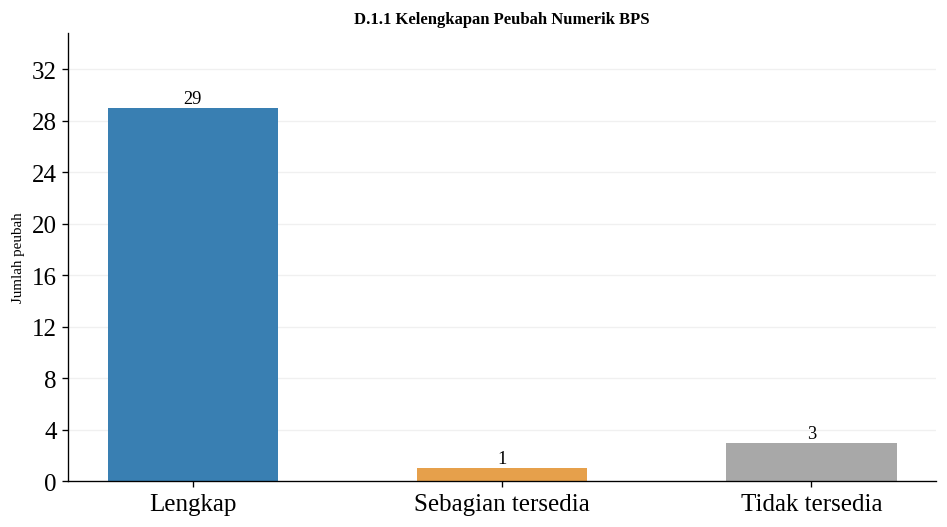

INDIKATOR BPS YANG TIDAK LENGKAP


,peubah,n_valid,n_missing,status
11,bps_garis_kemiskinan_september_2025_rp,0,22,Tidak tersedia seluruhnya
12,bps_penduduk_miskin_september_2025_ribu,0,22,Tidak tersedia seluruhnya
13,bps_persen_miskin_september_2025,0,22,Tidak tersedia seluruhnya
14,bps_jalan_prov_baik_2025_km,21,1,Sebagian tersedia


In [16]:

# ============================================================
# D.1.1 — KELENGKAPAN PEUBAH NUMERIK BPS
# ============================================================

status_bps_d = missing_peubah_c1.loc[
    missing_peubah_c1["sumber"].eq("BPS")
]

urutan = [
    "Lengkap",
    "Sebagian tersedia",
    "Tidak tersedia seluruhnya"
]

jumlah = (
    status_bps_d["status"]
    .value_counts()
    .reindex(urutan, fill_value=0)
)

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.bar(
    ["Lengkap", "Sebagian tersedia", "Tidak tersedia"],
    jumlah.values,
    width=0.55,
    color=["#397fb2", "#e6a04b", "#a8a8a8"]
)

for bar, nilai in zip(bars, jumlah.values):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.4,
        str(nilai),
        ha="center",
        fontsize=11
    )

ax.set_title(
    "D.1.1 Kelengkapan Peubah Numerik BPS",
    fontweight="bold"
)
ax.set_ylabel("Jumlah peubah")
ax.set_ylim(0, max(jumlah) * 1.20)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", alpha=0.18)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

print("INDIKATOR BPS YANG TIDAK LENGKAP")
display(
    status_bps_d.loc[
        status_bps_d["status"].ne("Lengkap"),
        ["peubah", "n_valid", "n_missing", "status"]
    ]
)


Jumlah peubah BPS: 33
Peubah yang divisualisasikan: 30
Peubah tanpa data: 3

Peubah yang tidak divisualisasikan:
- bps_garis_kemiskinan_september_2025_rp
- bps_penduduk_miskin_september_2025_ribu
- bps_persen_miskin_september_2025


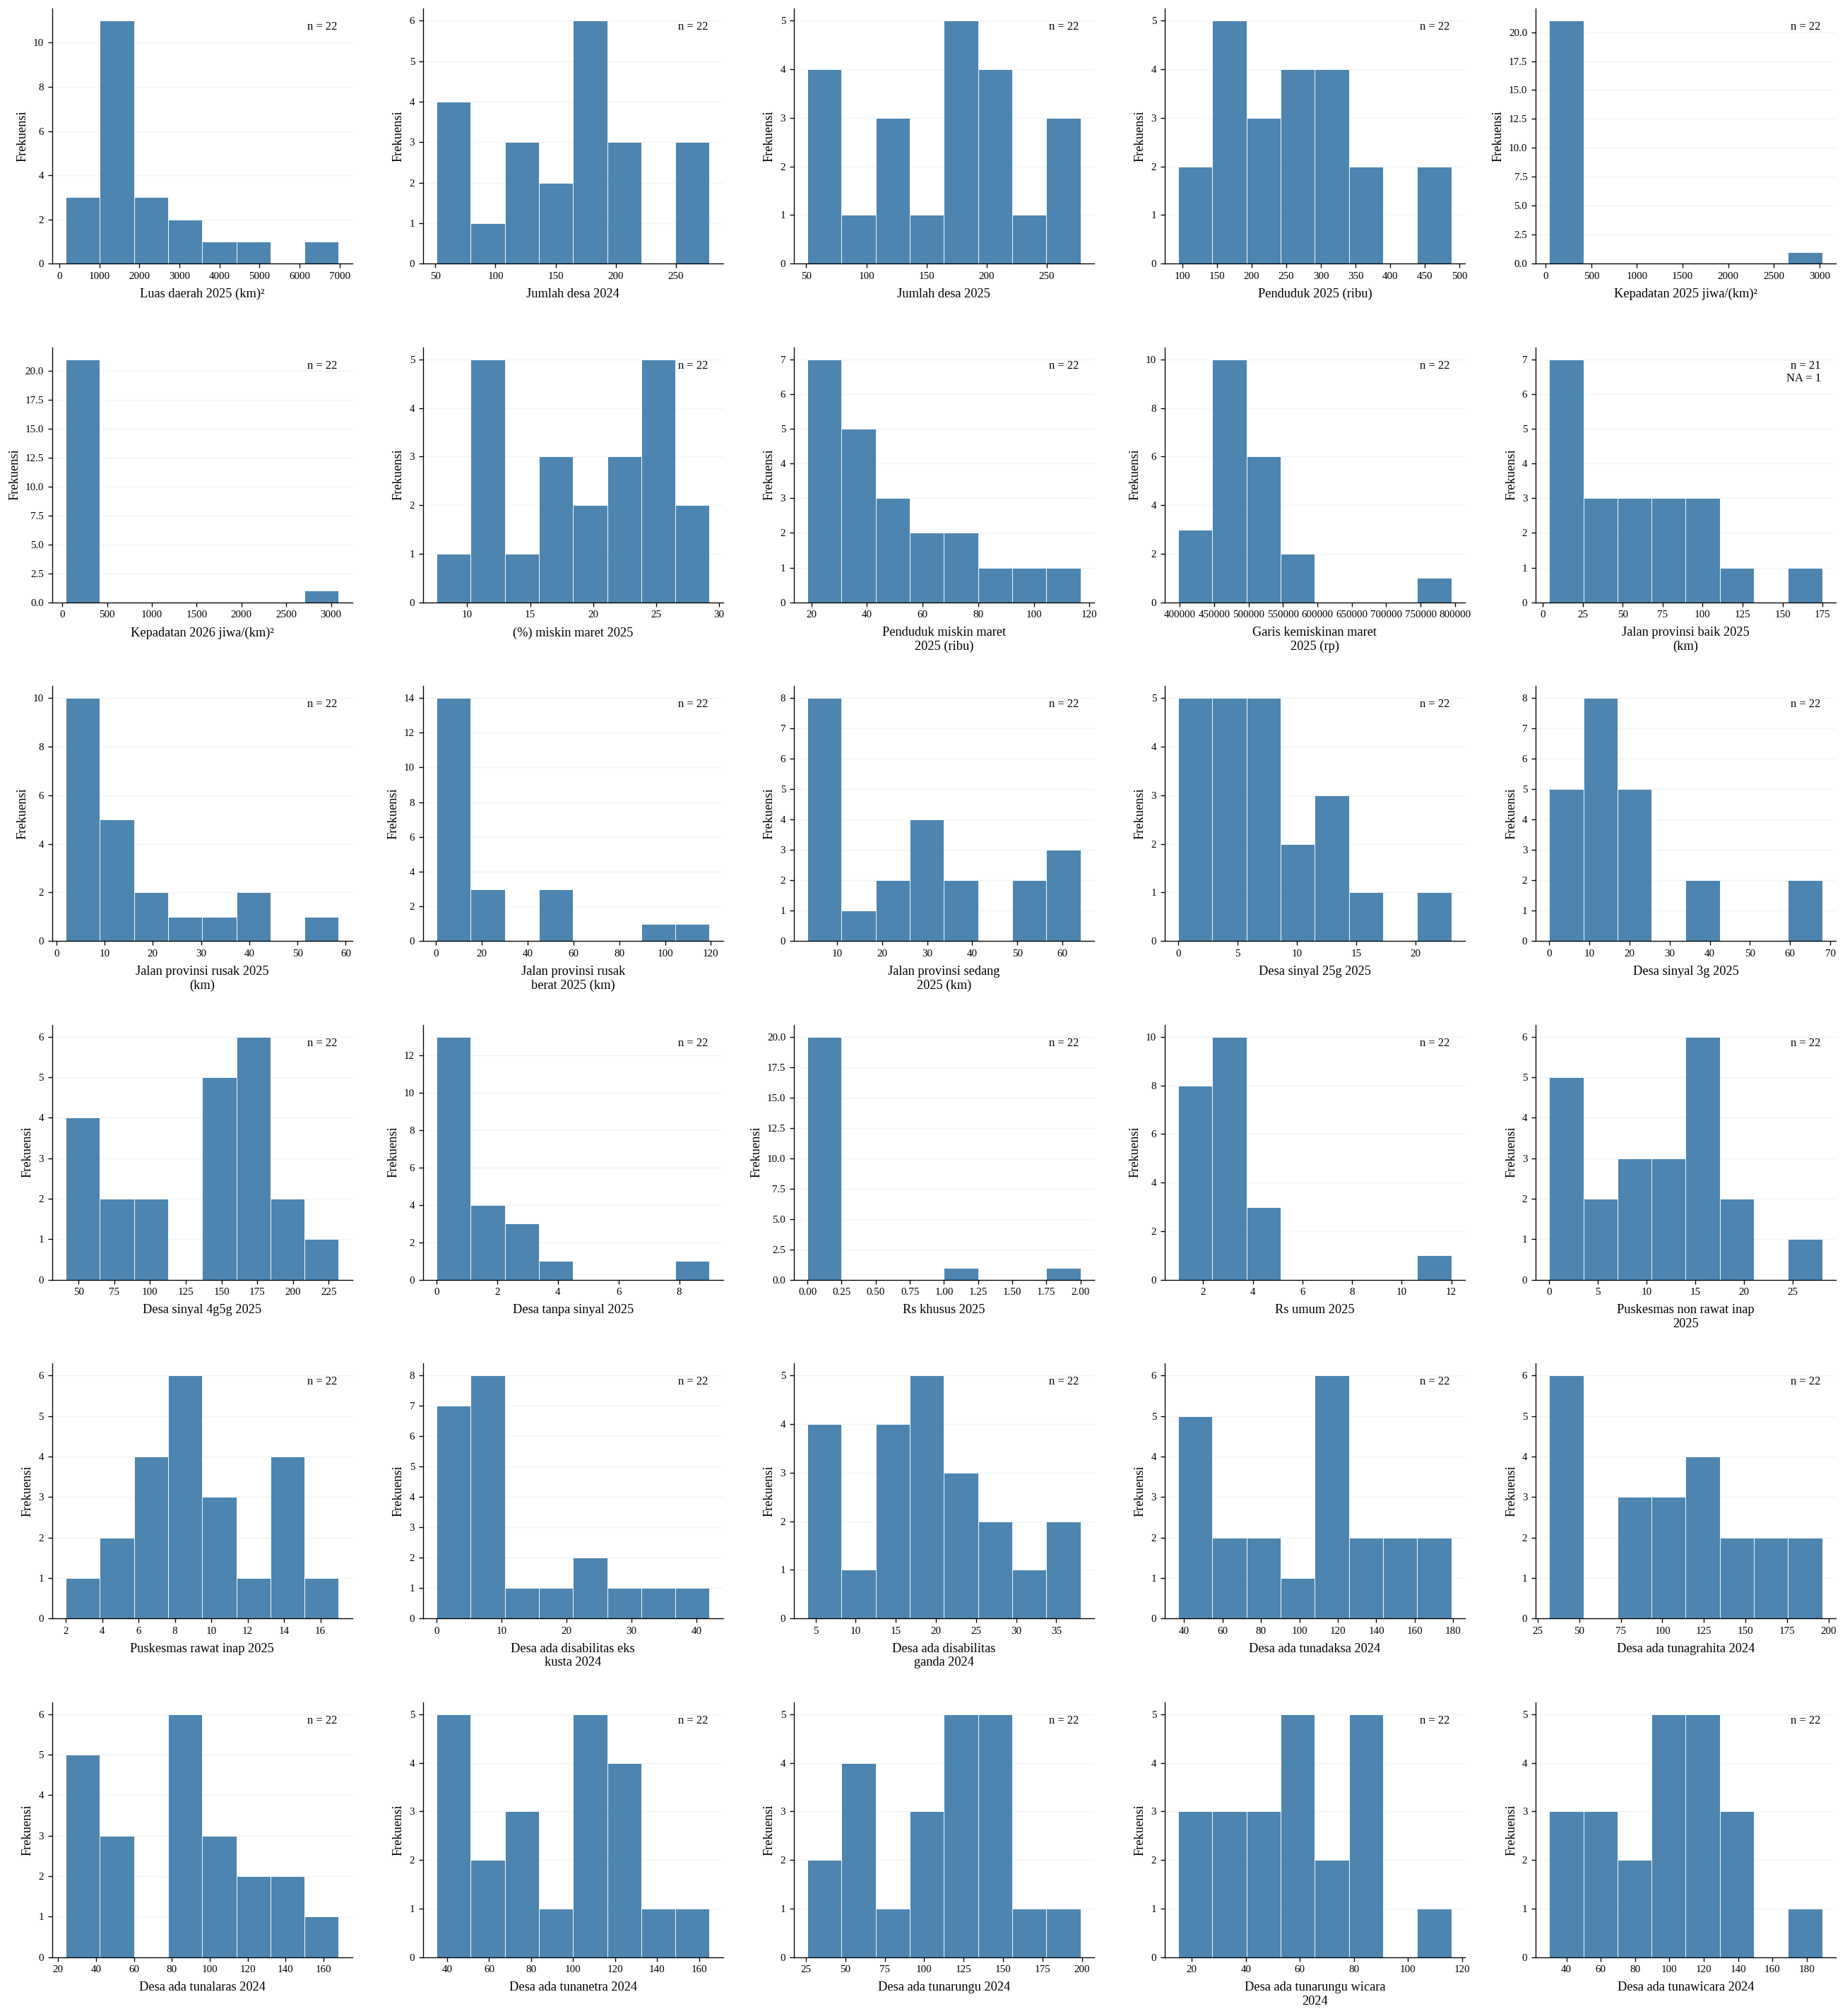

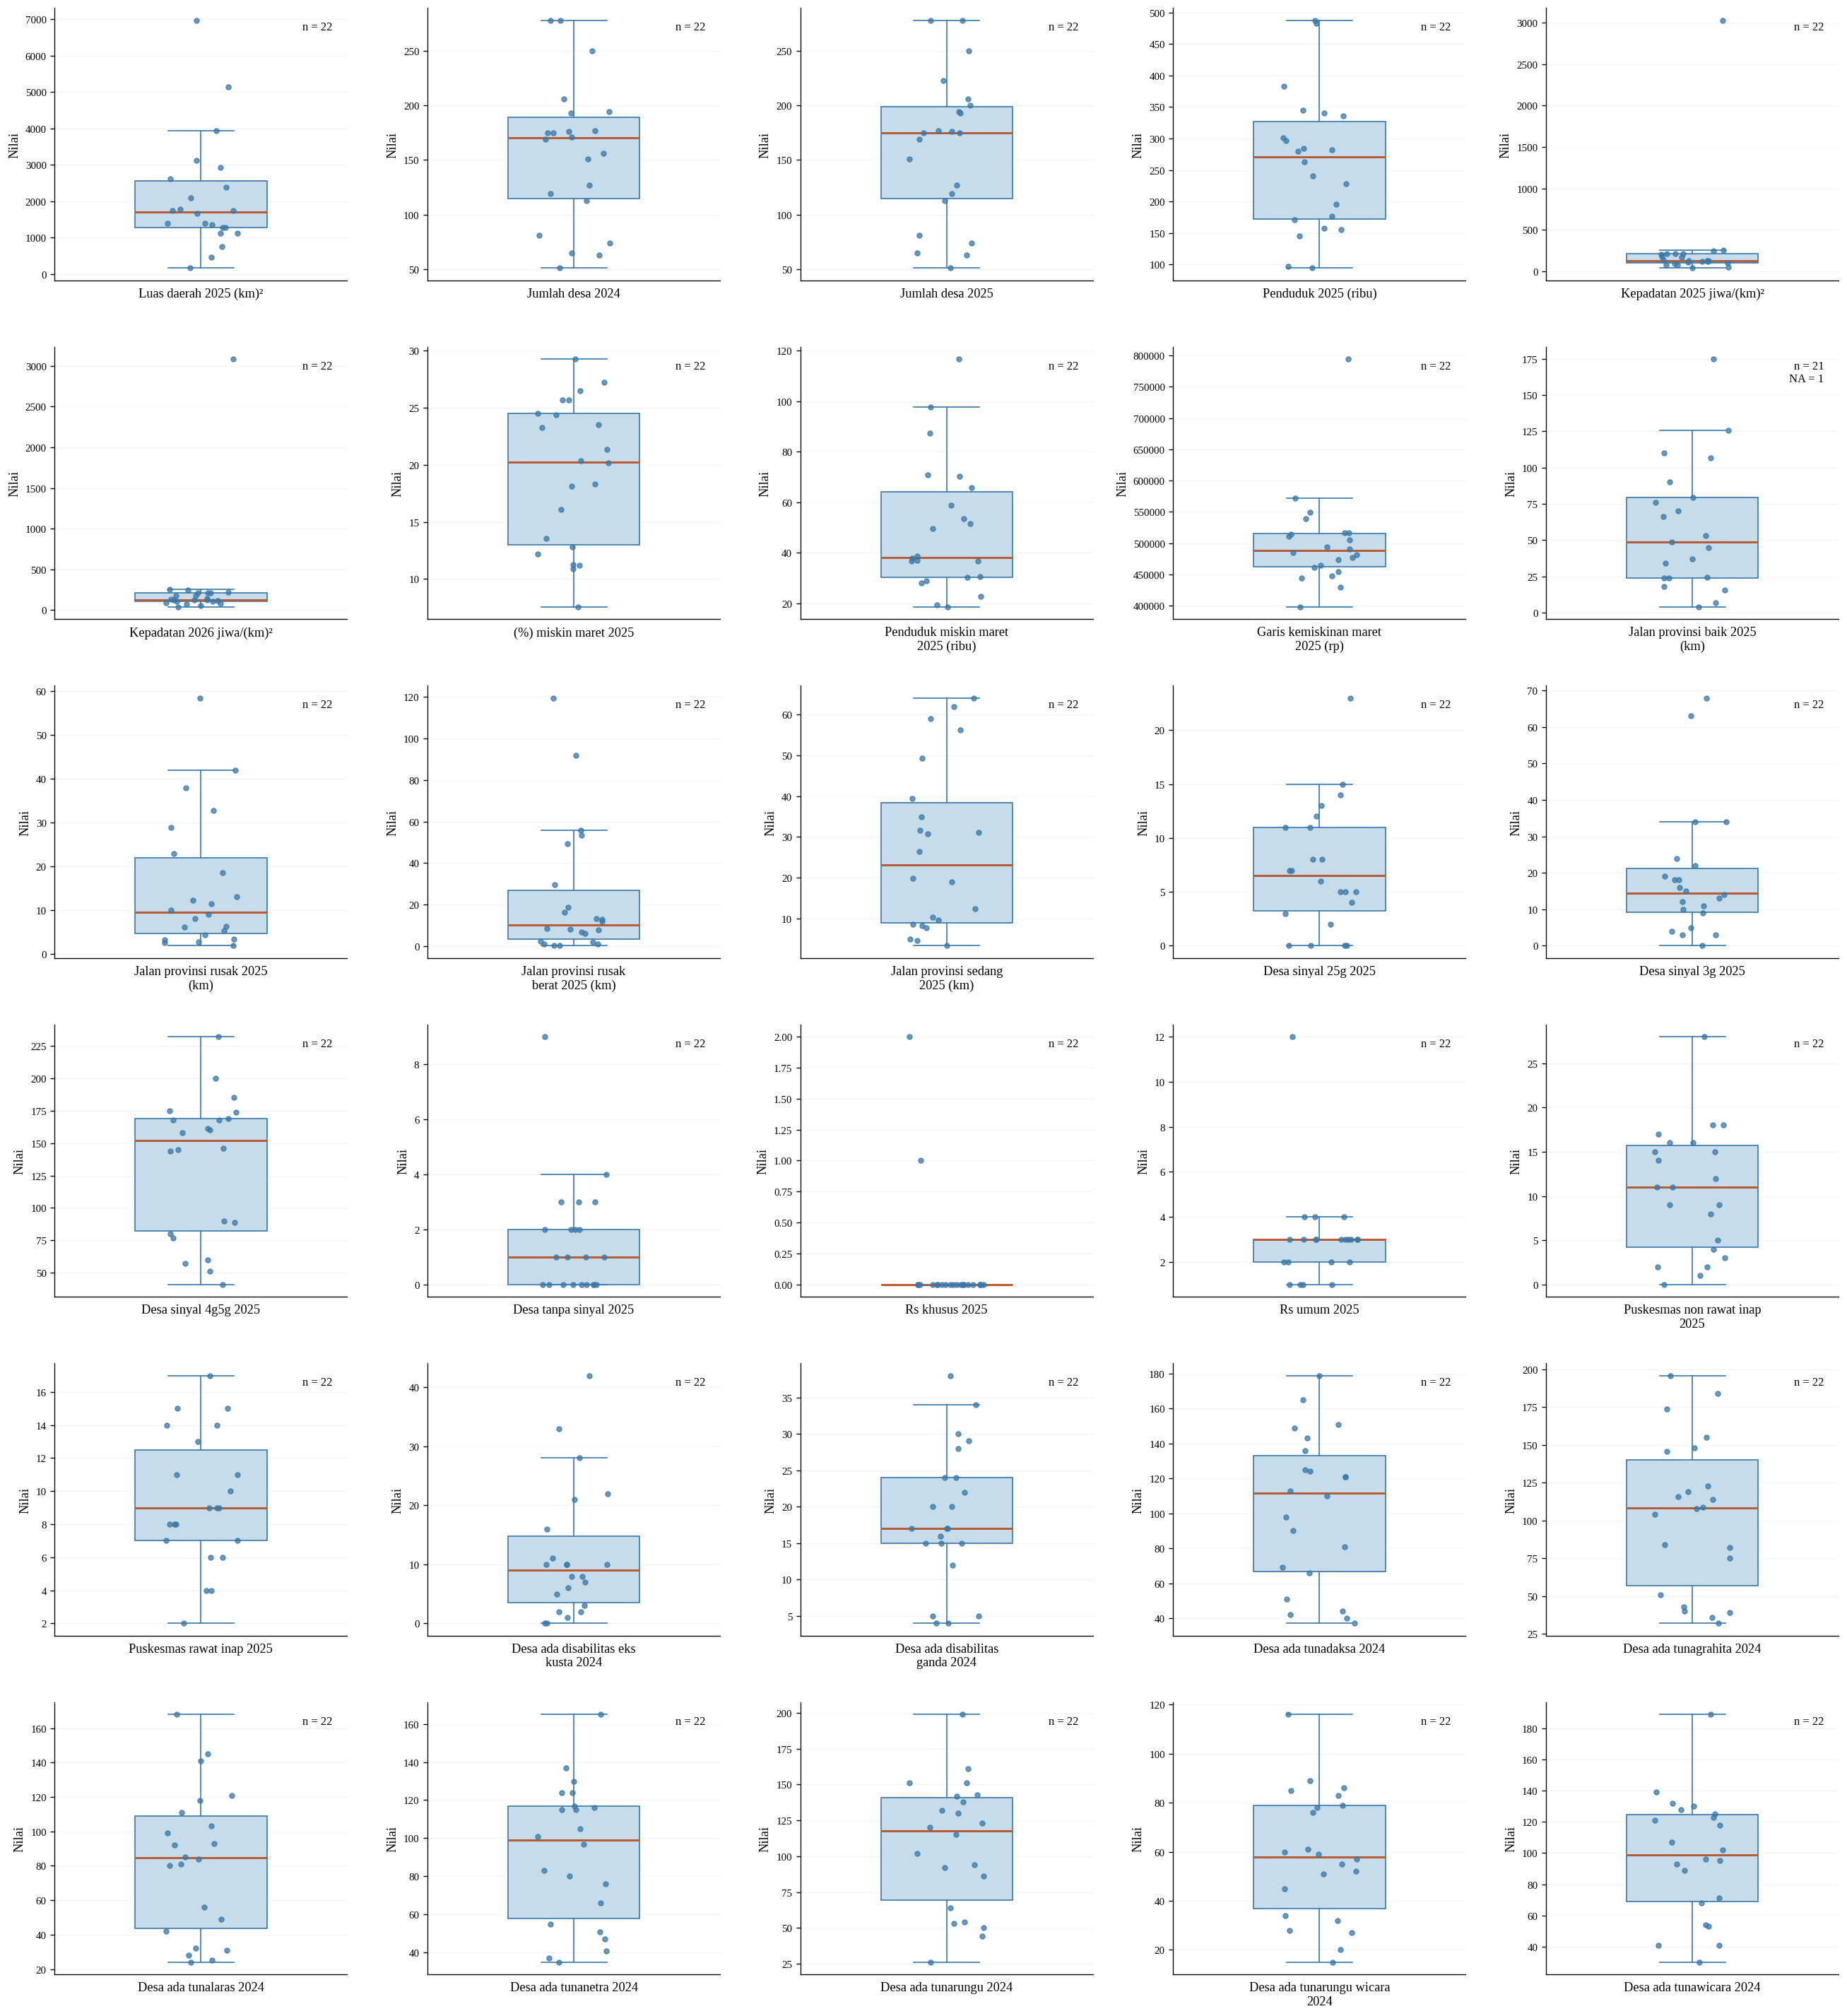


VALIDASI VISUALISASI BPS
Jumlah histogram: 30
Jumlah boxplot: 30
Peubah lengkap: 29
Peubah sebagian tersedia: 1
Peubah tanpa data: 3
df_raw: (22, 197)
Data asli tidak dimodifikasi.


In [17]:
# ============================================================
# D.1 — VISUALISASI DIAGNOSTIK BPS (REVISI)
# 30 peubah valid | 5 kolom x 6 baris
# Gambar 1: Histogram
# Gambar 2: Boxplot + titik observasi
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import textwrap
from IPython.display import display

# Atur default font ke Liberation Serif
plt.rcParams.update({
    "font.family": "Liberation Serif",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9
})

# ------------------------------------------------------------
# A. MENENTUKAN PEUBAH BPS YANG MEMILIKI DATA
# ------------------------------------------------------------

kolom_bps = [
    c for c in angka_audit_b1.columns
    if c.startswith("bps_")
]

bps_plot = angka_audit_b1[kolom_bps].copy()

kolom_valid = [
    c for c in kolom_bps
    if bps_plot[c].notna().any()
]

kolom_kosong = [
    c for c in kolom_bps
    if bps_plot[c].notna().sum() == 0
]

print("Jumlah peubah BPS:", len(kolom_bps))
print("Peubah yang divisualisasikan:", len(kolom_valid))
print("Peubah tanpa data:", len(kolom_kosong))

print("\nPeubah yang tidak divisualisasikan:")
for c in kolom_kosong:
    print("-", c)

assert len(kolom_valid) == 30

# ------------------------------------------------------------
# B. MEMBUAT LABEL INDIKATOR RINGKAS
# ------------------------------------------------------------

def label_bps(c):
    nama = c.replace("bps_", "").replace("_", " ")
    nama = nama.replace(
        "jiwa per km2", "jiwa/km²"
    ).replace(
        "km2", "km²"
    ).replace(
        "ribu", "(ribu)"
    ).replace(
        "persen", "(%)"
    ).replace(
        "km", "(km)"
    ).replace(
        "rp", "(Rp)"
    ).replace(
        "prov", "provinsi"
    )
    return textwrap.fill(
        nama.capitalize(),
        width=25,
        break_long_words=False
    )

# ------------------------------------------------------------
# C. GAMBAR D.1.1 — HISTOGRAM 30 PEUBAH BPS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=6,
    ncols=5,
    figsize=(22, 24)
)

for ax, c in zip(axes.flat, kolom_valid):
    s = bps_plot[c].dropna()
    n = len(s)
    na = 22 - n

    ax.hist(
        s,
        bins=8,
        color="#3978A8",
        edgecolor="white",
        linewidth=0.6,
        alpha=0.9
    )

    ax.set_xlabel(
        label_bps(c),
        labelpad=6
    )

    ax.set_ylabel(
        "Frekuensi"
    )

    ax.text(
        0.95, 0.95,
        f"n = {n}" + (
            f"\nNA = {na}" if na else ""
        ),
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=10
    )

    ax.ticklabel_format(
        axis="x",
        style="plain",
        useOffset=False
    )

    ax.grid(
        axis="y",
        alpha=0.15
    )

    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout(pad=1.5, h_pad=2.8, w_pad=2.0)
plt.show()

# ------------------------------------------------------------
# D. GAMBAR D.1.2 — BOXPLOT 30 PEUBAH BPS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=6,
    ncols=5,
    figsize=(22, 24)
)

rng = np.random.default_rng(42)

for ax, c in zip(axes.flat, kolom_valid):
    s = bps_plot[c].dropna()
    n = len(s)
    na = 22 - n

    ax.boxplot(
        s,
        patch_artist=True,
        widths=0.45,
        showfliers=False,
        boxprops={
            "facecolor": "#C7DCEB",
            "edgecolor": "#3978A8"
        },
        medianprops={
            "color": "#B65C37",
            "linewidth": 1.8
        },
        whiskerprops={
            "color": "#3978A8"
        },
        capprops={
            "color": "#3978A8"
        }
    )

    jitter = rng.uniform(
        -0.13, 0.13, size=n
    )

    ax.scatter(
        1 + jitter,
        s,
        s=17,
        color="#3978A8",
        alpha=0.75,
        zorder=3
    )

    ax.set_xticks([])

    ax.set_xlabel(
        label_bps(c),
        labelpad=6
    )

    ax.set_ylabel(
        "Nilai"
    )

    ax.text(
        0.95, 0.95,
        f"n = {n}" + (
            f"\nNA = {na}" if na else ""
        ),
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=10
    )

    ax.grid(
        axis="y",
        alpha=0.15
    )

    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout(pad=1.5, h_pad=2.8, w_pad=2.0)
plt.show()

# ------------------------------------------------------------
# E. VALIDASI
# ------------------------------------------------------------

print("\nVALIDASI VISUALISASI BPS")
print("Jumlah histogram:", len(kolom_valid))
print("Jumlah boxplot:", len(kolom_valid))
print("Peubah lengkap:", int(bps_plot.notna().all().sum()))
print("Peubah sebagian tersedia:", int((bps_plot.notna().sum().between(1, 21)).sum()))
print("Peubah tanpa data:", len(kolom_kosong))
print("df_raw:", df_raw.shape)
print("Data asli tidak dimodifikasi.")

In [18]:
# ============================================================
# D.1.6 — STANDAR VISUALISASI FINAL
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches

from matplotlib import font_manager
from IPython.display import display

# Periksa ketersediaan font
font_tersedia = any(
    f.name == "Liberation Serif"
    for f in font_manager.fontManager.ttflist
)

if not font_tersedia:
    print(
        "PERINGATAN: Liberation Serif belum terdeteksi. "
        "Instal fonts-liberation sebelum membuat grafik."
    )

plt.rcParams.update({
    "font.family": "Liberation Serif",
    "font.size": 25,
    "axes.titlesize": 25,
    "axes.labelsize": 25,
    "xtick.labelsize": 25,
    "ytick.labelsize": 25,
    "legend.fontsize": 25,
    "figure.titlesize": 25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "savefig.dpi": 300
})

# Kelompok BPS berdasarkan substansi
kelompok_bps_d = {
    "Wilayah dan demografi": [
        "bps_luas_daerah_2025_km2",
        "bps_jumlah_desa_2024",
        "bps_jumlah_desa_2025",
        "bps_penduduk_2025_ribu",
        "bps_kepadatan_2025_jiwa_per_km2",
        "bps_kepadatan_2026_jiwa_per_km2"
    ],
    "Kemiskinan": [
        "bps_persen_miskin_maret_2025",
        "bps_penduduk_miskin_maret_2025_ribu",
        "bps_garis_kemiskinan_maret_2025_rp",
        "bps_persen_miskin_september_2025",
        "bps_penduduk_miskin_september_2025_ribu",
        "bps_garis_kemiskinan_september_2025_rp"
    ],
    "Jalan provinsi": [
        "bps_jalan_prov_baik_2025_km",
        "bps_jalan_prov_sedang_2025_km",
        "bps_jalan_prov_rusak_2025_km",
        "bps_jalan_prov_rusak_berat_2025_km"
    ],
    "Sinyal telekomunikasi": [
        "bps_desa_sinyal_25g_2025",
        "bps_desa_sinyal_3g_2025",
        "bps_desa_sinyal_4g5g_2025",
        "bps_desa_tanpa_sinyal_2025"
    ],
    "Fasilitas kesehatan": [
        "bps_rs_khusus_2025",
        "bps_rs_umum_2025",
        "bps_puskesmas_non_rawat_inap_2025",
        "bps_puskesmas_rawat_inap_2025"
    ],
    "Disabilitas": [
        "bps_desa_ada_disabilitas_eks_kusta_2024",
        "bps_desa_ada_disabilitas_ganda_2024",
        "bps_desa_ada_tunadaksa_2024",
        "bps_desa_ada_tunagrahita_2024",
        "bps_desa_ada_tunalaras_2024",
        "bps_desa_ada_tunanetra_2024",
        "bps_desa_ada_tunarungu_2024",
        "bps_desa_ada_tunarungu_wicara_2024",
        "bps_desa_ada_tunawicara_2024"
    ]
}

# Label pendek, tetap mempertahankan identitas peubah
def label_heatmap_bps(c):

    label = c.removeprefix("bps_")

    label = label.replace(
        "desa_ada_disabilitas_", ""
    )
    label = label.replace("desa_ada_", "")
    label = label.replace("jalan_prov_", "")
    label = label.replace("puskesmas_", "puskesmas ")
    label = label.replace("_jiwa_per_km2", "")
    label = label.replace("_km2", "")
    label = label.replace("_2024", "")
    label = label.replace("_2025", "")
    label = label.replace("_2026", "")
    label = label.replace("_", " ")

    return label.capitalize()

# Verifikasi seluruh 33 peubah terwakili
kolom_bps_kelompok = [
    c
    for cols in kelompok_bps_d.values()
    for c in cols
]

assert len(kolom_bps_kelompok) == 33
assert len(set(kolom_bps_kelompok)) == 33
assert set(kolom_bps_kelompok) == set(bps_cols_d)

wilayah_d = df_raw["kabupaten_kota"].tolist()

print("D.1.6 — VALIDASI PERSIAPAN")
print("Kelompok indikator:", len(kelompok_bps_d))
print("Peubah BPS:", len(kolom_bps_kelompok))
print("Wilayah:", len(wilayah_d))
print("Font:", plt.rcParams["font.family"])
print("Ukuran font:", plt.rcParams["font.size"])

D.1.6 — VALIDASI PERSIAPAN
Kelompok indikator: 6
Peubah BPS: 33
Wilayah: 22
Font: ['Liberation Serif']
Ukuran font: 25.0


### Proporsi desa/kelurahan tanpa sinyal

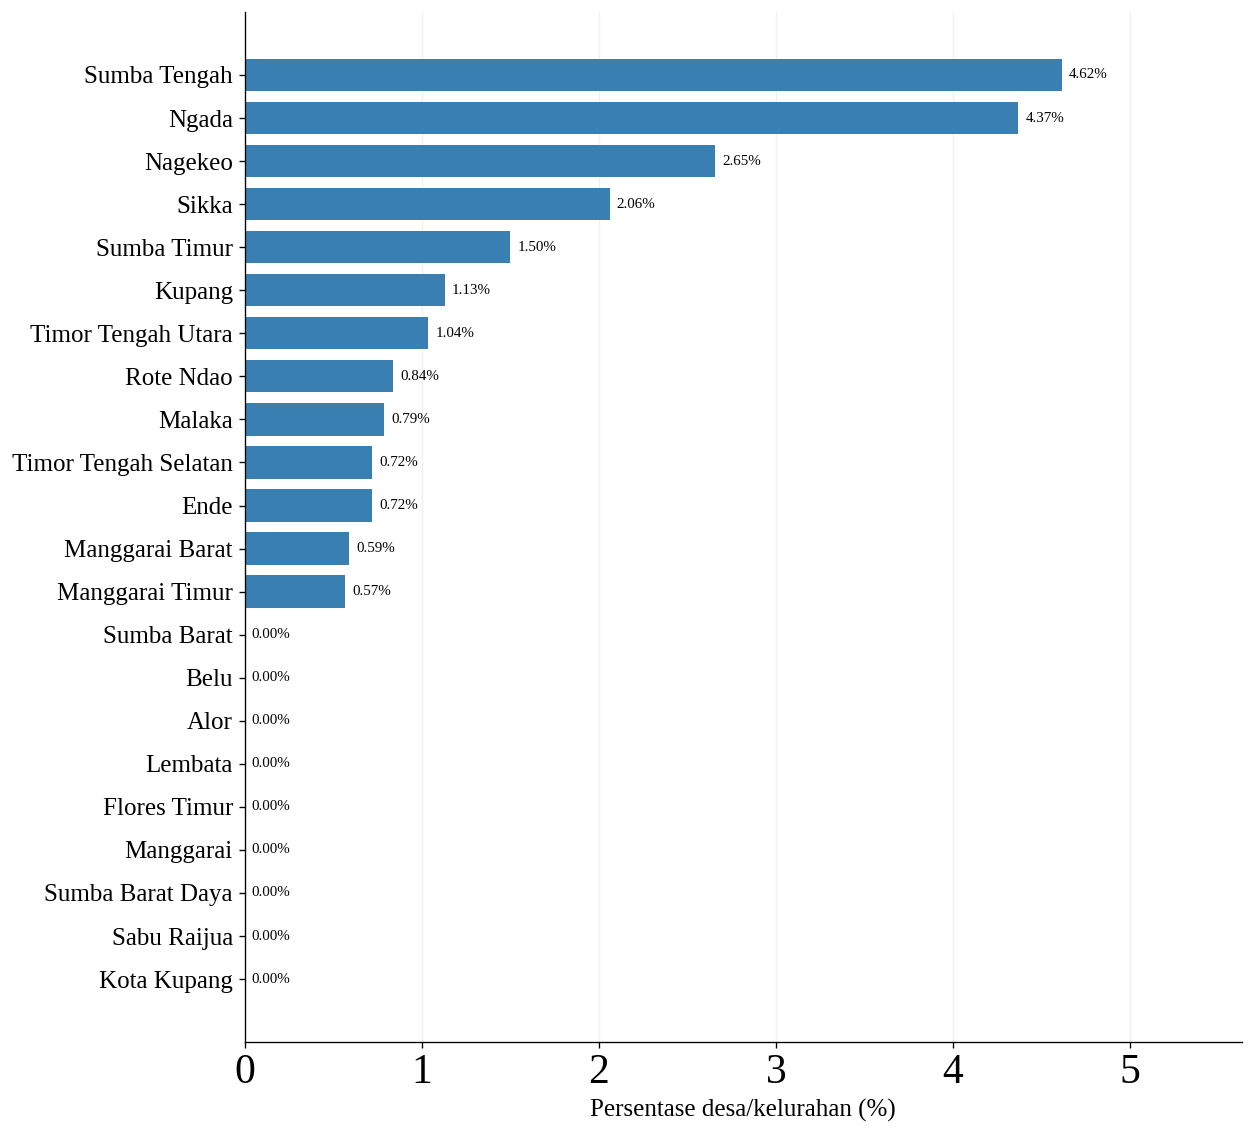

LIMA WILAYAH DENGAN PROPORSI TERTINGGI


,kabupaten_kota,desa_tanpa_sinyal,jumlah_desa,persentase
15,Sumba Tengah,3.0,65,4.615
11,Ngada,9.0,206,4.369
17,Nagekeo,3.0,113,2.655
9,Sikka,4.0,194,2.062
1,Sumba Timur,3.0,200,1.500



WILAYAH DENGAN NILAI NOL


,kabupaten_kota,desa_tanpa_sinyal,jumlah_desa,persentase
0,Sumba Barat,0.0,74,0.0
5,Belu,0.0,81,0.0
6,Alor,0.0,175,0.0
7,Lembata,0.0,151,0.0
8,Flores Timur,0.0,250,0.0
12,Manggarai,0.0,223,0.0
16,Sumba Barat Daya,0.0,175,0.0
19,Sabu Raijua,0.0,63,0.0
21,Kota Kupang,0.0,51,0.0


In [19]:
# ====================================================
# D.1.4 — PROPORSI DESA TANPA SINYAL 2025
# ====================================================

pembilang = angka_audit_a[
    "bps_desa_tanpa_sinyal_2025"
]

penyebut = angka_audit_a[
    "bps_jumlah_desa_2025"
]

proporsi = (
    pembilang.div(penyebut.where(penyebut.gt(0)))
    * 100
)

grafik_sinyal_d = pd.DataFrame({
    "kabupaten_kota": df_raw[
        "kabupaten_kota"
    ],
    "desa_tanpa_sinyal": pembilang,
    "jumlah_desa": penyebut,
    "persentase": proporsi
}).sort_values(
    "persentase",
    ascending=False
)

fig, ax = plt.subplots(figsize=(11, 10))

bars = ax.barh(
    grafik_sinyal_d["kabupaten_kota"],
    grafik_sinyal_d["persentase"],
    color="#397fb2",
    height=0.75
)

ax.invert_yaxis()

batas_x = max(
    5.0,
    grafik_sinyal_d["persentase"].max() * 1.22
)

ax.set_xlim(0, batas_x)

for bar, nilai in zip(
    bars,
    grafik_sinyal_d["persentase"]
):
    ax.text(
        nilai + 0.04,
        bar.get_y() + bar.get_height()/2,
        f"{nilai:.2f}%",
        va="center",
        fontsize=9
    )

ax.set_xlabel("Persentase desa/kelurahan (%)", fontsize=15)
ax.tick_params(axis="y", labelsize=15)
ax.grid(axis="x", alpha=0.18)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

print("LIMA WILAYAH DENGAN PROPORSI TERTINGGI")
display(grafik_sinyal_d.head(5).round(3))

print("\nWILAYAH DENGAN NILAI NOL")
display(
    grafik_sinyal_d.loc[
        grafik_sinyal_d["desa_tanpa_sinyal"].eq(0),
        ["kabupaten_kota", "desa_tanpa_sinyal",
         "jumlah_desa", "persentase"]
    ]
)

### Visualisasi khusus ketidaksesuaian jumlah desa dan disabilitas

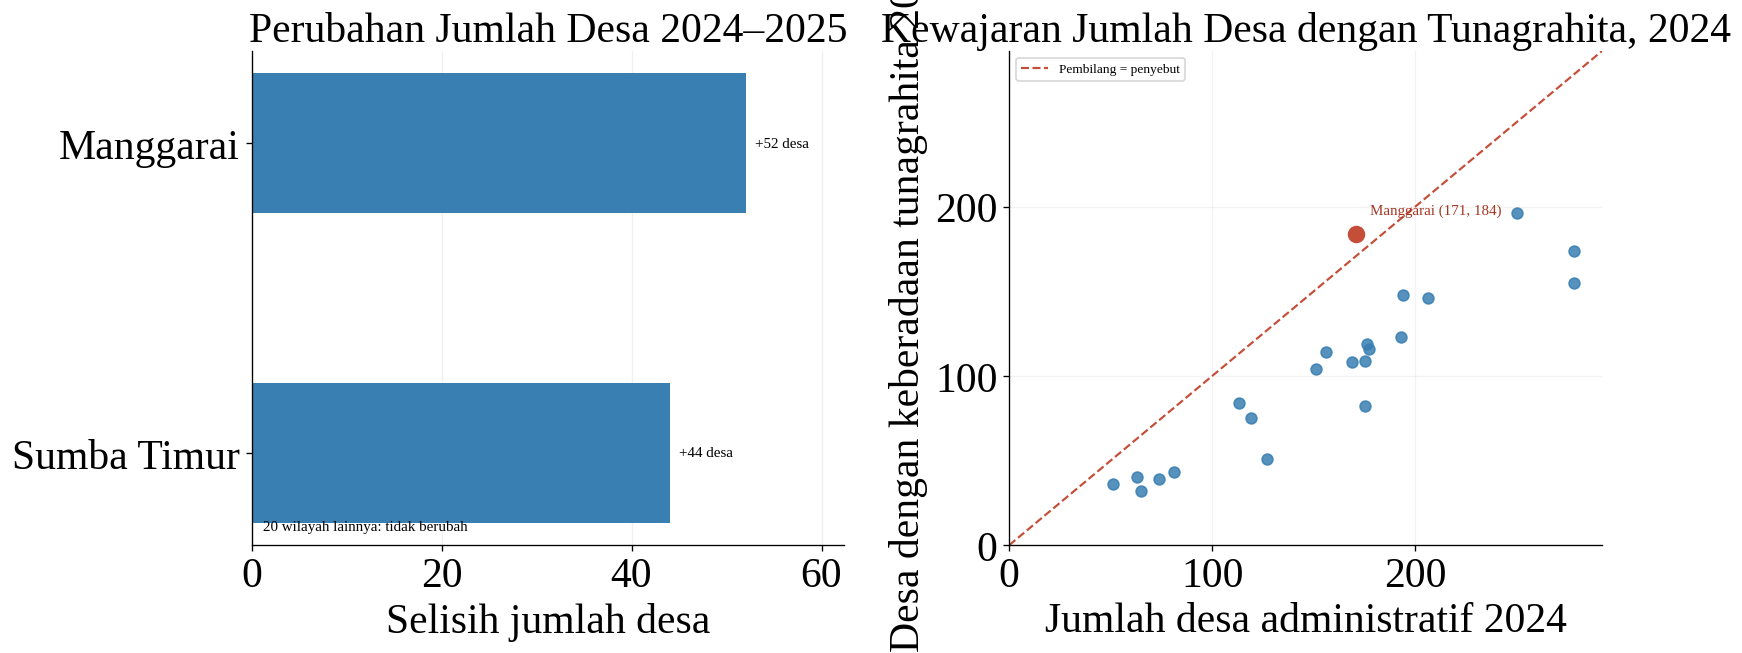

In [20]:

# ============================================================
# D.1.5 — DIAGNOSTIK PERUBAHAN JUMLAH DESA
# DAN KETIDAKWAJARAN PEMBILANG DISABILITAS
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6)
)

# ------------------------------------------------------------
# A. Perubahan jumlah desa 2024–2025
# ------------------------------------------------------------

perubahan = perubahan_desa_c3.loc[
    perubahan_desa_c3["selisih"].ne(0)
].sort_values("selisih")

axes[0].barh(
    perubahan["kabupaten_kota"],
    perubahan["selisih"],
    color="#397fb2",
    height=0.45
)

for i, nilai in enumerate(perubahan["selisih"]):
    axes[0].text(
        nilai + 1,
        i,
        f"+{int(nilai)} desa",
        va="center",
        fontsize=9
    )

axes[0].set_xlim(
    0,
    max(60, perubahan["selisih"].max() * 1.2)
)

axes[0].set_title(
    "Perubahan Jumlah Desa 2024–2025"
)
axes[0].set_xlabel("Selisih jumlah desa")
axes[0].grid(axis="x", alpha=0.18)
axes[0].set_axisbelow(True)

axes[0].text(
    0.02, 0.03,
    "20 wilayah lainnya: tidak berubah",
    transform=axes[0].transAxes,
    fontsize=9
)

# ------------------------------------------------------------
# B. Jumlah desa disabilitas vs penyebut 2024
# ------------------------------------------------------------

x = angka_audit_a[
    "bps_jumlah_desa_2024"
]

y = angka_audit_a[
    "bps_desa_ada_tunagrahita_2024"
]

axes[1].scatter(
    x, y,
    s=42,
    color="#397fb2",
    alpha=0.85
)

batas = max(x.max(), y.max()) * 1.05

axes[1].plot(
    [0, batas],
    [0, batas],
    linestyle="--",
    color="#c44e38",
    linewidth=1.3,
    label="Pembilang = penyebut"
)

idx_manggarai = df_raw.index[
    df_raw["kabupaten_kota"].eq("Manggarai")
][0]

axes[1].scatter(
    [x.at[idx_manggarai]],
    [y.at[idx_manggarai]],
    color="#c44e38",
    s=90,
    zorder=5
)

axes[1].annotate(
    "Manggarai (171, 184)",
    xy=(
        x.at[idx_manggarai],
        y.at[idx_manggarai]
    ),
    xytext=(8, 12),
    textcoords="offset points",
    fontsize=9,
    color="#a53623"
)

axes[1].set_xlim(0, batas)
axes[1].set_ylim(0, batas)

axes[1].set_title(
    "Kewajaran Jumlah Desa dengan Tunagrahita, 2024"
)
axes[1].set_xlabel("Jumlah desa administratif 2024")
axes[1].set_ylabel(
    "Desa dengan keberadaan tunagrahita 2024"
)
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.15)
axes[1].set_axisbelow(True)

plt.tight_layout()
plt.show()


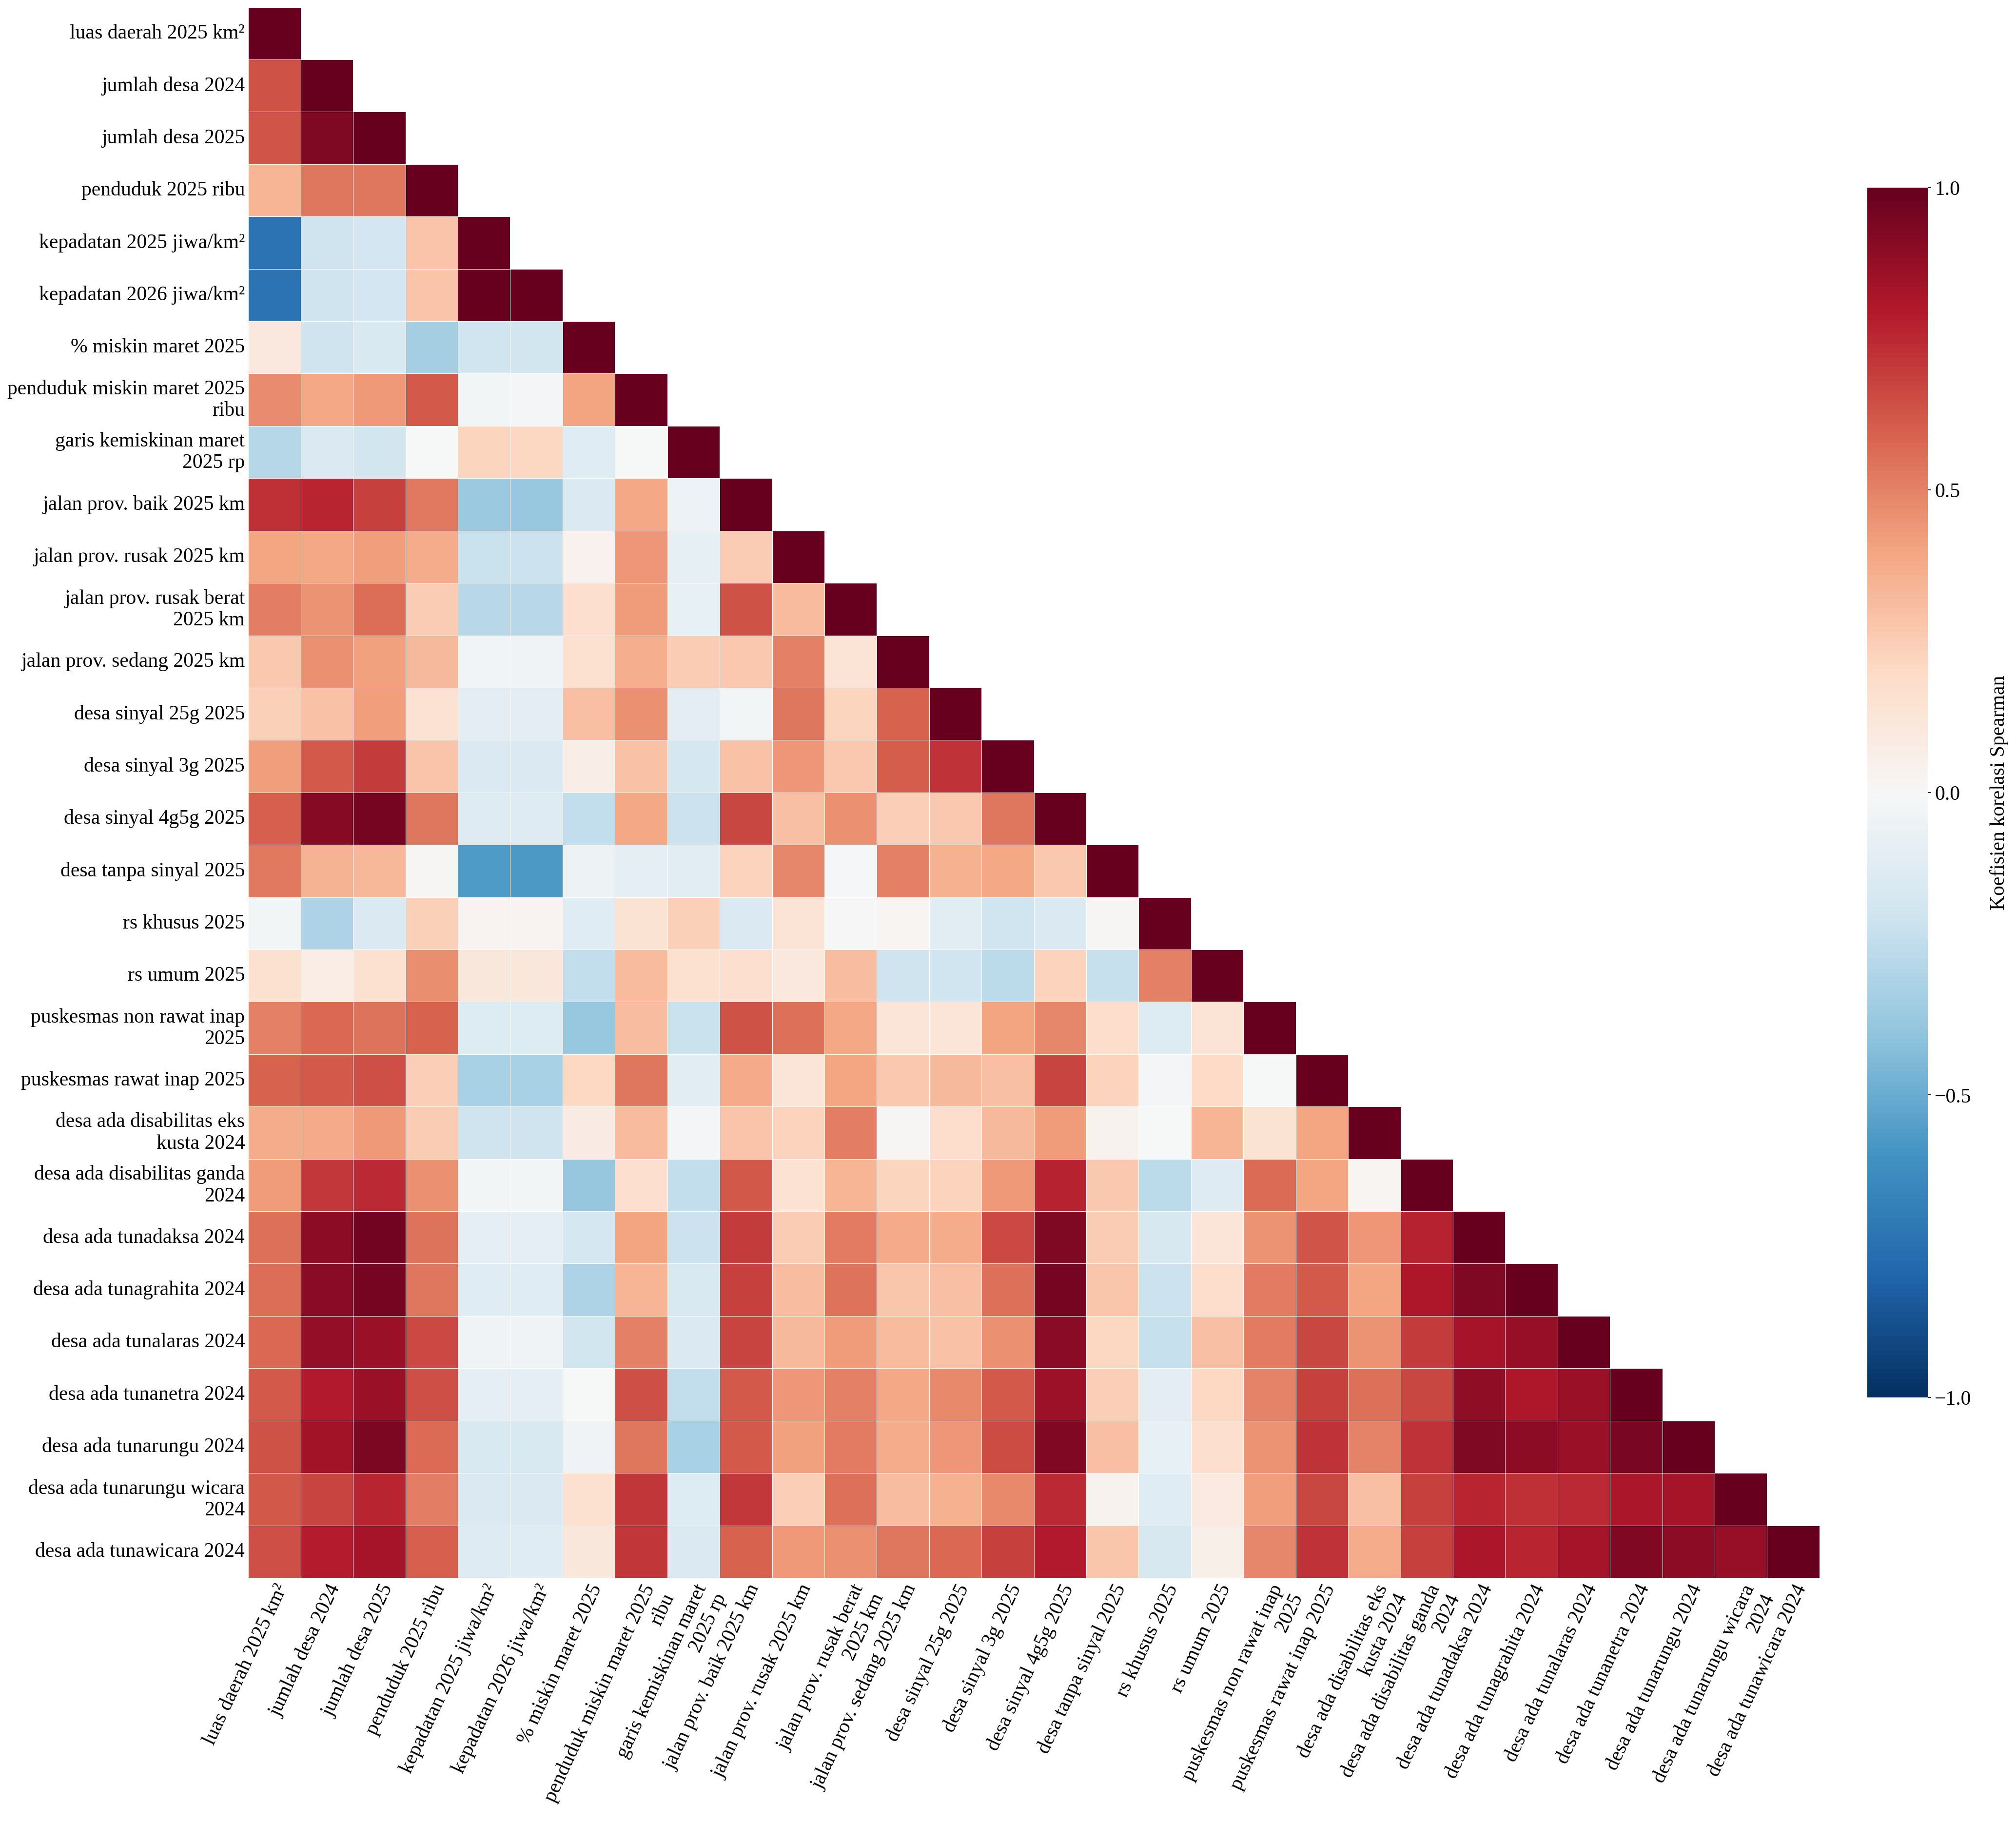

Jumlah peubah: 30
Ukuran font: 20 pt
Font: Liberation Serif
Data tidak dimodifikasi.


In [21]:
# ============================================================
# D.1.6 — HEATMAP KORELASI SPEARMAN BPS (REVISI)
# Font: Liberation Serif
# Fontsize: 20 pt
# Tanpa judul
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import textwrap

# ------------------------------------------------------------
# A. PENGATURAN FONT
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "Liberation Serif",
    "font.size": 20,
    "axes.labelsize": 20,
    "xtick.labelsize": 20,
    "ytick.labelsize": 20,
    "legend.fontsize": 20,
    "figure.dpi": 150,
    "savefig.dpi": 300
})

# ------------------------------------------------------------
# B. LABEL PEUBAH DAN MATRIKS KORELASI
# ------------------------------------------------------------

# Menghitung korelasi Spearman terlebih dahulu
matriks_spearman_bps = angka_audit_a[kolom_valid].corr(
    method="spearman",
    min_periods=8
)

def label_heatmap_bps(nama):

    label = (
        nama.replace("bps_", "")
            .replace("_", " ")
            .replace("jiwa per km2", "jiwa/km²")
            .replace("km2", "km²")
            .replace("persen", "%")
            .replace("prov", "prov.")
    )

    return textwrap.fill(
        label,
        width=26,
        break_long_words=False
    )

# Menggunakan kolom_valid yang sudah didefinisikan sebelumnya
labels = [
    label_heatmap_bps(c)
    for c in kolom_valid
]

# ------------------------------------------------------------
# C. MASK SEGITIGA ATAS
# ------------------------------------------------------------

mask = np.triu(
    np.ones_like(
        matriks_spearman_bps,
        dtype=bool
    ),
    k=1
)

# ------------------------------------------------------------
# D. VISUALISASI HEATMAP
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(42, 38)
)

sns.heatmap(
    matriks_spearman_bps,
    mask=mask,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    annot=False,
    linewidths=0.35,
    linecolor="white",
    xticklabels=labels,
    yticklabels=labels,
    cbar_kws={
        "shrink": 0.65,
        "pad": 0.025,
        "ticks": [-1, -0.5, 0, 0.5, 1]
    },
    ax=ax
)

# ------------------------------------------------------------
# E. LABEL DAN COLORBAR
# ------------------------------------------------------------

ax.set_xticklabels(
    labels,
    rotation=65,
    ha="right",
    rotation_mode="anchor",
    fontsize=20
)

ax.set_yticklabels(
    labels,
    rotation=0,
    fontsize=20
)

ax.set_xlabel("")
ax.set_ylabel("")

ax.tick_params(
    axis="both",
    length=0
)

cbar = ax.collections[0].colorbar

cbar.ax.tick_params(
    labelsize=20
)

cbar.set_label(
    "Koefisien korelasi Spearman",
    fontsize=20,
    labelpad=18
)

# ------------------------------------------------------------
# F. PENGATURAN MARGIN
# ------------------------------------------------------------

fig.subplots_adjust(
    left=0.29,
    bottom=0.32,
    right=0.91,
    top=0.99
)

plt.show()

print("Jumlah peubah:", len(kolom_valid))
print("Ukuran font: 20 pt")
print("Font: Liberation Serif")
print("Data tidak dimodifikasi.")

## Visualisasi Diagnostik KRB (Kajian Risiko Bencana)

In [22]:

# ============================================================
# D.2.0 — PERSIAPAN VISUALISASI KRB
# Font: Liberation Serif | Ukuran: 25
# Tanpa judul grafik
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator
from IPython.display import display

plt.rcParams.update({
    "font.family": "Liberation Serif",
    "font.size": 25,
    "axes.labelsize": 25,
    "axes.titlesize": 25,
    "xtick.labelsize": 25,
    "ytick.labelsize": 25,
    "legend.fontsize": 25,
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False
})

label_krb = {
    "banjir": "Banjir",
    "banjir_bandang": "Banjir bandang",
    "cuaca_ekstrem": "Cuaca ekstrem",
    "gelombang_abrasi": "Gelombang dan abrasi",
    "gempa_bumi": "Gempa bumi",
    "karhutla": "Kebakaran hutan/lahan",
    "kekeringan": "Kekeringan",
    "letusan_gunung_api": "Letusan gunung api",
    "likuefaksi": "Likuefaksi",
    "tanah_longsor": "Tanah longsor",
    "tsunami": "Tsunami"
}

kol_total_krb = [
    f"krb_{jenis}_total_ha"
    for jenis in jenis_krb
]

krb_total_d2 = angka_audit_a[
    kol_total_krb
].copy()

assert len(jenis_krb) == 11
assert krb_total_d2.shape == (22, 11)

print("Jumlah jenis bahaya:", len(jenis_krb))
print("Jumlah wilayah:", len(krb_total_d2))
print("Font: Liberation Serif, 25 pt")
print("Data asli tidak dimodifikasi.")


Jumlah jenis bahaya: 11
Jumlah wilayah: 22
Font: Liberation Serif, 25 pt
Data asli tidak dimodifikasi.


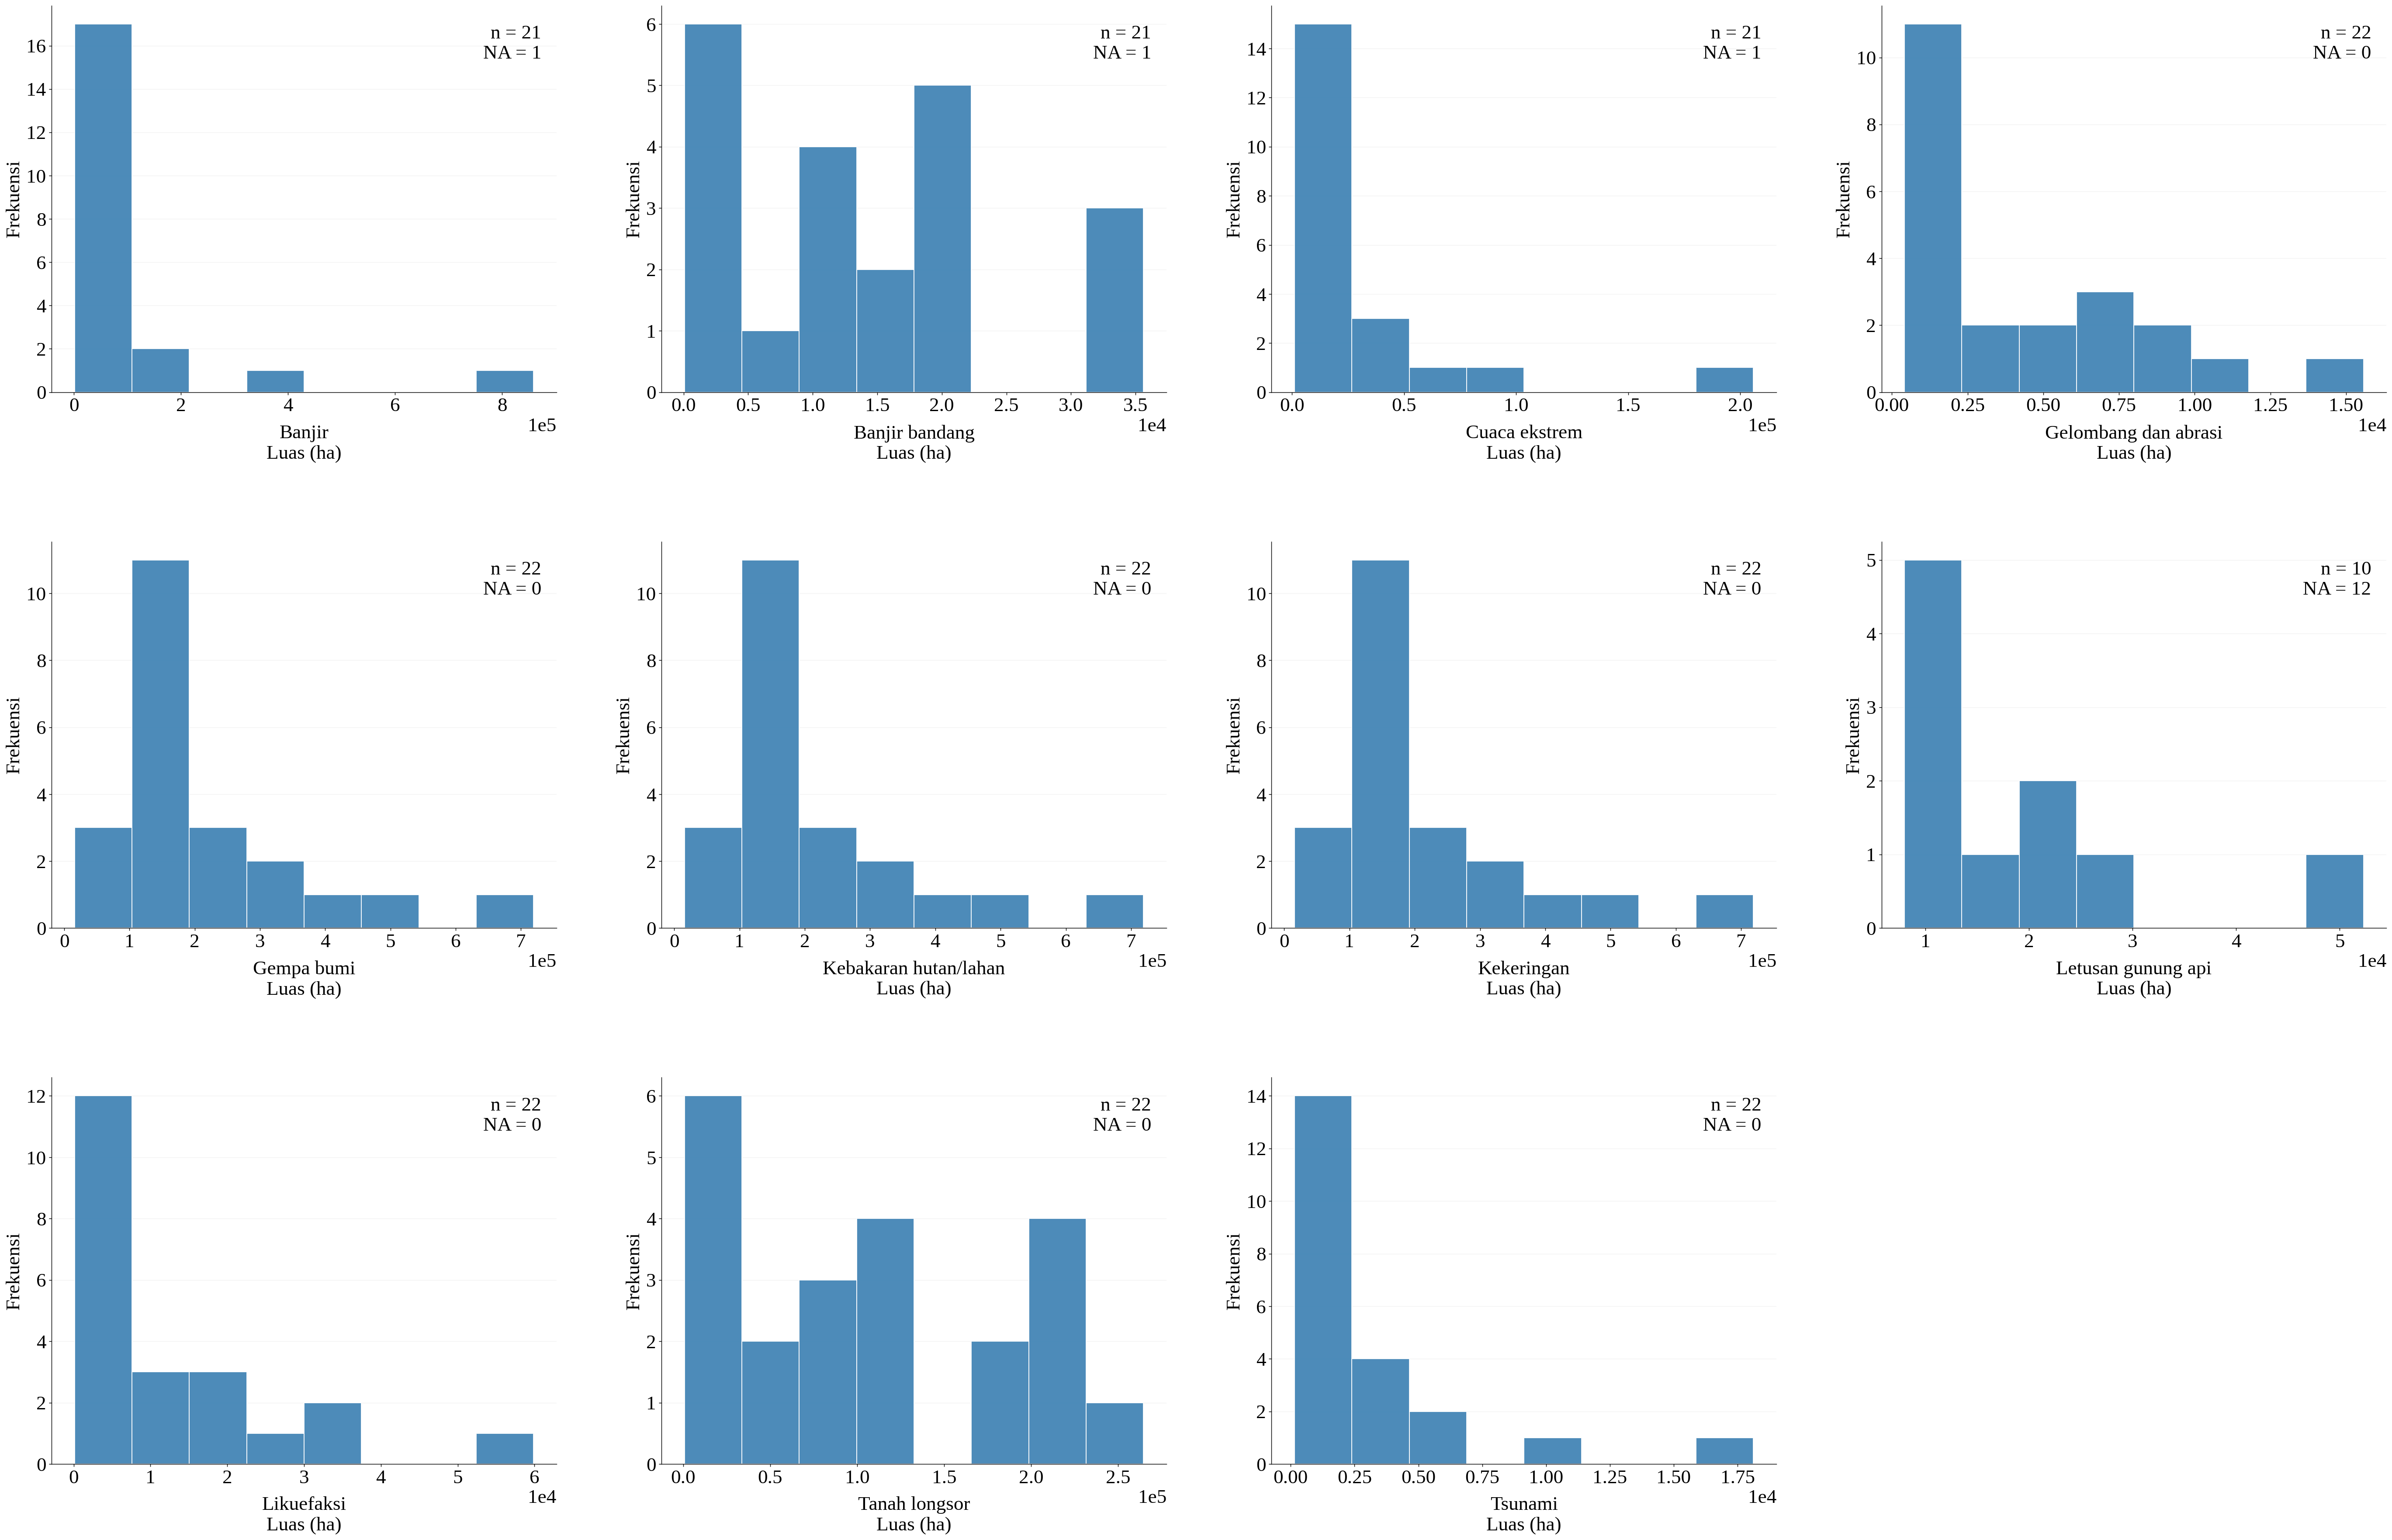

In [23]:

# ============================================================
# D.2.1 — HISTOGRAM LUAS TOTAL KRB
# 11 jenis bahaya | 4 kolom x 3 baris
# ============================================================

fig, axes = plt.subplots(
    3, 4,
    figsize=(44, 29)
)

axes = axes.ravel()

for i, jenis in enumerate(jenis_krb):

    ax = axes[i]

    kol = f"krb_{jenis}_total_ha"
    s = angka_audit_a[kol].dropna()

    ax.hist(
        s.values,
        bins=8,
        color="#397FB2",
        edgecolor="white",
        linewidth=1.1,
        alpha=0.90
    )

    ax.set_xlabel(
        f"{label_krb[jenis]}\nLuas (ha)",
        fontsize=25,
        labelpad=12
    )

    ax.set_ylabel(
        "Frekuensi",
        fontsize=25
    )

    ax.text(
        0.97, 0.95,
        f"n = {len(s)}\nNA = {22-len(s)}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=25
    )

    ax.tick_params(
        axis="both",
        labelsize=25
    )

    ax.yaxis.set_major_locator(
        MaxNLocator(integer=True)
    )

    ax.ticklabel_format(
        axis="x",
        style="sci",
        scilimits=(-3, 4)
    )

    ax.xaxis.get_offset_text().set_fontsize(25)

    ax.grid(axis="y", alpha=0.16)
    ax.set_axisbelow(True)

for ax in axes[len(jenis_krb):]:
    ax.axis("off")

fig.tight_layout(
    pad=3.0,
    w_pad=3.0,
    h_pad=4.0
)

plt.show()


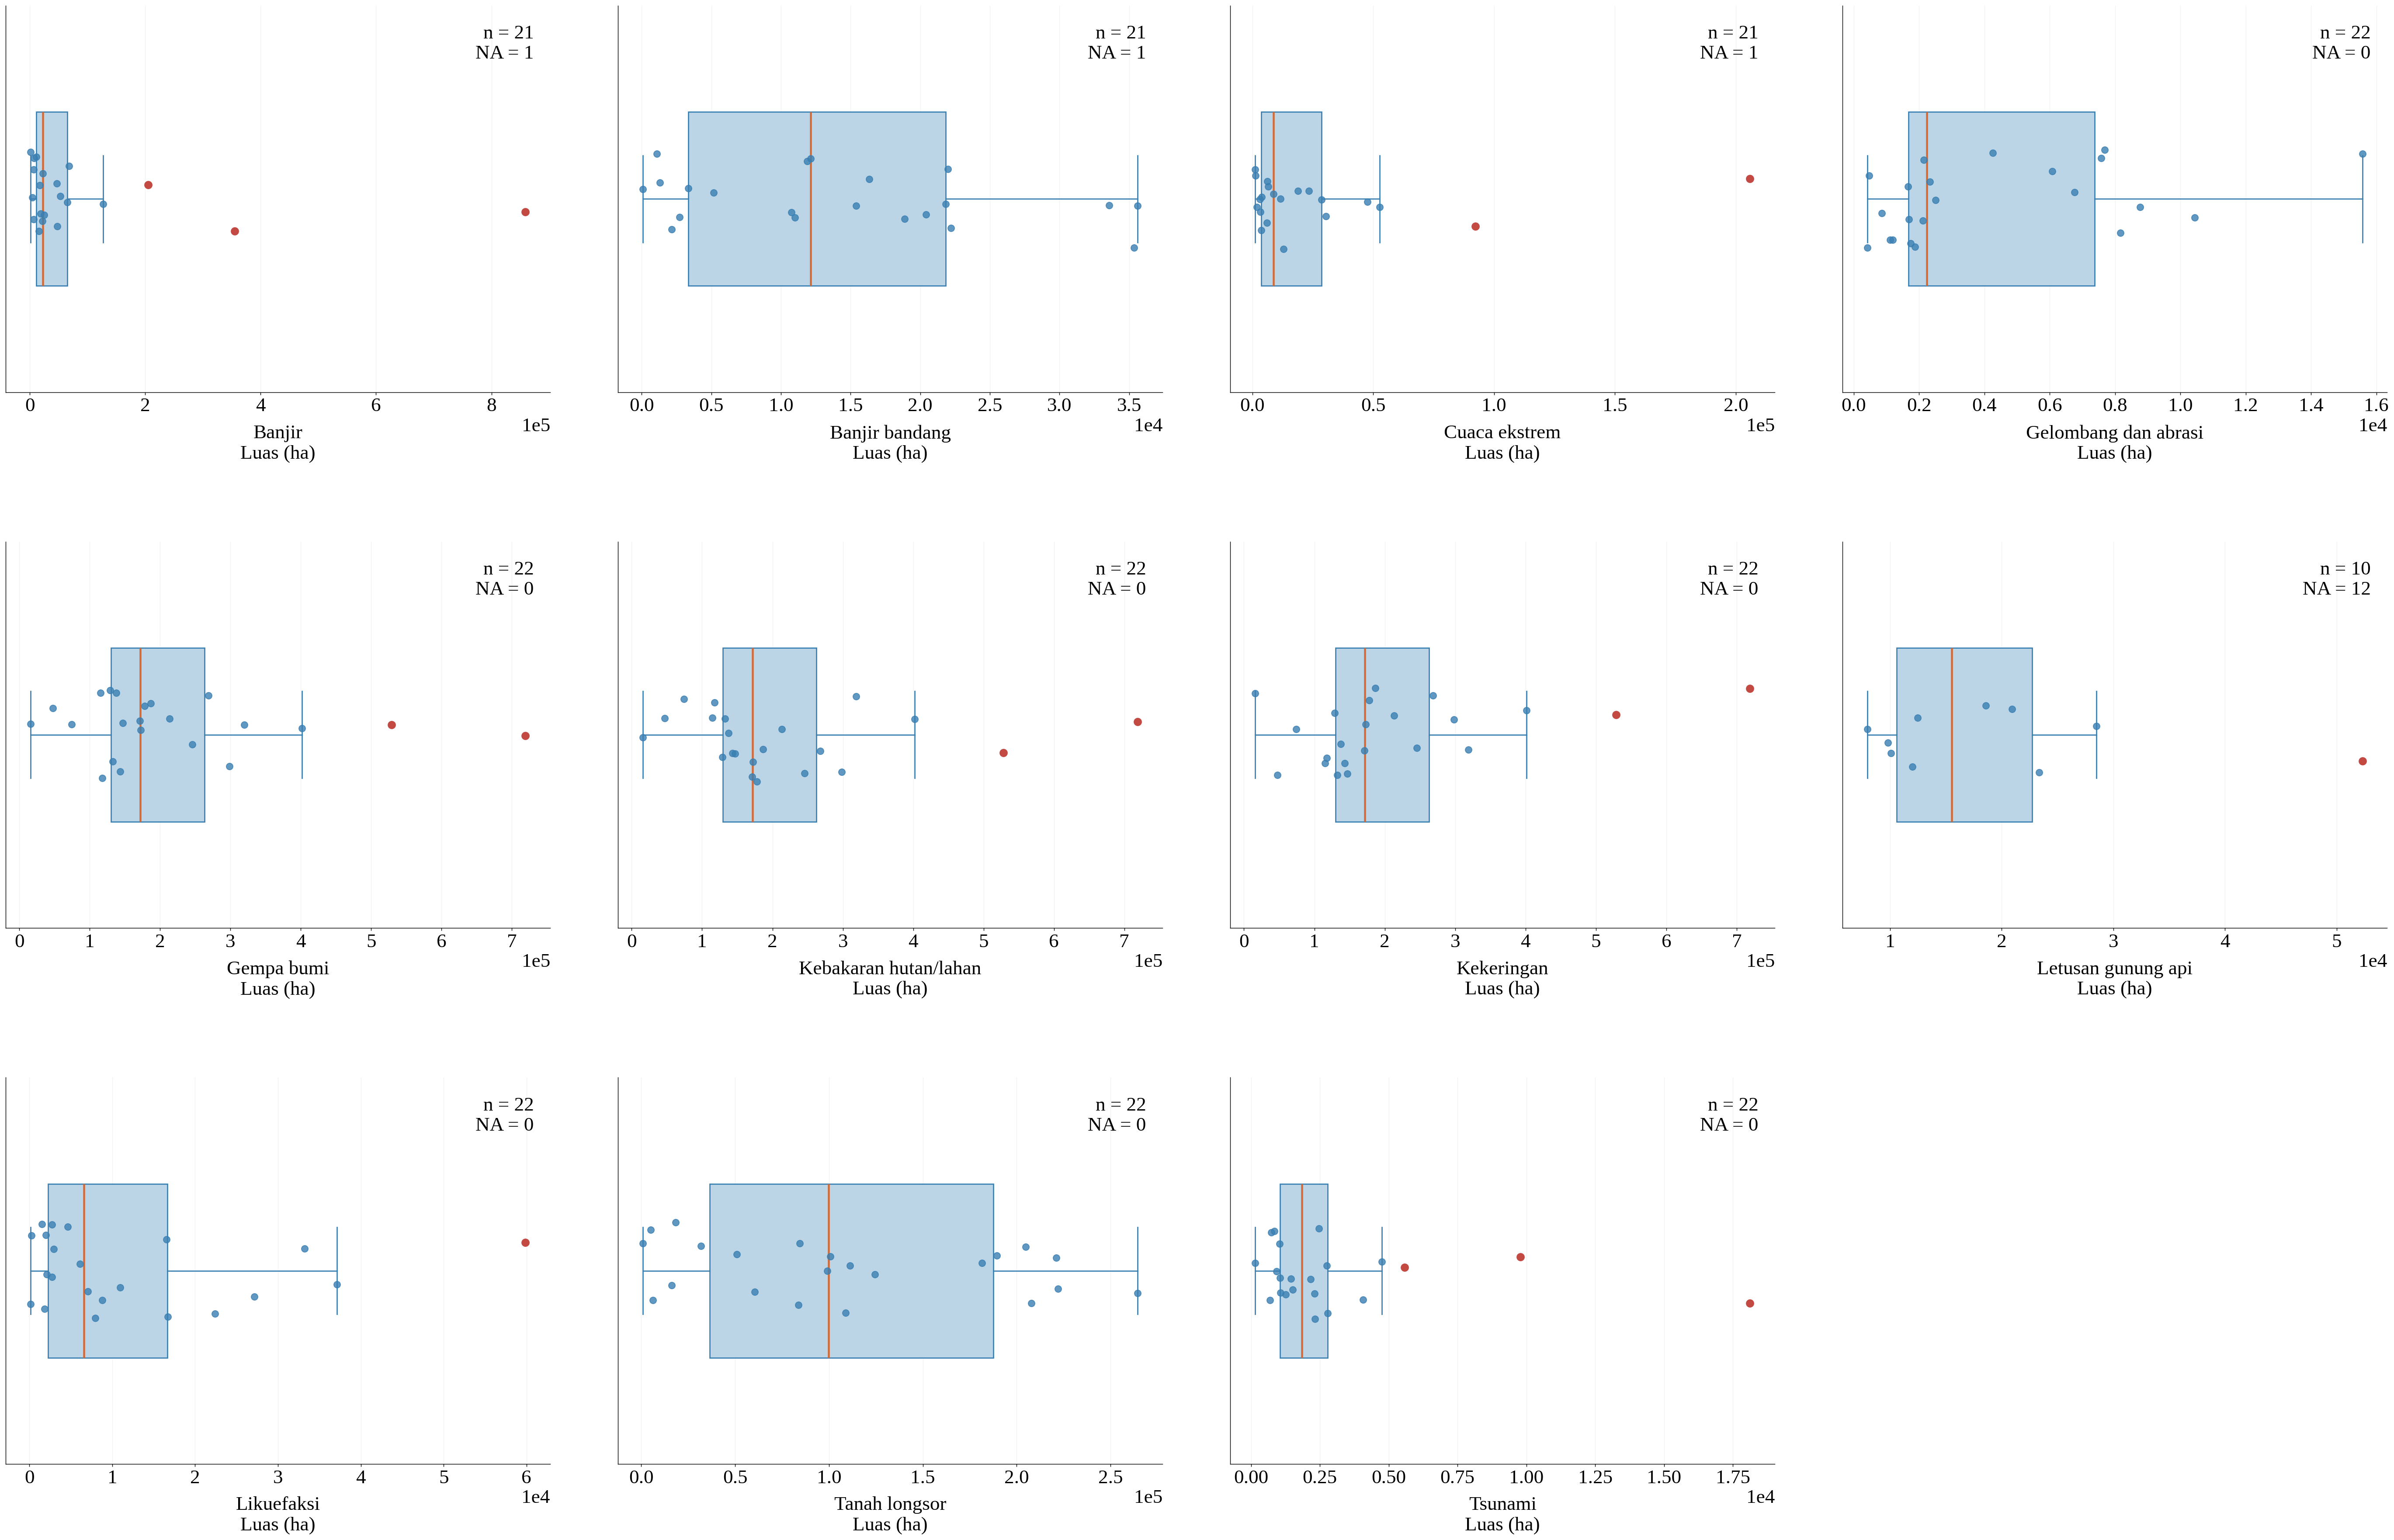

Titik merah = nilai ekstrem berdasarkan aturan 1,5 × IQR.
Seluruh nilai asli tetap dipertahankan.


In [24]:

# ============================================================
# D.2.2 — BOXPLOT LUAS TOTAL KRB
# 11 jenis bahaya | Font 25 pt
# ============================================================

rng = np.random.default_rng(2026)

fig, axes = plt.subplots(
    3, 4,
    figsize=(44, 29)
)

axes = axes.ravel()

for i, jenis in enumerate(jenis_krb):

    ax = axes[i]

    kol = f"krb_{jenis}_total_ha"
    s = angka_audit_a[kol].dropna()

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    if iqr > 0:
        ekstrem = (
            (s < q1 - 1.5 * iqr)
            | (s > q3 + 1.5 * iqr)
        )
    else:
        ekstrem = pd.Series(
            False,
            index=s.index
        )

    ax.boxplot(
        s.values,
        vert=False,
        positions=[1],
        widths=0.45,
        patch_artist=True,
        showfliers=False,
        boxprops={
            "facecolor": "#BBD5E7",
            "edgecolor": "#397FB2",
            "linewidth": 1.5
        },
        medianprops={
            "color": "#D36B38",
            "linewidth": 2.5
        },
        whiskerprops={
            "color": "#397FB2",
            "linewidth": 1.5
        },
        capprops={
            "color": "#397FB2",
            "linewidth": 1.5
        }
    )

    posisi_y = (
        1 + rng.uniform(
            -0.13, 0.13,
            size=len(s)
        )
    )

    ax.scatter(
        s.values[~ekstrem.values],
        posisi_y[~ekstrem.values],
        s=70,
        color="#397FB2",
        alpha=0.80,
        zorder=3
    )

    ax.scatter(
        s.values[ekstrem.values],
        posisi_y[ekstrem.values],
        s=130,
        color="#C34A43",
        edgecolor="white",
        linewidth=1,
        zorder=4
    )

    ax.set_xlabel(
        f"{label_krb[jenis]}\nLuas (ha)",
        fontsize=25,
        labelpad=12
    )

    ax.set_yticks([])

    ax.text(
        0.97, 0.95,
        f"n = {len(s)}\nNA = {22-len(s)}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=25
    )

    ax.tick_params(
        axis="x",
        labelsize=25
    )

    ax.ticklabel_format(
        axis="x",
        style="sci",
        scilimits=(-3, 4)
    )

    ax.xaxis.get_offset_text().set_fontsize(25)

    ax.grid(axis="x", alpha=0.16)
    ax.set_axisbelow(True)

for ax in axes[len(jenis_krb):]:
    ax.axis("off")

fig.tight_layout(
    pad=3.0,
    w_pad=3.0,
    h_pad=4.0
)

plt.show()

print(
    "Titik merah = nilai ekstrem berdasarkan "
    "aturan 1,5 × IQR."
)
print("Seluruh nilai asli tetap dipertahankan.")


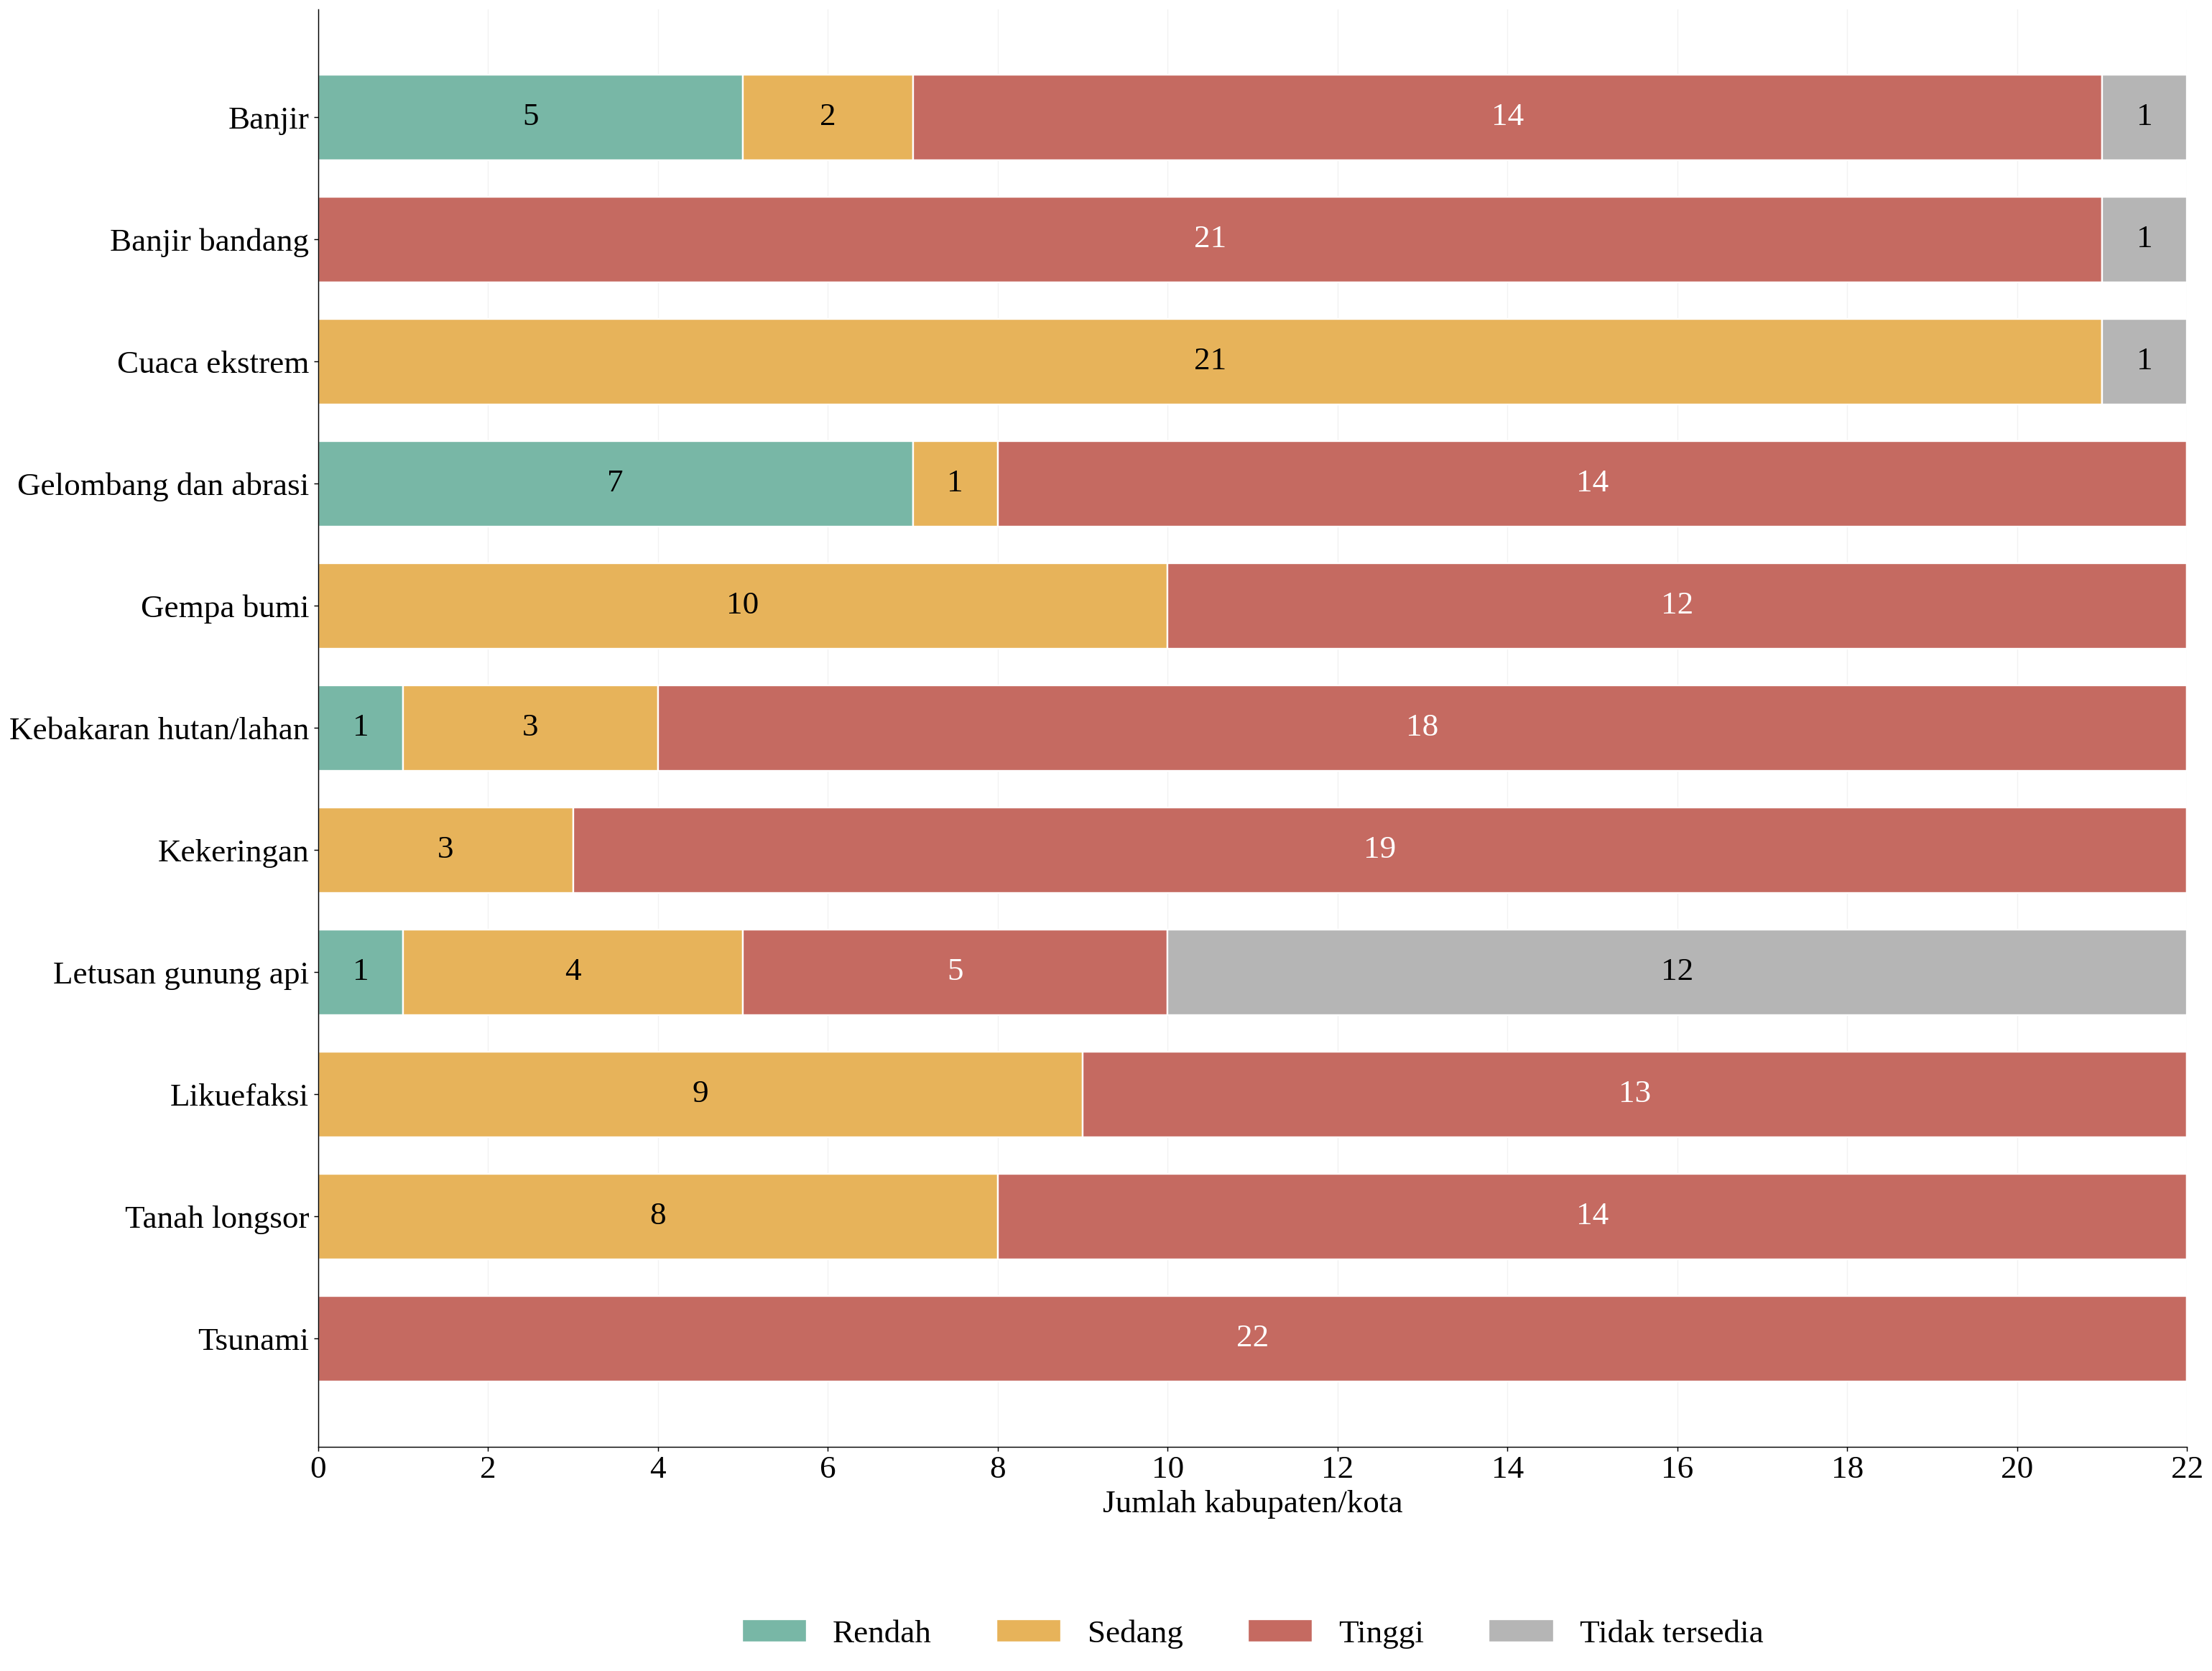

VALIDASI DISTRIBUSI KELAS
Seluruh baris berjumlah 22 wilayah: True
Total kelas tidak tersedia: 15


In [25]:

# ============================================================
# D.2.3 — DISTRIBUSI KELAS BAHAYA KRB
# Batang horizontal bertumpuk
# ============================================================

kategori_kelas = [
    "Rendah",
    "Sedang",
    "Tinggi",
    "Tidak tersedia"
]

warna_kelas = {
    "Rendah": "#78B7A6",
    "Sedang": "#E7B35A",
    "Tinggi": "#C56A61",
    "Tidak tersedia": "#B5B5B5"
}

data_kelas = kelas_krb_b.loc[
    [
        f"krb_{jenis}_kelas"
        for jenis in jenis_krb
    ],
    kategori_kelas
].copy()

nama_bahaya = [
    label_krb[jenis]
    for jenis in jenis_krb
]

fig, ax = plt.subplots(
    figsize=(29, 19)
)

posisi = np.arange(len(jenis_krb))
kiri = np.zeros(len(jenis_krb))

for kategori in kategori_kelas:

    nilai = data_kelas[
        kategori
    ].to_numpy()

    batang = ax.barh(
        posisi,
        nilai,
        left=kiri,
        height=0.70,
        label=kategori,
        color=warna_kelas[kategori],
        edgecolor="white",
        linewidth=1.3
    )

    for i, angka in enumerate(nilai):

        if angka > 0:

            ax.text(
                kiri[i] + angka / 2,
                posisi[i],
                str(int(angka)),
                ha="center",
                va="center",
                fontsize=25,
                color=(
                    "white"
                    if kategori == "Tinggi"
                    else "black"
                )
            )

    kiri += nilai

ax.set_yticks(posisi)
ax.set_yticklabels(
    nama_bahaya,
    fontsize=25
)

ax.invert_yaxis()
ax.set_xlim(0, 22)

ax.set_xticks(
    np.arange(0, 23, 2)
)

ax.set_xlabel(
    "Jumlah kabupaten/kota",
    fontsize=25
)

ax.tick_params(
    axis="both",
    labelsize=25
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=4,
    frameon=False,
    fontsize=25
)

ax.grid(axis="x", alpha=0.16)
ax.set_axisbelow(True)

fig.subplots_adjust(
    left=0.29,
    right=0.98,
    top=0.98,
    bottom=0.17
)

plt.show()

print("VALIDASI DISTRIBUSI KELAS")
print(
    "Seluruh baris berjumlah 22 wilayah:",
    bool(data_kelas.sum(axis=1).eq(22).all())
)
print(
    "Total kelas tidak tersedia:",
    int(data_kelas["Tidak tersedia"].sum())
)


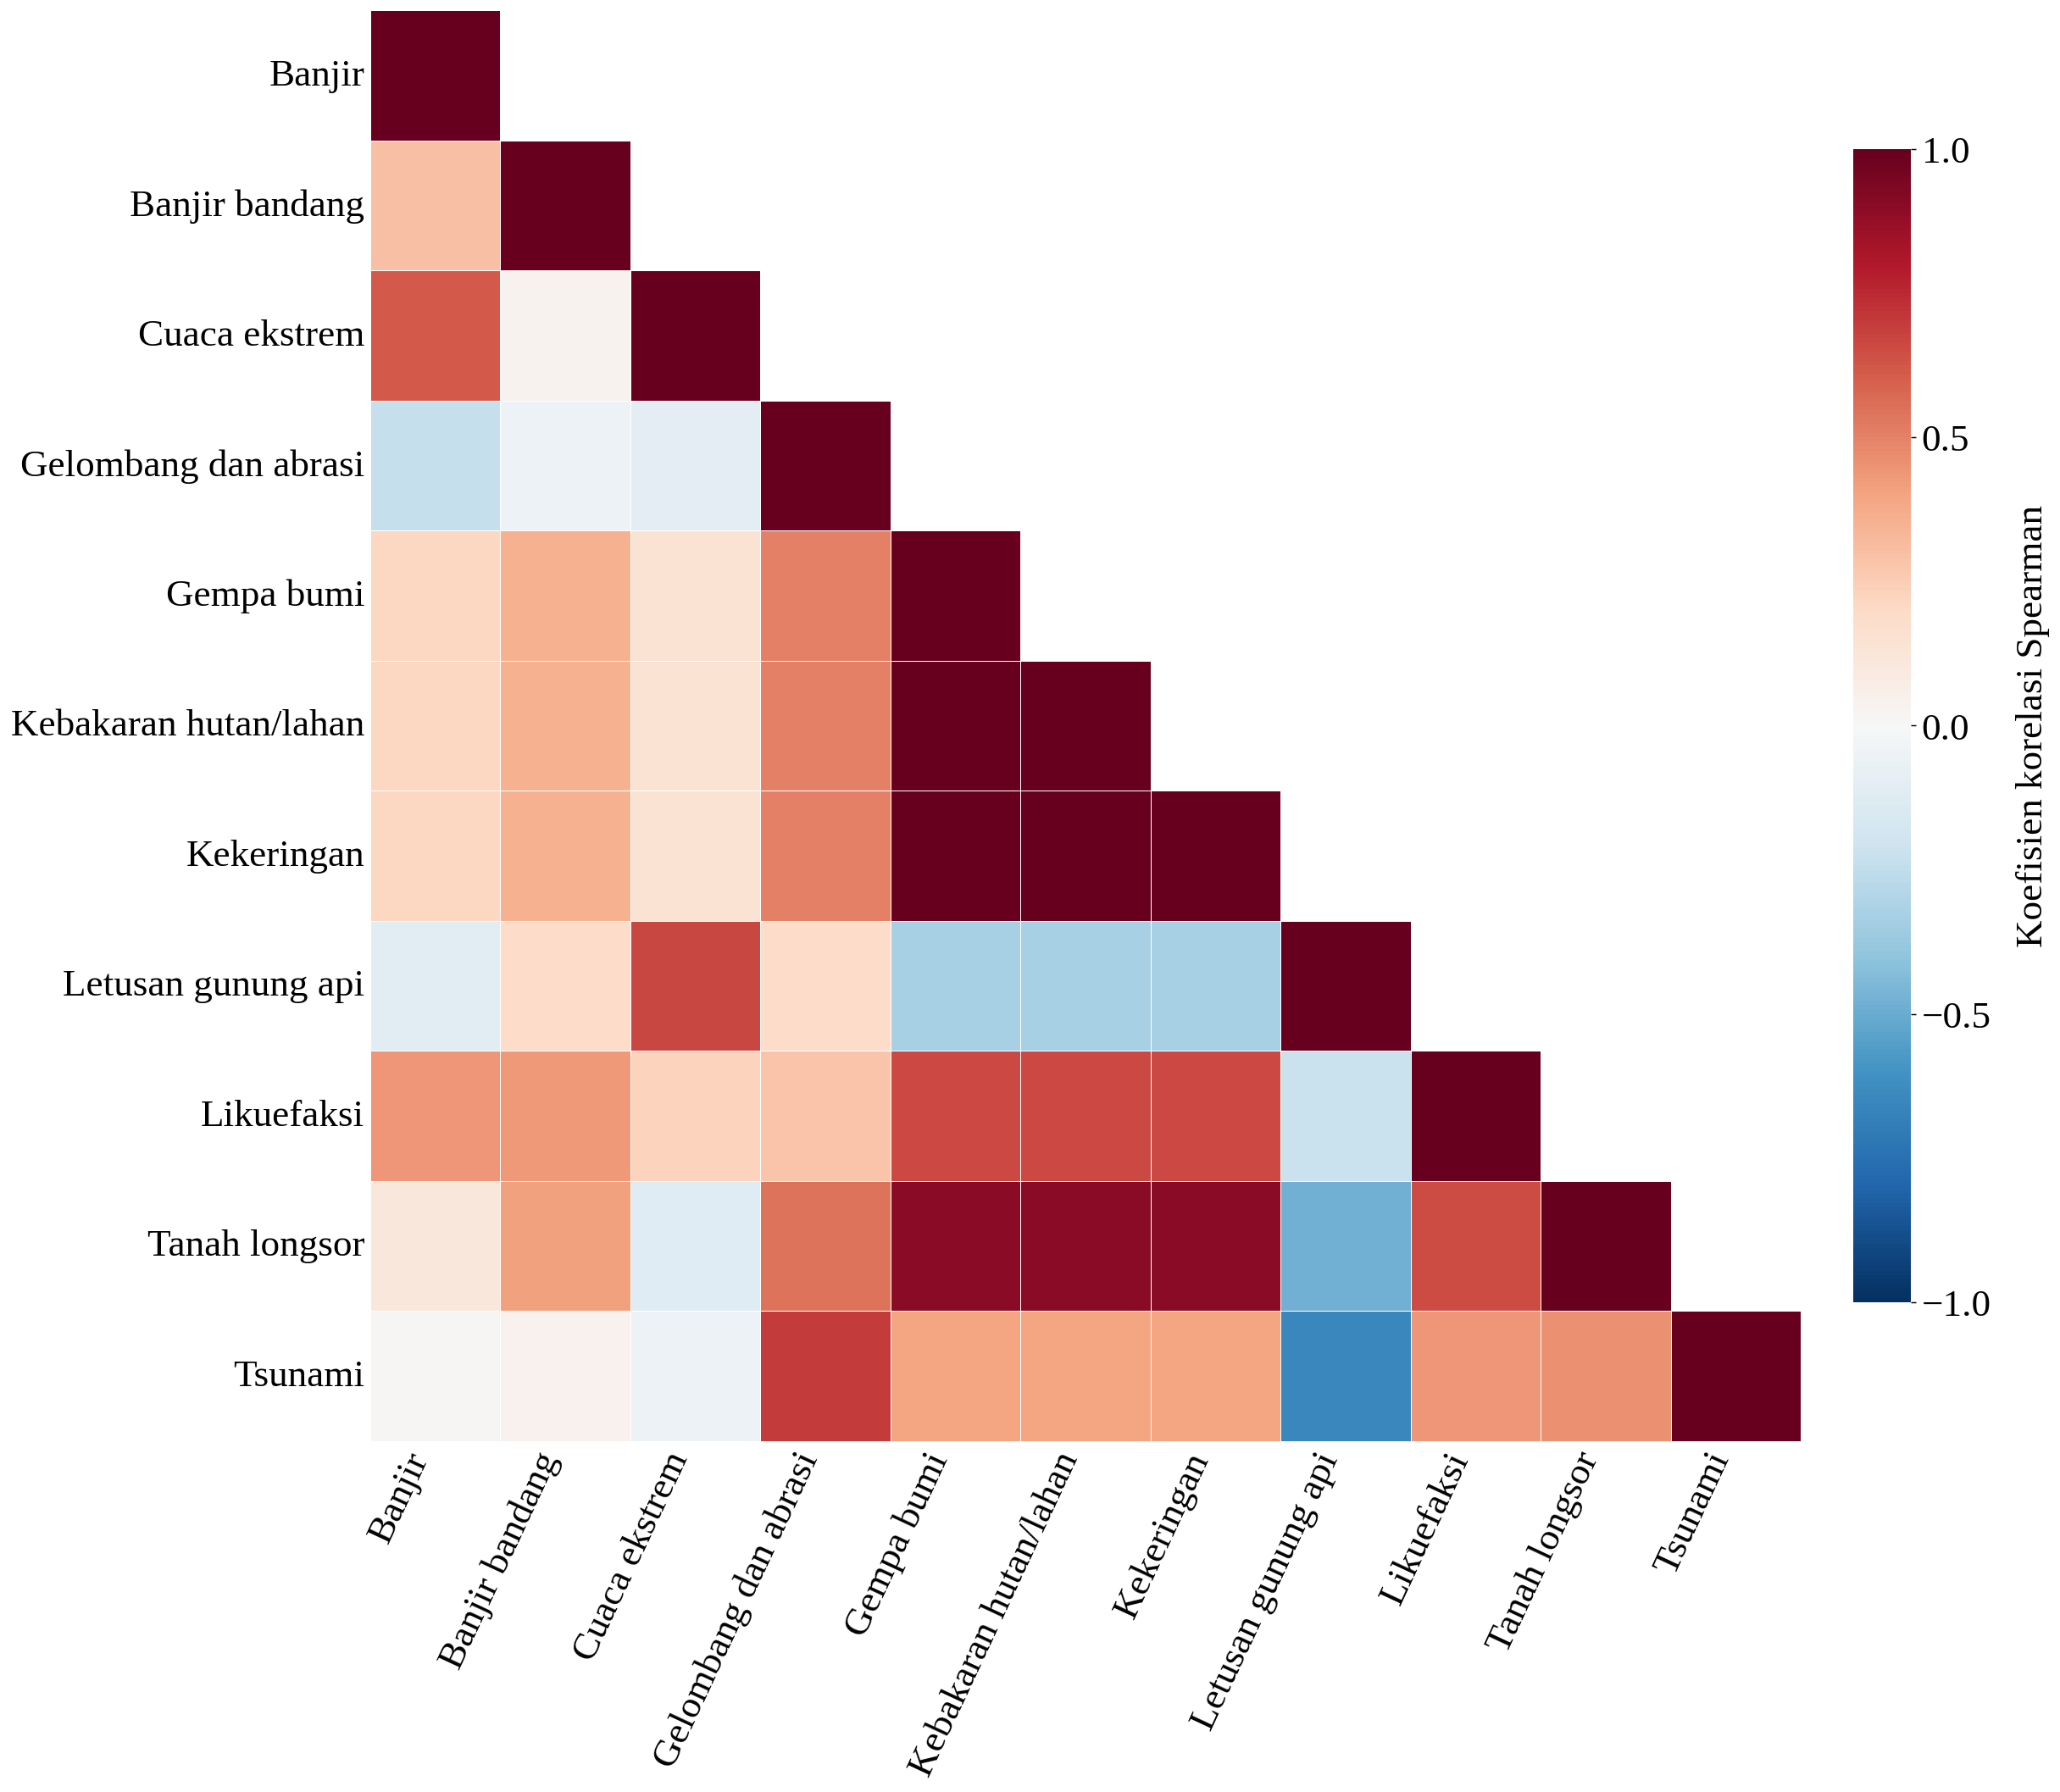

Jumlah peubah: 11
Metode: Spearman
Minimum observasi berpasangan: 8
Interpretasi dan seleksi fitur ditunda.


In [26]:

# ============================================================
# D.2.4 — HEATMAP SPEARMAN LUAS TOTAL KRB
# 11 peubah numerik, font 25 pt
# ============================================================

# Minimum delapan observasi bersama untuk satu pasangan
korelasi_total_krb = krb_total_d2.corr(
    method="spearman",
    min_periods=8
)

# Mask segitiga atas
mask = np.triu(
    np.ones_like(
        korelasi_total_krb,
        dtype=bool
    ),
    k=1
)

labels = [
    label_krb[jenis]
    for jenis in jenis_krb
]

fig, ax = plt.subplots(
    figsize=(24, 22)
)

sns.heatmap(
    korelasi_total_krb,
    mask=mask,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    annot=False,
    linewidths=0.5,
    linecolor="white",
    xticklabels=labels,
    yticklabels=labels,
    cbar_kws={
        "shrink": 0.70,
        "pad": 0.03,
        "ticks": [-1, -0.5, 0, 0.5, 1]
    },
    ax=ax
)

ax.set_xticklabels(
    labels,
    rotation=65,
    ha="right",
    fontsize=25
)

ax.set_yticklabels(
    labels,
    rotation=0,
    fontsize=25
)

ax.set_xlabel("")
ax.set_ylabel("")

ax.tick_params(
    axis="both",
    length=0
)

cbar = ax.collections[0].colorbar

cbar.ax.tick_params(
    labelsize=25
)

cbar.set_label(
    "Koefisien korelasi Spearman",
    fontsize=25,
    labelpad=16
)

fig.subplots_adjust(
    left=0.28,
    bottom=0.30,
    right=0.94,
    top=0.98
)

plt.show()

print("Jumlah peubah:", korelasi_total_krb.shape[0])
print("Metode: Spearman")
print("Minimum observasi berpasangan: 8")
print("Interpretasi dan seleksi fitur ditunda.")


### Komposisi Luas Bahaya menurut Tingkat Rendah, Sedang, dan Tinggi

A. KOMPOSISI LUAS MENURUT JENIS BAHAYA


,jenis_bahaya,n_valid,n_missing,luas_total_ha,rendah_persen,sedang_persen,tinggi_persen
0,banjir,21,1,1985197.0,57.30,29.20,13.51
1,banjir_bandang,21,1,303234.0,1.17,5.90,92.93
2,cuaca_ekstrem,21,1,570248.0,0.64,99.35,0.01
3,gelombang_abrasi,22,0,95397.0,56.60,10.65,32.75
4,gempa_bumi,22,0,4764699.0,59.25,36.49,4.26
5,karhutla,22,0,4759591.0,51.49,34.71,13.80
6,kekeringan,22,0,4761414.0,0.00,46.10,53.90
7,letusan_gunung_api,10,12,195902.0,74.38,15.35,10.26
8,likuefaksi,22,0,274667.0,2.10,90.48,7.42
9,tanah_longsor,22,0,2393479.0,29.94,61.88,8.19


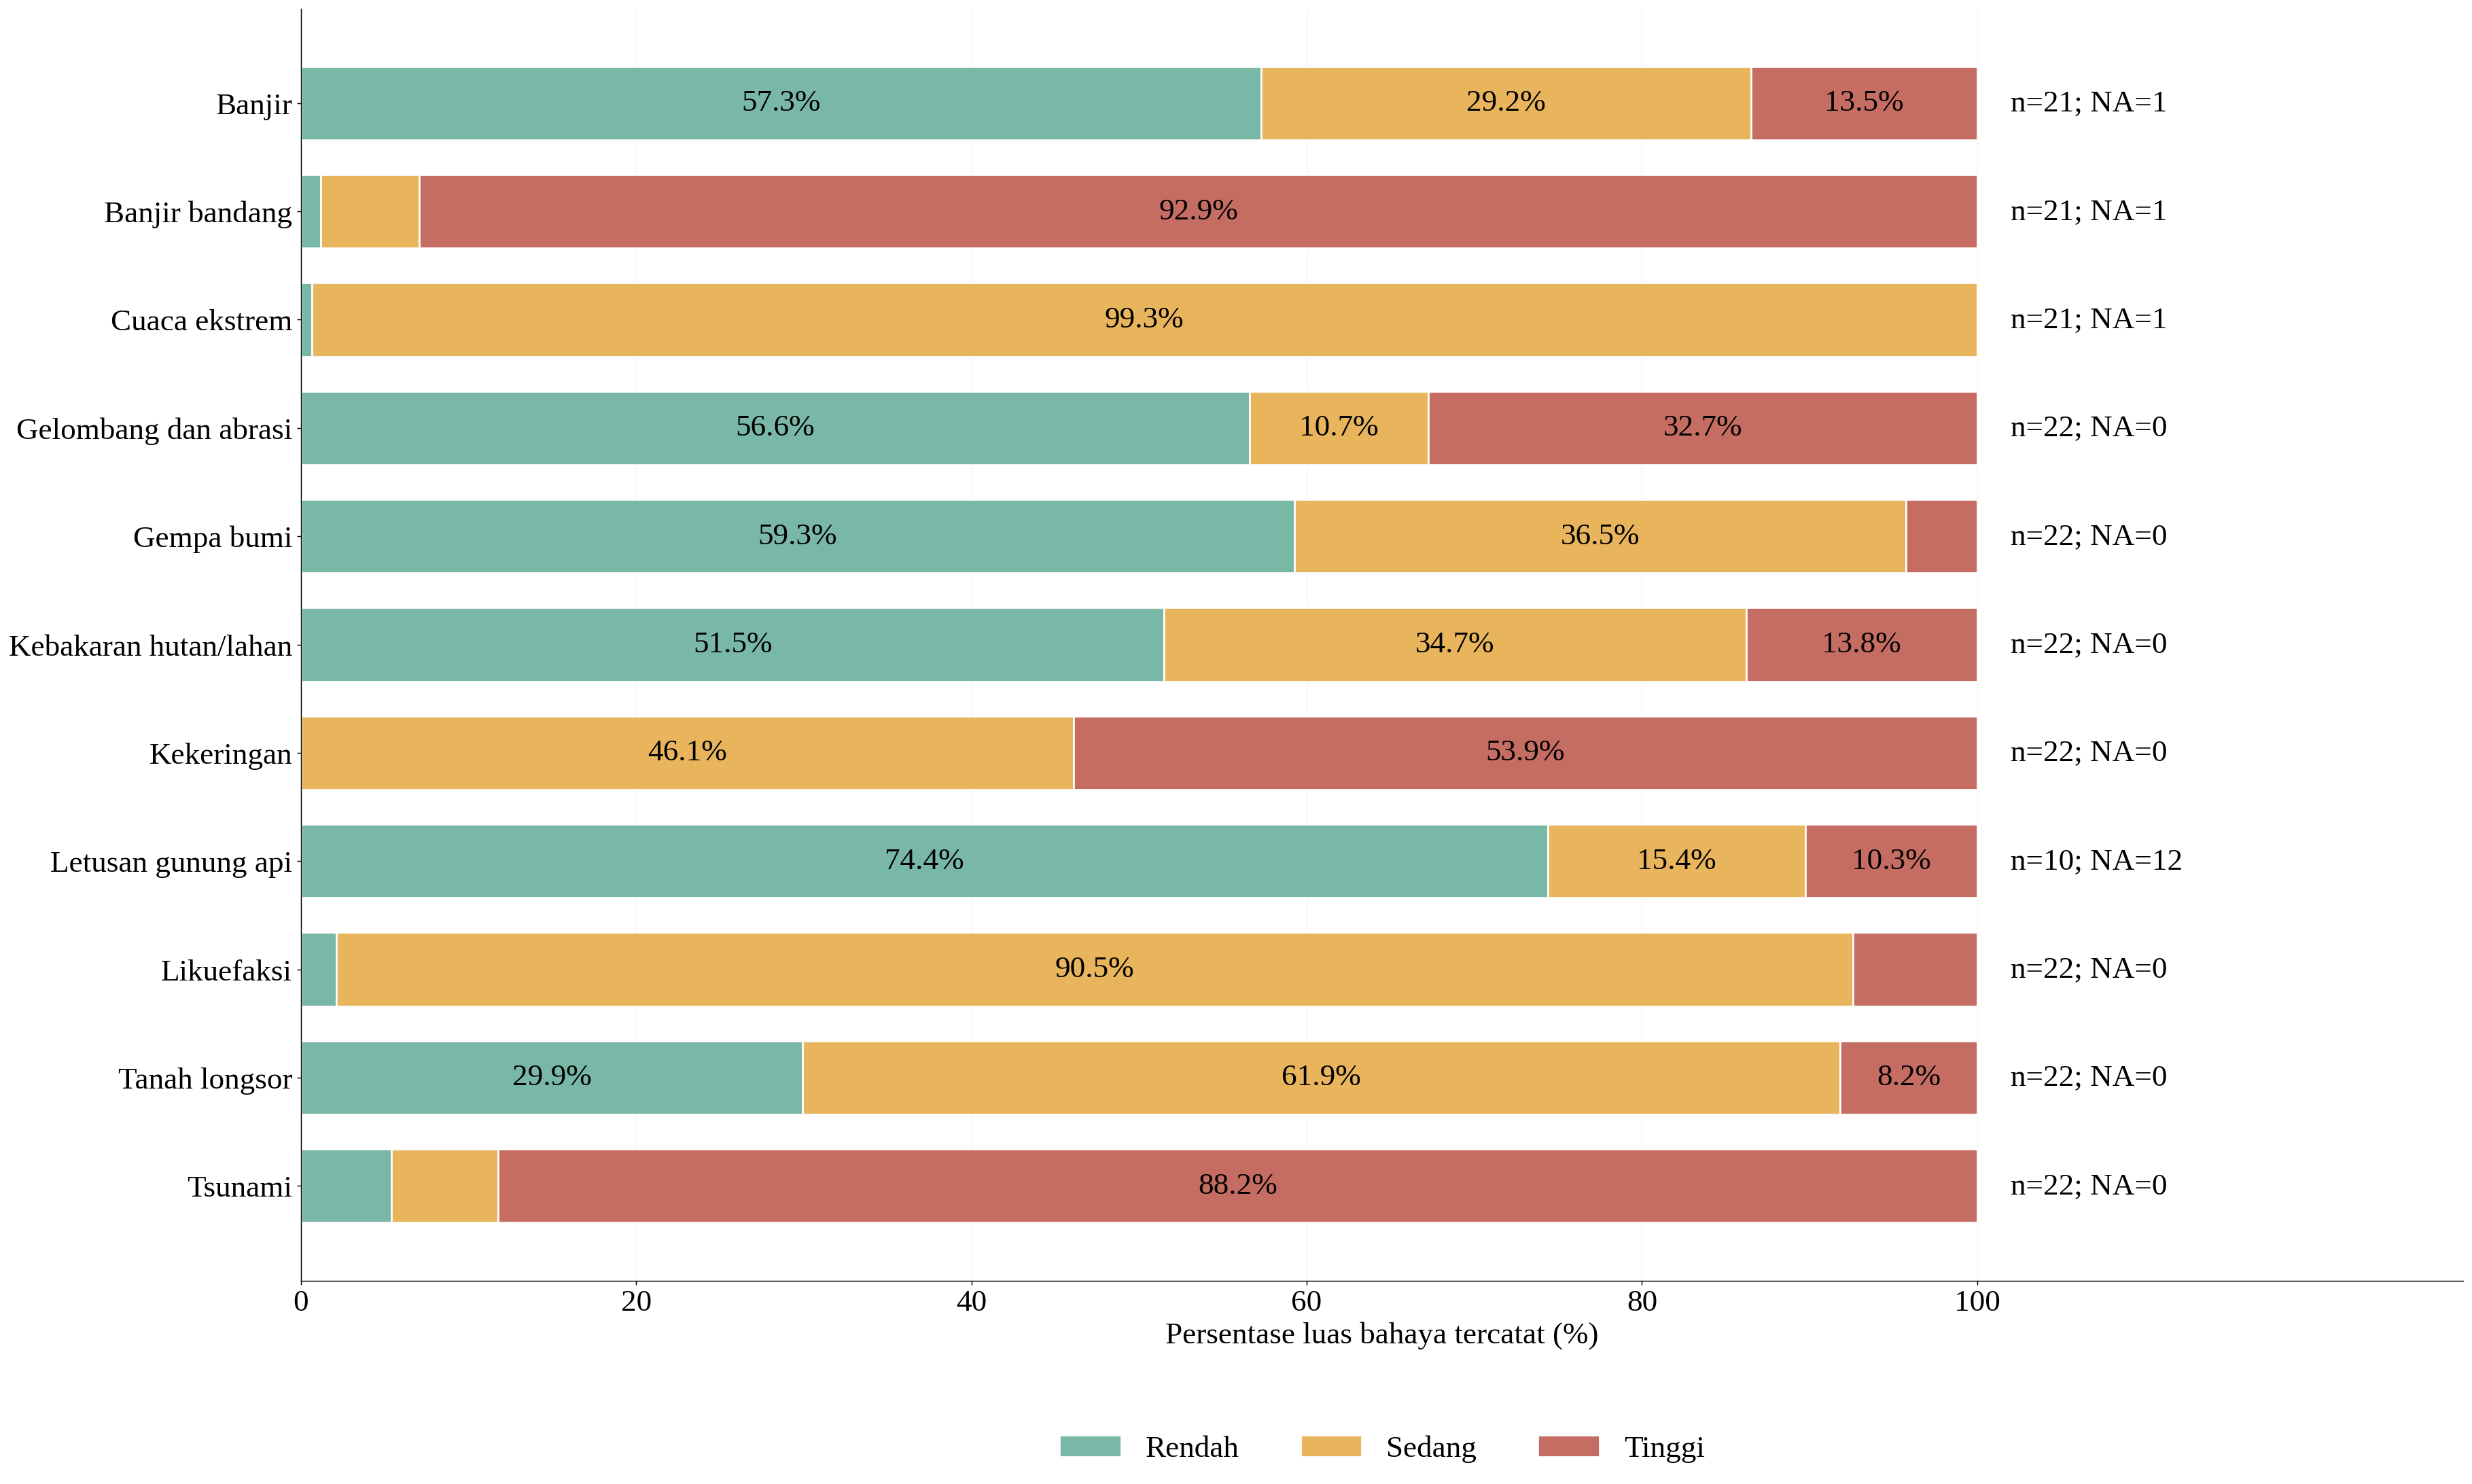

Komposisi dihitung dari luas kelas KRB.
Wilayah tanpa data tidak diberi nilai nol.
Data mentah tidak dimodifikasi.


In [27]:

# ============================================================
# D.2.5 — KOMPOSISI LUAS KELAS BAHAYA KRB
# Liberation Serif | Font 25 | Tanpa judul
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

tingkat_krb = ["rendah", "sedang", "tinggi"]

warna_krb = {
    "rendah": "#79B7A6",
    "sedang": "#E9B55C",
    "tinggi": "#C56D63"
}

hasil_komposisi = []

for jenis in jenis_krb:

    cols = [
        f"krb_{jenis}_{k}_ha"
        for k in tingkat_krb
    ]

    kol_total = f"krb_{jenis}_total_ha"

    data = angka_audit_a[
        cols + [kol_total]
    ].dropna()

    total_ha = data[kol_total].sum()

    baris = {
        "jenis_bahaya": jenis,
        "n_valid": len(data),
        "n_missing": 22 - len(data),
        "luas_total_ha": total_ha
    }

    for tingkat, kol in zip(tingkat_krb, cols):

        luas_kelas = data[kol].sum()

        baris[f"{tingkat}_ha"] = luas_kelas

        baris[f"{tingkat}_persen"] = (
            luas_kelas / total_ha * 100
            if total_ha > 0 else np.nan
        )

    hasil_komposisi.append(baris)

komposisi_krb_d25 = pd.DataFrame(
    hasil_komposisi
)

# ------------------------------------------------------------
# A. Validasi total komposisi
# ------------------------------------------------------------

kolom_persen = [
    f"{k}_persen"
    for k in tingkat_krb
]

jumlah_persen = komposisi_krb_d25[
    kolom_persen
].sum(axis=1)

assert np.allclose(
    jumlah_persen,
    100,
    rtol=0,
    atol=0.01
)

print("A. KOMPOSISI LUAS MENURUT JENIS BAHAYA")

display(
    komposisi_krb_d25[
        [
            "jenis_bahaya",
            "n_valid",
            "n_missing",
            "luas_total_ha",
            "rendah_persen",
            "sedang_persen",
            "tinggi_persen"
        ]
    ].round(2)
)

# ------------------------------------------------------------
# B. Diagram batang horizontal bertumpuk
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(34, 18)
)

y = np.arange(len(jenis_krb))
kiri = np.zeros(len(jenis_krb))

for tingkat in tingkat_krb:

    nilai = komposisi_krb_d25[
        f"{tingkat}_persen"
    ].to_numpy()

    ax.barh(
        y,
        nilai,
        left=kiri,
        height=0.68,
        color=warna_krb[tingkat],
        edgecolor="white",
        linewidth=1.5,
        label=tingkat.capitalize()
    )

    for i, v in enumerate(nilai):

        # Hindari anotasi yang bertumpuk
        if v >= 8:

            ax.text(
                kiri[i] + v / 2,
                y[i],
                f"{v:.1f}%",
                ha="center",
                va="center",
                fontsize=25,
                color="black"
            )

    kiri += nilai

# Label jumlah wilayah tercakup
for i, r in komposisi_krb_d25.iterrows():

    ax.text(
        102,
        y[i],
        f"n={int(r['n_valid'])}; NA={int(r['n_missing'])}",
        ha="left",
        va="center",
        fontsize=25
    )

ax.set_yticks(y)

ax.set_yticklabels(
    [label_krb[j] for j in jenis_krb],
    fontsize=25
)

ax.invert_yaxis()
ax.set_xlim(0, 129)

ax.set_xticks(
    np.arange(0, 101, 20)
)

ax.set_xlabel(
    "Persentase luas bahaya tercatat (%)",
    fontsize=25
)

ax.tick_params(
    axis="both",
    labelsize=25
)

ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=3,
    frameon=False,
    fontsize=25
)

fig.subplots_adjust(
    left=0.26,
    right=0.98,
    top=0.98,
    bottom=0.18
)

plt.show()

print("Komposisi dihitung dari luas kelas KRB.")
print("Wilayah tanpa data tidak diberi nilai nol.")
print("Data mentah tidak dimodifikasi.")


### Heatmap Persentase Luas Bahaya Tinggi per Kabupaten/Kota

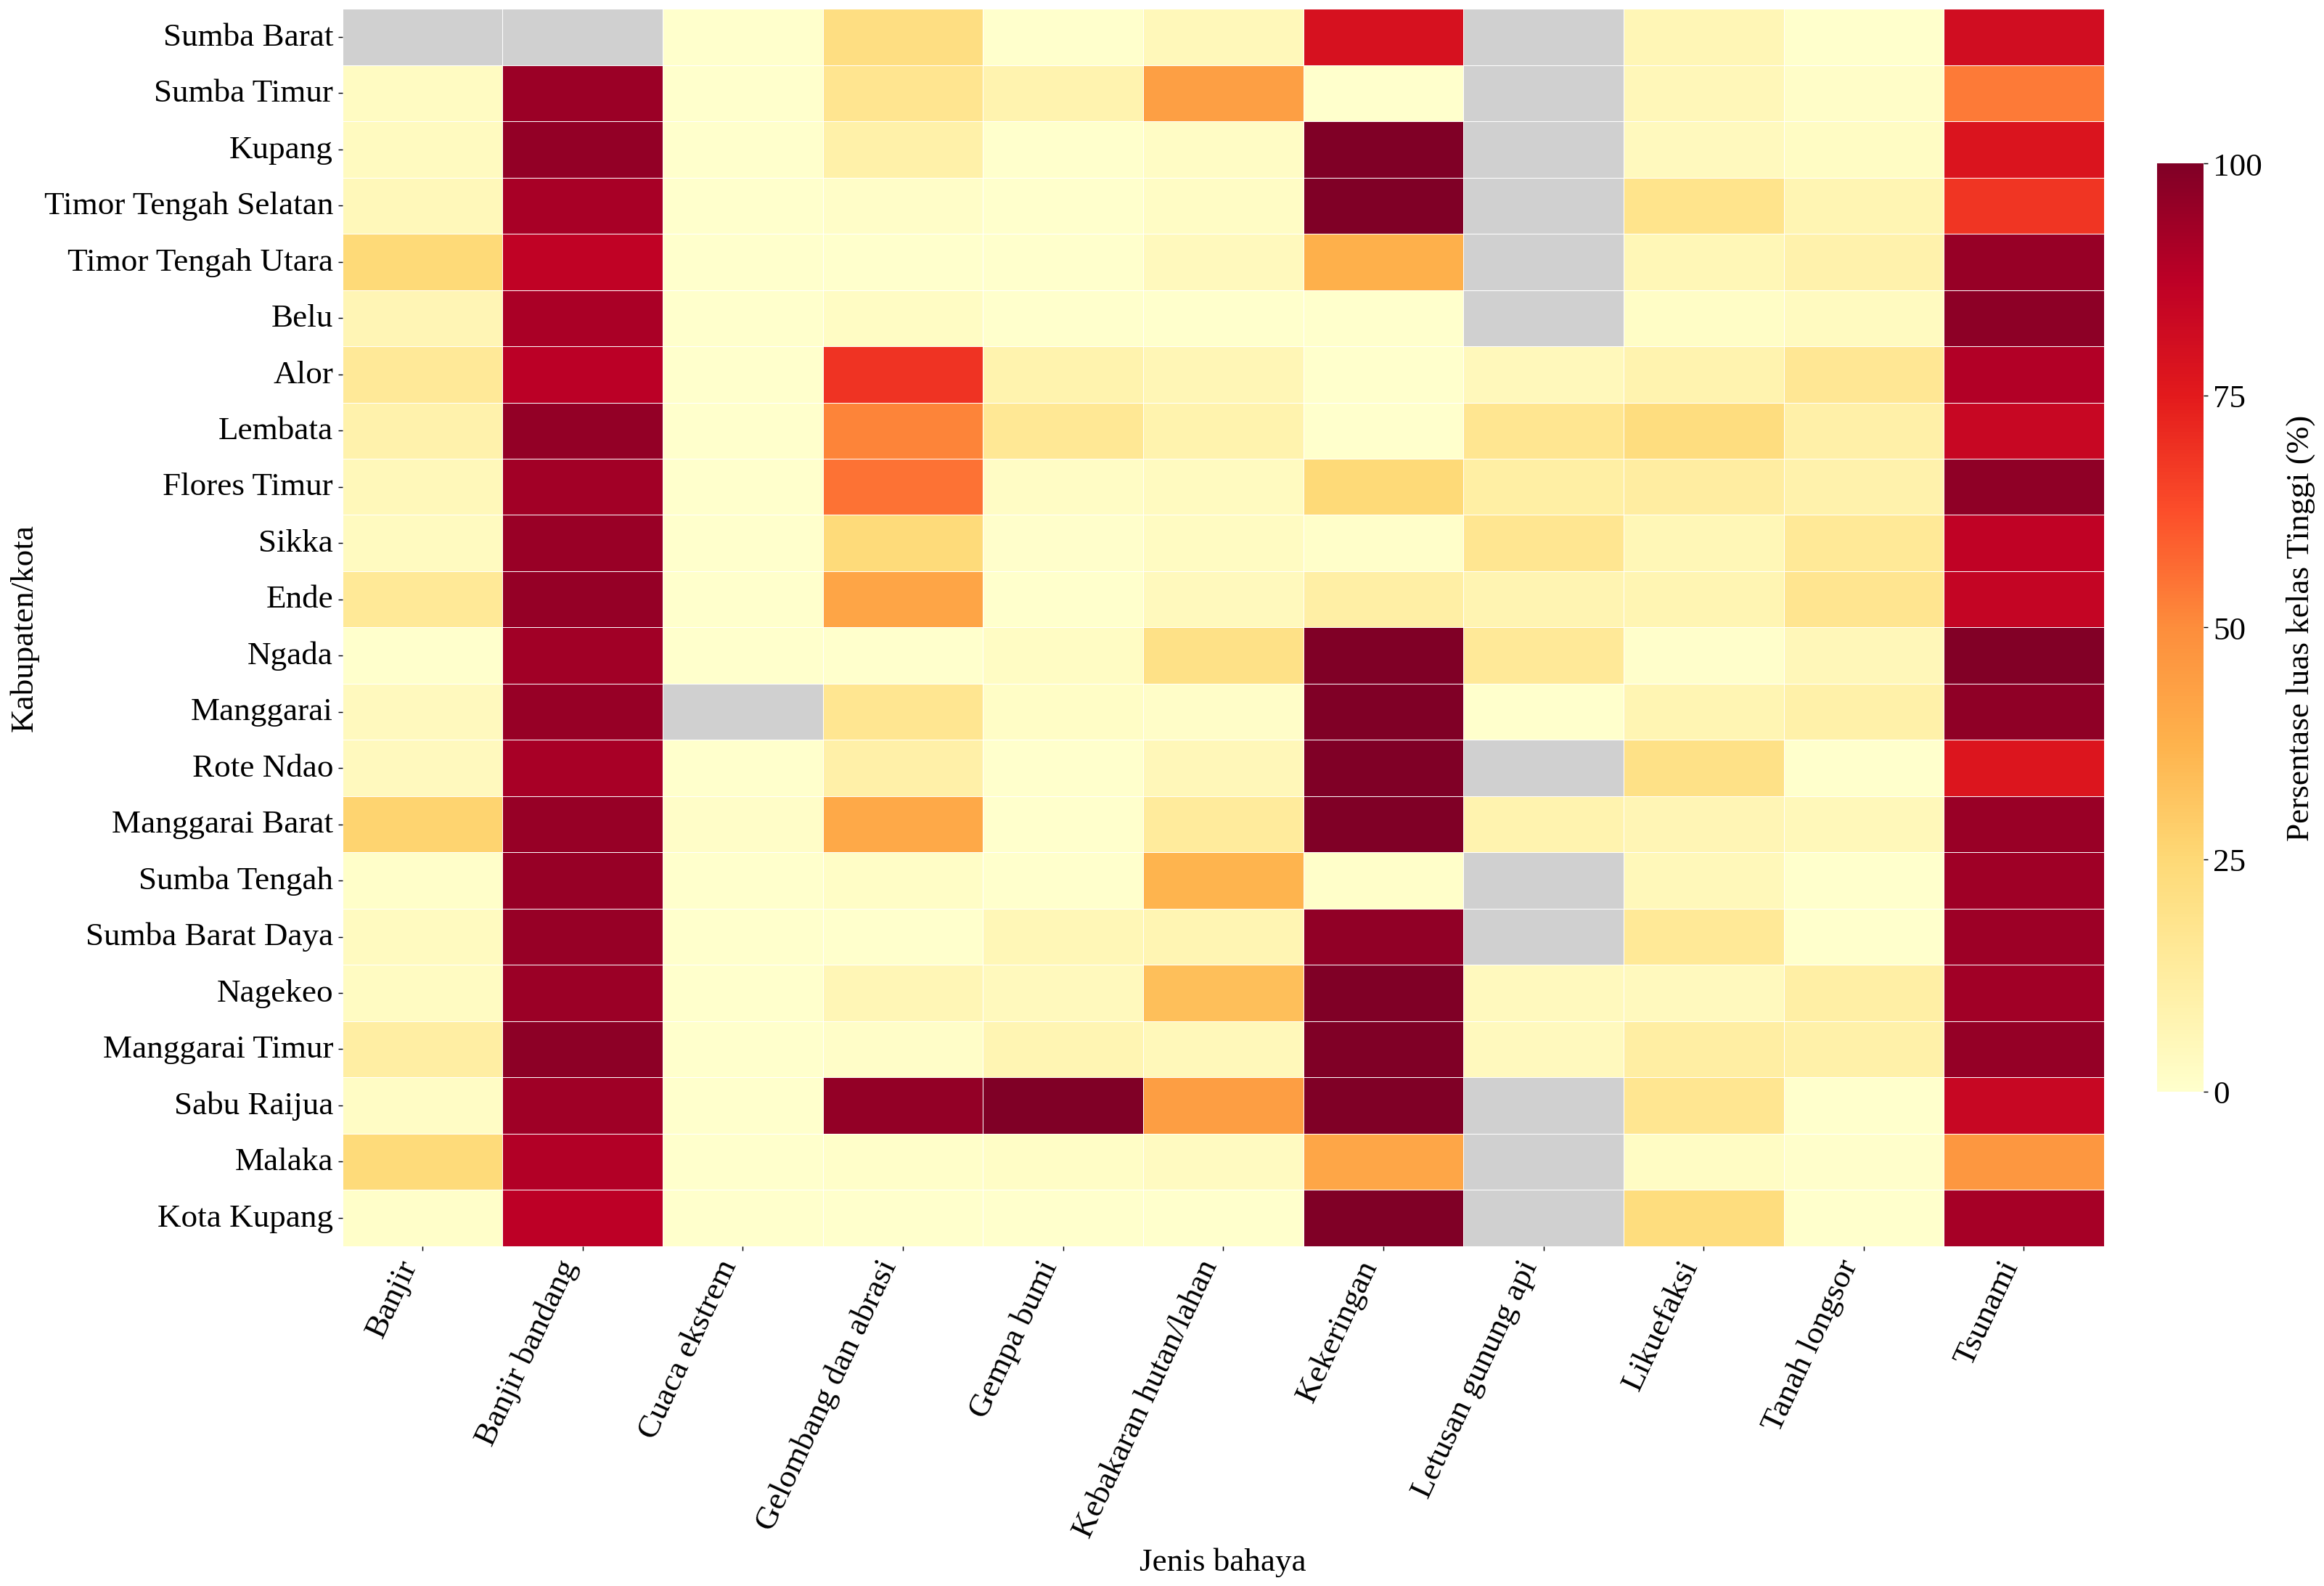

Rentang persentase: 0.0 sampai 100.0
Jumlah sel tidak terdefinisi / tidak tersedia: 15
Tidak ada pengisian missing dengan nol.


In [28]:

# ============================================================
# D.2.5B — HEATMAP PROPORSI LUAS BAHAYA TINGGI
# Kabupaten/kota x 11 jenis bahaya
# Liberation Serif | 25 pt | Tanpa judul
# ============================================================

import seaborn as sns

persen_tinggi_d25 = pd.DataFrame(
    index=df_raw["kabupaten_kota"].values
)

for jenis in jenis_krb:

    tinggi = angka_audit_a[
        f"krb_{jenis}_tinggi_ha"
    ]

    total = angka_audit_a[
        f"krb_{jenis}_total_ha"
    ]

    nilai = (
        tinggi.div(
            total.where(total.gt(0))
        ) * 100
    )

    persen_tinggi_d25[
        label_krb[jenis]
    ] = nilai.to_numpy()

# Tidak mengganti NaN dengan nol
cmap = plt.colormaps["YlOrRd"].copy()
cmap.set_bad("#D0D0D0")

fig, ax = plt.subplots(
    figsize=(31, 19)
)

sns.heatmap(
    persen_tinggi_d25,
    cmap=cmap,
    vmin=0,
    vmax=100,
    annot=False,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "shrink": 0.75,
        "pad": 0.025,
        "ticks": [0, 25, 50, 75, 100]
    },
    ax=ax
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=65,
    ha="right",
    fontsize=25
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
    fontsize=25
)

ax.set_xlabel("Jenis bahaya")
ax.set_ylabel("Kabupaten/kota")

cbar = ax.collections[0].colorbar

cbar.ax.tick_params(labelsize=25)
cbar.set_label(
    "Persentase luas kelas Tinggi (%)",
    fontsize=25,
    labelpad=18
)

fig.subplots_adjust(
    left=0.23,
    bottom=0.29,
    right=0.96,
    top=0.98
)

plt.show()

print("Rentang persentase:",
      persen_tinggi_d25.min().min(),
      "sampai",
      persen_tinggi_d25.max().max())

print(
    "Jumlah sel tidak terdefinisi / tidak tersedia:",
    int(persen_tinggi_d25.isna().sum().sum())
)

print("Tidak ada pengisian missing dengan nol.")


## Visualisasi Diagnostik BNPB

### Jumlah laporan menurut tahun: memeriksa variasi frekuensi laporan.

,tahun,total_laporan,wilayah_valid,wilayah_nol
0,2021,128,22,0
1,2022,46,22,7
2,2023,115,22,1
3,2024,54,22,3
4,2025,64,22,5


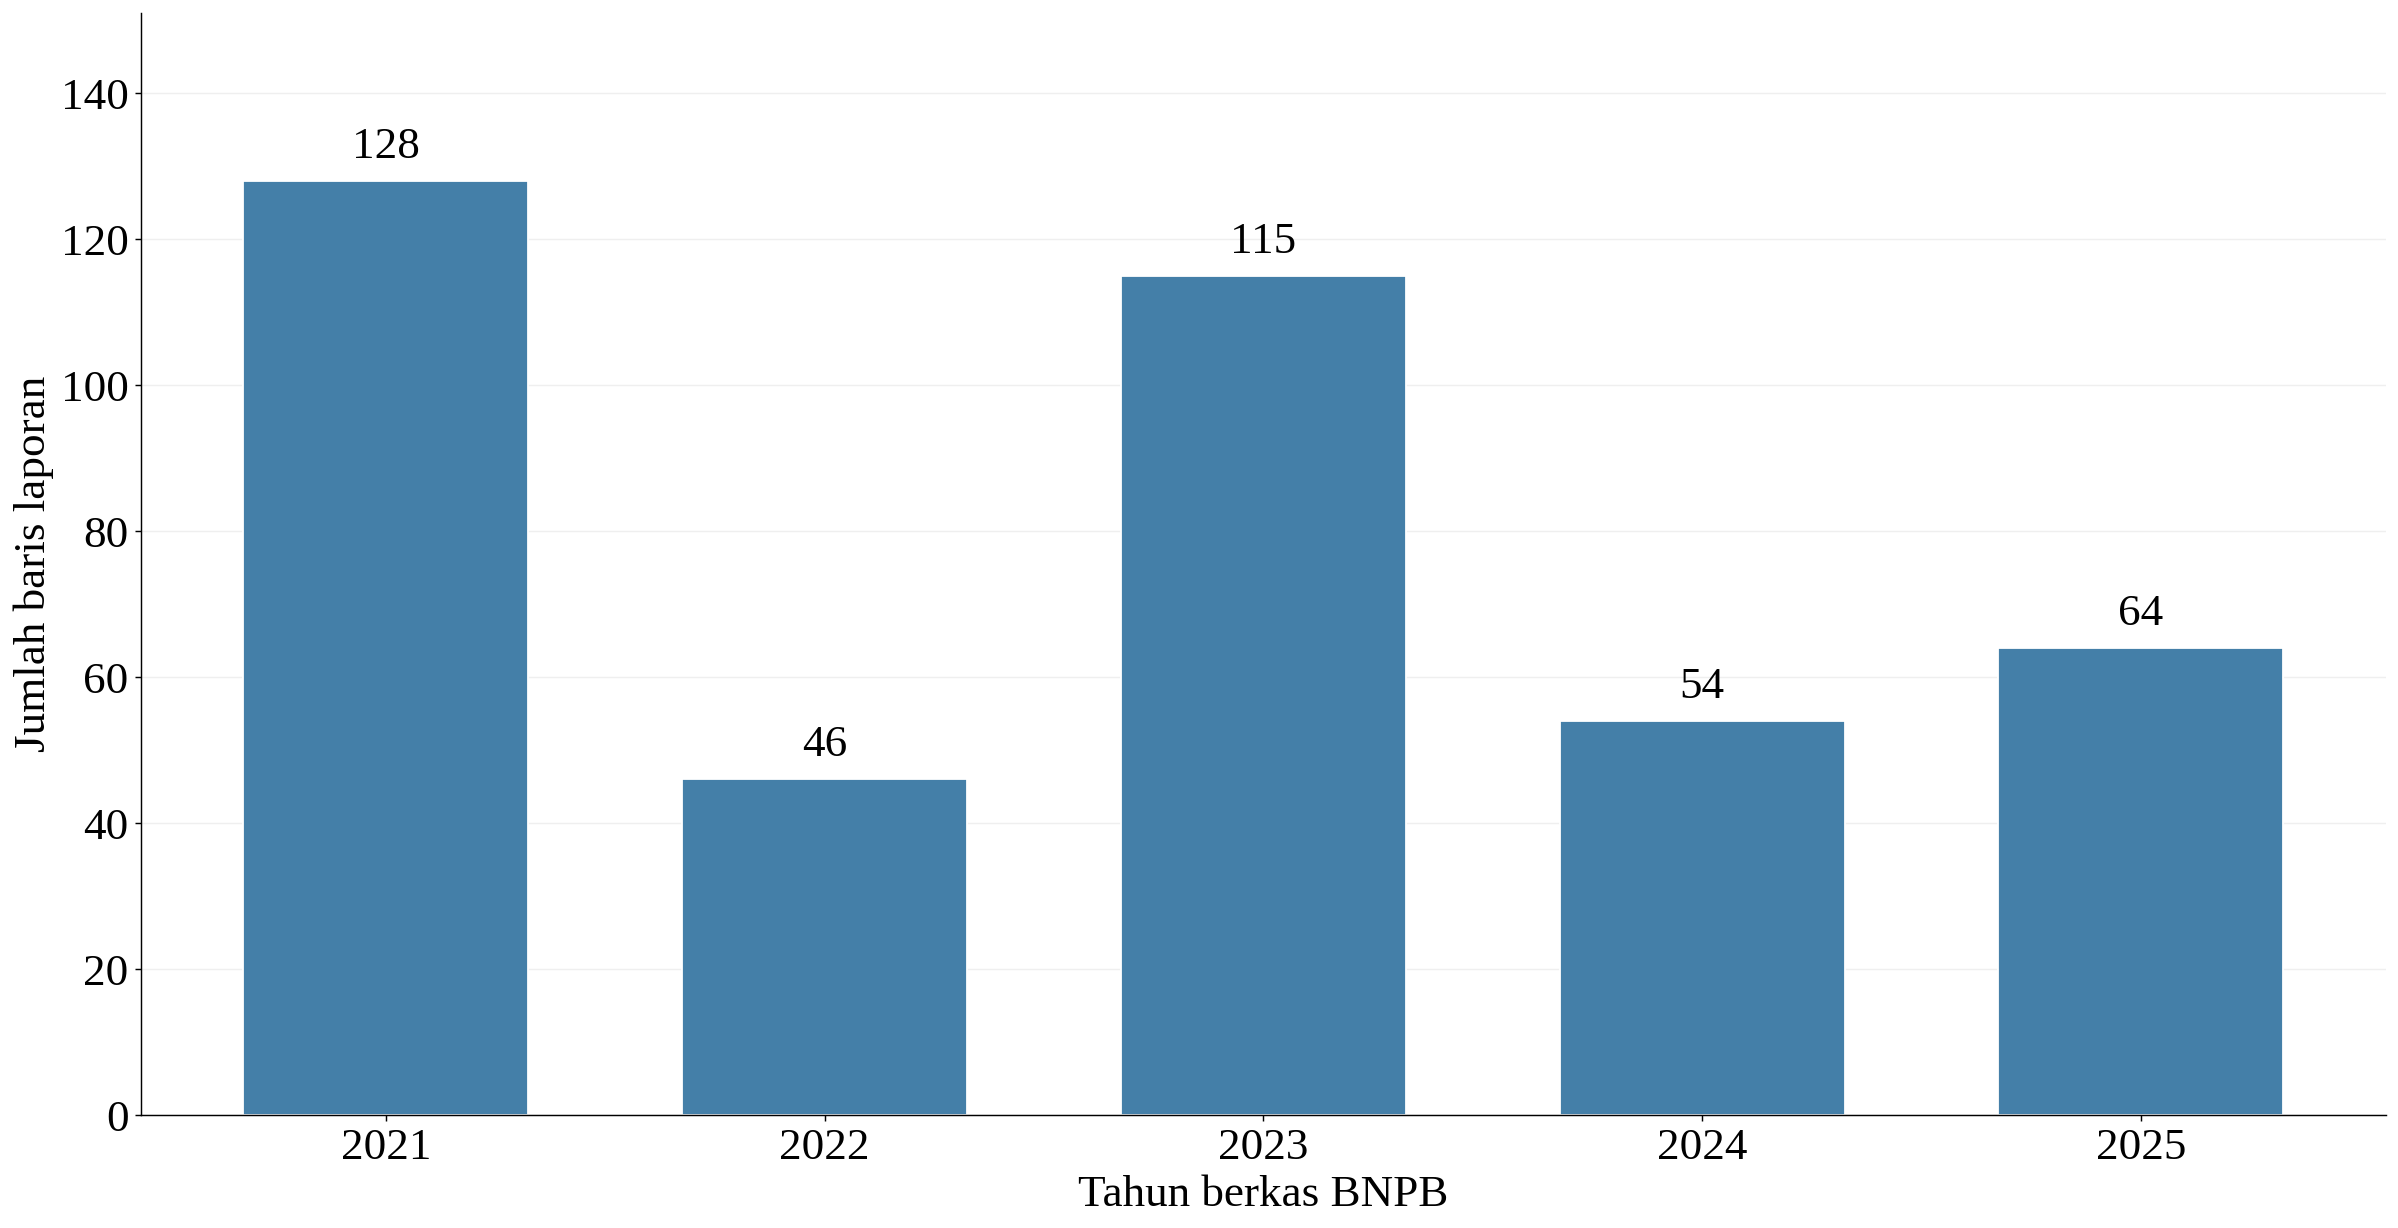

In [29]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from IPython.display import display
from matplotlib.ticker import MaxNLocator

# Pengaturan visualisasi
plt.rcParams.update({
    "font.family": "Liberation Serif",
    "font.size": 25,
    "axes.labelsize": 25,
    "xtick.labelsize": 25,
    "ytick.labelsize": 25,
    "legend.fontsize": 25
})

tahun_bnpb = [2021, 2022, 2023, 2024, 2025]

kolom_laporan = [
    f"bencana_{t}_baris_laporan_raw"
    for t in tahun_bnpb
]

assert all(c in df_raw.columns for c in kolom_laporan)

# Data sementara, tanpa mengubah data asli
data_frekuensi_d3 = (
    df_raw[["kabupaten_kota"] + kolom_laporan]
    .copy()
    .set_index("kabupaten_kota")
)

data_frekuensi_d3 = data_frekuensi_d3.apply(
    pd.to_numeric, errors="coerce"
)
data_frekuensi_d3.columns = tahun_bnpb

ringkasan_frekuensi_d3 = pd.DataFrame({
    "tahun": tahun_bnpb,
    "total_laporan": data_frekuensi_d3.sum().values,
    "wilayah_valid": data_frekuensi_d3.count().values,
    "wilayah_nol": data_frekuensi_d3.eq(0).sum().values
})

display(ringkasan_frekuensi_d3)

fig, ax = plt.subplots(figsize=(19, 10))

x = np.arange(len(tahun_bnpb))
nilai = ringkasan_frekuensi_d3["total_laporan"].to_numpy()

bars = ax.bar(
    x, nilai,
    width=0.65,
    color="#447FA8",
    edgecolor="white"
)

for bar, v in zip(bars, nilai):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        v + 2,
        f"{v:,.0f}",
        ha="center",
        va="bottom",
        fontsize=25
    )

ax.set_xticks(x)
ax.set_xticklabels(tahun_bnpb)
ax.set_xlabel("Tahun berkas BNPB")
ax.set_ylabel("Jumlah baris laporan")
ax.set_ylim(0, max(nilai) * 1.18)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", alpha=0.20)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### Heatmap jumlah laporan menurut wilayah dan tahun

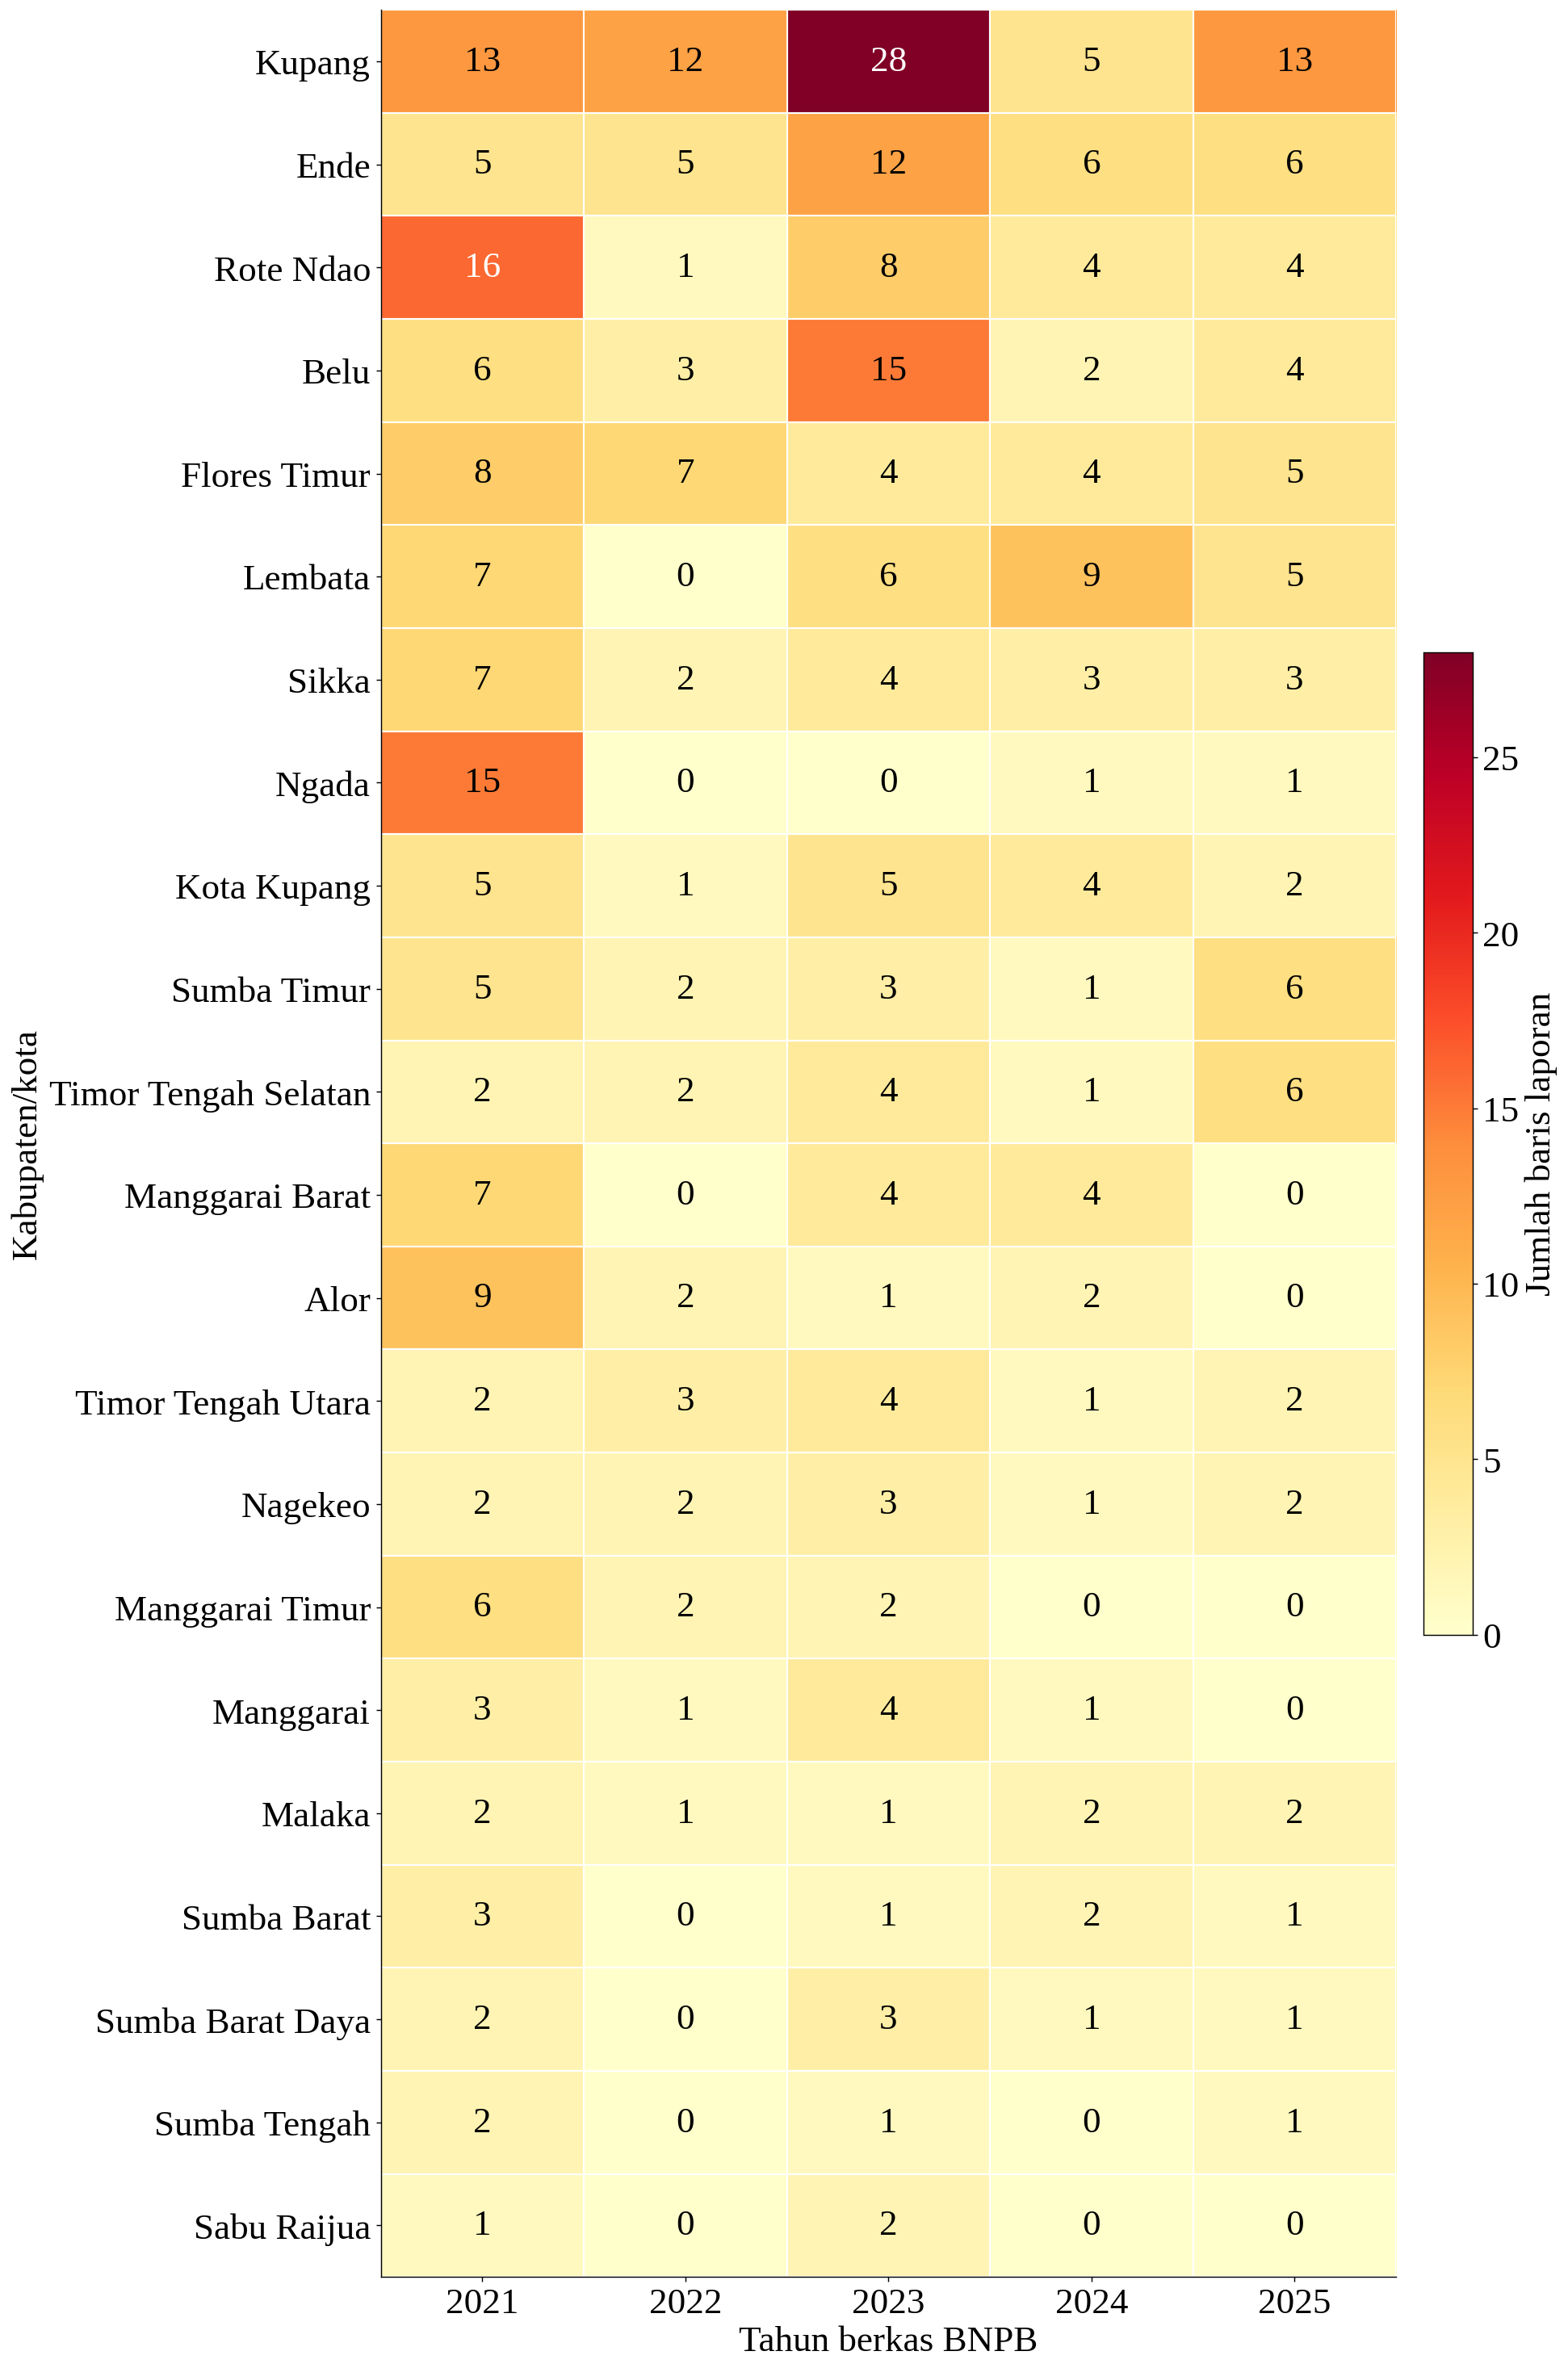

In [30]:

# D.3.2 Heatmap frekuensi laporan BNPB

matriks_bnpb = data_frekuensi_d3.copy()

# Urutkan wilayah berdasarkan total laporan
matriks_bnpb = matriks_bnpb.loc[
    matriks_bnpb.sum(axis=1).sort_values(
        ascending=False
    ).index
]

fig, ax = plt.subplots(figsize=(20, 24))

cmap = plt.get_cmap("YlOrRd").copy()
cmap.set_bad("#D0D0D0")

nilai = matriks_bnpb.to_numpy(dtype=float)

im = ax.imshow(
    nilai,
    aspect="auto",
    interpolation="nearest",
    cmap=cmap,
    vmin=0
)

ax.set_xticks(np.arange(len(tahun_bnpb)))
ax.set_xticklabels(tahun_bnpb)

ax.set_yticks(np.arange(len(matriks_bnpb)))
ax.set_yticklabels(matriks_bnpb.index)

ax.set_xlabel("Tahun berkas BNPB")
ax.set_ylabel("Kabupaten/kota")

# Angka pada setiap sel
batas = np.nanmax(nilai) * 0.55

for i in range(nilai.shape[0]):
    for j in range(nilai.shape[1]):
        v = nilai[i, j]

        if np.isfinite(v):
            ax.text(
                j, i, f"{v:.0f}",
                ha="center", va="center",
                fontsize=25,
                color="white" if v > batas else "black"
            )
        else:
            ax.text(
                j, i, "NA",
                ha="center", va="center",
                fontsize=25
            )

ax.set_xticks(
    np.arange(-0.5, nilai.shape[1], 1),
    minor=True
)
ax.set_yticks(
    np.arange(-0.5, nilai.shape[0], 1),
    minor=True
)

ax.grid(
    which="minor",
    color="white",
    linewidth=1.2
)
ax.tick_params(which="minor", bottom=False, left=False)

cbar = fig.colorbar(
    im, ax=ax,
    fraction=0.045,
    pad=0.025
)
cbar.set_label("Jumlah baris laporan", fontsize=25)
cbar.ax.tick_params(labelsize=25)

fig.subplots_adjust(
    left=0.35,
    right=0.87,
    bottom=0.08,
    top=0.98
)

plt.show()


### Distribusi jenis bencana BNPB

tahun,2021,2022,2023,2024,2025,Total
jenis,,,,,,
Banjir,61,32,28,14,39,174
Cuaca ekstrem,33,8,51,13,9,114
Tanah longsor,27,3,10,5,12,57
Kebakaran hutan/lahan,1,1,14,14,0,30
Gelombang dan abrasi,3,2,4,4,0,13
Gempa bumi,3,0,5,0,0,8
Erupsi gunung api,0,0,1,3,3,7
Kekeringan,0,0,2,1,0,3
Kebakaran permukiman,0,0,0,0,1,1


Selisih total menurut jenis dan laporan:


,0
tahun,
2021,0
2022,0
2023,0
2024,0
2025,0


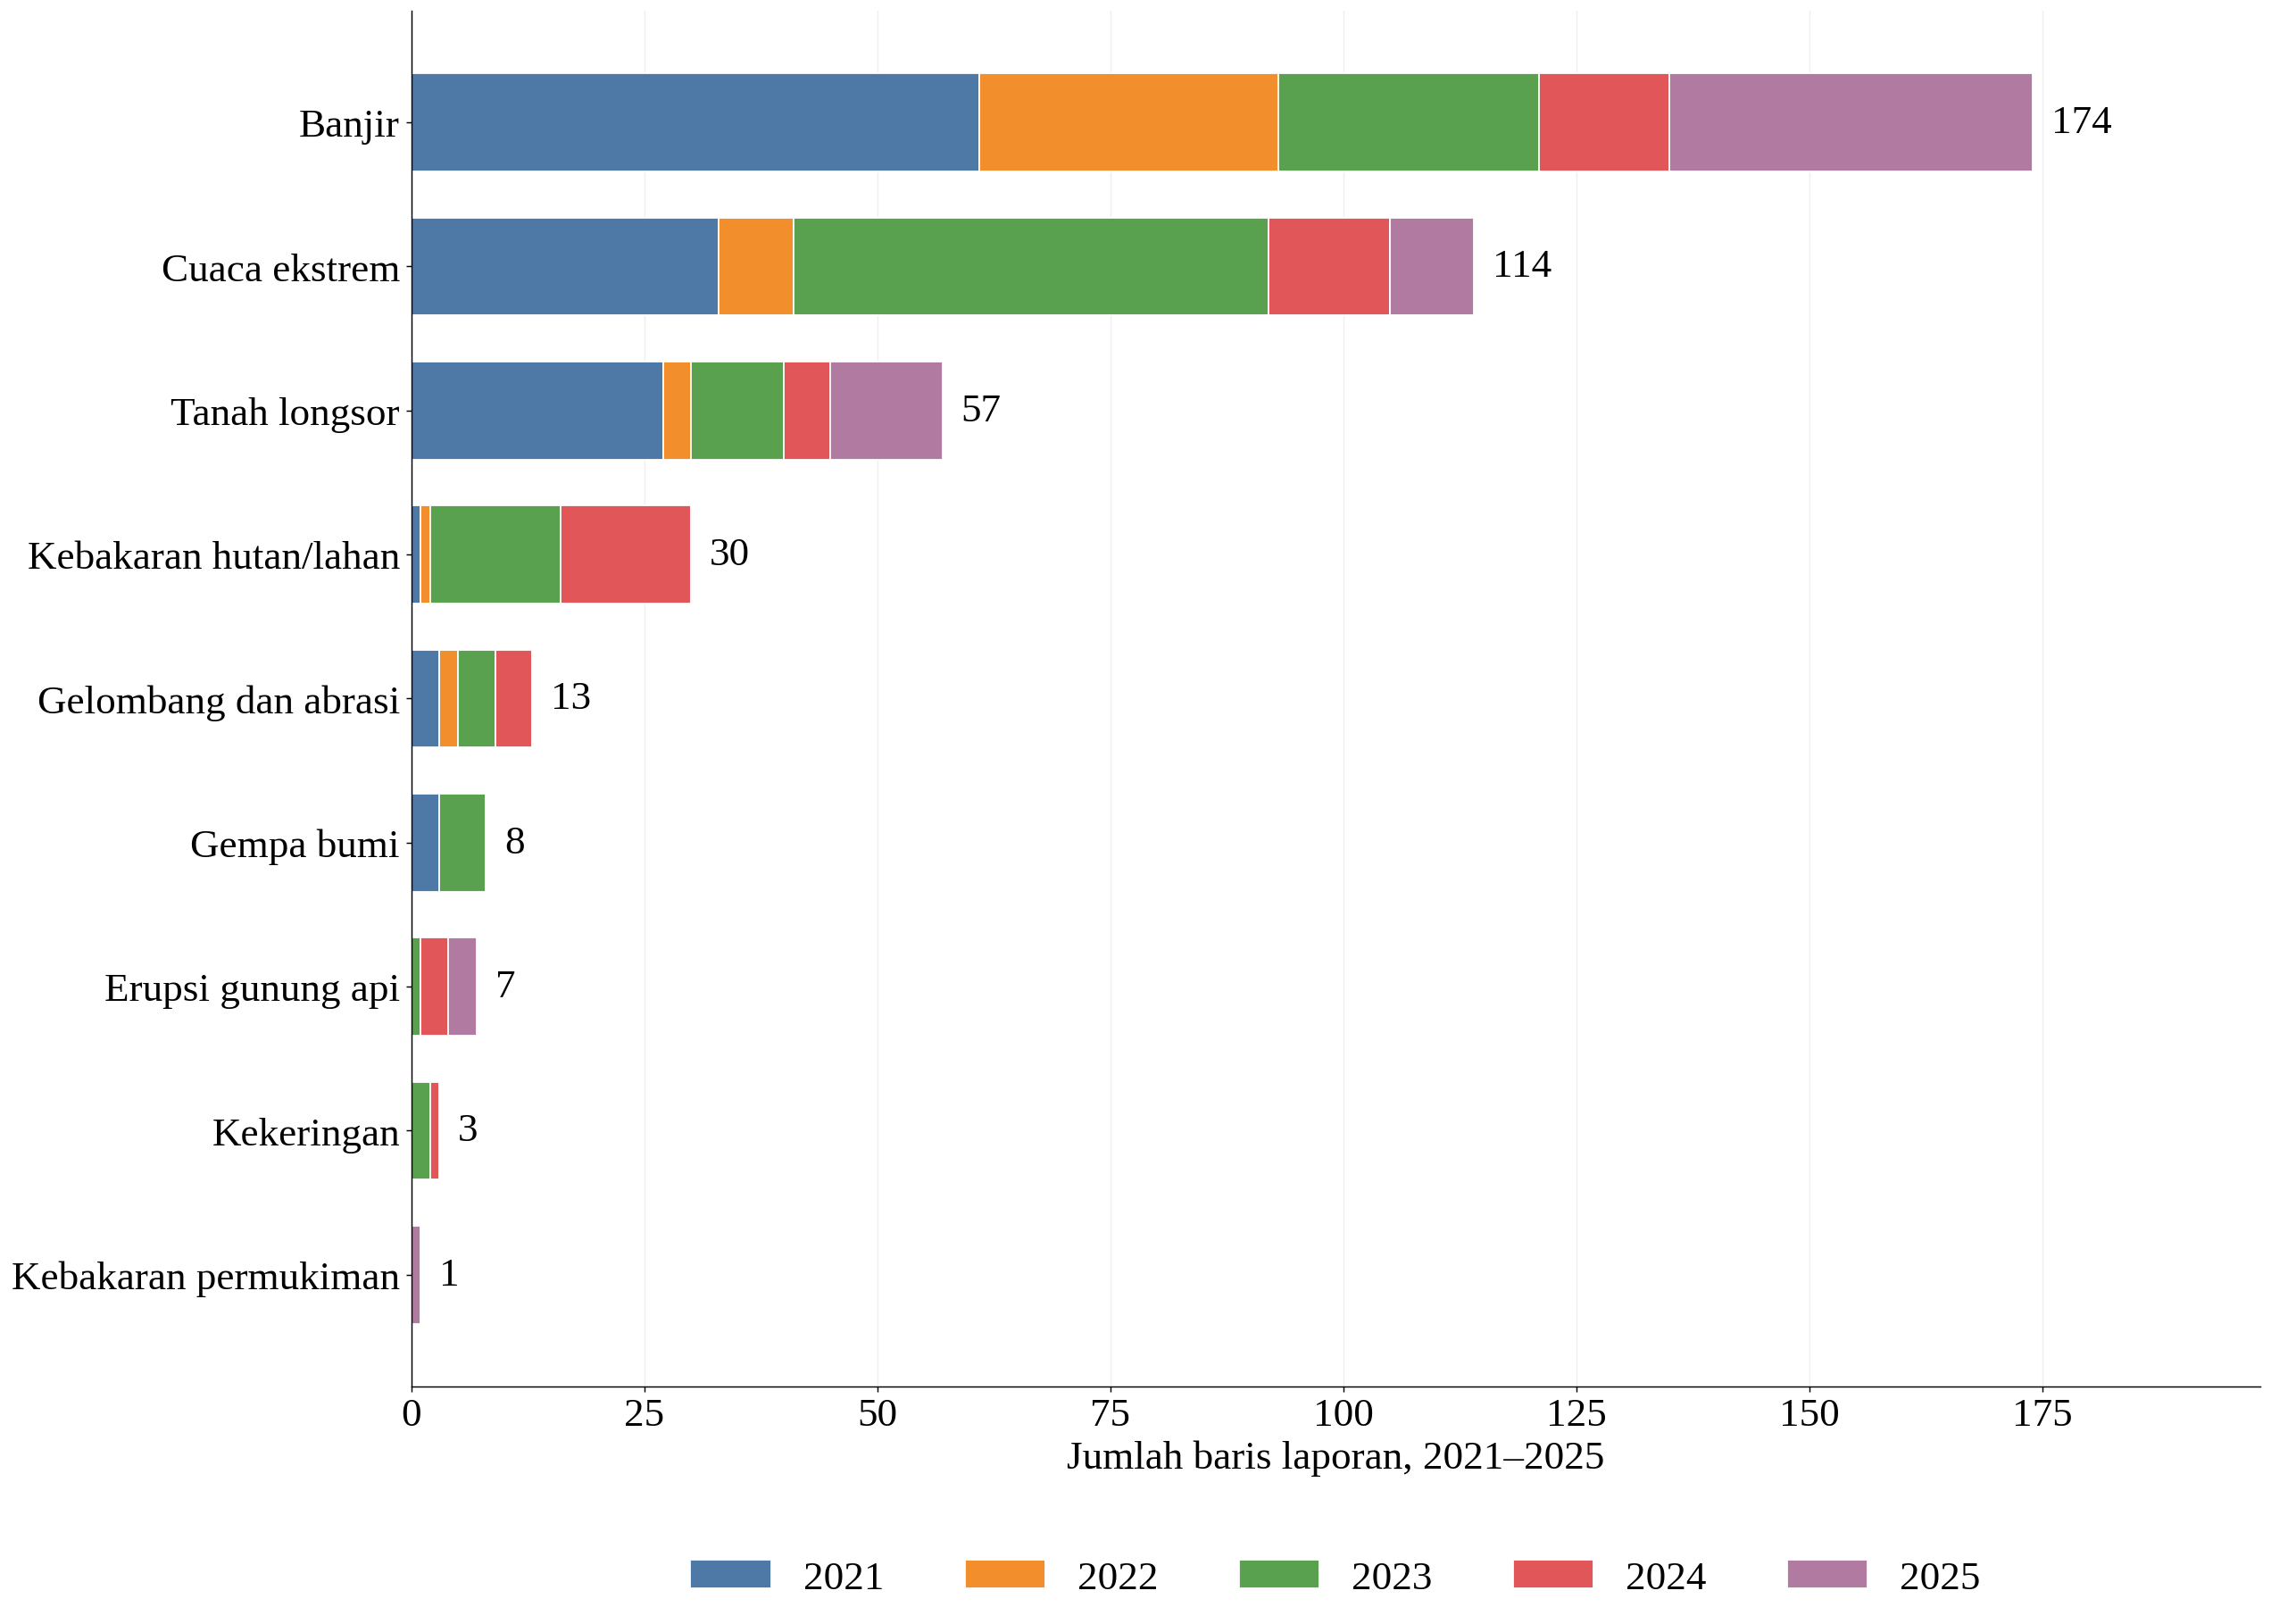

In [31]:

# D.3.3 Komposisi jenis laporan BNPB

pola = re.compile(
    r"^bencana_(202[1-5])_jenis_(.+)_baris_raw$"
)

label_jenis = {
    "banjir": "Banjir",
    "cuaca_ekstrem": "Cuaca ekstrem",
    "longsor": "Tanah longsor",
    "tanah_longsor": "Tanah longsor",
    "karhutla": "Kebakaran hutan/lahan",
    "gelombang_abrasi": "Gelombang dan abrasi",
    "gempa_bumi": "Gempa bumi",
    "erupsi_gunung_api": "Erupsi gunung api",
    "kekeringan": "Kekeringan",
    "kebakaran_permukiman": "Kebakaran permukiman",
    "konflik_sosial": "Konflik sosial"
}

rekaman = []

for col in df_raw.columns:
    m = pola.fullmatch(col)
    if m is None:
        continue

    tahun = int(m.group(1))
    kode = m.group(2)

    nilai = pd.to_numeric(
        df_raw[col], errors="coerce"
    ).sum(min_count=1)

    rekaman.append({
        "tahun": tahun,
        "jenis": label_jenis.get(
            kode, kode.replace("_", " ").capitalize()
        ),
        "jumlah": nilai
    })

if not rekaman:
    raise ValueError("Kolom jenis bencana tidak ditemukan.")

rekap_jenis_d3 = (
    pd.DataFrame(rekaman)
    .groupby(["jenis", "tahun"])["jumlah"]
    .sum()
    .unstack("tahun")
    .reindex(columns=tahun_bnpb, fill_value=0)
    .fillna(0)
)

rekap_jenis_d3["Total"] = (
    rekap_jenis_d3[tahun_bnpb].sum(axis=1)
)

rekap_jenis_d3 = rekap_jenis_d3.sort_values(
    "Total", ascending=False
)

display(rekap_jenis_d3)

# Validasi terhadap total laporan
cek_jenis = (
    rekap_jenis_d3[tahun_bnpb].sum(axis=0)
    - data_frekuensi_d3.sum(axis=0)
)

print("Selisih total menurut jenis dan laporan:")
display(cek_jenis)

if not np.allclose(cek_jenis.values, 0):
    raise ValueError("Total jenis bencana tidak konsisten.")

# Jenis dengan total nol tidak perlu batang
plot_jenis = rekap_jenis_d3[
    rekap_jenis_d3["Total"] > 0
].copy()

warna_tahun = [
    "#4E79A7", "#F28E2B", "#59A14F",
    "#E15759", "#B07AA1"
]

fig, ax = plt.subplots(figsize=(27, 15))

y = np.arange(len(plot_jenis))
dasar = np.zeros(len(plot_jenis))

for i, tahun in enumerate(tahun_bnpb):
    v = plot_jenis[tahun].to_numpy(dtype=float)

    ax.barh(
        y, v, left=dasar,
        height=0.68,
        color=warna_tahun[i],
        label=str(tahun),
        edgecolor="white"
    )
    dasar += v

for i, total in enumerate(plot_jenis["Total"]):
    ax.text(
        total + 2, i,
        f"{total:,.0f}",
        va="center",
        fontsize=25
    )

ax.set_yticks(y)
ax.set_yticklabels(plot_jenis.index)
ax.invert_yaxis()

ax.set_xlabel("Jumlah baris laporan, 2021–2025")
ax.set_xlim(0, plot_jenis["Total"].max() * 1.14)
ax.grid(axis="x", alpha=0.18)
ax.set_axisbelow(True)

ax.legend(
    ncol=5,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    frameon=False
)

fig.subplots_adjust(
    left=0.37,
    right=0.96,
    top=0.98,
    bottom=0.19
)

plt.show()


### Distribusi dampak BNPB menurut tahun

,meninggal,luka,pengungsi,rumah
tahun,,,,
2021,190.0,265.0,634763.0,57008.0
2022,5.0,3.0,66798.0,1023.0
2023,16.0,9.0,61971.0,1569.0
2024,31.0,69.0,77901.0,2840.0
2025,20.0,29.0,78664.0,912.0


,indikator,total_2021_2025,kontribusi_2021_persen
0,meninggal,262.0,72.52
1,luka,375.0,70.67
2,pengungsi,920097.0,68.99
3,rumah,63352.0,89.99


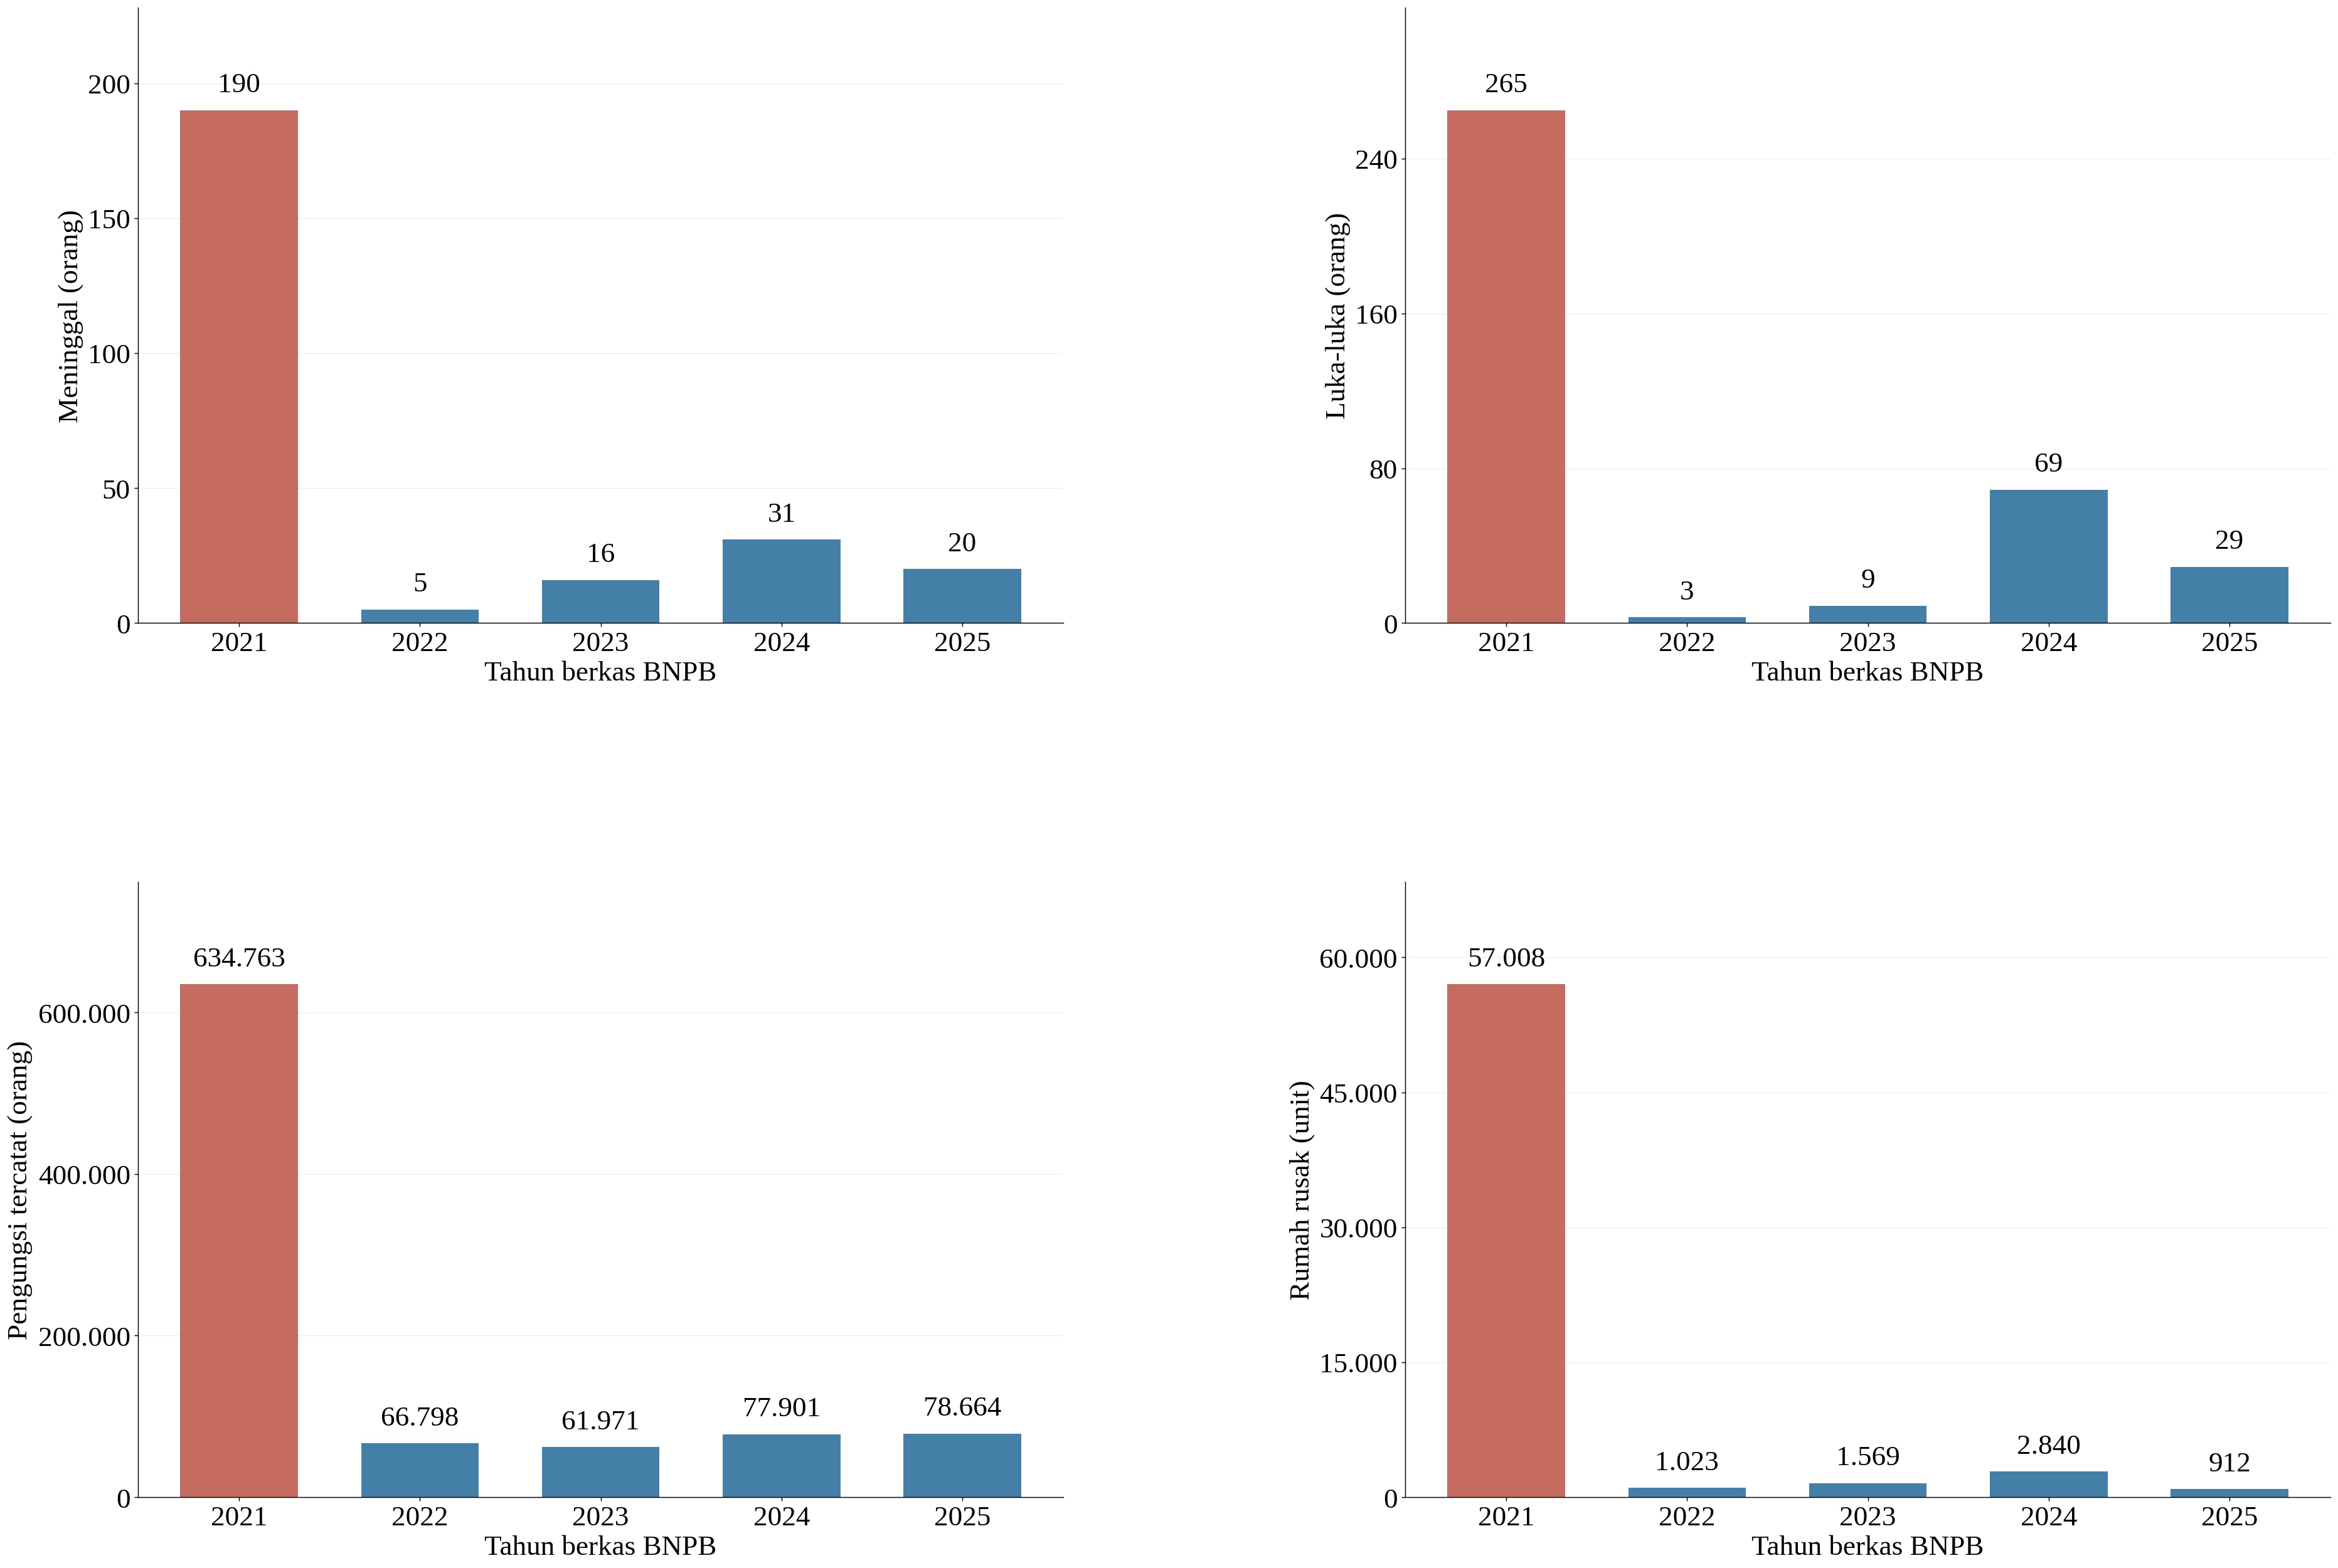

In [32]:

# D.3.4 Dampak BNPB 2021–2025

indikator_dampak = {
    "meninggal": ("Meninggal (orang)", "meninggal_jumlah"),
    "luka": ("Luka-luka (orang)", "luka_jumlah"),
    "pengungsi": ("Pengungsi tercatat (orang)", "pengungsi_jumlah"),
    "rumah": ("Rumah rusak (unit)", "rumah_rusak_jumlah")
}

rekap_dampak_d3 = pd.DataFrame(index=tahun_bnpb)

for kode, (label, sufiks) in indikator_dampak.items():
    for tahun in tahun_bnpb:
        col = f"bencana_{tahun}_{sufiks}_raw"

        if col not in df_raw.columns:
            raise KeyError(f"Kolom tidak ditemukan: {col}")

        angka = pd.to_numeric(
            df_raw[col], errors="coerce"
        )

        rekap_dampak_d3.loc[tahun, kode] = (
            angka.sum(min_count=1)
        )

rekap_dampak_d3.index.name = "tahun"
display(rekap_dampak_d3)

# Kontribusi tahun 2021
kontribusi_d3 = pd.DataFrame({
    "indikator": list(indikator_dampak),
    "total_2021_2025": rekap_dampak_d3.sum().values,
    "kontribusi_2021_persen": (
        rekap_dampak_d3.loc[2021]
        / rekap_dampak_d3.sum()
        * 100
    ).values
})

display(kontribusi_d3.round(2))

# Visualisasi 2 x 2
fig, axes = plt.subplots(
    2, 2, figsize=(32, 21)
)

def fmt_angka(x):
    return f"{x:,.0f}".replace(",", ".")

for ax, (kode, (label, sufiks)) in zip(
    axes.flat, indikator_dampak.items()
):
    nilai = rekap_dampak_d3[kode].to_numpy()
    x = np.arange(len(tahun_bnpb))

    warna = [
        "#C66B60" if t == 2021 else "#447FA8"
        for t in tahun_bnpb
    ]

    bars = ax.bar(
        x, nilai,
        width=0.65,
        color=warna
    )

    for bar, v in zip(bars, nilai):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            v + max(nilai) * 0.025,
            fmt_angka(v),
            ha="center",
            va="bottom",
            fontsize=25
        )

    ax.set_xticks(x)
    ax.set_xticklabels(tahun_bnpb)
    ax.set_xlabel("Tahun berkas BNPB")
    ax.set_ylabel(label)

    ax.set_ylim(0, max(nilai) * 1.20)
    ax.grid(axis="y", alpha=0.20)
    ax.set_axisbelow(True)

    ax.tick_params(
        axis="both", labelsize=25
    )

    ax.yaxis.set_major_locator(
        MaxNLocator(nbins=5)
    )

    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(
            lambda v, pos: fmt_angka(v)
        )
    )

fig.subplots_adjust(
    left=0.13,
    right=0.97,
    bottom=0.10,
    top=0.97,
    hspace=0.42,
    wspace=0.37
)

plt.show()


## Visualisasi Diagnostik InaRISK

### Distribusi indikator agregat InaRISK

RINGKASAN DIAGNOSTIK INARISK


,indikator,valid,missing,nol,median,maksimum,skewness,outlier_IQR
0,Jiwa terpapar,22,0,0,1095672.500,2074057.000,0.416,0
1,Kerugian ekonomi,22,0,0,33523.625,91553.920,1.720,2
2,Kerugian fisik,22,0,0,4574.263,9127.557,0.211,0
3,Kerusakan lingkungan,22,0,0,123574.000,496754.000,1.259,1
4,Luas bahaya (ha),22,0,0,714945.000,3139598.000,2.030,2


KANDIDAT OUTLIER


,kabupaten_kota,indikator,nilai,batas_atas,batas_bawah
0,Timor Tengah Utara,Kerugian ekonomi,91185.76,67821.407,-4175.292
1,Belu,Kerugian ekonomi,91553.92,67821.407,-4175.292
2,Timor Tengah Utara,Kerusakan lingkungan,496754.00,414080.750,-112471.250
3,Timor Tengah Selatan,Luas bahaya (ha),3139598.00,1819536.250,-206999.750
4,Timor Tengah Utara,Luas bahaya (ha),2274781.00,1819536.250,-206999.750


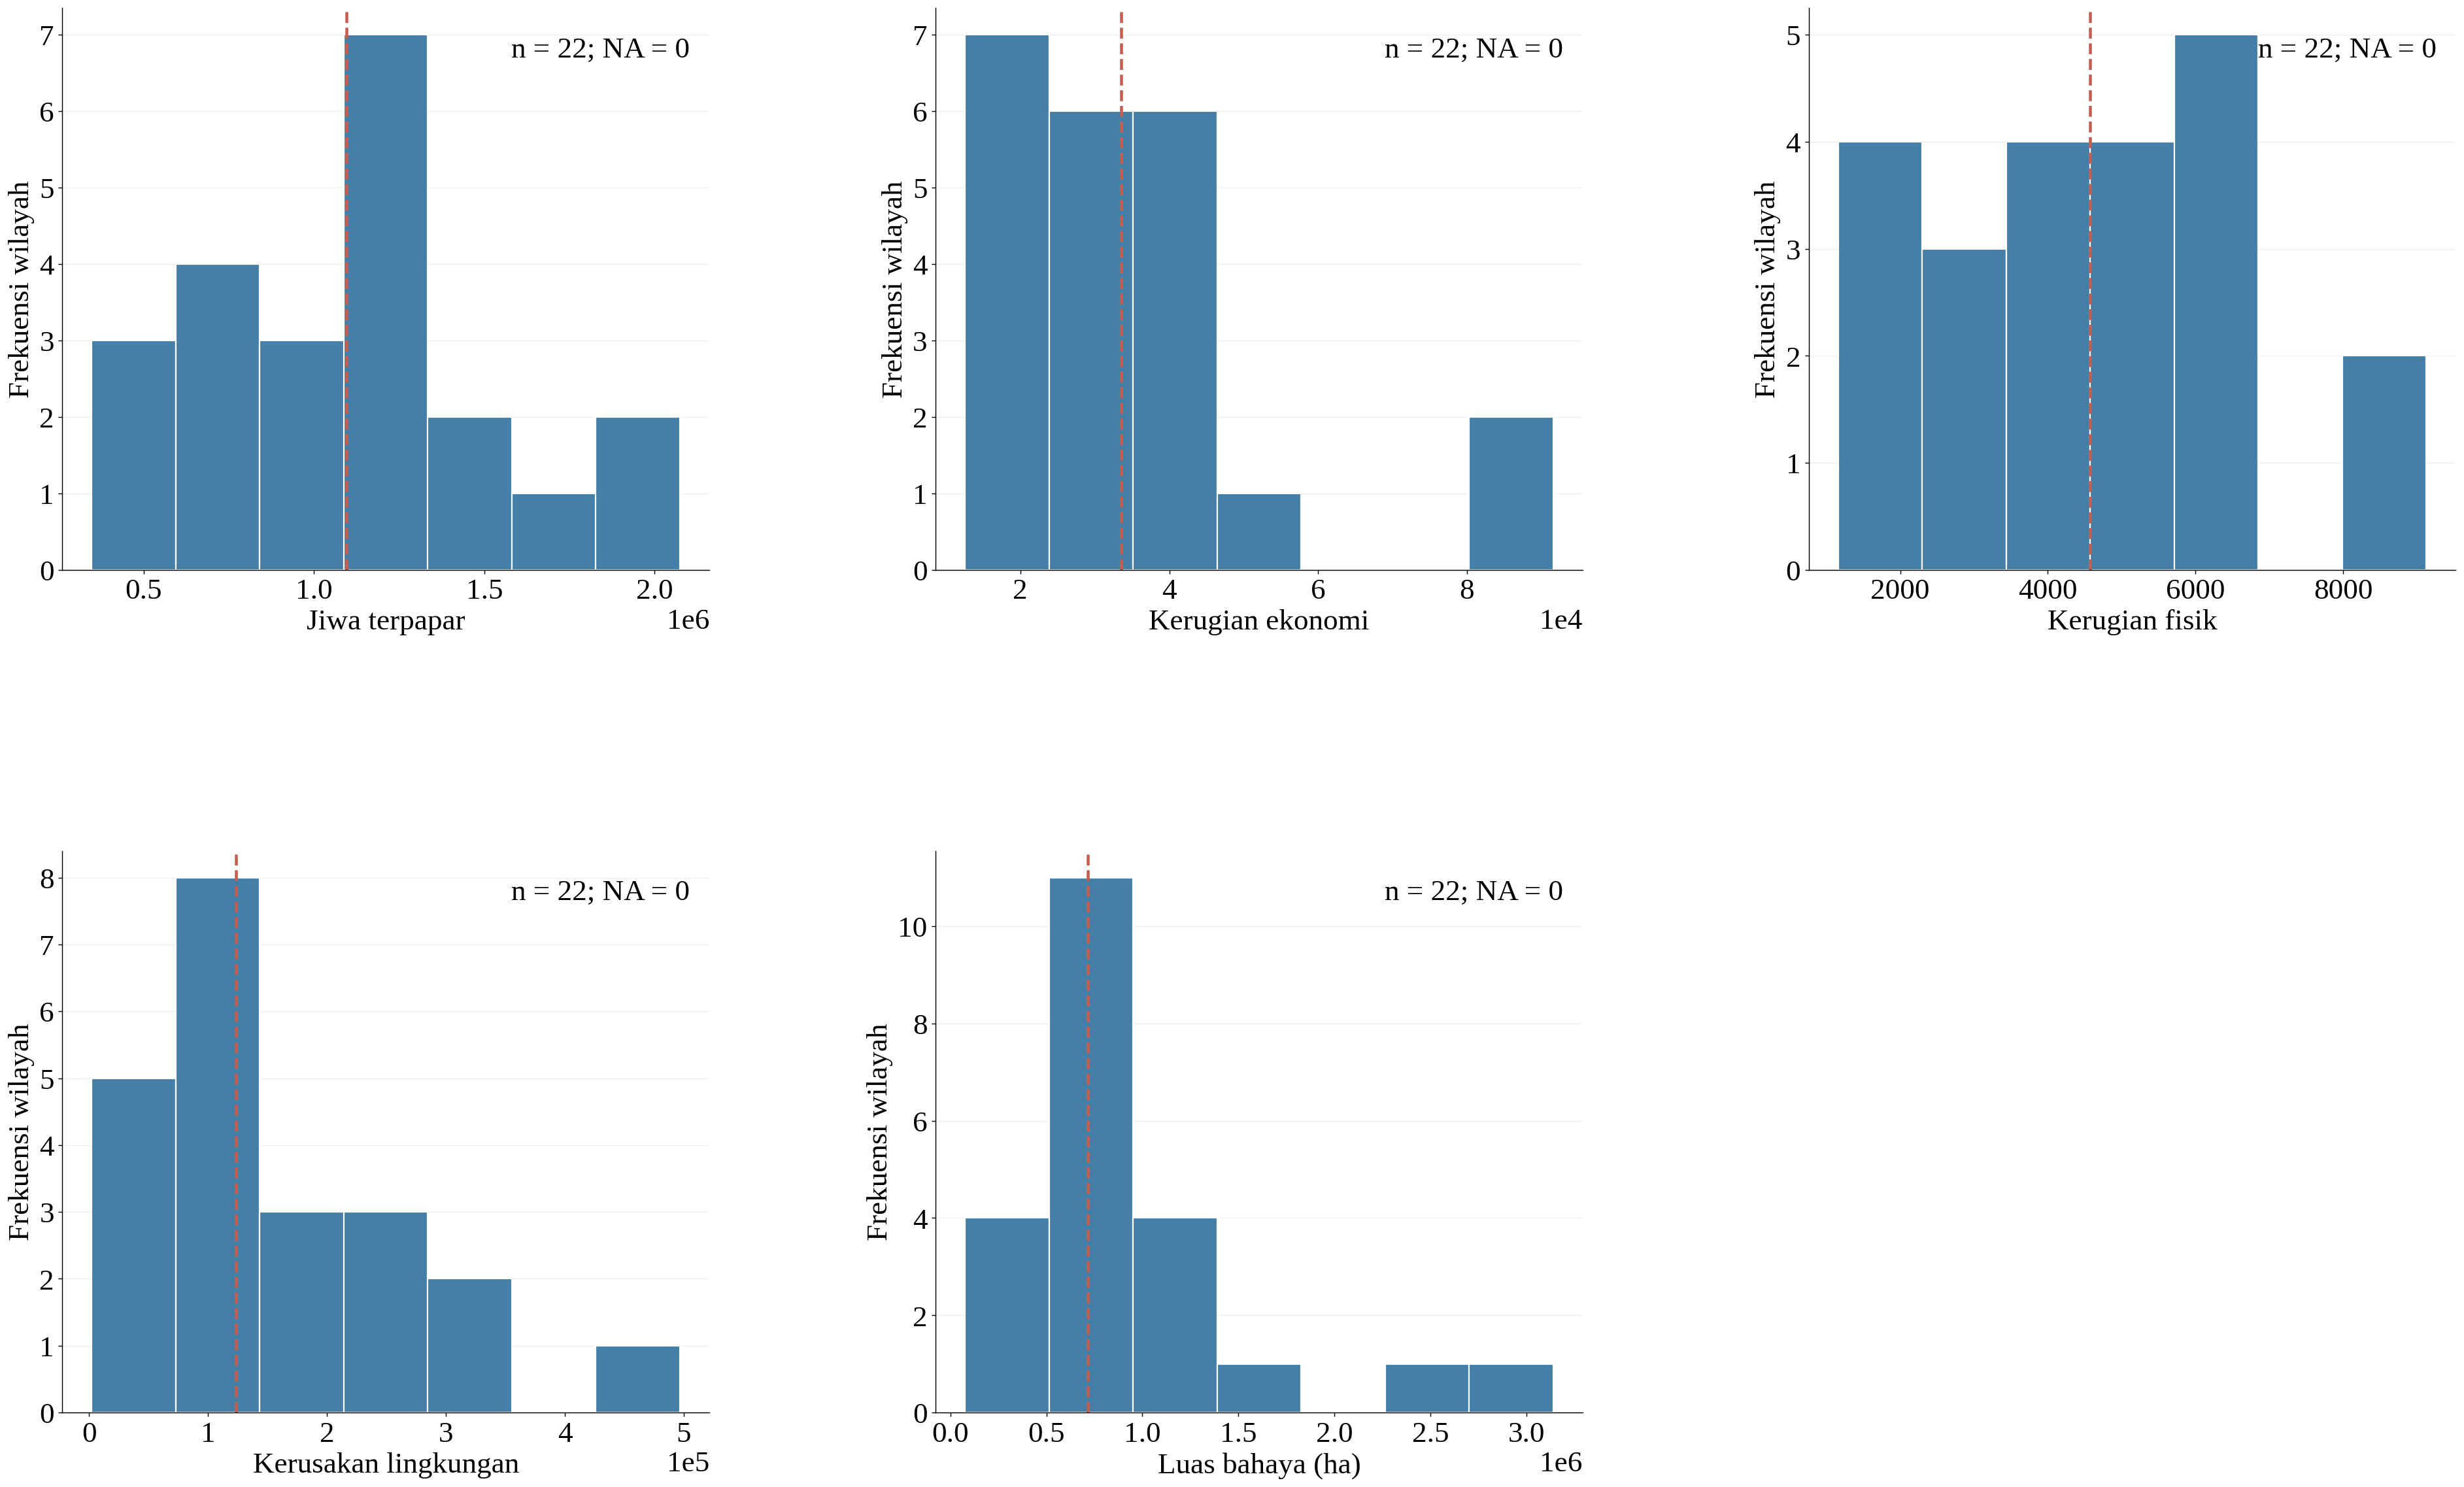

In [33]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display

plt.rcParams.update({
    "font.family": "Liberation Serif",
    "font.size": 25,
    "axes.labelsize": 25,
    "xtick.labelsize": 25,
    "ytick.labelsize": 25
})

label_inarisk = {
    "inarisk_jiwa_terpapar_agregat_raw": "Jiwa terpapar",
    "inarisk_kerugian_ekonomi_agregat_raw": "Kerugian ekonomi",
    "inarisk_kerugian_fisik_agregat_raw": "Kerugian fisik",
    "inarisk_kerusakan_lingkungan_agregat_raw": "Kerusakan lingkungan",
    "inarisk_luas_bahaya_agregat_ha_raw": "Luas bahaya (ha)"
}

kolom_inarisk = list(label_inarisk)

hilang = [c for c in kolom_inarisk if c not in df_raw.columns]
if hilang:
    raise KeyError(f"Kolom tidak ditemukan: {hilang}")

data_inarisk_d4 = df_raw[
    ["kabupaten_kota"] + kolom_inarisk
].copy().set_index("kabupaten_kota")

data_inarisk_d4 = data_inarisk_d4.apply(
    pd.to_numeric, errors="coerce"
)

# Statistik diagnostik
hasil = []
rincian_outlier_d4 = []

for col in kolom_inarisk:
    s = data_inarisk_d4[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1

    bawah = q1 - 1.5 * iqr
    atas = q3 + 1.5 * iqr

    outlier = s[(s < bawah) | (s > atas)] if iqr > 0 else s.iloc[:0]

    hasil.append({
        "indikator": label_inarisk[col],
        "valid": len(s),
        "missing": 22 - len(s),
        "nol": int((s == 0).sum()),
        "median": s.median(),
        "maksimum": s.max(),
        "skewness": s.skew(),
        "outlier_IQR": len(outlier)
    })

    for wilayah, nilai in outlier.items():
        rincian_outlier_d4.append({
            "kabupaten_kota": wilayah,
            "indikator": label_inarisk[col],
            "nilai": nilai,
            "batas_atas": atas,
            "batas_bawah": bawah
        })

ringkasan_inarisk_d4 = pd.DataFrame(hasil)
outlier_inarisk_d4 = pd.DataFrame(rincian_outlier_d4)

print("RINGKASAN DIAGNOSTIK INARISK")
display(ringkasan_inarisk_d4.round(3))

print("KANDIDAT OUTLIER")
display(outlier_inarisk_d4.round(3))

# Histogram
fig, axes = plt.subplots(
    2, 3, figsize=(32, 19)
)
axes = axes.flatten()

for i, col in enumerate(kolom_inarisk):
    ax = axes[i]
    s = data_inarisk_d4[col].dropna()

    ax.hist(
        s,
        bins=7,
        color="#447FA8",
        edgecolor="white",
        linewidth=1.2
    )

    ax.axvline(
        s.median(),
        color="#C65D50",
        linestyle="--",
        linewidth=2.5
    )

    ax.set_xlabel(label_inarisk[col])
    ax.set_ylabel("Frekuensi wilayah")

    ax.text(
        0.97, 0.95,
        f"n = {len(s)}; NA = {22-len(s)}",
        transform=ax.transAxes,
        ha="right", va="top",
        fontsize=25
    )

    ax.tick_params(axis="both", labelsize=25)
    ax.yaxis.set_major_locator(
        MaxNLocator(integer=True)
    )

    ax.ticklabel_format(
        axis="x",
        style="sci",
        scilimits=(-3, 4)
    )

    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)

axes[-1].set_visible(False)

fig.subplots_adjust(
    left=0.10,
    right=0.98,
    bottom=0.11,
    top=0.98,
    hspace=0.50,
    wspace=0.35
)

plt.show()


### Heatmap peringkat relatif indikator InaRISK

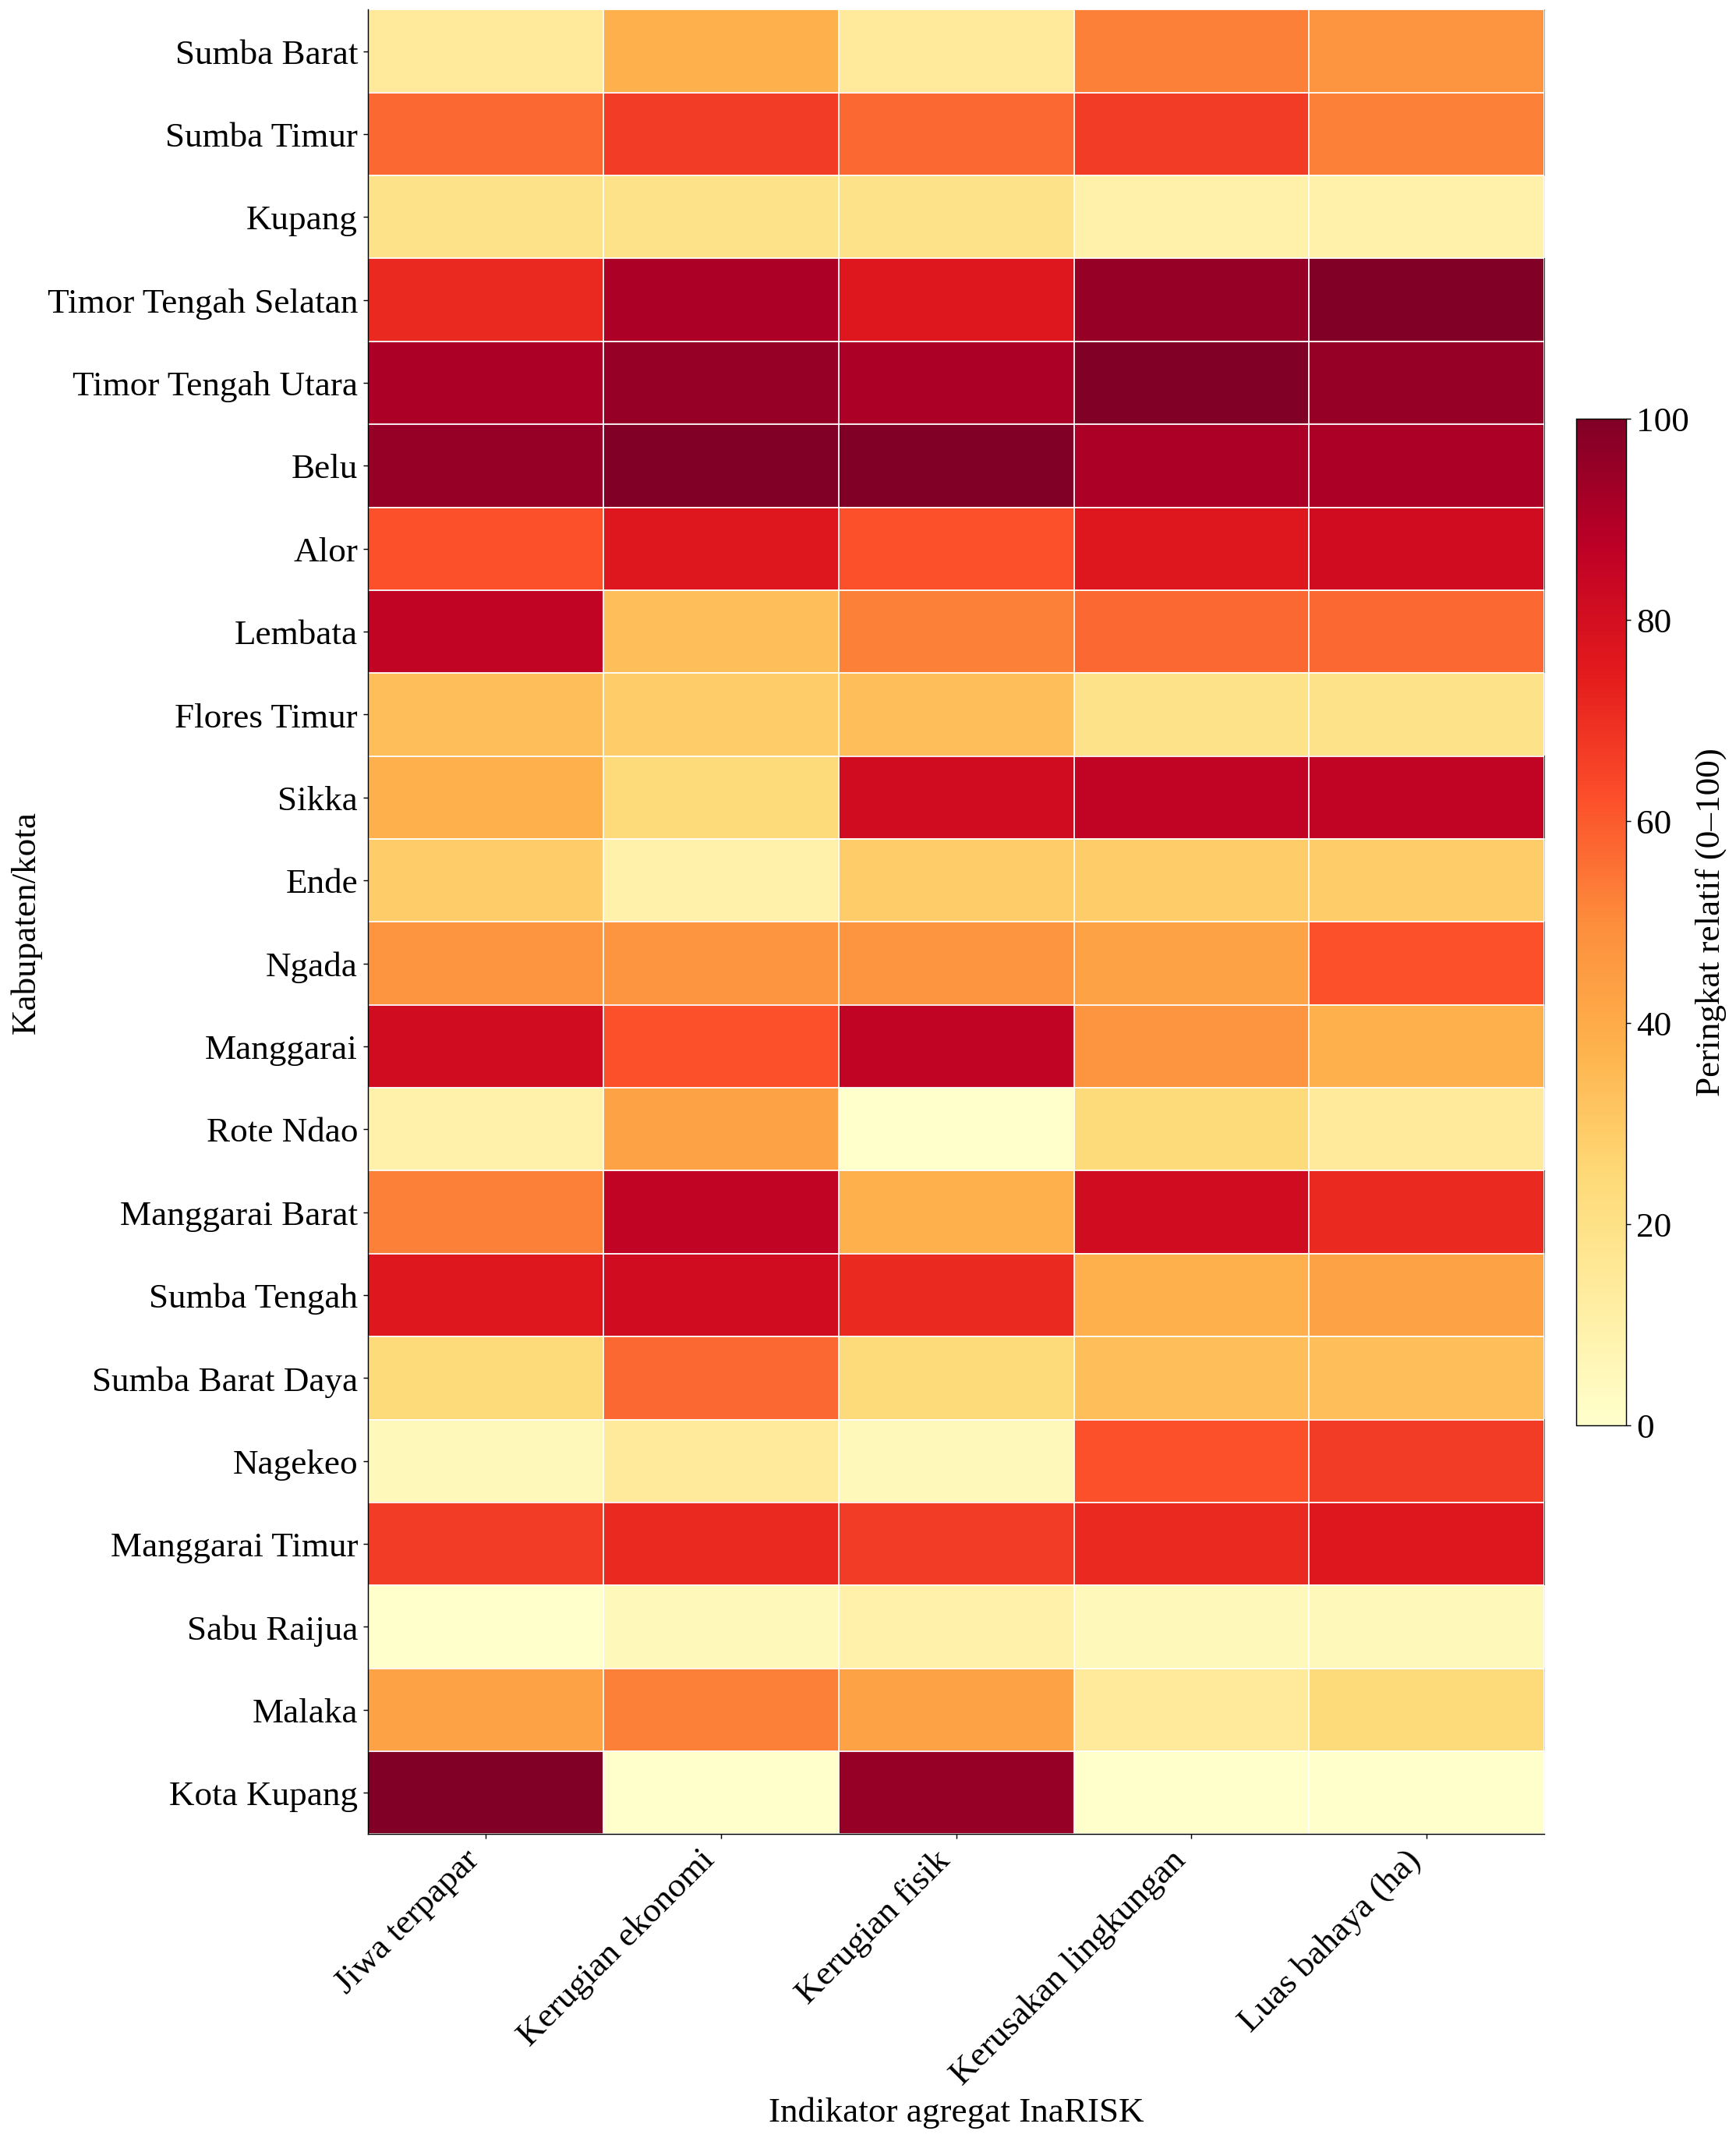

In [34]:

# D.4.2 Heatmap peringkat relatif InaRISK

rank_inarisk = pd.DataFrame(
    index=data_inarisk_d4.index
)

for col in kolom_inarisk:
    s = data_inarisk_d4[col]
    n = s.notna().sum()

    if n > 1 and s.nunique(dropna=True) > 1:
        rank_inarisk[col] = (
            (s.rank(method="average") - 1)
            / (n - 1) * 100
        )
    else:
        rank_inarisk[col] = np.where(
            s.notna(), 50.0, np.nan
        )

rank_inarisk.columns = [
    label_inarisk[c] for c in kolom_inarisk
]

fig, ax = plt.subplots(figsize=(23, 24))

cmap = plt.get_cmap("YlOrRd").copy()
cmap.set_bad("#D0D0D0")

nilai = rank_inarisk.to_numpy(dtype=float)

im = ax.imshow(
    nilai,
    cmap=cmap,
    vmin=0,
    vmax=100,
    aspect="auto",
    interpolation="nearest"
)

ax.set_xticks(np.arange(len(rank_inarisk.columns)))
ax.set_xticklabels(
    rank_inarisk.columns,
    rotation=45,
    ha="right",
    fontsize=25
)

ax.set_yticks(np.arange(len(rank_inarisk)))
ax.set_yticklabels(
    rank_inarisk.index,
    fontsize=25
)

ax.set_xlabel("Indikator agregat InaRISK")
ax.set_ylabel("Kabupaten/kota")

ax.set_xticks(
    np.arange(-0.5, nilai.shape[1], 1),
    minor=True
)
ax.set_yticks(
    np.arange(-0.5, nilai.shape[0], 1),
    minor=True
)

ax.grid(
    which="minor",
    color="white",
    linewidth=1
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

cbar = fig.colorbar(
    im, ax=ax,
    fraction=0.04,
    pad=0.025
)
cbar.set_label(
    "Peringkat relatif (0–100)",
    fontsize=25
)
cbar.ax.tick_params(labelsize=25)

fig.subplots_adjust(
    left=0.33,
    right=0.87,
    bottom=0.23,
    top=0.98
)

plt.show()


## Visualisasi Diagnostik DESTANA

### Distribusi jumlah entri DESTANA menurut wilayah

D.5 — RINGKASAN DESTANA
Jumlah seluruh wilayah: 22
Wilayah dengan entri: 20
Wilayah tidak tercantum: 2

Wilayah tidak tercantum:


,kabupaten_kota
0,Sumba Barat
1,Sumba Tengah


,kabupaten_kota,jumlah_entri
17,Nagekeo,89.0
7,Lembata,62.0
2,Kupang,43.0
21,Kota Kupang,23.0
1,Sumba Timur,21.0
8,Flores Timur,20.0
10,Ende,19.0
4,Timor Tengah Utara,19.0
3,Timor Tengah Selatan,18.0
14,Manggarai Barat,15.0


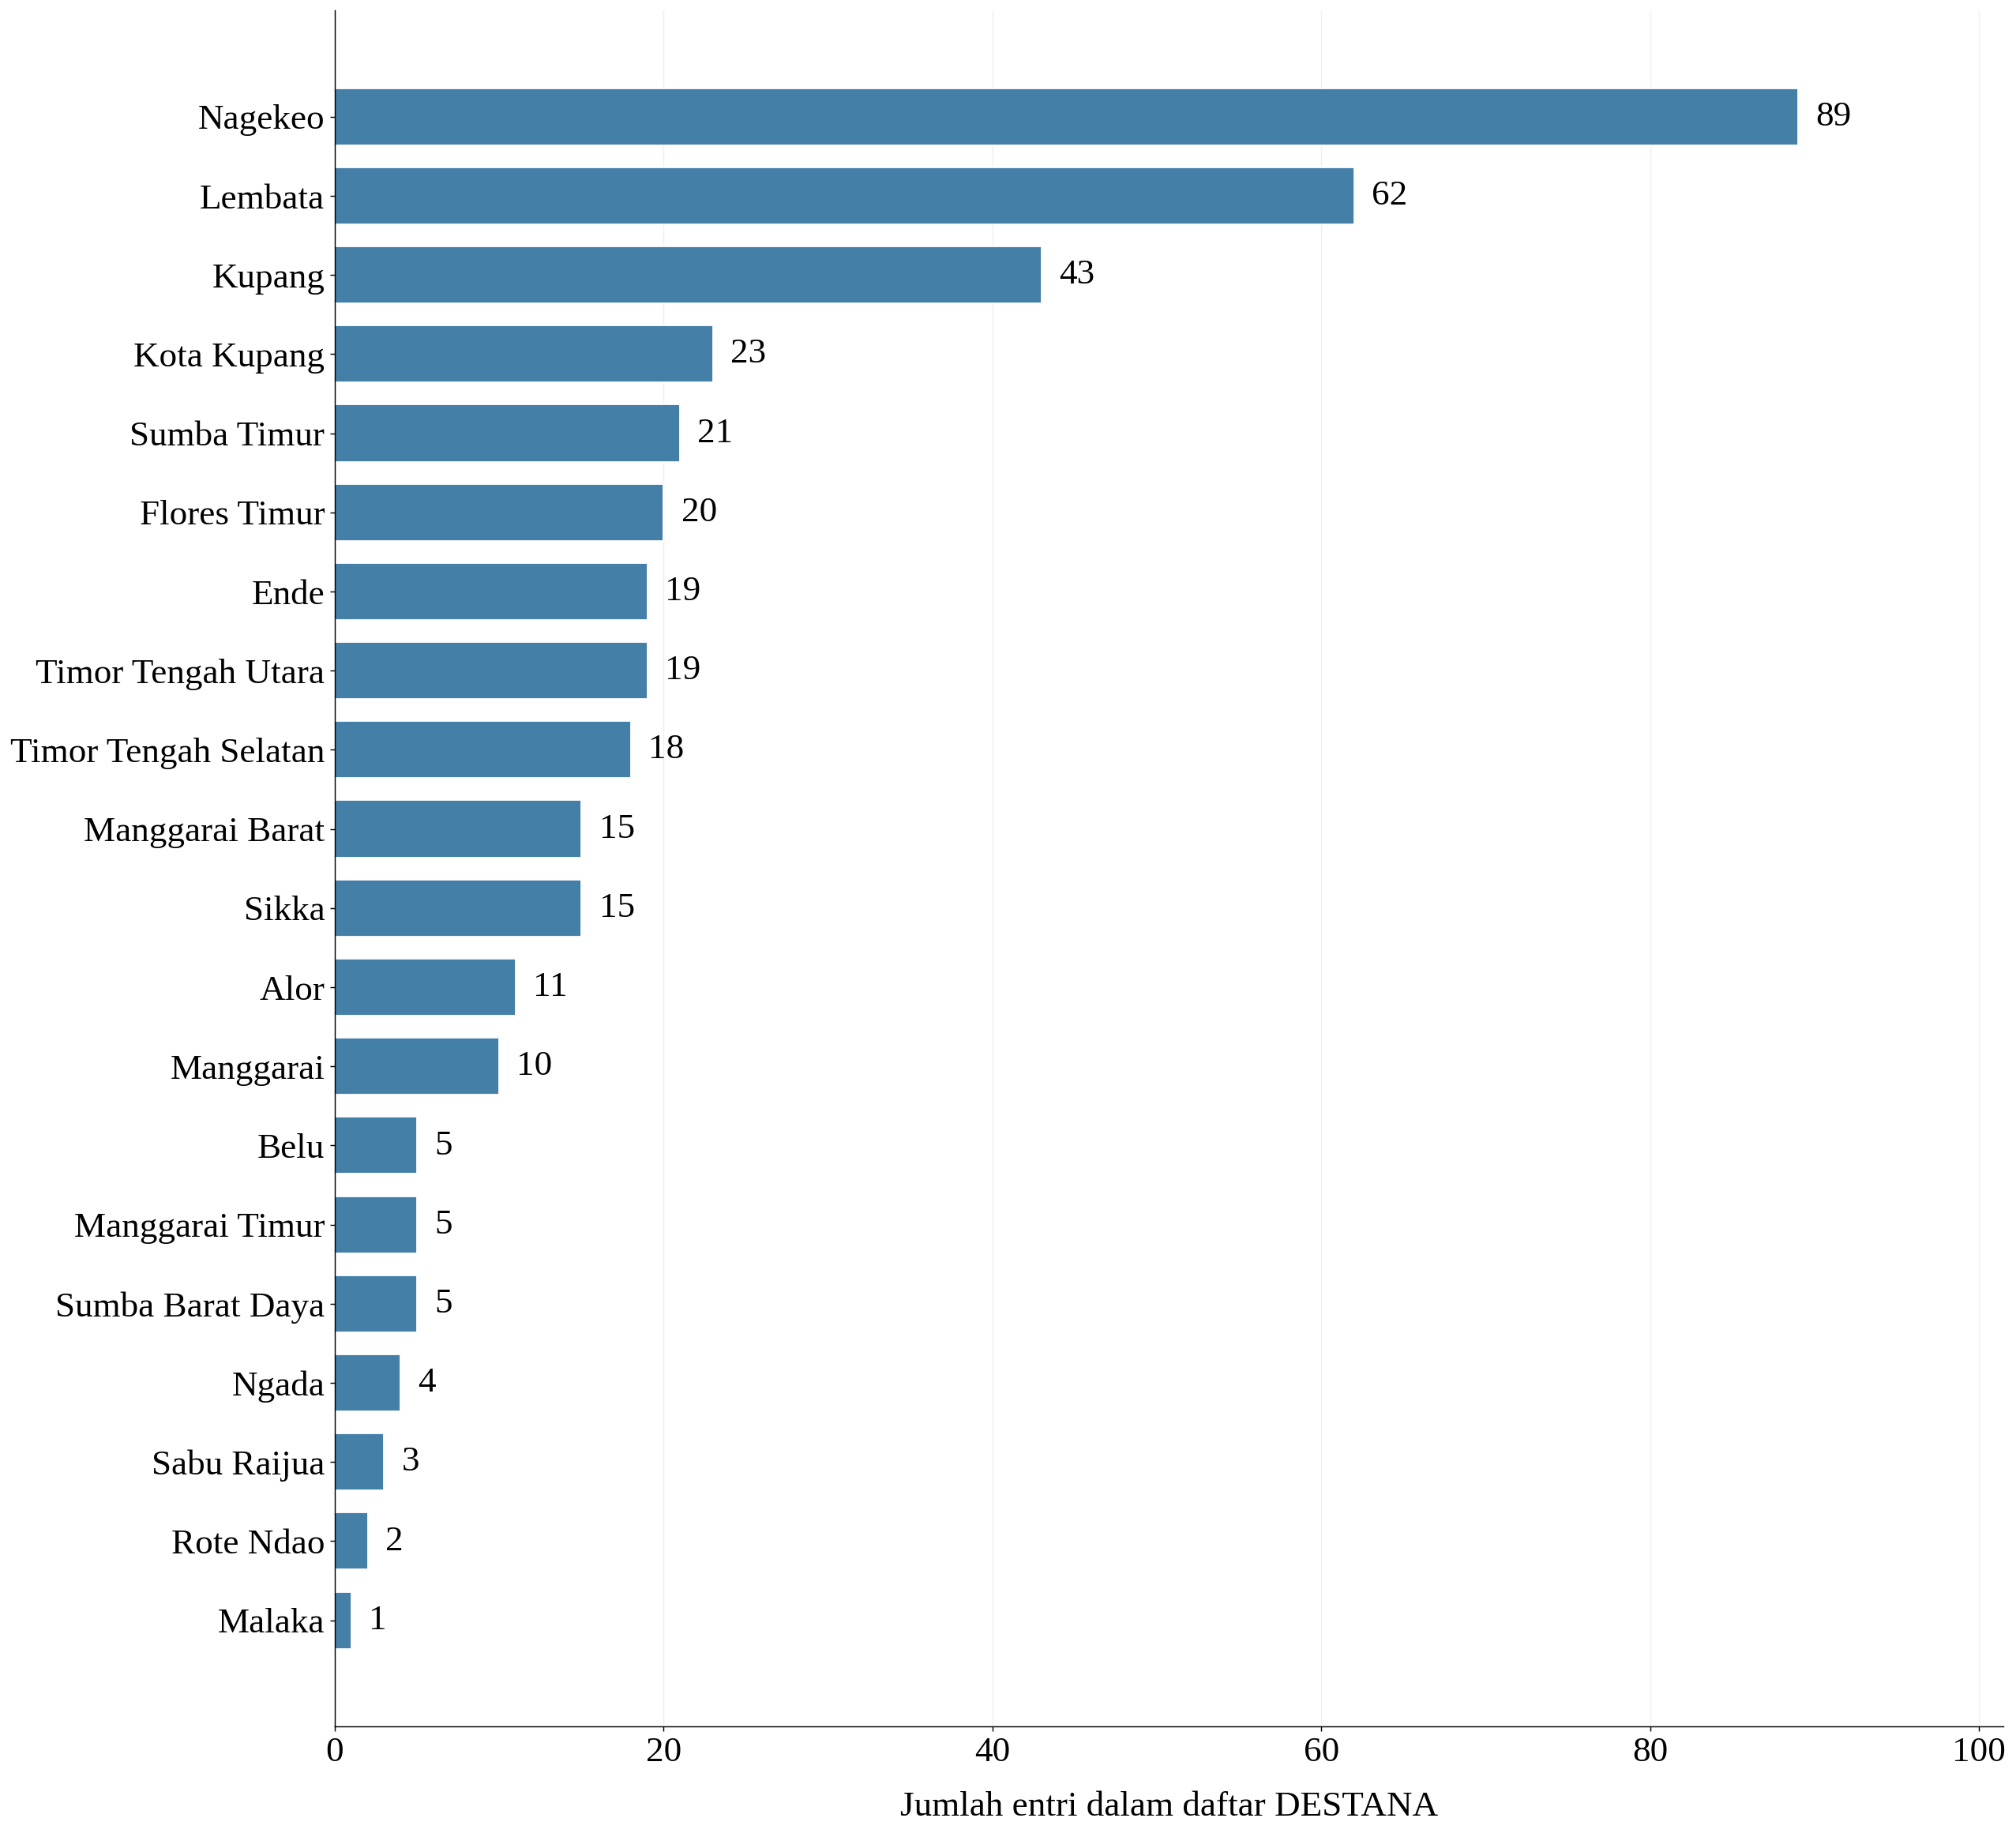


D.5 — VALIDASI
Jumlah wilayah: 22
Jumlah wilayah ditampilkan: 20
Tidak tercantum: ['Sumba Barat', 'Sumba Tengah']
Data mentah tidak dimodifikasi.


In [35]:

# ============================================================
# D.5.1 — DISTRIBUSI ENTRI DESTANA MENURUT WILAYAH
# Liberation Serif | Fontsize 25 | Tanpa judul
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({
    "font.family": "Liberation Serif",
    "font.size": 25,
    "axes.labelsize": 25,
    "xtick.labelsize": 25,
    "ytick.labelsize": 25
})

# ------------------------------------------------------------
# A. PERSIAPAN DATA
# ------------------------------------------------------------

kolom_destana = [
    "kabupaten_kota",
    "destana_entri_daftar_raw",
    "destana_ada_dalam_daftar_raw"
]

assert all(c in df_raw.columns for c in kolom_destana)

data_destana_d5 = df_raw[kolom_destana].copy()

data_destana_d5["jumlah_entri"] = pd.to_numeric(
    data_destana_d5["destana_entri_daftar_raw"],
    errors="coerce"
)

data_destana_d5["status"] = (
    data_destana_d5["destana_ada_dalam_daftar_raw"]
    .astype("string")
    .str.strip()
)

# Wilayah yang tercantum dalam daftar
destana_tercatat = (
    data_destana_d5.loc[
        (data_destana_d5["status"] == "Ya")
        & data_destana_d5["jumlah_entri"].notna()
    ]
    .sort_values("jumlah_entri", ascending=False)
    .copy()
)

# Wilayah tidak tercantum
destana_tidak_tercantum = data_destana_d5.loc[
    data_destana_d5["status"] == "Tidak tercantum",
    "kabupaten_kota"
].tolist()

# ------------------------------------------------------------
# B. VALIDASI CAKUPAN
# ------------------------------------------------------------

print("D.5 — RINGKASAN DESTANA")

print("Jumlah seluruh wilayah:", len(data_destana_d5))
print("Wilayah dengan entri:", len(destana_tercatat))
print(
    "Wilayah tidak tercantum:",
    len(destana_tidak_tercantum)
)

print("\nWilayah tidak tercantum:")
display(
    pd.DataFrame({
        "kabupaten_kota": destana_tidak_tercantum
    })
)

display(
    destana_tercatat[
        ["kabupaten_kota", "jumlah_entri"]
    ]
)

assert len(data_destana_d5) == 22
assert len(destana_tercatat) == 20
assert len(destana_tidak_tercantum) == 2

# ------------------------------------------------------------
# C. DIAGRAM BATANG HORIZONTAL
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(25, 19))

y = np.arange(len(destana_tercatat))
nilai = destana_tercatat["jumlah_entri"].to_numpy()

ax.barh(
    y,
    nilai,
    height=0.72,
    color="#447FA8",
    edgecolor="white"
)

ax.set_yticks(y)
ax.set_yticklabels(
    destana_tercatat["kabupaten_kota"],
    fontsize=25
)

ax.invert_yaxis()

# Label nilai
for i, v in enumerate(nilai):
    ax.text(
        v + max(nilai) * 0.012,
        i,
        f"{v:,.0f}".replace(",", "."),
        va="center",
        ha="left",
        fontsize=25
    )

ax.set_xlabel(
    "Jumlah entri dalam daftar DESTANA",
    fontsize=25,
    labelpad=16
)

ax.set_xlim(
    0,
    max(nilai) * 1.14
)

ax.grid(
    axis="x",
    alpha=0.18
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="both",
    labelsize=25
)

fig.subplots_adjust(
    left=0.32,
    right=0.97,
    top=0.98,
    bottom=0.10
)

plt.show()

# ------------------------------------------------------------
# D. VALIDASI AKHIR
# ------------------------------------------------------------

print("\nD.5 — VALIDASI")
print("Jumlah wilayah:", len(data_destana_d5))
print("Jumlah wilayah ditampilkan:", len(destana_tercatat))
print("Tidak tercantum:", destana_tidak_tercantum)
print("Data mentah tidak dimodifikasi.")


## Visualisasi Diagnostik ACeBS

,count
status,
Data lengkap,6
Sebagian tersedia,0
Tidak tersedia,16


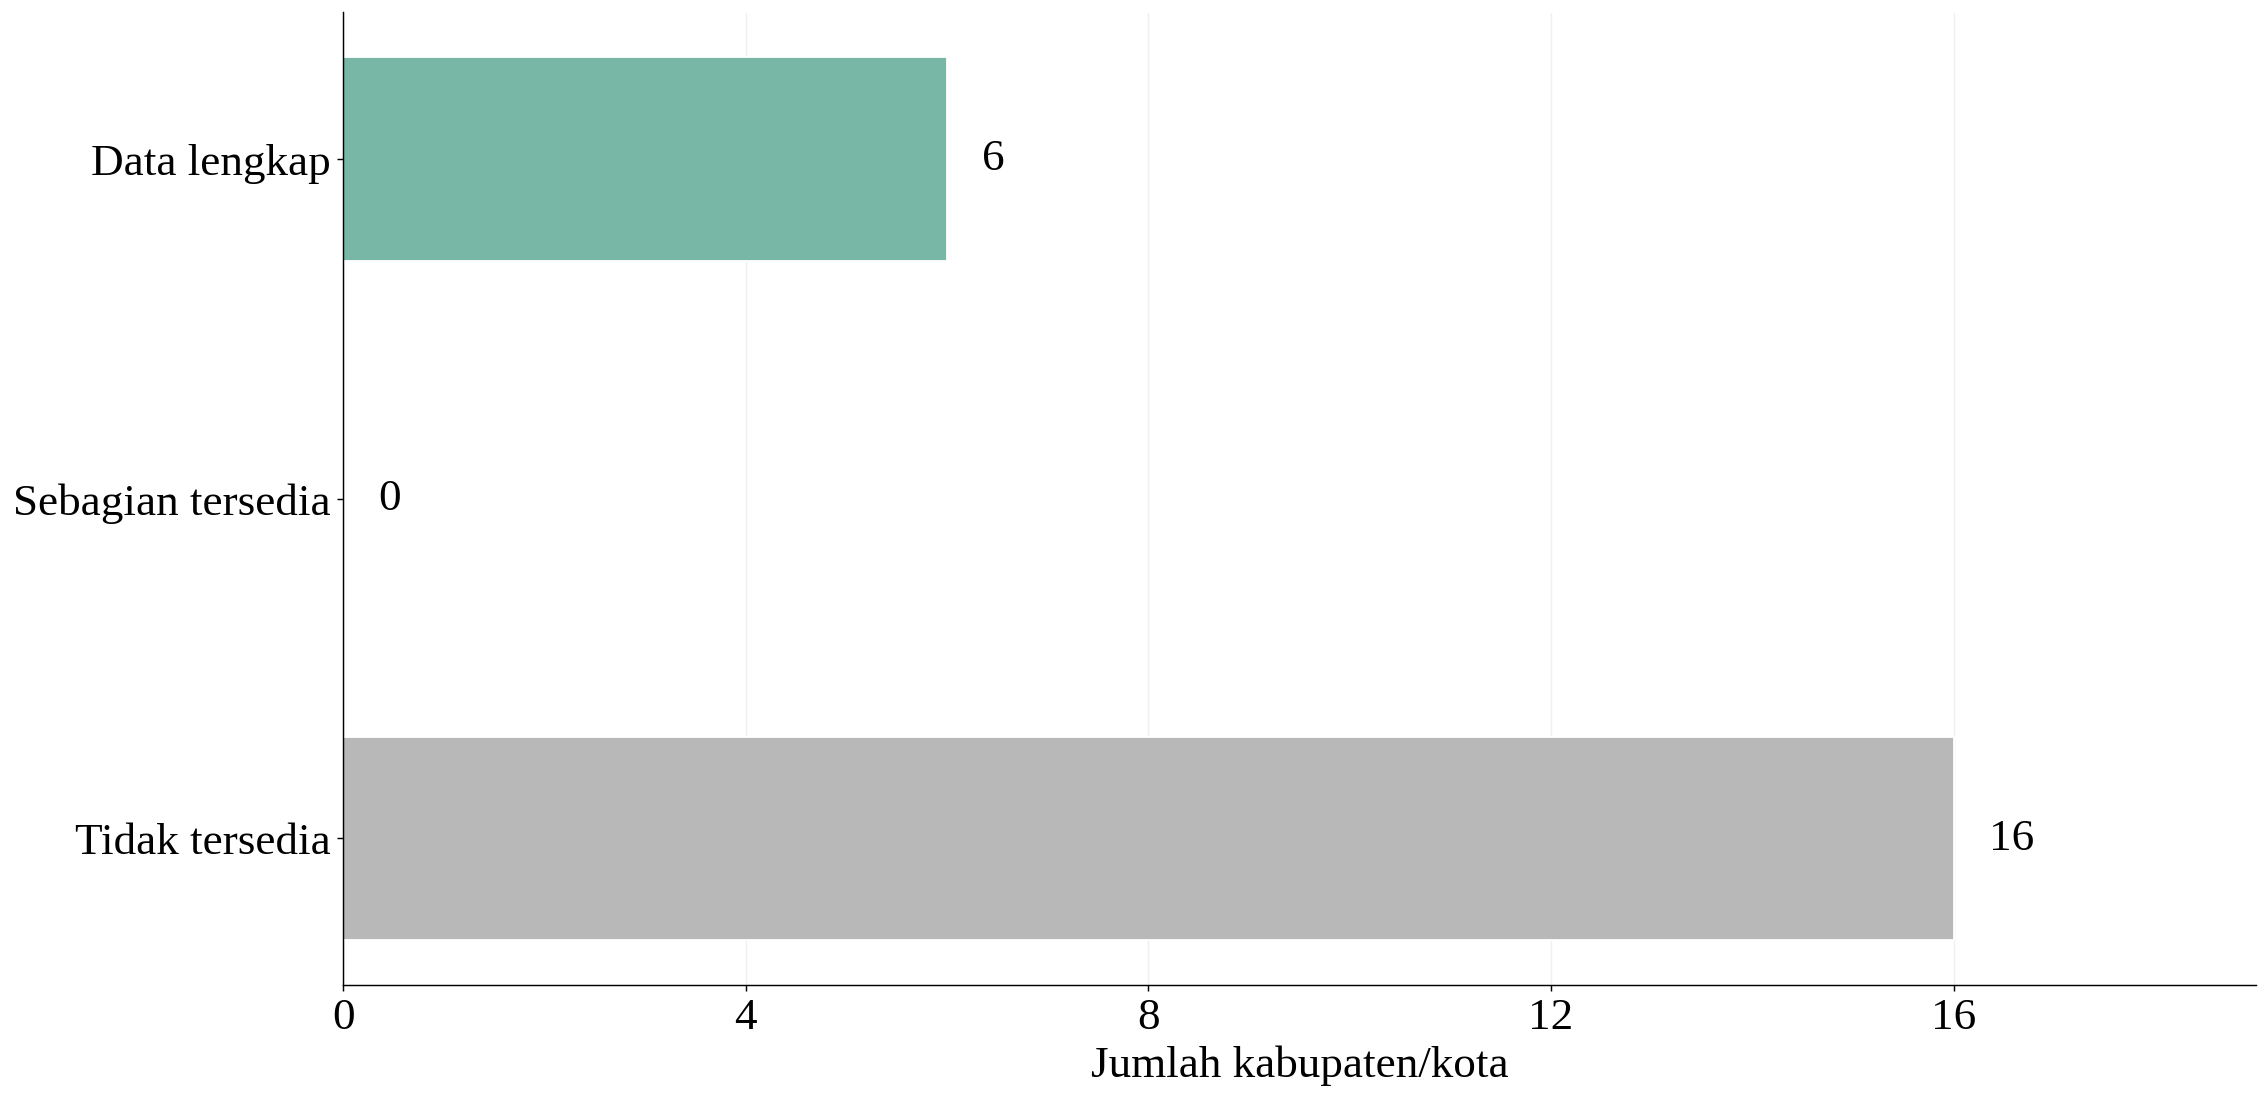

Wilayah dengan data ACeBS lengkap:


,kabupaten_kota,acebs_rendah_raw,acebs_sedang_raw,acebs_tinggi_raw,acebs_total_raw
10,Ende,0.0,1.0,0.0,1.0
11,Ngada,7.0,3.0,53.0,63.0
13,Rote Ndao,1.0,1.0,1.0,3.0
14,Manggarai Barat,9.0,0.0,1.0,10.0
18,Manggarai Timur,2.0,4.0,55.0,61.0
21,Kota Kupang,1.0,0.0,0.0,1.0


Data mentah tidak dimodifikasi.


In [36]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({
    "font.family": "Liberation Serif",
    "font.size": 25,
    "axes.labelsize": 25,
    "xtick.labelsize": 25,
    "ytick.labelsize": 25,
    "legend.fontsize": 25
})

# Data ACeBS dari master dataset
kolom_acebs = [
    "acebs_rendah_raw",
    "acebs_sedang_raw",
    "acebs_tinggi_raw",
    "acebs_total_raw"
]

assert all(c in df_raw.columns for c in kolom_acebs)

data_acebs_d6 = df_raw[
    ["kabupaten_kota"] + kolom_acebs
].copy()

data_acebs_d6[kolom_acebs] = (
    data_acebs_d6[kolom_acebs]
    .apply(pd.to_numeric, errors="coerce")
)

data_acebs_d6["jumlah_valid"] = (
    data_acebs_d6[kolom_acebs].notna().sum(axis=1)
)

# Bedakan data lengkap, parsial, dan tidak tersedia
data_acebs_d6["status"] = np.select(
    [
        data_acebs_d6["jumlah_valid"] == 4,
        data_acebs_d6["jumlah_valid"] == 0
    ],
    [
        "Data lengkap",
        "Tidak tersedia"
    ],
    default="Sebagian tersedia"
)

ringkasan_cakupan_d6 = (
    data_acebs_d6["status"]
    .value_counts()
    .reindex(
        ["Data lengkap", "Sebagian tersedia", "Tidak tersedia"],
        fill_value=0
    )
)

display(ringkasan_cakupan_d6)

fig, ax = plt.subplots(figsize=(18, 9))

status = ringkasan_cakupan_d6.index.tolist()
nilai = ringkasan_cakupan_d6.to_numpy()

warna = ["#78B6A5", "#E9B45A", "#B8B8B8"]

bars = ax.barh(
    status, nilai,
    height=0.60,
    color=warna,
    edgecolor="white"
)

for bar, v in zip(bars, nilai):
    ax.text(
        v + 0.35,
        bar.get_y() + bar.get_height()/2,
        f"{v}",
        va="center",
        fontsize=25
    )

ax.invert_yaxis()
ax.set_xlabel("Jumlah kabupaten/kota")
ax.set_xlim(0, 19)
ax.set_xticks([0, 4, 8, 12, 16])
ax.grid(axis="x", alpha=0.18)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

print("Wilayah dengan data ACeBS lengkap:")
display(
    data_acebs_d6.loc[
        data_acebs_d6["status"] == "Data lengkap",
        ["kabupaten_kota"] + kolom_acebs
    ]
)

print("Data mentah tidak dimodifikasi.")


D.6.2 — PEMERIKSAAN KOMPONEN DAN TOTAL


,kabupaten_kota,acebs_rendah_raw,acebs_sedang_raw,acebs_tinggi_raw,acebs_total_raw,jumlah_komponen,selisih_total
10,Ende,0.0,1.0,0.0,1.0,1.0,0.0
11,Ngada,7.0,3.0,53.0,63.0,63.0,0.0
13,Rote Ndao,1.0,1.0,1.0,3.0,3.0,0.0
14,Manggarai Barat,9.0,0.0,1.0,10.0,10.0,0.0
18,Manggarai Timur,2.0,4.0,55.0,61.0,61.0,0.0
21,Kota Kupang,1.0,0.0,0.0,1.0,1.0,0.0


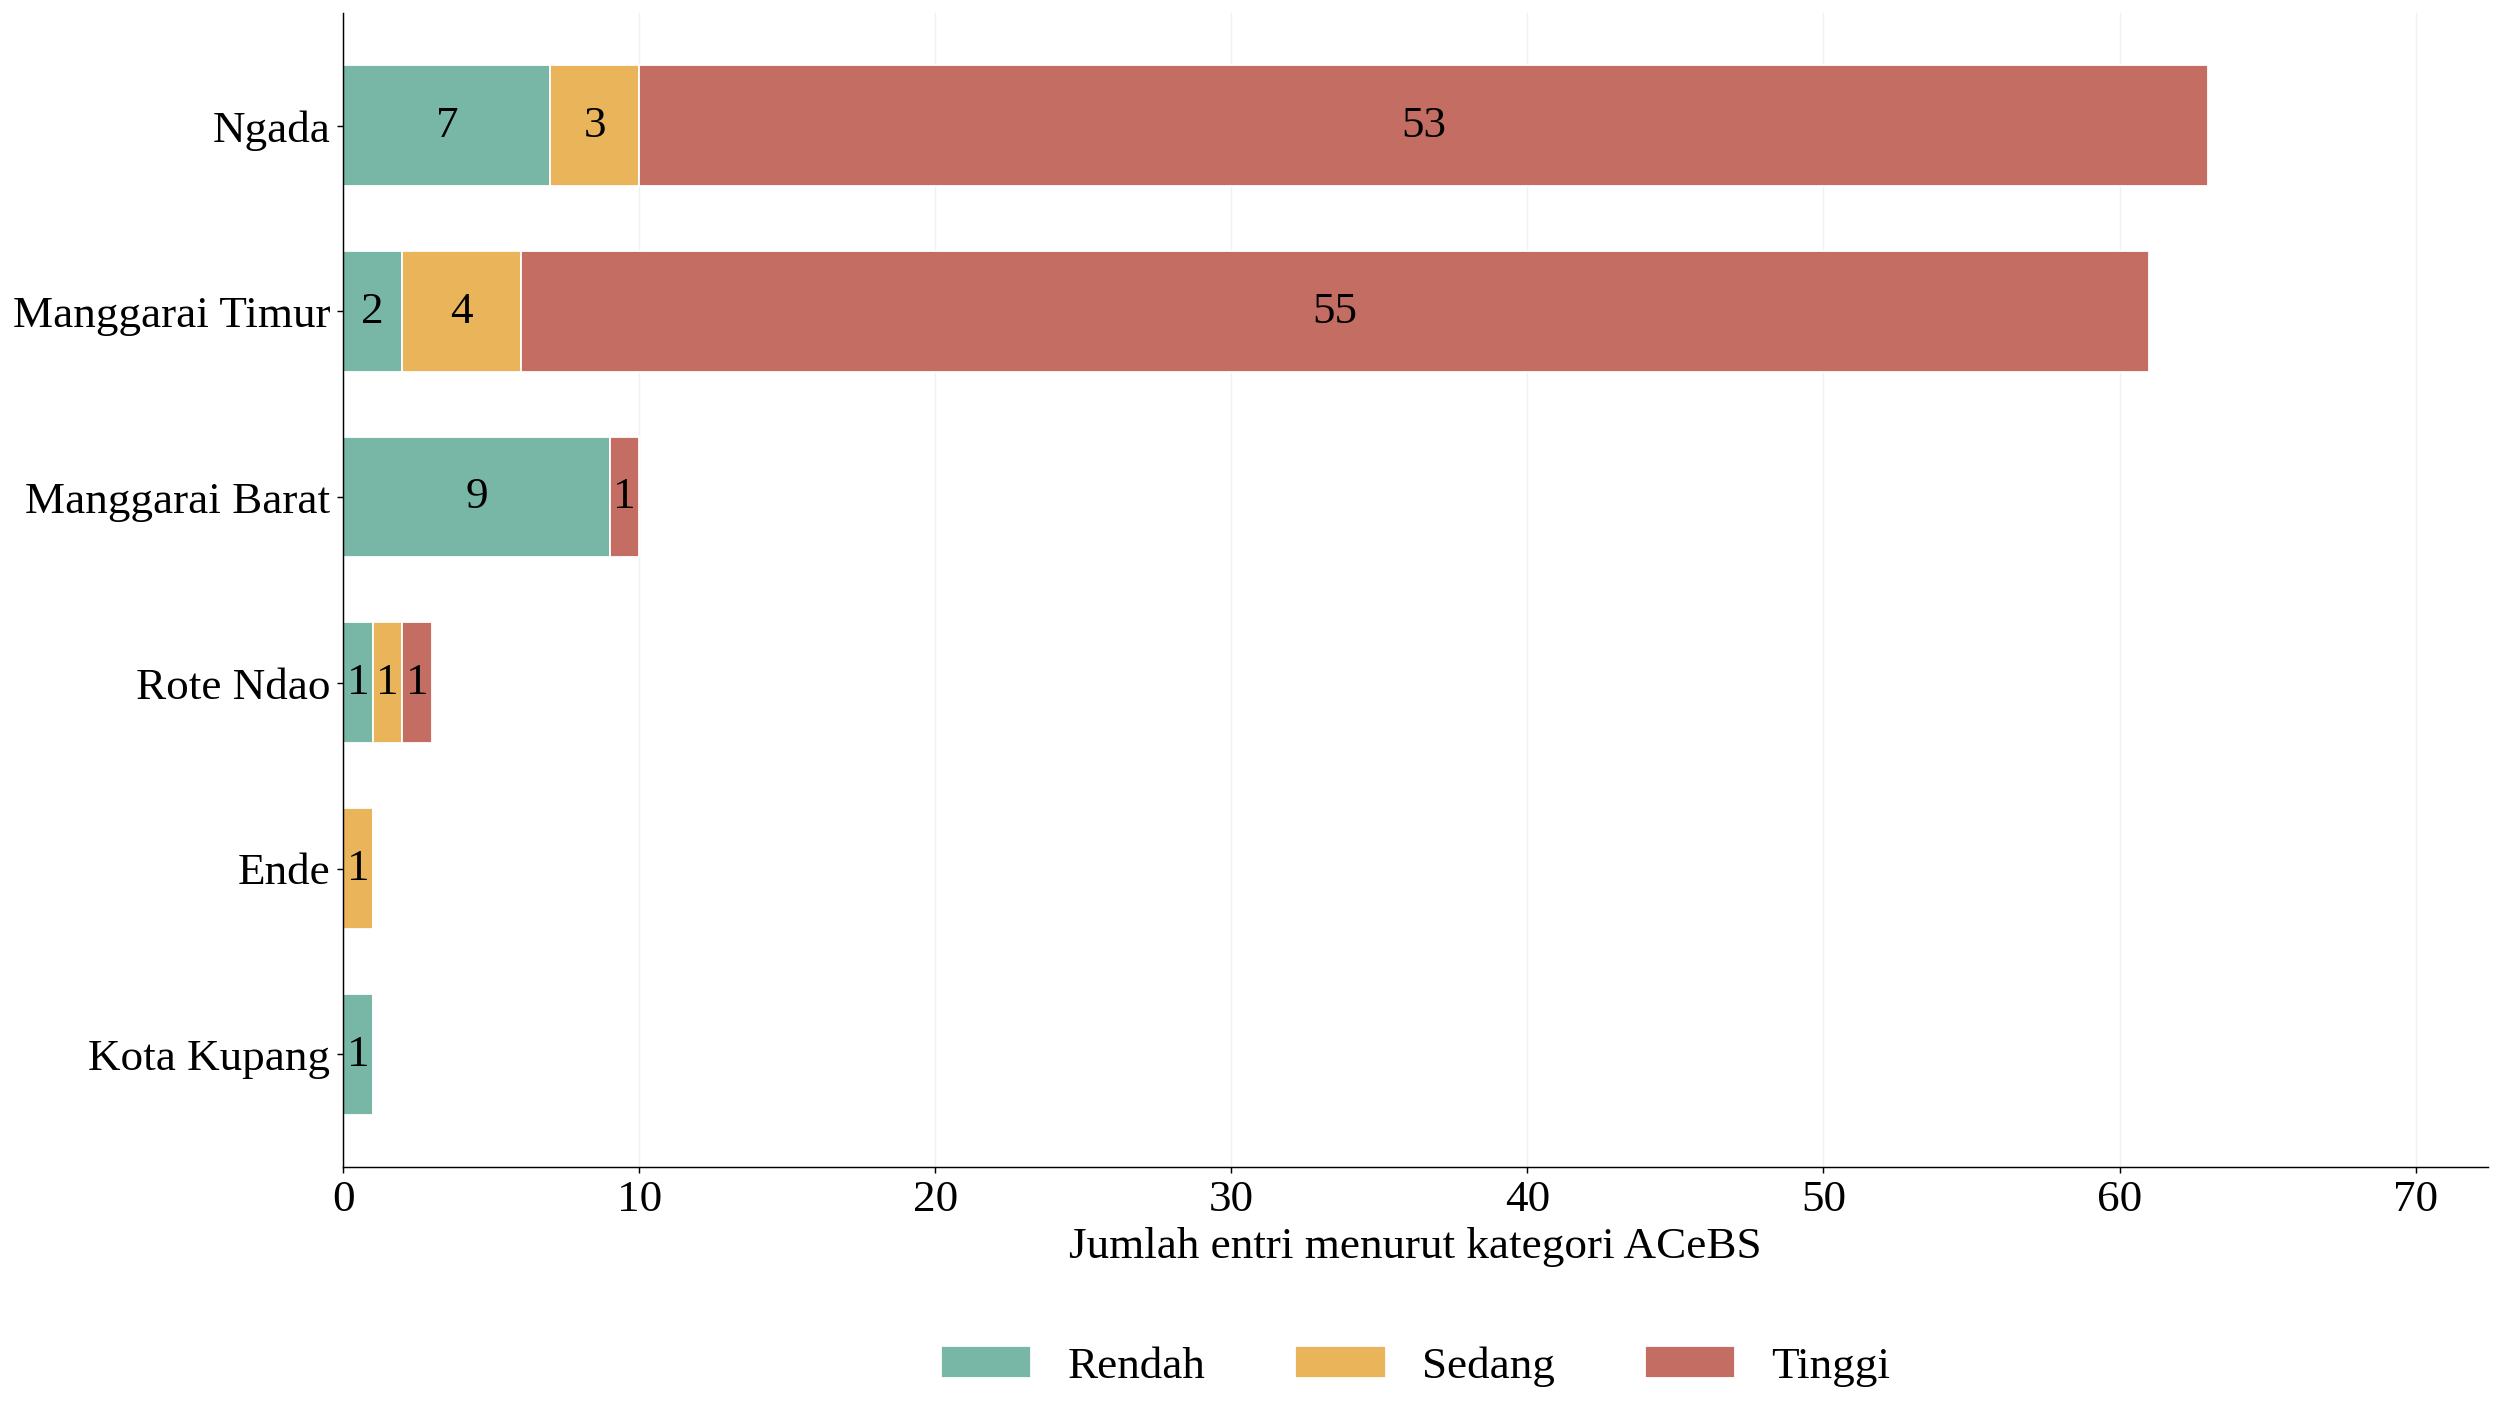

Jumlah wilayah dianalisis: 6
Data mentah tidak dimodifikasi.


In [37]:

# =====================================================
# D.6.2 — DISTRIBUSI KATEGORI ACEBS
# =====================================================

acebs_valid = data_acebs_d6.loc[
    data_acebs_d6["status"] == "Data lengkap"
].copy()

kategori_acebs = [
    "acebs_rendah_raw",
    "acebs_sedang_raw",
    "acebs_tinggi_raw"
]

# Pemeriksaan konsistensi total
acebs_valid["jumlah_komponen"] = (
    acebs_valid[kategori_acebs].sum(axis=1)
)

acebs_valid["selisih_total"] = (
    acebs_valid["jumlah_komponen"]
    - acebs_valid["acebs_total_raw"]
)

print("D.6.2 — PEMERIKSAAN KOMPONEN DAN TOTAL")

display(
    acebs_valid[
        [
            "kabupaten_kota",
            *kategori_acebs,
            "acebs_total_raw",
            "jumlah_komponen",
            "selisih_total"
        ]
    ]
)

# Jangan membuat stacked bar jika komponen
# tidak konsisten atau nilai negatif
if not np.allclose(
    acebs_valid["selisih_total"], 0, atol=1e-8
):
    raise ValueError(
        "Komponen ACeBS tidak sama dengan total. "
        "Definisi kategori perlu diperiksa."
    )

if (acebs_valid[kategori_acebs] < 0).any().any():
    raise ValueError("Ditemukan nilai negatif ACeBS.")

# Urutkan berdasarkan total
acebs_valid = acebs_valid.sort_values(
    "acebs_total_raw",
    ascending=False
)

fig, ax = plt.subplots(figsize=(25, 12))

y = np.arange(len(acebs_valid))
dasar = np.zeros(len(acebs_valid))

warna = {
    "acebs_rendah_raw": "#78B6A5",
    "acebs_sedang_raw": "#E9B45A",
    "acebs_tinggi_raw": "#C46D63"
}

label = {
    "acebs_rendah_raw": "Rendah",
    "acebs_sedang_raw": "Sedang",
    "acebs_tinggi_raw": "Tinggi"
}

for kolom in kategori_acebs:
    nilai = acebs_valid[kolom].to_numpy(dtype=float)

    ax.barh(
        y,
        nilai,
        left=dasar,
        height=0.65,
        color=warna[kolom],
        edgecolor="white",
        label=label[kolom]
    )

    for i, v in enumerate(nilai):
        if v > 0:
            ax.text(
                dasar[i] + v / 2,
                i,
                f"{v:.0f}",
                ha="center",
                va="center",
                fontsize=25
            )

    dasar += nilai

ax.set_yticks(y)
ax.set_yticklabels(
    acebs_valid["kabupaten_kota"]
)
ax.invert_yaxis()

ax.set_xlabel("Jumlah entri menurut kategori ACeBS")
ax.set_xlim(
    0,
    max(acebs_valid["acebs_total_raw"].max() * 1.15, 1)
)

ax.grid(axis="x", alpha=0.18)
ax.set_axisbelow(True)

ax.legend(
    ncol=3,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.subplots_adjust(
    left=0.30,
    right=0.96,
    top=0.97,
    bottom=0.23
)

plt.show()

print("Jumlah wilayah dianalisis:", len(acebs_valid))
print("Data mentah tidak dimodifikasi.")


# 2. PREPROCESSING

## Rekonsiliasi BPS dan KRB

### bps

In [58]:
import pandas as pd
import numpy as np
from IPython.display import display

# ============================================================
# E.1 — REKONSILIASI BPS
# ============================================================

df_tahap1 = df_raw.copy(deep=True)

# Rujukan: BPS NTT, Podes 2024
# Jumlah desa/kelurahan menurut kabupaten/kota, 2024

rujukan_desa_2024 = {
    "Sumba Barat": 74,
    "Sumba Timur": 200,
    "Kupang": 177,
    "Timor Tengah Selatan": 278,
    "Timor Tengah Utara": 193,
    "Belu": 81,
    "Alor": 175,
    "Lembata": 151,
    "Flores Timur": 250,
    "Sikka": 194,
    "Ende": 278,
    "Ngada": 206,
    "Manggarai": 223,
    "Rote Ndao": 119,
    "Manggarai Barat": 169,
    "Sumba Tengah": 65,
    "Sumba Barat Daya": 175,
    "Nagekeo": 113,
    "Manggarai Timur": 176,
    "Sabu Raijua": 63,
    "Malaka": 127,
    "Kota Kupang": 51
}

assert len(rujukan_desa_2024) == 22
assert sum(rujukan_desa_2024.values()) == 3538

kol = "bps_jumlah_desa_2024"

cek_bps = df_raw[["kabupaten_kota", kol]].copy()
cek_bps["nilai_master"] = pd.to_numeric(
    cek_bps[kol], errors="coerce"
)
cek_bps["nilai_rujukan"] = (
    cek_bps["kabupaten_kota"].map(rujukan_desa_2024)
)
cek_bps["selisih"] = (
    cek_bps["nilai_master"] - cek_bps["nilai_rujukan"]
)

assert cek_bps["nilai_rujukan"].notna().all()
assert cek_bps["nilai_master"].notna().all()

temuan = cek_bps.loc[
    cek_bps["selisih"] != 0,
    ["kabupaten_kota", "nilai_master",
     "nilai_rujukan", "selisih"]
].copy()

print("E.1.A — KETIDAKSESUAIAN DENGAN BPS 2024")
display(temuan)

# Hanya dua kasus yang sudah diverifikasi
koreksi = {
    "Sumba Timur": (156, 200),
    "Manggarai": (171, 223)
}

assert set(temuan["kabupaten_kota"]) == set(koreksi)

log_koreksi_bps = []

for wilayah, (nilai_lama, nilai_baru) in koreksi.items():

    mask = df_tahap1["kabupaten_kota"].eq(wilayah)
    assert mask.sum() == 1

    nilai_asli = float(df_tahap1.loc[mask, kol].iloc[0])
    assert np.isclose(nilai_asli, nilai_lama)

    df_tahap1.loc[mask, kol] = nilai_baru

    log_koreksi_bps.append({
        "kabupaten_kota": wilayah,
        "peubah": kol,
        "nilai_asli": nilai_lama,
        "nilai_baru": nilai_baru,
        "alasan": "Rekonsiliasi BPS Podes 2024",
        "status": "Dikoreksi pada salinan"
    })

log_koreksi_bps = pd.DataFrame(log_koreksi_bps)

print("\nE.1.B — LOG KOREKSI")
display(log_koreksi_bps)

print("\nE.1.C — VALIDASI")
print(
    "Total desa 2024 sebelum:",
    pd.to_numeric(df_raw[kol], errors="coerce").sum()
)
print(
    "Total desa 2024 sesudah:",
    pd.to_numeric(df_tahap1[kol], errors="coerce").sum()
)
print(
    "Total desa 2025:",
    pd.to_numeric(
        df_tahap1["bps_jumlah_desa_2025"],
        errors="coerce"
    ).sum()
)

assert pd.to_numeric(df_tahap1[kol]).sum() == 3538
assert df_raw.loc[
    df_raw["kabupaten_kota"].eq("Manggarai"), kol
].iloc[0] == 171

print("Data asli tetap tidak berubah.")

E.1.A — KETIDAKSESUAIAN DENGAN BPS 2024


,kabupaten_kota,nilai_master,nilai_rujukan,selisih
1,Sumba Timur,156,200,-44
12,Manggarai,171,223,-52



E.1.B — LOG KOREKSI


,kabupaten_kota,peubah,nilai_asli,nilai_baru,alasan,status
0,Sumba Timur,bps_jumlah_desa_2024,156,200,Rekonsiliasi BPS Podes 2024,Dikoreksi pada salinan
1,Manggarai,bps_jumlah_desa_2024,171,223,Rekonsiliasi BPS Podes 2024,Dikoreksi pada salinan



E.1.C — VALIDASI
Total desa 2024 sebelum: 3442
Total desa 2024 sesudah: 3538
Total desa 2025: 3538
Data asli tetap tidak berubah.


In [59]:
# ============================================================
# E.2 — VALIDASI LANJUTAN BPS
# ============================================================

# A. Konsistensi jumlah desa dengan indikator disabilitas
kol_disabilitas = [
    c for c in df_tahap1.columns
    if c.startswith("bps_desa_ada_")
    and c.endswith("_2024")
]

temuan_disabilitas = []

penyebut = pd.to_numeric(
    df_tahap1["bps_jumlah_desa_2024"],
    errors="coerce"
)

for c in kol_disabilitas:
    pembilang = pd.to_numeric(
        df_tahap1[c], errors="coerce"
    )

    mask = pembilang > penyebut

    for i in df_tahap1.index[mask]:
        temuan_disabilitas.append({
            "kabupaten_kota": df_tahap1.loc[i, "kabupaten_kota"],
            "peubah": c,
            "jumlah_tercatat": pembilang.loc[i],
            "jumlah_desa_2024": penyebut.loc[i]
        })

print("E.2.A — ANOMALI DISABILITAS TERSISA")
display(pd.DataFrame(temuan_disabilitas))

# B. Peubah kemiskinan September tanpa data
kol_september = [
    "bps_garis_kemiskinan_september_2025_rp",
    "bps_penduduk_miskin_september_2025_ribu",
    "bps_persen_miskin_september_2025"
]

status_september = pd.DataFrame({
    "peubah": kol_september,
    "n_valid": [
        pd.to_numeric(
            df_tahap1[c], errors="coerce"
        ).notna().sum()
        for c in kol_september
    ]
})

status_september["keputusan"] = (
    "Tidak digunakan dalam matriks analisis"
)

print("\nE.2.B — STATUS BPS SEPTEMBER")
display(status_september)

# C. Nilai jalan provinsi yang masih perlu verifikasi
print("\nE.2.C — JALAN PROVINSI SUMBA BARAT DAYA")

display(
    df_tahap1.loc[
        df_tahap1["kabupaten_kota"].eq("Sumba Barat Daya"),
        ["kabupaten_kota", "bps_jalan_prov_baik_2025_km"]
    ]
)

E.2.A — ANOMALI DISABILITAS TERSISA


""



E.2.B — STATUS BPS SEPTEMBER


,peubah,n_valid,keputusan
0,bps_garis_kemiskinan_september_2025_rp,0,Tidak digunakan dalam matriks analisis
1,bps_penduduk_miskin_september_2025_ribu,0,Tidak digunakan dalam matriks analisis
2,bps_persen_miskin_september_2025,0,Tidak digunakan dalam matriks analisis



E.2.C — JALAN PROVINSI SUMBA BARAT DAYA


,kabupaten_kota,bps_jalan_prov_baik_2025_km
16,Sumba Barat Daya,-


### krb

In [60]:
# ============================================================
# E.3 — REKONSILIASI LUAS KRB
# ============================================================

jenis_bahaya = [
    "banjir",
    "banjir_bandang",
    "cuaca_ekstrem",
    "gelombang_abrasi",
    "gempa_bumi",
    "karhutla",
    "kekeringan",
    "letusan_gunung_api",
    "likuefaksi",
    "tanah_longsor",
    "tsunami"
]

luas_admin = pd.to_numeric(
    df_tahap1["bps_luas_daerah_2025_km2"],
    errors="coerce"
) * 100

hasil_rasio = []

for jenis in jenis_bahaya:

    kol_total = f"krb_{jenis}_total_ha"

    if kol_total not in df_tahap1.columns:
        raise KeyError(f"Peubah tidak ditemukan: {kol_total}")

    luas_bahaya = pd.to_numeric(
        df_tahap1[kol_total], errors="coerce"
    )

    rasio = luas_bahaya / luas_admin.where(luas_admin > 0)

    for i in df_tahap1.index:
        nilai_rasio = rasio.loc[i]

        if pd.isna(nilai_rasio):
            status = "Tidak dapat dihitung"
        elif nilai_rasio > 1.25:
            status = "Verifikasi prioritas"
        elif nilai_rasio > 1.05:
            status = "Periksa perbedaan batas/sumber"
        else:
            status = "Tidak terindikasi anomali rasio"

        hasil_rasio.append({
            "kabupaten_kota": df_tahap1.loc[i, "kabupaten_kota"],
            "jenis_bahaya": jenis,
            "luas_bahaya_ha": luas_bahaya.loc[i],
            "luas_admin_ha": luas_admin.loc[i],
            "rasio": nilai_rasio,
            "status": status
        })

hasil_rasio = pd.DataFrame(hasil_rasio)

print("E.3.A — KASUS RASIO KRB YANG PERLU DIPERIKSA")

kasus_krb = hasil_rasio.loc[
    hasil_rasio["rasio"] > 1.05
].sort_values("rasio", ascending=False)

display(kasus_krb)

print("\nE.3.B — KASUS PRIORITAS")

prioritas_krb = hasil_rasio.loc[
    hasil_rasio["rasio"] > 1.25
].copy()

display(prioritas_krb)

print("\nE.3.C — CAKUPAN PER JENIS BAHAYA")

cakupan_krb = (
    hasil_rasio
    .groupby("jenis_bahaya")
    .agg(
        n_valid=("rasio", "count"),
        n_anomali_prioritas=(
            "rasio", lambda x: (x > 1.25).sum()
        )
    )
    .reset_index()
)

cakupan_krb["n_missing"] = (
    len(df_tahap1) - cakupan_krb["n_valid"]
)

display(cakupan_krb)

print("\nTidak ada nilai KRB yang diubah.")

E.3.A — KASUS RASIO KRB YANG PERLU DIPERIKSA


,kabupaten_kota,jenis_bahaya,luas_bahaya_ha,luas_admin_ha,rasio,status
21,Kota Kupang,banjir,52914.0,15889.0,3.330228,Verifikasi prioritas
4,Timor Tengah Utara,banjir,858812.0,262229.0,3.275046,Verifikasi prioritas
108,Malaka,gempa_bumi,117689.0,110900.0,1.061217,Periksa perbedaan batas/sumber
152,Malaka,kekeringan,117519.0,110900.0,1.059684,Periksa perbedaan batas/sumber
130,Malaka,karhutla,117494.0,110900.0,1.059459,Periksa perbedaan batas/sumber
105,Nagekeo,gempa_bumi,146825.0,139797.0,1.050273,Periksa perbedaan batas/sumber
127,Nagekeo,karhutla,146804.0,139797.0,1.050123,Periksa perbedaan batas/sumber



E.3.B — KASUS PRIORITAS


,kabupaten_kota,jenis_bahaya,luas_bahaya_ha,luas_admin_ha,rasio,status
4,Timor Tengah Utara,banjir,858812.0,262229.0,3.275046,Verifikasi prioritas
21,Kota Kupang,banjir,52914.0,15889.0,3.330228,Verifikasi prioritas



E.3.C — CAKUPAN PER JENIS BAHAYA


,jenis_bahaya,n_valid,n_anomali_prioritas,n_missing
0,banjir,21,2,1
1,banjir_bandang,21,0,1
2,cuaca_ekstrem,21,0,1
3,gelombang_abrasi,22,0,0
4,gempa_bumi,22,0,0
5,karhutla,22,0,0
6,kekeringan,22,0,0
7,letusan_gunung_api,10,0,12
8,likuefaksi,22,0,0
9,tanah_longsor,22,0,0



Tidak ada nilai KRB yang diubah.


### Pemeriksaan blok missing KRB dan penandaan anomali

In [61]:
# ============================================================
# E.4 — PEMERIKSAAN MISSING DAN ANOMALI KRB
# Menggunakan df_tahap1 dari E.1
# Tidak mengubah nilai asli KRB
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

jenis_bahaya = [
    "banjir", "banjir_bandang", "cuaca_ekstrem",
    "gelombang_abrasi", "gempa_bumi", "karhutla",
    "kekeringan", "letusan_gunung_api", "likuefaksi",
    "tanah_longsor", "tsunami"
]

def kelas_tidak_tersedia(x):
    if pd.isna(x):
        return True
    return str(x).strip().lower() in {
        "", "-", "nan", "none", "tidak tersedia"
    }

# E.4.A — Pemeriksaan kelengkapan blok
rekap_blok = []

for jenis in jenis_bahaya:
    kol_total = f"krb_{jenis}_total_ha"
    kol_kelas = f"krb_{jenis}_kelas"

    total = pd.to_numeric(
        df_tahap1[kol_total], errors="coerce"
    )

    for i in df_tahap1.index:
        total_hilang = pd.isna(total.loc[i])
        kelas_hilang = kelas_tidak_tersedia(
            df_tahap1.loc[i, kol_kelas]
        )

        if total_hilang and kelas_hilang:
            status = "Total dan kelas tidak tersedia"
        elif total_hilang or kelas_hilang:
            status = "Ketidaklengkapan parsial"
        else:
            status = "Total dan kelas tersedia"

        rekap_blok.append({
            "kabupaten_kota": df_tahap1.loc[i, "kabupaten_kota"],
            "jenis_bahaya": jenis,
            "status": status
        })

rekap_blok = pd.DataFrame(rekap_blok)

print("E.4.A — RINGKASAN STATUS BLOK KRB")
display(
    rekap_blok["status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="jumlah_blok")
)

print("\nE.4.B — WILAYAH DAN BAHAYA TIDAK LENGKAP")
blok_tidak_lengkap = rekap_blok.loc[
    rekap_blok["status"] != "Total dan kelas tersedia"
].copy()

display(blok_tidak_lengkap.reset_index(drop=True))

# E.4.C — Rincian komponen dua anomali banjir
kol_banjir = [
    "kabupaten_kota",
    "krb_banjir_rendah_ha",
    "krb_banjir_sedang_ha",
    "krb_banjir_tinggi_ha",
    "krb_banjir_total_ha",
    "krb_banjir_kelas",
    "bps_luas_daerah_2025_km2"
]

wilayah_prioritas = [
    "Kota Kupang",
    "Timor Tengah Utara"
]

print("\nE.4.C — RINCIAN ANOMALI BANJIR")

display(
    df_tahap1.loc[
        df_tahap1["kabupaten_kota"].isin(wilayah_prioritas),
        kol_banjir
    ].T
)

# E.4.D — Membuat penanda untuk preprocessing
df_tahap2 = df_tahap1.copy(deep=True)

rasio_banjir = pd.to_numeric(
    df_tahap2["krb_banjir_total_ha"],
    errors="coerce"
) / (
    pd.to_numeric(
        df_tahap2["bps_luas_daerah_2025_km2"],
        errors="coerce"
    ) * 100
)

df_tahap2["status_verifikasi_krb_banjir"] = np.select(
    [
        rasio_banjir.isna(),
        rasio_banjir > 1.25,
        rasio_banjir > 1.05
    ],
    [
        "Data tidak tersedia",
        "Verifikasi prioritas",
        "Periksa perbedaan sumber"
    ],
    default="Tidak terindikasi anomali rasio"
)

print("\nE.4.D — STATUS VERIFIKASI BANJIR")

display(
    df_tahap2[
        ["kabupaten_kota", "status_verifikasi_krb_banjir"]
    ].loc[
        df_tahap2["status_verifikasi_krb_banjir"]
        != "Tidak terindikasi anomali rasio"
    ]
)

# Validasi tidak ada perubahan nilai sumber
assert df_tahap1[
    "krb_banjir_total_ha"
].equals(df_tahap2["krb_banjir_total_ha"])

print("\nNilai KRB tidak dikoreksi.")
print("Status verifikasi telah ditambahkan.")
print("Dataset kerja sementara: df_tahap2")

E.4.A — RINGKASAN STATUS BLOK KRB


,status,jumlah_blok
0,Total dan kelas tersedia,227
1,Total dan kelas tidak tersedia,15



E.4.B — WILAYAH DAN BAHAYA TIDAK LENGKAP


,kabupaten_kota,jenis_bahaya,status
0,Sumba Barat,banjir,Total dan kelas tidak tersedia
1,Sumba Barat,banjir_bandang,Total dan kelas tidak tersedia
2,Manggarai,cuaca_ekstrem,Total dan kelas tidak tersedia
3,Sumba Barat,letusan_gunung_api,Total dan kelas tidak tersedia
4,Sumba Timur,letusan_gunung_api,Total dan kelas tidak tersedia
5,Kupang,letusan_gunung_api,Total dan kelas tidak tersedia
6,Timor Tengah Selatan,letusan_gunung_api,Total dan kelas tidak tersedia
7,Timor Tengah Utara,letusan_gunung_api,Total dan kelas tidak tersedia
8,Belu,letusan_gunung_api,Total dan kelas tidak tersedia
9,Rote Ndao,letusan_gunung_api,Total dan kelas tidak tersedia



E.4.C — RINCIAN ANOMALI BANJIR


,4,21
kabupaten_kota,Timor Tengah Utara,Kota Kupang
krb_banjir_rendah_ha,328416,43954
krb_banjir_sedang_ha,319487,8545
krb_banjir_tinggi_ha,210909,415
krb_banjir_total_ha,858812,52914
krb_banjir_kelas,Tinggi,Rendah
bps_luas_daerah_2025_km2,2622.29,158.89



E.4.D — STATUS VERIFIKASI BANJIR


,kabupaten_kota,status_verifikasi_krb_banjir
0,Sumba Barat,Data tidak tersedia
4,Timor Tengah Utara,Verifikasi prioritas
21,Kota Kupang,Verifikasi prioritas



Nilai KRB tidak dikoreksi.
Status verifikasi telah ditambahkan.
Dataset kerja sementara: df_tahap2


In [62]:
# ============================================================
# E.5 — FINALISASI STATUS KRB
# Tidak mengubah nilai sumber
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

df_tahap3 = df_tahap2.copy(deep=True)

# E.5.A — Perbarui status verifikasi banjir

kasus_terkonfirmasi = [
    "Timor Tengah Utara",
    "Kota Kupang"
]

df_tahap3.loc[
    df_tahap3["kabupaten_kota"].isin(kasus_terkonfirmasi),
    "status_verifikasi_krb_banjir"
] = "Sesuai dokumen KRB; anomali rasio spasial"

print("E.5.A — STATUS ANOMALI BANJIR")

display(
    df_tahap3.loc[
        df_tahap3["kabupaten_kota"].isin(
            ["Sumba Barat"] + kasus_terkonfirmasi
        ),
        ["kabupaten_kota", "status_verifikasi_krb_banjir"]
    ]
)

# E.5.B — Dokumentasi blok yang tidak tersedia
# Variabel blok_tidak_lengkap berasal dari E.4

log_missing_krb = blok_tidak_lengkap.copy()

log_missing_krb["hasil_verifikasi"] = (
    "Tidak tersedia pada tabel KRB sumber"
)

log_missing_krb["keputusan"] = (
    "Pertahankan NA; jangan imputasi otomatis"
)

print("\nE.5.B — LOG MISSING KRB")

display(log_missing_krb)

# E.5.C — Validasi nilai KRB tidak berubah

kol_krb = [
    c for c in df_tahap2.columns
    if c.startswith("krb_")
]

assert df_tahap2[kol_krb].equals(
    df_tahap3[kol_krb]
)

assert len(log_missing_krb) == 15
assert df_tahap3.shape[0] == 22

print("\nE.5.C — VALIDASI")
print("Jumlah wilayah:", len(df_tahap3))
print("Blok KRB tidak tersedia:", len(log_missing_krb))
print("Nilai KRB tetap tidak berubah.")
print("Dataset sementara: df_tahap3")

E.5.A — STATUS ANOMALI BANJIR


,kabupaten_kota,status_verifikasi_krb_banjir
0,Sumba Barat,Data tidak tersedia
4,Timor Tengah Utara,Sesuai dokumen KRB; anomali rasio spasial
21,Kota Kupang,Sesuai dokumen KRB; anomali rasio spasial



E.5.B — LOG MISSING KRB


,kabupaten_kota,jenis_bahaya,status,hasil_verifikasi,keputusan
0,Sumba Barat,banjir,Total dan kelas tidak tersedia,Tidak tersedia pada tabel KRB sumber,Pertahankan NA; jangan imputasi otomatis
22,Sumba Barat,banjir_bandang,Total dan kelas tidak tersedia,Tidak tersedia pada tabel KRB sumber,Pertahankan NA; jangan imputasi otomatis
56,Manggarai,cuaca_ekstrem,Total dan kelas tidak tersedia,Tidak tersedia pada tabel KRB sumber,Pertahankan NA; jangan imputasi otomatis
154,Sumba Barat,letusan_gunung_api,Total dan kelas tidak tersedia,Tidak tersedia pada tabel KRB sumber,Pertahankan NA; jangan imputasi otomatis
155,Sumba Timur,letusan_gunung_api,Total dan kelas tidak tersedia,Tidak tersedia pada tabel KRB sumber,Pertahankan NA; jangan imputasi otomatis
156,Kupang,letusan_gunung_api,Total dan kelas tidak tersedia,Tidak tersedia pada tabel KRB sumber,Pertahankan NA; jangan imputasi otomatis
157,Timor Tengah Selatan,letusan_gunung_api,Total dan kelas tidak tersedia,Tidak tersedia pada tabel KRB sumber,Pertahankan NA; jangan imputasi otomatis
158,Timor Tengah Utara,letusan_gunung_api,Total dan kelas tidak tersedia,Tidak tersedia pada tabel KRB sumber,Pertahankan NA; jangan imputasi otomatis
159,Belu,letusan_gunung_api,Total dan kelas tidak tersedia,Tidak tersedia pada tabel KRB sumber,Pertahankan NA; jangan imputasi otomatis
167,Rote Ndao,letusan_gunung_api,Total dan kelas tidak tersedia,Tidak tersedia pada tabel KRB sumber,Pertahankan NA; jangan imputasi otomatis



E.5.C — VALIDASI
Jumlah wilayah: 22
Blok KRB tidak tersedia: 15
Nilai KRB tetap tidak berubah.
Dataset sementara: df_tahap3


### Pemeriksaan akhir hasil preprocessing

In [83]:

# ============================================================
# E.6–E.7 — FINALISASI PREPROCESSING KEBENCANAAN NTT
#
# Input:
#   df_raw
#   df_tahap1
#   df_tahap2
#   df_tahap3
#   registrasi_final_a
#
# Output:
#   df_tahap4
#   log_perubahan_e6
#   df_preprocessing
#   df_e7
#
# Prinsip:
# - Master asli tidak diubah
# - Keputusan penanganan mengikuti audit per sel
# - Tidak ada imputasi otomatis
# - Tidak ada penghapusan wilayah atau pencilan
# - Tidak ada pemilihan fitur clustering
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display


# ============================================================
# E.6.A — VALIDASI OBJEK DAN STRUKTUR AWAL
# ============================================================

objek_wajib = [
    "df_raw",
    "df_tahap1",
    "df_tahap2",
    "df_tahap3",
    "registrasi_final_a"
]

belum_tersedia = [
    nama for nama in objek_wajib
    if nama not in globals()
]

if belum_tersedia:
    raise RuntimeError(
        "Objek preprocessing belum tersedia: "
        + ", ".join(belum_tersedia)
    )

kol_master = df_raw.columns.tolist()

assert df_raw.shape == (22, 197)
assert df_tahap1.shape == (22, 197)
assert df_tahap2.shape == (22, 198)
assert df_tahap3.shape == (22, 198)

assert len(kol_master) == 197
assert len(set(kol_master)) == 197

assert df_tahap2.columns.equals(df_tahap3.columns)

kolom_tambahan = (
    set(df_tahap3.columns) - set(kol_master)
)

assert kolom_tambahan == {
    "status_verifikasi_krb_banjir"
}

assert set(kol_master).issubset(df_tahap3.columns)

for nama, data in [
    ("df_raw", df_raw),
    ("df_tahap1", df_tahap1),
    ("df_tahap2", df_tahap2),
    ("df_tahap3", df_tahap3)
]:
    assert data["kabupaten_kota"].notna().all(), nama
    assert data["kabupaten_kota"].is_unique, nama

    assert set(data["kabupaten_kota"]) == set(
        df_raw["kabupaten_kota"]
    ), nama

# Koreksi jumlah desa BPS dari E.1
koreksi_bps = {
    "Sumba Timur": (156, 200),
    "Manggarai": (171, 223)
}

for wilayah, (nilai_lama, nilai_baru) in koreksi_bps.items():

    nilai_raw = df_raw.set_index(
        "kabupaten_kota"
    ).at[wilayah, "bps_jumlah_desa_2024"]

    nilai_e5 = df_tahap3.set_index(
        "kabupaten_kota"
    ).at[wilayah, "bps_jumlah_desa_2024"]

    assert float(nilai_raw) == nilai_lama
    assert float(nilai_e5) == nilai_baru

print("E.6.A — VALIDASI STRUKTUR BERHASIL")

display(pd.DataFrame([
    {
        "objek": nama,
        "jumlah_wilayah": len(data),
        "jumlah_peubah": data.shape[1]
    }
    for nama, data in [
        ("df_raw", df_raw),
        ("df_tahap1", df_tahap1),
        ("df_tahap2", df_tahap2),
        ("df_tahap3", df_tahap3)
    ]
]))


# ============================================================
# E.6.B — PENERAPAN KEPUTUSAN AUDIT PER SEL
# ============================================================

audit = registrasi_final_a.copy(deep=True)

kolom_audit_wajib = {
    "kabupaten_kota",
    "sumber",
    "peubah",
    "keputusan"
}

assert kolom_audit_wajib.issubset(audit.columns)

assert not audit[
    ["kabupaten_kota", "peubah"]
].isna().any().any()

assert not audit.duplicated(
    subset=["kabupaten_kota", "peubah"]
).any()

keputusan = audit["keputusan"].astype(
    "string"
).str.strip()

assert keputusan.notna().all()

mask_nol = keputusan.str.startswith(
    "Nol:", na=False
)

mask_na = keputusan.str.startswith(
    "NA:", na=False
)

mask_tunda = keputusan.str.startswith(
    "Tunda:", na=False
)

mask_pertahankan = keputusan.str.startswith(
    "Pertahankan:", na=False
)

assert (
    mask_nol |
    mask_na |
    mask_tunda |
    mask_pertahankan
).all(), (
    "Terdapat keputusan audit yang belum dikenali."
)

# Memastikan keputusan audit tidak berubah
assert int(mask_nol.sum()) == 133
assert int(mask_na.sum()) == 207
assert int(mask_tunda.sum()) == 1
assert int(mask_pertahankan.sum()) == 2

audit_nol_sumber = (
    audit.loc[mask_nol, "sumber"]
    .value_counts()
    .to_dict()
)

assert audit_nol_sumber == {
    "BPS": 37,
    "KRB": 96
}

# Membentuk salinan dari hasil E.5
df_tahap4 = df_tahap3.copy(deep=True)

data = df_tahap4.set_index(
    "kabupaten_kota"
).copy()

penanda_missing = {
    "-", "–", "—", "...", "…", ""
}

def adalah_penanda(x):
    return (
        isinstance(x, str)
        and x.strip() in penanda_missing
    )

jumlah_diterapkan_nol = 0
jumlah_diterapkan_na = 0

for idx, baris in audit.iterrows():

    wilayah = baris["kabupaten_kota"]
    kolom = baris["peubah"]

    if wilayah not in data.index:
        raise ValueError(
            f"Wilayah tidak ditemukan: {wilayah}"
        )

    if kolom not in data.columns:
        raise ValueError(
            f"Peubah tidak ditemukan: {kolom}"
        )

    # Keputusan mempertahankan kategori
    if mask_pertahankan.loc[idx]:
        continue

    nilai_sebelum = data.at[wilayah, kolom]

    # Hanya sel dengan penanda/missing yang boleh
    # berubah berdasarkan keputusan audit ini
    if not (
        pd.isna(nilai_sebelum)
        or adalah_penanda(nilai_sebelum)
    ):
        raise ValueError(
            "Konflik dengan keputusan audit:\n"
            f"Wilayah: {wilayah}\n"
            f"Peubah : {kolom}\n"
            f"Nilai  : {nilai_sebelum!r}"
        )

    if mask_nol.loc[idx]:

        data.at[wilayah, kolom] = 0.0
        jumlah_diterapkan_nol += 1

    elif (
        mask_na.loc[idx]
        or mask_tunda.loc[idx]
    ):

        data.at[wilayah, kolom] = np.nan
        jumlah_diterapkan_na += 1

# Mempertahankan urutan kolom E.5
df_tahap4 = (
    data.reset_index()
    .loc[:, df_tahap3.columns]
    .copy(deep=True)
)

assert df_tahap4.shape == (22, 198)

assert jumlah_diterapkan_nol == 133
assert jumlah_diterapkan_na == 208

print("\nE.6.B — PENERAPAN KEPUTUSAN AUDIT")

display(pd.DataFrame({
    "keputusan": [
        "Menjadi nol",
        "Menjadi NA",
        "Tunda — dipertahankan sebagai NA",
        "Pertahankan status kategorik"
    ],
    "jumlah_sel": [
        int(mask_nol.sum()),
        int(mask_na.sum()),
        int(mask_tunda.sum()),
        int(mask_pertahankan.sum())
    ]
}))


# ============================================================
# E.6.C — VALIDASI MISSING DAN KOREKSI BPS
# ============================================================

kelompok_sumber = {
    "BPS": "bps_",
    "BNPB": "bencana_",
    "KRB": "krb_",
    "DESTANA": "destana_",
    "ACeBS": "acebs_",
    "InaRISK": "inarisk_"
}

ringkasan_missing_e6 = []

for sumber, prefix in kelompok_sumber.items():

    kolom = [
        c for c in kol_master
        if c.startswith(prefix)
    ]

    ringkasan_missing_e6.append({
        "sumber": sumber,
        "jumlah_peubah": len(kolom),
        "jumlah_missing": int(
            df_tahap4[kolom].isna().sum().sum()
        )
    })

ringkasan_missing_e6 = pd.DataFrame(
    ringkasan_missing_e6
)

display(ringkasan_missing_e6)

missing_diharapkan = {
    "BPS": 67,
    "BNPB": 0,
    "KRB": 75,
    "DESTANA": 2,
    "ACeBS": 64,
    "InaRISK": 0
}

hasil_missing = dict(zip(
    ringkasan_missing_e6["sumber"],
    ringkasan_missing_e6["jumlah_missing"]
))

assert hasil_missing == missing_diharapkan

total_missing = int(
    df_tahap4[kol_master]
    .isna()
    .sum()
    .sum()
)

assert total_missing == 208

# Validasi jumlah desa BPS
desa = pd.to_numeric(
    df_tahap4.set_index("kabupaten_kota")[
        "bps_jumlah_desa_2024"
    ],
    errors="raise"
)

assert desa.loc["Sumba Timur"] == 200
assert desa.loc["Manggarai"] == 223
assert desa.sum() == 3538

print("\nE.6.C — VALIDASI BERHASIL")
print("Total missing:", total_missing)
print("Total desa/kelurahan 2024:", int(desa.sum()))


# ============================================================
# E.6.D — VALIDASI PERUBAHAN TERHADAP DATA SEBELUMNYA
# ============================================================

awal = df_tahap2.set_index(
    "kabupaten_kota"
)

akhir = df_tahap4.set_index(
    "kabupaten_kota"
)

assert awal.index.is_unique
assert akhir.index.is_unique
assert set(awal.index) == set(akhir.index)

awal = awal.reindex(akhir.index)

def nilai_sama(x, y):

    if pd.isna(x) and pd.isna(y):
        return True

    if pd.isna(x) or pd.isna(y):
        return False

    try:
        return bool(np.isclose(
            float(x),
            float(y),
            rtol=0,
            atol=1e-9
        ))

    except (ValueError, TypeError):
        return str(x).strip() == str(y).strip()


catatan = []

for wilayah in akhir.index:

    for kolom in kol_master:

        if kolom == "kabupaten_kota":
            continue

        a = awal.at[wilayah, kolom]
        b = akhir.at[wilayah, kolom]

        if nilai_sama(a, b):
            continue

        status = "Perubahan belum dijelaskan"

        if (
            adalah_penanda(a)
            and pd.isna(b)
        ):
            status = "Penanda menjadi NA"

        elif (
            adalah_penanda(a)
            and nilai_sama(b, 0)
        ):
            status = "Penanda menjadi nol"

        catatan.append({
            "kabupaten_kota": wilayah,
            "peubah": kolom,
            "nilai_awal": a,
            "nilai_akhir": b,
            "status": status
        })

log_perubahan_e6 = pd.DataFrame(
    catatan,
    columns=[
        "kabupaten_kota",
        "peubah",
        "nilai_awal",
        "nilai_akhir",
        "status"
    ]
)

ringkasan_perubahan_e6 = (
    log_perubahan_e6["status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="jumlah")
)

print("\nE.6.D — RINGKASAN PERUBAHAN")
display(ringkasan_perubahan_e6)

jumlah_nol = int(
    (log_perubahan_e6["status"]
     == "Penanda menjadi nol").sum()
)

jumlah_na = int(
    (log_perubahan_e6["status"]
     == "Penanda menjadi NA").sum()
)

jumlah_tidak_sesuai = int(
    (log_perubahan_e6["status"]
     == "Perubahan belum dijelaskan").sum()
)

assert jumlah_nol == 133
assert jumlah_na == 142
assert jumlah_tidak_sesuai == 0

# Memastikan 133 lokasi konversi nol cocok dengan
# lokasi yang tercatat dalam registrasi audit.
lokasi_nol_audit = set(
    audit.loc[
        mask_nol,
        ["kabupaten_kota", "peubah"]
    ].itertuples(index=False, name=None)
)

lokasi_nol_hasil = set(
    log_perubahan_e6.loc[
        log_perubahan_e6["status"]
        == "Penanda menjadi nol",
        ["kabupaten_kota", "peubah"]
    ].itertuples(index=False, name=None)
)

assert lokasi_nol_audit == lokasi_nol_hasil, (
    "Lokasi konversi nol tidak cocok "
    "dengan registrasi audit."
)

# Semua perubahan menjadi NA juga harus
# berasal dari keputusan audit yang sesuai.
lokasi_na_audit = set(
    audit.loc[
        mask_na | mask_tunda,
        ["kabupaten_kota", "peubah"]
    ].itertuples(index=False, name=None)
)

lokasi_na_hasil = set(
    log_perubahan_e6.loc[
        log_perubahan_e6["status"]
        == "Penanda menjadi NA",
        ["kabupaten_kota", "peubah"]
    ].itertuples(index=False, name=None)
)

assert lokasi_na_hasil.issubset(lokasi_na_audit)

print("\nE.6.D — VALIDASI PERUBAHAN BERHASIL")
print("Penanda menjadi nol:", jumlah_nol)
print("Penanda menjadi NA :", jumlah_na)
print("Perubahan tidak dijelaskan:", jumlah_tidak_sesuai)
print("Kecocokan lokasi 133 nol: VALID")


# ============================================================
# E.7.A — MEMBENTUK DATASET AKHIR PREPROCESSING
# ============================================================

# Metadata verifikasi KRB tidak dimasukkan
# ke dalam 197 peubah master.
df_preprocessing = df_tahap4.loc[
    :, kol_master
].copy(deep=True)

assert df_preprocessing.shape == (22, 197)

assert df_preprocessing.columns.tolist() == kol_master

assert (
    "status_verifikasi_krb_banjir"
    not in df_preprocessing.columns
)

assert df_preprocessing["kabupaten_kota"].is_unique


# ============================================================
# E.7.B — VALIDASI JENIS PEUBAH
# ============================================================

# Peubah kategorik mengikuti inventaris awal
kol_kategorik_e7 = [
    "kabupaten_kota",
    "jenis_wilayah",
    "destana_ada_dalam_daftar_raw"
]

kol_kategorik_e7 += [
    c for c in kol_master
    if c.startswith("krb_")
    and c.endswith("_kelas")
]

kol_numerik_e7 = [
    c for c in kol_master
    if c not in kol_kategorik_e7
]

assert len(kol_kategorik_e7) == 14
assert len(kol_numerik_e7) == 183

assert not (
    set(kol_kategorik_e7)
    & set(kol_numerik_e7)
)

assert (
    set(kol_kategorik_e7)
    | set(kol_numerik_e7)
) == set(kol_master)

# Dataset kerja untuk Tahap F
df_e7 = df_preprocessing.copy(deep=True)

# Konversi numerik secara eksplisit.
# Tidak menggunakan errors="coerce",
# agar nilai tidak valid terdeteksi sebagai error.
df_e7[kol_numerik_e7] = df_e7[
    kol_numerik_e7
].apply(
    pd.to_numeric,
    errors="raise"
)

# Memastikan nilai numerik tidak mengandung infinity
angka_e7 = df_e7[
    kol_numerik_e7
].to_numpy(dtype=float)

assert np.isfinite(
    angka_e7[~np.isnan(angka_e7)]
).all()

assert df_e7.shape == (22, 197)

# Seluruh missing harus tetap dipertahankan
assert int(
    df_e7.isna().sum().sum()
) == 208


# ============================================================
# E.7.C — RINGKASAN KELENGKAPAN DAN TIPE DATA
# ============================================================

ringkasan_tipe_e7 = pd.DataFrame({
    "jenis_peubah": [
        "Numerik",
        "Kategorik",
        "Total"
    ],
    "jumlah_peubah": [
        len(kol_numerik_e7),
        len(kol_kategorik_e7),
        len(kol_master)
    ],
    "jumlah_missing": [
        int(df_e7[kol_numerik_e7].isna().sum().sum()),
        int(df_e7[kol_kategorik_e7].isna().sum().sum()),
        int(df_e7.isna().sum().sum())
    ]
})

print("\nE.7.C — RINGKASAN DATA AKHIR")
display(ringkasan_tipe_e7)

assert ringkasan_tipe_e7.loc[
    0, "jumlah_missing"
] == 193

assert ringkasan_tipe_e7.loc[
    1, "jumlah_missing"
] == 15

assert ringkasan_tipe_e7.loc[
    2, "jumlah_missing"
] == 208

# Memastikan daftar wilayah tetap lengkap
assert df_e7["kabupaten_kota"].nunique() == 22

print("\nE.7 — PREPROCESSING FINAL BERHASIL")
print("Dataset df_preprocessing:", df_preprocessing.shape)
print("Dataset df_e7         :", df_e7.shape)
print("Peubah numerik       :", len(kol_numerik_e7))
print("Peubah kategorik     :", len(kol_kategorik_e7))
print("Missing dipertahankan:", 208)

print("\nSTATUS: DATASET SIAP UNTUK TAHAP F")
print("Tidak dilakukan imputasi, seleksi fitur,")
print("penghapusan pencilan, atau clustering.")


E.6.A — VALIDASI STRUKTUR BERHASIL


,objek,jumlah_wilayah,jumlah_peubah
0,df_raw,22,197
1,df_tahap1,22,197
2,df_tahap2,22,198
3,df_tahap3,22,198



E.6.B — PENERAPAN KEPUTUSAN AUDIT


,keputusan,jumlah_sel
0,Menjadi nol,133
1,Menjadi NA,207
2,Tunda — dipertahankan sebagai NA,1
3,Pertahankan status kategorik,2


,sumber,jumlah_peubah,jumlah_missing
0,BPS,33,67
1,BNPB,96,0
2,KRB,55,75
3,DESTANA,2,2
4,ACeBS,4,64
5,InaRISK,5,0



E.6.C — VALIDASI BERHASIL
Total missing: 208
Total desa/kelurahan 2024: 3538

E.6.D — RINGKASAN PERUBAHAN


,status,jumlah
0,Penanda menjadi NA,142
1,Penanda menjadi nol,133



E.6.D — VALIDASI PERUBAHAN BERHASIL
Penanda menjadi nol: 133
Penanda menjadi NA : 142
Perubahan tidak dijelaskan: 0
Kecocokan lokasi 133 nol: VALID

E.7.C — RINGKASAN DATA AKHIR


,jenis_peubah,jumlah_peubah,jumlah_missing
0,Numerik,183,193
1,Kategorik,14,15
2,Total,197,208



E.7 — PREPROCESSING FINAL BERHASIL
Dataset df_preprocessing: (22, 197)
Dataset df_e7         : (22, 197)
Peubah numerik       : 183
Peubah kategorik     : 14
Missing dipertahankan: 208

STATUS: DATASET SIAP UNTUK TAHAP F
Tidak dilakukan imputasi, seleksi fitur,
penghapusan pencilan, atau clustering.


In [91]:
# ============================================================
# F.1 — VALIDASI INPUT & DIAGNOSTIK TANPA MODIFIKASI
# ============================================================
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display
from sklearn.preprocessing import StandardScaler

assert 'df_e7' in globals(), 'Jalankan E.6-E.7 hingga df_e7 terbentuk.'
assert df_e7.shape == (22, 197)
assert df_e7['kabupaten_kota'].is_unique
assert df_e7.isna().sum().sum() == 208

wilayah_f = df_e7['kabupaten_kota'].astype(str).reset_index(drop=True)
data_f = df_e7.reset_index(drop=True).copy(deep=True)
kol_numerik_f1 = data_f.select_dtypes(include='number').columns.tolist()
assert len(kol_numerik_f1) == 183, 'Periksa E.7: jumlah kolom numerik harus 183.'

diagnostik_f1 = pd.DataFrame({
    'peubah': kol_numerik_f1,
    'valid': [int(data_f[c].notna().sum()) for c in kol_numerik_f1],
    'missing': [int(data_f[c].isna().sum()) for c in kol_numerik_f1],
    'nol': [int(data_f[c].eq(0).sum()) for c in kol_numerik_f1],
    'jumlah_unik': [int(data_f[c].nunique(dropna=True)) for c in kol_numerik_f1],
    'skewness': [data_f[c].skew() for c in kol_numerik_f1],
})
diagnostik_f1['proporsi_nol_dari_valid'] = diagnostik_f1['nol'] / diagnostik_f1['valid'].replace(0, np.nan)
diagnostik_e7 = diagnostik_f1.copy()
print('F.1 — Validasi input berhasil; audit diagnostik tersedia.')
print('Dataset:', data_f.shape, '| missing tetap:', int(data_f.isna().sum().sum()))
display(diagnostik_f1.groupby(diagnostik_f1['peubah'].str.split('_').str[0])['missing'].agg(['count','sum']))

# ============================================================
# F.2 — REKAYASA INDIKATOR BPS
# ============================================================
def ambil_num(kol):
    if kol not in data_f.columns:
        raise KeyError(f'Kolom sumber tidak ditemukan: {kol}')
    return pd.to_numeric(data_f[kol], errors='raise')

def rasio_aman(pembilang, penyebut, pengali=1):
    return pembilang / penyebut.where(penyebut.gt(0)) * pengali

penduduk_jiwa_f = ambil_num('bps_penduduk_2025_ribu') * 1000
desa_2024_f = ambil_num('bps_jumlah_desa_2024')
desa_2025_f = ambil_num('bps_jumlah_desa_2025')

for nama, penyebut in [('penduduk',penduduk_jiwa_f),('desa 2024',desa_2024_f),('desa 2025',desa_2025_f)]:
    assert penyebut.notna().all() and penyebut.gt(0).all(), f'Penyebut {nama} tidak valid.'

kol_jalan_f2 = [
    'bps_jalan_prov_baik_2025_km',
    'bps_jalan_prov_sedang_2025_km',
    'bps_jalan_prov_rusak_2025_km',
    'bps_jalan_prov_rusak_berat_2025_km'
]
jalan_total_f = data_f[kol_jalan_f2].sum(axis=1, min_count=4)
jalan_rusak_f = ambil_num('bps_jalan_prov_rusak_2025_km') + ambil_num('bps_jalan_prov_rusak_berat_2025_km')
puskesmas_f = ambil_num('bps_puskesmas_rawat_inap_2025') + ambil_num('bps_puskesmas_non_rawat_inap_2025')

fitur_bps_f2 = pd.DataFrame({
    'kabupaten_kota': wilayah_f,
    'persen_miskin_maret_2025': ambil_num('bps_persen_miskin_maret_2025'),
    'persen_desa_tanpa_sinyal_2025': rasio_aman(ambil_num('bps_desa_tanpa_sinyal_2025'), desa_2025_f, 100),
    'persen_jalan_prov_rusak_2025': rasio_aman(jalan_rusak_f, jalan_total_f, 100),
    'puskesmas_per_100rb_2025': rasio_aman(puskesmas_f, penduduk_jiwa_f, 100_000)
})

jenis_disabilitas_f2 = [
    'disabilitas_eks_kusta','disabilitas_ganda','tunadaksa',
    'tunagrahita','tunalaras','tunanetra','tunarungu',
    'tunarungu_wicara','tunawicara'
]
fitur_disabilitas_f2 = pd.DataFrame({'kabupaten_kota': wilayah_f})
for jenis in jenis_disabilitas_f2:
    fitur_disabilitas_f2[f'persen_desa_ada_{jenis}_2024'] = rasio_aman(
        ambil_num(f'bps_desa_ada_{jenis}_2024'), desa_2024_f, 100
    )

# Tiga peubah BPS kontekstual; bukan bagian 14 indikator clustering.
# Bagian ini direkonstruksi karena nama 3 indikator tambahan pada F.6.A
# terdahulu tidak tersedia lengkap dalam riwayat kode yang terarsip.
fitur_bps_tambahan_f2 = pd.DataFrame({
    'kabupaten_kota': wilayah_f,
    'penduduk_2025_ribu': ambil_num('bps_penduduk_2025_ribu'),
    'kepadatan_2025_jiwa_per_km2': ambil_num('bps_kepadatan_2025_jiwa_per_km2'),
    'luas_daerah_2025_km2': ambil_num('bps_luas_daerah_2025_km2')
})

for nama, tabel in [('inti',fitur_bps_f2),('disabilitas',fitur_disabilitas_f2),('tambahan',fitur_bps_tambahan_f2)]:
    persen = [c for c in tabel.columns if c.startswith('persen_')]
    for c in persen:
        bad = tabel[c].notna() & ~tabel[c].between(-1e-8,100+1e-8)
        assert not bad.any(), f'{nama}: persen tidak valid pada {c}: {tabel.loc[bad,"kabupaten_kota"].tolist()}'
    assert tabel['kabupaten_kota'].equals(wilayah_f)
assert fitur_bps_f2.shape == (22,5)
assert fitur_disabilitas_f2.shape == (22,10)
assert fitur_bps_tambahan_f2.shape == (22,4)
assert fitur_bps_f2.drop(columns='kabupaten_kota').isna().sum().sum() == 1
print('\nF.2 — BPS:', fitur_bps_f2.shape, 'Disabilitas:',fitur_disabilitas_f2.shape,'Tambahan:',fitur_bps_tambahan_f2.shape)
print('Missing BPS inti:',int(fitur_bps_f2.isna().sum().sum()))

# ============================================================
# F.3 — BNPB, TAHUNAN PER 100.000 PENDUDUK
# ============================================================
indikator_bnpb_f3 = {
    'laporan':'baris_laporan',
    'meninggal':'meninggal_jumlah',
    'luka':'luka_jumlah',
    'pengungsi':'pengungsi_jumlah'
}
fitur_bnpb_relatif_f3 = pd.DataFrame({'kabupaten_kota':wilayah_f})
fitur_bnpb_sens_f3 = pd.DataFrame({'kabupaten_kota':wilayah_f})
ringkasan_tahunan_f3 = pd.DataFrame(index=range(2021,2026))
for nama, akhiran in indikator_bnpb_f3.items():
    cols = [f'bencana_{t}_{akhiran}_raw' for t in range(2021,2026)]
    deret = data_f[cols].apply(pd.to_numeric,errors='raise')
    assert deret.notna().all().all(), f'BNPB: missing pada {nama}'
    assert deret.ge(0).all().all(), f'BNPB: nilai negatif pada {nama}'
    ringkasan_tahunan_f3[nama] = deret.sum(axis=0).to_numpy()
    fitur_bnpb_relatif_f3[f'{nama}_per100rb_2021_2025'] = rasio_aman(deret.sum(axis=1)/5,penduduk_jiwa_f,100_000)
    fitur_bnpb_sens_f3[f'{nama}_per100rb_2022_2025'] = rasio_aman(deret.iloc[:,1:].sum(axis=1)/4,penduduk_jiwa_f,100_000)
assert fitur_bnpb_relatif_f3.shape == (22,5)
assert fitur_bnpb_sens_f3.shape == (22,5)
assert fitur_bnpb_relatif_f3.isna().sum().sum()==0
print('\nF.3 — BNPB ringkasan tahun:')
display(ringkasan_tahunan_f3)
print('Proporsi 2021 (%) dari total lima tahun:')
display((ringkasan_tahunan_f3.loc[2021]/ringkasan_tahunan_f3.sum()*100).round(2))

# ============================================================
# F.4 — KRB, PROPORSI KELAS TINGGI DARI LUAS TOTAL
# ============================================================
jenis_bahaya_f4 = [
    'banjir','banjir_bandang','cuaca_ekstrem','gelombang_abrasi',
    'gempa_bumi','karhutla','kekeringan','letusan_gunung_api',
    'likuefaksi','tanah_longsor','tsunami'
]
matriks_proporsi_krb_f4 = pd.DataFrame({'kabupaten_kota':wilayah_f})
rincian_krb_parts=[]
for bahaya in jenis_bahaya_f4:
    rendah = ambil_num(f'krb_{bahaya}_rendah_ha')
    sedang = ambil_num(f'krb_{bahaya}_sedang_ha')
    tinggi = ambil_num(f'krb_{bahaya}_tinggi_ha')
    total = ambil_num(f'krb_{bahaya}_total_ha')
    valid = pd.concat([rendah,sedang,tinggi,total],axis=1).notna().all(axis=1)
    cocok = np.isclose((rendah+sedang+tinggi).loc[valid],total.loc[valid],atol=0.15,rtol=1e-7)
    assert cocok.all(), f'Komponen KRB tidak sama dengan total: {bahaya}'
    persen = rasio_aman(tinggi,total,100)
    assert not (persen.notna() & ~persen.between(-1e-6,100+1e-6)).any(), f'Proporsi luar rentang: {bahaya}'
    matriks_proporsi_krb_f4[f'krb_prop_tinggi_{bahaya}'] = persen
    rincian_krb_parts.append(pd.DataFrame({
        'kabupaten_kota':wilayah_f,'bahaya':bahaya,
        'rendah_ha':rendah,'sedang_ha':sedang,'tinggi_ha':tinggi,
        'total_ha':total,'proporsi_tinggi_persen':persen
    }))
rincian_krb_f4 = pd.concat(rincian_krb_parts,ignore_index=True)
ringkasan_krb_f4 = pd.DataFrame({
    'peubah':matriks_proporsi_krb_f4.columns[1:],
    'valid':matriks_proporsi_krb_f4.iloc[:,1:].notna().sum().to_numpy(),
    'missing':matriks_proporsi_krb_f4.iloc[:,1:].isna().sum().to_numpy(),
    'jumlah_unik':matriks_proporsi_krb_f4.iloc[:,1:].nunique(dropna=True).to_numpy()
})
kandidat_krb_lengkap_f4 = ringkasan_krb_f4.loc[
    ringkasan_krb_f4['valid'].eq(22) & ringkasan_krb_f4['jumlah_unik'].gt(1),'peubah'
].tolist()
assert matriks_proporsi_krb_f4.shape == (22,12)
assert sum(matriks_proporsi_krb_f4[c].isna().sum() for c in matriks_proporsi_krb_f4.columns[1:]) == 15
assert set(kandidat_krb_lengkap_f4)=={
    'krb_prop_tinggi_gelombang_abrasi','krb_prop_tinggi_gempa_bumi','krb_prop_tinggi_karhutla',
    'krb_prop_tinggi_kekeringan','krb_prop_tinggi_likuefaksi','krb_prop_tinggi_tanah_longsor',
    'krb_prop_tinggi_tsunami'
}
print('\nF.4 — KRB:')
display(ringkasan_krb_f4)

# ============================================================
# F.5 — INARISK, DESTANA, ACEBS SEBAGAI PENDUKUNG
# ============================================================
kol_inarisk = [c for c in data_f.columns if c.startswith('inarisk_')]
kol_destana = ['destana_entri_daftar_raw']
kol_acebs = ['acebs_total_raw']
assert len(kol_inarisk)==5
for c in kol_inarisk+kol_destana+kol_acebs:
    assert c in data_f.columns, f'Kolom pendukung tidak ada: {c}'
fitur_pendukung_f5 = pd.concat([
    pd.DataFrame({'kabupaten_kota':wilayah_f}),
    data_f[kol_inarisk+kol_destana+kol_acebs].apply(pd.to_numeric,errors='raise')
],axis=1)
assert fitur_pendukung_f5[kol_inarisk].isna().sum().sum()==0
assert fitur_pendukung_f5[kol_destana].isna().sum().sum()==2
assert fitur_pendukung_f5[kol_acebs].isna().sum().sum()==16
print('\nF.5 — Pendukung (tidak dipakai dalam clustering inti):')
print(fitur_pendukung_f5.shape)

# ============================================================
# F.6.A — 38 INDIKATOR DAN KELENGKAPANNYA
# ============================================================
kelompok_f6a = {
    'BPS inti':fitur_bps_f2,
    'BPS disabilitas':fitur_disabilitas_f2,
    'BPS tambahan':fitur_bps_tambahan_f2,
    'BNPB historis':fitur_bnpb_relatif_f3,
    'KRB':matriks_proporsi_krb_f4,
    'Pendukung':fitur_pendukung_f5
}
matriks_indikator_f6 = pd.DataFrame({'kabupaten_kota':wilayah_f})
for nama, tabel in kelompok_f6a.items():
    assert tabel['kabupaten_kota'].equals(wilayah_f), f'Urutan wilayah tidak sama: {nama}'
    kolom = [c for c in tabel.columns if c != 'kabupaten_kota']
    assert not set(kolom).intersection(matriks_indikator_f6.columns), f'Kolom duplikat: {nama}'
    matriks_indikator_f6 = pd.concat([matriks_indikator_f6,tabel[kolom]],axis=1)
assert matriks_indikator_f6.shape == (22,39)
assert int(matriks_indikator_f6.drop(columns='kabupaten_kota').isna().sum().sum()) == 34
print('\nF.6.A — Matriks 38 indikator:',matriks_indikator_f6.shape,
      '| missing:',int(matriks_indikator_f6.isna().sum().sum()))

# ============================================================
# F.6.B — 14 INDIKATOR INTI SESUAI SELEKSI SEBELUMNYA
# ============================================================
kelompok_f6b = {
    'BPS':[
        'persen_miskin_maret_2025',
        'persen_desa_tanpa_sinyal_2025',
        'puskesmas_per_100rb_2025'
    ],
    'BNPB':[
        'laporan_per100rb_2021_2025',
        'meninggal_per100rb_2021_2025',
        'luka_per100rb_2021_2025',
        'pengungsi_per100rb_2021_2025'
    ],
    'KRB':[
        'krb_prop_tinggi_gelombang_abrasi',
        'krb_prop_tinggi_gempa_bumi',
        'krb_prop_tinggi_karhutla',
        'krb_prop_tinggi_kekeringan',
        'krb_prop_tinggi_likuefaksi',
        'krb_prop_tinggi_tanah_longsor',
        'krb_prop_tinggi_tsunami'
    ]
}
kol_inti_f6b = sum(kelompok_f6b.values(),[])
assert len(kol_inti_f6b)==14 and len(set(kol_inti_f6b))==14
X_f6b = matriks_indikator_f6[kol_inti_f6b].copy(deep=True)
assert X_f6b.shape==(22,14)
assert X_f6b.notna().all().all(), 'Fitur clustering memiliki missing; jangan imputasi otomatis.'
assert (X_f6b.nunique()>1).all(), 'Ada fitur inti konstan.'
assert np.isfinite(X_f6b.to_numpy(dtype=float)).all()
korelasi_f6b = X_f6b.corr(method='spearman')
pasangan_f6b = korelasi_f6b.where(np.triu(np.ones(korelasi_f6b.shape),k=1).astype(bool)).stack()
print('\nF.6.B — fitur inti:',X_f6b.shape,'| pasangan rho absolut >=0,80:',int((pasangan_f6b.abs()>=.80).sum()))

# ============================================================
# F.6.C — STANDARDISASI DAN PENYEIMBANGAN KELOMPOK
# ============================================================
matriks_inti_f6c = X_f6b.copy(deep=True)
scaler_f6c = StandardScaler()
matriks_z_f6c = pd.DataFrame(
    scaler_f6c.fit_transform(matriks_inti_f6c),
    columns=matriks_inti_f6c.columns,
    index=matriks_inti_f6c.index
)
matriks_seimbang_f6c = matriks_z_f6c.copy(deep=True)
for nama, cols in kelompok_f6b.items():
    matriks_seimbang_f6c[cols] = matriks_z_f6c[cols]/np.sqrt(len(cols))

for m in [matriks_inti_f6c,matriks_z_f6c,matriks_seimbang_f6c]:
    assert m.shape==(22,14)
    assert m.columns.equals(matriks_inti_f6c.columns)
    assert m.index.equals(matriks_inti_f6c.index)
    assert m.notna().all().all()
    assert np.isfinite(m.to_numpy(dtype=float)).all()

varians_f6c = pd.DataFrame({
    'kelompok':list(kelompok_f6b),
    'jumlah_indikator':[len(kelompok_f6b[g]) for g in kelompok_f6b],
    'var_standar':[matriks_z_f6c[kelompok_f6b[g]].var(ddof=0).sum() for g in kelompok_f6b],
    'var_seimbang':[matriks_seimbang_f6c[kelompok_f6b[g]].var(ddof=0).sum() for g in kelompok_f6b]
})
assert np.allclose(varians_f6c['var_standar'],[3,4,7],atol=1e-10)
assert np.allclose(varians_f6c['var_seimbang'],[1,1,1],atol=1e-10)
print('\nF.6.C — Matriks clustering siap:')
display(varians_f6c)
print('Inti:',matriks_inti_f6c.shape,'Z:',matriks_z_f6c.shape,'Seimbang:',matriks_seimbang_f6c.shape)

# ============================================================
# F.6.D — EKSPOR OUTPUT FINAL KE GOOGLE DRIVE
# ============================================================
from google.colab import drive
drive.mount('/content/drive')
folder_f6c = Path('/content/drive/MyDrive/NTT_Disaster_Analysis data')
assert folder_f6c.is_dir(), f'Folder Google Drive tidak ditemukan: {folder_f6c}'
lokasi_f6c = folder_f6c / 'Matriks_Clustering_F6C.xlsx'
with pd.ExcelWriter(lokasi_f6c, engine='openpyxl') as writer:
    for sheet, matrix in [
        ('F6C_Inti',matriks_inti_f6c),
        ('F6C_Standar',matriks_z_f6c),
        ('F6C_Seimbang',matriks_seimbang_f6c)
    ]:
        output = matrix.reset_index(drop=True).copy()
        output.insert(0,'kabupaten_kota',wilayah_f)
        output.to_excel(writer,sheet_name=sheet,index=False)

cek_f6c = pd.read_excel(lokasi_f6c,sheet_name=None)
assert list(cek_f6c)==['F6C_Inti','F6C_Standar','F6C_Seimbang']
for s, hasil in cek_f6c.items():
    assert hasil.shape==(22,15), (s,hasil.shape)
    assert hasil['kabupaten_kota'].astype(str).equals(wilayah_f)
    assert hasil.columns[1:].tolist()==kol_inti_f6b
print('\nEKSPOR F.6.C BERHASIL:',lokasi_f6c)
print('Ketiga sheet tervalidasi: 22 wilayah + 14 indikator.')


F.1 — Validasi input berhasil; audit diagnostik tersedia.
Dataset: (22, 197) | missing tetap: 208


,count,sum
peubah,,
acebs,4,64
bencana,96,0
bps,33,67
destana,1,2
inarisk,5,0
krb,44,60



F.2 — BPS: (22, 5) Disabilitas: (22, 10) Tambahan: (22, 4)
Missing BPS inti: 1

F.3 — BNPB ringkasan tahun:


,laporan,meninggal,luka,pengungsi
2021,128,190,265,634763
2022,46,5,3,66798
2023,115,16,9,61971
2024,54,31,69,77901
2025,64,20,29,78664


Proporsi 2021 (%) dari total lima tahun:


...


F.4 — KRB:


,peubah,valid,missing,jumlah_unik
0,krb_prop_tinggi_banjir,21,1,21
1,krb_prop_tinggi_banjir_bandang,21,1,21
2,krb_prop_tinggi_cuaca_ekstrem,21,1,3
3,krb_prop_tinggi_gelombang_abrasi,22,0,20
4,krb_prop_tinggi_gempa_bumi,22,0,18
5,krb_prop_tinggi_karhutla,22,0,22
6,krb_prop_tinggi_kekeringan,22,0,11
7,krb_prop_tinggi_letusan_gunung_api,10,12,10
8,krb_prop_tinggi_likuefaksi,22,0,22
9,krb_prop_tinggi_tanah_longsor,22,0,19



F.5 — Pendukung (tidak dipakai dalam clustering inti):
(22, 8)

F.6.A — Matriks 38 indikator: (22, 39) | missing: 34

F.6.B — fitur inti: (22, 14) | pasangan rho absolut >=0,80: 0

F.6.C — Matriks clustering siap:


,kelompok,jumlah_indikator,var_standar,var_seimbang
0,BPS,3,3.0,1.0
1,BNPB,4,4.0,1.0
2,KRB,7,7.0,1.0


Inti: (22, 14) Z: (22, 14) Seimbang: (22, 14)
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

EKSPOR F.6.C BERHASIL: /content/drive/MyDrive/NTT_Disaster_Analysis data/Matriks_Clustering_F6C.xlsx
Ketiga sheet tervalidasi: 22 wilayah + 14 indikator.


In [ ]:
# ============================================================
# F.2.A — VALIDASI DASAR REKAYASA INDIKATOR BPS
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

df_bps_f2 = df_e7[
    ["kabupaten_kota"] +
    [c for c in df_e7 if c.startswith("bps_")]
].copy(deep=True)

kol_sinyal = [
    "bps_desa_sinyal_25g_2025",
    "bps_desa_sinyal_3g_2025",
    "bps_desa_sinyal_4g5g_2025",
    "bps_desa_tanpa_sinyal_2025"
]

kol_jalan = [
    "bps_jalan_prov_baik_2025_km",
    "bps_jalan_prov_sedang_2025_km",
    "bps_jalan_prov_rusak_2025_km",
    "bps_jalan_prov_rusak_berat_2025_km"
]

kol_disabilitas = [
    c for c in df_bps_f2
    if c.startswith("bps_desa_ada_")
]

# A. Kategori sinyal dibandingkan total desa 2025
cek_sinyal_f2 = pd.DataFrame({
    "kabupaten_kota": df_bps_f2["kabupaten_kota"],
    "total_desa": df_bps_f2["bps_jumlah_desa_2025"],
    "jumlah_kategori": df_bps_f2[kol_sinyal].sum(
        axis=1, min_count=len(kol_sinyal)
    )
})

cek_sinyal_f2["selisih"] = (
    cek_sinyal_f2["jumlah_kategori"]
    - cek_sinyal_f2["total_desa"]
)

print("F.2.A.1 — KONSISTENSI KATEGORI SINYAL")
print("Wilayah dengan kategori tidak lengkap:",
      cek_sinyal_f2["jumlah_kategori"].isna().sum())
print("Wilayah dengan jumlah berbeda:",
      cek_sinyal_f2["selisih"].fillna(0).ne(0).sum())

display(
    cek_sinyal_f2.loc[
        cek_sinyal_f2["jumlah_kategori"].isna() |
        cek_sinyal_f2["selisih"].ne(0)
    ]
)

# B. Kelengkapan panjang jalan
cek_jalan_f2 = df_bps_f2[
    ["kabupaten_kota"] + kol_jalan
].copy()

cek_jalan_f2["kategori_lengkap"] = (
    cek_jalan_f2[kol_jalan].notna().all(axis=1)
)

print("\nF.2.A.2 — KELENGKAPAN KONDISI JALAN")
print("Wilayah dengan empat kategori lengkap:",
      cek_jalan_f2["kategori_lengkap"].sum())

display(
    cek_jalan_f2.loc[
        ~cek_jalan_f2["kategori_lengkap"]
    ]
)

# C. Jumlah desa dengan penduduk disabilitas
# harus tidak melebihi total desa 2024
total_desa_2024 = df_bps_f2["bps_jumlah_desa_2024"]

pelanggaran = []

for c in kol_disabilitas:
    mask = (
        (df_bps_f2[c] < 0) |
        (df_bps_f2[c] > total_desa_2024)
    )

    for idx in df_bps_f2.index[mask]:
        pelanggaran.append({
            "kabupaten_kota": df_bps_f2.at[
                idx, "kabupaten_kota"
            ],
            "peubah": c,
            "nilai": df_bps_f2.at[idx, c],
            "total_desa_2024": total_desa_2024.loc[idx]
        })

print("\nF.2.A.3 — KONSISTENSI DATA DISABILITAS")
print("Jumlah kategori:", len(kol_disabilitas))
print("Nilai melampaui batas:", len(pelanggaran))
display(pd.DataFrame(pelanggaran))

print("\nF.2.A — VALIDASI STRUKTUR")
assert df_bps_f2.shape == (22, 34)
assert df_bps_f2["bps_\
garis_kemiskinan_september_2025_rp"].isna().all()
assert df_bps_f2[[c for c in df_bps_f2
    if c.startswith("bps_")]].isna().sum().sum() == 67

print("Dataset BPS tetap 22 wilayah dan 33 peubah.")
print("Tidak ada nilai yang diubah.")

### Pembentukan empat indikator BPS utama sementara

In [ ]:
# ============================================================
# F.2.B — REKAYASA INDIKATOR BPS
# Berdasarkan indikator dan penyebut yang telah diidentifikasi
# ============================================================

# Penyebut
desa_2025 = df_bps_f2["bps_jumlah_desa_2025"]
penduduk_jiwa = (
    df_bps_f2["bps_penduduk_2025_ribu"] * 1000
)

# Panjang jalan: jumlah hanya jika 4 kategori lengkap
jalan_total = df_bps_f2[kol_jalan].sum(
    axis=1, min_count=4
)

jalan_rusak = (
    df_bps_f2["bps_jalan_prov_rusak_2025_km"]
    + df_bps_f2["bps_jalan_prov_rusak_berat_2025_km"]
)

# Jumlah puskesmas
puskesmas_total = (
    df_bps_f2["bps_puskesmas_rawat_inap_2025"]
    + df_bps_f2["bps_puskesmas_non_rawat_inap_2025"]
)

# Pembentukan indikator, dengan penyebut positif
fitur_bps_f2 = pd.DataFrame({
    "kabupaten_kota": df_bps_f2["kabupaten_kota"],

    "persen_miskin_maret_2025":
        df_bps_f2["bps_persen_miskin_maret_2025"],

    "persen_desa_tanpa_sinyal_2025":
        df_bps_f2["bps_desa_tanpa_sinyal_2025"]
        / desa_2025.where(desa_2025 > 0) * 100,

    "persen_jalan_prov_rusak_2025":
        jalan_rusak
        / jalan_total.where(jalan_total > 0) * 100,

    "puskesmas_per_100rb_2025":
        puskesmas_total
        / penduduk_jiwa.where(penduduk_jiwa > 0) * 100000
})

# Cek nilai dan distribusi awal
kol_fitur = fitur_bps_f2.columns.drop("kabupaten_kota")

diagnostik_bps_f2 = pd.DataFrame({
    "n_valid": fitur_bps_f2[kol_fitur].count(),
    "n_missing": fitur_bps_f2[kol_fitur].isna().sum(),
    "minimum": fitur_bps_f2[kol_fitur].min(),
    "median": fitur_bps_f2[kol_fitur].median(),
    "maksimum": fitur_bps_f2[kol_fitur].max(),
    "skewness": fitur_bps_f2[kol_fitur].skew(),
    "jumlah_unik": fitur_bps_f2[kol_fitur].nunique()
})

print("F.2.B.1 — DIAGNOSTIK INDIKATOR BPS")
display(diagnostik_bps_f2.round(3))

# Memeriksa persentase di luar 0–100
kol_persen = [
    "persen_miskin_maret_2025",
    "persen_desa_tanpa_sinyal_2025",
    "persen_jalan_prov_rusak_2025"
]

mask_persen_invalid = (
    fitur_bps_f2[kol_persen].lt(0) |
    fitur_bps_f2[kol_persen].gt(100)
).any(axis=1)

print("\nF.2.B.2 — PEMERIKSAAN PERSENTASE")
print("Wilayah dengan persentase tidak valid:",
      mask_persen_invalid.sum())
display(fitur_bps_f2.loc[mask_persen_invalid])

print("\nF.2.B.3 — WILAYAH DENGAN INDIKATOR MISSING")
display(
    fitur_bps_f2.loc[
        fitur_bps_f2[kol_fitur].isna().any(axis=1)
    ]
)

print("\nF.2.B.4 — KORELASI SPEARMAN")
display(fitur_bps_f2[kol_fitur].corr(
    method="spearman"
).round(3))

assert len(fitur_bps_f2) == 22
assert not mask_persen_invalid.any()
assert not fitur_bps_f2[kol_fitur].lt(0).any().any()

print("\nF.2.B SELESAI")
print("Empat indikator BPS telah dibentuk.")
print("Missing tetap dipertahankan.")
print("Belum dilakukan imputasi atau transformasi.")

### Penanganan satu missing indikator jalan

In [ ]:
# ============================================================
# F.2.C — PENANGANAN MISSING INDIKATOR JALAN
# ============================================================

from IPython.display import display
import pandas as pd
import numpy as np

kol_bps_lengkap = [
    "persen_miskin_maret_2025",
    "persen_desa_tanpa_sinyal_2025",
    "puskesmas_per_100rb_2025"
]

kol_jalan_f2 = "persen_jalan_prov_rusak_2025"

# Kandidat 22 wilayah, tanpa indikator jalan
fitur_bps_22 = fitur_bps_f2[
    ["kabupaten_kota"] + kol_bps_lengkap
].copy()

# Kandidat 21 wilayah, dengan indikator jalan
# Pengurangan wilayah hanya pada dataset pembanding
fitur_bps_21 = fitur_bps_f2.dropna(
    subset=[kol_jalan_f2]
)[
    ["kabupaten_kota"] + kol_bps_lengkap + [kol_jalan_f2]
].copy()

# Dataset dengan indikator sama pada 21 wilayah
# untuk membedakan efek penambahan jalan dari efek sampel
fitur_bps_21_tanpa_jalan = fitur_bps_21[
    ["kabupaten_kota"] + kol_bps_lengkap
].copy()

assert fitur_bps_22.shape == (22, 4)
assert fitur_bps_21.shape == (21, 5)
assert fitur_bps_22.isna().sum().sum() == 0
assert fitur_bps_21.isna().sum().sum() == 0

wilayah_jalan_missing = fitur_bps_f2.loc[
    fitur_bps_f2[kol_jalan_f2].isna(),
    "kabupaten_kota"
].tolist()

assert wilayah_jalan_missing == ["Sumba Barat Daya"]

print("F.2.C — KEPUTUSAN KETERSEDIAAN INDIKATOR")

display(pd.DataFrame([
    {
        "dataset": "Kandidat lengkap",
        "wilayah": len(fitur_bps_22),
        "fitur": len(kol_bps_lengkap),
        "fungsi": "Representasi BPS tanpa jalan"
    },
    {
        "dataset": "Pembanding dengan jalan",
        "wilayah": len(fitur_bps_21),
        "fitur": len(kol_bps_lengkap) + 1,
        "fungsi": "Analisis sensitivitas"
    }
]))

print("\nWilayah dengan indikator jalan missing:")
print(wilayah_jalan_missing)

print("\nTidak ada imputasi.")
print("Tidak ada perubahan pada df_e7.")
print("Kedua dataset belum merupakan matriks model final.")

### Pemeriksaan tambahan indikator disabilitas BPS

In [ ]:
# ============================================================
# F.2.D — DIAGNOSTIK PROPORSI DESA MENURUT
# KATEGORI DISABILITAS, TAHUN 2024
# ============================================================

from IPython.display import display
import pandas as pd
import numpy as np

desa_2024 = df_bps_f2["bps_jumlah_desa_2024"]

kol_disabilitas = [
    c for c in df_bps_f2.columns
    if c.startswith("bps_desa_ada_")
]

assert len(kol_disabilitas) == 9
assert desa_2024.notna().all()
assert (desa_2024 > 0).all()

fitur_disabilitas_f2 = pd.DataFrame({
    "kabupaten_kota": df_bps_f2["kabupaten_kota"]
})

for c in kol_disabilitas:
    nama_baru = c.replace(
        "bps_desa_ada_",
        "persen_desa_ada_"
    )

    fitur_disabilitas_f2[nama_baru] = (
        df_bps_f2[c] / desa_2024 * 100
    )

kol_proporsi = fitur_disabilitas_f2.columns.drop(
    "kabupaten_kota"
)

X_dis = fitur_disabilitas_f2[kol_proporsi]

ringkasan_disabilitas_f2 = pd.DataFrame({
    "n_valid": X_dis.count(),
    "n_missing": X_dis.isna().sum(),
    "minimum": X_dis.min(),
    "median": X_dis.median(),
    "maksimum": X_dis.max(),
    "skewness": X_dis.skew(),
    "jumlah_nol": X_dis.eq(0).sum(),
    "jumlah_unik": X_dis.nunique()
})

print("F.2.D.1 — DISTRIBUSI PROPORSI")
display(ringkasan_disabilitas_f2.round(3))

print("\nF.2.D.2 — KORELASI SPEARMAN ANTARKATEGORI")

korelasi_dis = X_dis.corr(method="spearman")

pasangan_dis = []
for i, a in enumerate(kol_proporsi):
    for b in kol_proporsi[i+1:]:
        rho = korelasi_dis.loc[a, b]
        if pd.notna(rho):
            pasangan_dis.append({
                "peubah_1": a,
                "peubah_2": b,
                "spearman_rho": rho
            })

pasangan_dis = pd.DataFrame(pasangan_dis)

if not pasangan_dis.empty:
    pasangan_dis["abs_rho"] = (
        pasangan_dis["spearman_rho"].abs()
    )
    display(
        pasangan_dis.sort_values(
            "abs_rho", ascending=False
        ).head(10).round(3)
    )

print("\nF.2.D.3 — VALIDASI")
assert X_dis.notna().all().all()
assert X_dis.ge(0).all().all()
assert X_dis.le(100).all().all()
assert len(fitur_disabilitas_f2) == 22

print("Sembilan proporsi berhasil diperiksa.")
print("Tidak ada nilai di luar 0–100%.")
print("Belum dilakukan seleksi atau transformasi.")

### Evaluasi kepadatan penduduk dan fasilitas rumah sakit

In [ ]:
# ============================================================
# F.2.E — EVALUASI KEPADATAN DAN RUMAH SAKIT BPS
# Berdasarkan diagnostik C dan visualisasi D
# Tidak mengubah dataset
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

kol_f2e = [
    "bps_kepadatan_2025_jiwa_per_km2",
    "bps_kepadatan_2026_jiwa_per_km2",
    "bps_rs_umum_2025",
    "bps_rs_khusus_2025"
]

assert all(c in df_bps_f2.columns for c in kol_f2e)

data_f2e = df_bps_f2[
    ["kabupaten_kota"] + kol_f2e
].copy()

# ------------------------------------------------------------
# 1. Statistik diagnostik
# ------------------------------------------------------------

ringkasan_f2e = []
pencilan_f2e = []

for c in kol_f2e:

    x = data_f2e[c].dropna()

    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1

    n_pencilan = 0

    if len(x) >= 10 and iqr > 0:

        batas_bawah = q1 - 1.5 * iqr
        batas_atas = q3 + 1.5 * iqr

        mask = (x < batas_bawah) | (x > batas_atas)
        n_pencilan = int(mask.sum())

        for idx in x.index[mask]:
            pencilan_f2e.append({
                "kabupaten_kota": data_f2e.loc[
                    idx, "kabupaten_kota"
                ],
                "peubah": c,
                "nilai": x.loc[idx],
                "batas_bawah": batas_bawah,
                "batas_atas": batas_atas
            })

    ringkasan_f2e.append({
        "peubah": c,
        "n_valid": len(x),
        "n_missing": data_f2e[c].isna().sum(),
        "median": x.median(),
        "maksimum": x.max(),
        "skewness": x.skew(),
        "n_nol": int((x == 0).sum()),
        "n_unik": x.nunique(),
        "n_pencilan_IQR": n_pencilan
    })

ringkasan_f2e = pd.DataFrame(ringkasan_f2e)
pencilan_f2e = pd.DataFrame(pencilan_f2e)

print("F.2.E.1 — DIAGNOSTIK KEPADATAN DAN RS")
display(ringkasan_f2e.round(3))

# ------------------------------------------------------------
# 2. Pemeriksaan pencilan teridentifikasi
# ------------------------------------------------------------

print("\nF.2.E.2 — LOKASI NILAI EKSTREM IQR")
display(pencilan_f2e)

# ------------------------------------------------------------
# 3. Korelasi kepadatan dua tahun
# ------------------------------------------------------------

rho_kepadatan = data_f2e[
    [
        "bps_kepadatan_2025_jiwa_per_km2",
        "bps_kepadatan_2026_jiwa_per_km2"
    ]
].corr(method="spearman").iloc[0, 1]

print("\nF.2.E.3 — KORELASI KEPADATAN")
print("Spearman 2025 vs 2026:",
      round(rho_kepadatan, 3))

# ------------------------------------------------------------
# 4. Kondisi wilayah yang menonjol
# ------------------------------------------------------------

print("\nF.2.E.4 — LIMA KEPADATAN TERTINGGI 2025")
display(
    data_f2e[
        [
            "kabupaten_kota",
            "bps_kepadatan_2025_jiwa_per_km2"
        ]
    ].sort_values(
        "bps_kepadatan_2025_jiwa_per_km2",
        ascending=False
    ).head(5)
)

print("\nF.2.E.5 — DISTRIBUSI RS KHUSUS")
display(
    data_f2e["bps_rs_khusus_2025"]
    .value_counts()
    .sort_index()
    .rename_axis("jumlah_rs_khusus")
    .reset_index(name="jumlah_wilayah")
)

assert len(data_f2e) == 22

print("\nF.2.E SELESAI")
print("Tidak ada nilai diubah atau dihapus.")
print("Belum dilakukan transformasi atau seleksi final.")

## Penanganan data BNPB 2021–2025

In [64]:

# ============================================================
# F.3.A — DIAGNOSTIK KONSENTRASI BNPB 2021–2025
# Acuan: statistik deskriptif dan pemeriksaan pencilan
# Tidak mengubah dataset master
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

tahun_bnpb = list(range(2021, 2026))

indikator_bnpb = {
    "Baris laporan": "baris_laporan_raw",
    "Meninggal": "meninggal_jumlah_raw",
    "Luka": "luka_jumlah_raw",
    "Pengungsi": "pengungsi_jumlah_raw",
    "Rumah rusak": "rumah_rusak_jumlah_raw"
}

# Validasi peubah sumber
kol_dibutuhkan = [
    f"bencana_{tahun}_{akhiran}"
    for tahun in tahun_bnpb
    for akhiran in indikator_bnpb.values()
]

kol_tidak_ada = [
    c for c in kol_dibutuhkan if c not in df_e7.columns
]

assert not kol_tidak_ada, (
    f"Peubah BNPB tidak ditemukan: {kol_tidak_ada}"
)

data_bnpb = df_e7[kol_dibutuhkan].copy()

assert data_bnpb.notna().all().all()
assert np.isfinite(data_bnpb.to_numpy(dtype=float)).all()
assert data_bnpb.ge(0).all().all()

# ------------------------------------------------------------
# 1. Total provinsi menurut tahun dan indikator
# ------------------------------------------------------------

baris_tahunan = []

for nama, akhiran in indikator_bnpb.items():
    for tahun in tahun_bnpb:

        kol = f"bencana_{tahun}_{akhiran}"

        baris_tahunan.append({
            "indikator": nama,
            "tahun": tahun,
            "total_NTT": data_bnpb[kol].sum(),
            "wilayah_nol": int((data_bnpb[kol] == 0).sum())
        })

tahunan_bnpb_f3 = pd.DataFrame(baris_tahunan)

print("F.3.A.1 — TOTAL MENURUT TAHUN")
display(
    tahunan_bnpb_f3.pivot(
        index="indikator",
        columns="tahun",
        values="total_NTT"
    )
)

# ------------------------------------------------------------
# 2. Konsentrasi dampak tahun 2021
# ------------------------------------------------------------

ringkasan_bnpb_f3 = []

fitur_bnpb_f3 = pd.DataFrame({
    "kabupaten_kota": df_e7["kabupaten_kota"]
})

for nama, akhiran in indikator_bnpb.items():

    kol_5tahun = [
        f"bencana_{t}_{akhiran}"
        for t in range(2021, 2026)
    ]

    kol_4tahun = kol_5tahun[1:]

    nilai_5tahun = data_bnpb[kol_5tahun].sum(
        axis=1, min_count=5
    )

    nilai_4tahun = data_bnpb[kol_4tahun].sum(
        axis=1, min_count=4
    )

    nilai_2021 = data_bnpb[kol_5tahun[0]]

    total_5tahun = nilai_5tahun.sum()
    total_2021 = nilai_2021.sum()

    persen_2021 = (
        100 * total_2021 / total_5tahun
        if total_5tahun > 0 else np.nan
    )

    nama_kol = akhiran.replace("_raw", "")

    fitur_bnpb_f3[f"{nama_kol}_2021_2025"] = nilai_5tahun
    fitur_bnpb_f3[f"{nama_kol}_2022_2025"] = nilai_4tahun

    ringkasan_bnpb_f3.append({
        "indikator": nama,
        "total_2021": total_2021,
        "total_2021_2025": total_5tahun,
        "kontribusi_2021_persen": persen_2021,
        "wilayah_nol_5tahun": int((nilai_5tahun == 0).sum()),
        "skewness_5tahun": nilai_5tahun.skew(),
        "wilayah_nilai_tertinggi": df_e7.loc[
            nilai_5tahun.idxmax(), "kabupaten_kota"
        ]
    })

ringkasan_bnpb_f3 = pd.DataFrame(ringkasan_bnpb_f3)

print("\nF.3.A.2 — KONSENTRASI TAHUN 2021")
display(ringkasan_bnpb_f3.round(3))

# ------------------------------------------------------------
# 3. Validasi perubahan dan kelengkapan
# ------------------------------------------------------------

print("\nF.3.A.3 — VALIDASI")

assert len(fitur_bnpb_f3) == 22
assert fitur_bnpb_f3.isna().sum().sum() == 0

print("Jumlah wilayah:", len(fitur_bnpb_f3))
print("Missing pada ringkasan BNPB:",
      fitur_bnpb_f3.isna().sum().sum())
print("Data master tidak berubah.")
print("Belum ada transformasi atau penghapusan pencilan.")


NameError: name 'df_e7' is not defined

In [ ]:

# ============================================================
# F.3.B — UJI SENSITIVITAS BNPB TERHADAP TAHUN 2021
# Periode utama: 2021–2025
# Periode pembanding: 2022–2025
# Tidak mengubah dataset sumber
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

data_sens = fitur_bnpb_f3.set_index(
    "kabupaten_kota"
).copy()

hasil_sensitivitas_f3 = []
rincian_peringkat_f3 = []

for nama, akhiran in indikator_bnpb.items():

    dasar = akhiran.replace("_raw", "")

    # Total kumulatif dari F.3.A
    total_5 = data_sens[
        f"{dasar}_2021_2025"
    ].astype(float)

    total_4 = data_sens[
        f"{dasar}_2022_2025"
    ].astype(float)

    # Rata-rata per tahun untuk perbandingan yang setara
    rerata_5 = total_5 / 5
    rerata_4 = total_4 / 4

    # Peringkat besar ke kecil
    peringkat_5 = rerata_5.rank(
        ascending=False, method="min"
    )

    peringkat_4 = rerata_4.rank(
        ascending=False, method="min"
    )

    perubahan = peringkat_4 - peringkat_5

    # Spearman menggunakan peringkat, termasuk ties
    rho = rerata_5.corr(
        rerata_4, method="spearman"
    )

    hasil_sensitivitas_f3.append({
        "indikator": nama,
        "total_2021_2025": total_5.sum(),
        "total_2022_2025": total_4.sum(),
        "rerata_tahunan_2021_2025": rerata_5.sum(),
        "rerata_tahunan_2022_2025": rerata_4.sum(),
        "spearman_rho": rho,
        "wilayah_berubah_peringkat": int(
            (perubahan != 0).sum()
        ),
        "maks_perubahan_peringkat": perubahan.abs().max()
    })

    for wilayah in data_sens.index:

        rincian_peringkat_f3.append({
            "indikator": nama,
            "kabupaten_kota": wilayah,
            "rerata_2021_2025": rerata_5.loc[wilayah],
            "rerata_2022_2025": rerata_4.loc[wilayah],
            "peringkat_2021_2025": peringkat_5.loc[wilayah],
            "peringkat_2022_2025": peringkat_4.loc[wilayah],
            "perubahan_peringkat": perubahan.loc[wilayah],
            "abs_perubahan": abs(perubahan.loc[wilayah])
        })

hasil_sensitivitas_f3 = pd.DataFrame(
    hasil_sensitivitas_f3
)

rincian_peringkat_f3 = pd.DataFrame(
    rincian_peringkat_f3
)

print("F.3.B.1 — RINGKASAN ANALISIS SENSITIVITAS")
display(hasil_sensitivitas_f3.round(3))

print("\nF.3.B.2 — PERUBAHAN PERINGKAT TERBESAR")

display(
    rincian_peringkat_f3
    .sort_values(
        ["indikator", "abs_perubahan"],
        ascending=[True, False]
    )
    .groupby("indikator", group_keys=False)
    .head(3)
    .round(3)
)

print("\nF.3.B.3 — VALIDASI")

assert len(hasil_sensitivitas_f3) == 5
assert len(rincian_peringkat_f3) == 110

assert (
    hasil_sensitivitas_f3[
        "total_2021_2025"
    ] >= hasil_sensitivitas_f3[
        "total_2022_2025"
    ]
).all()

print("Jumlah indikator:", len(hasil_sensitivitas_f3))
print("Jumlah wilayah:", len(data_sens))
print("Tidak ada data yang diubah.")
print("Tahun 2021 tetap dipertahankan pada periode utama.")


### Pembentukan indikator BNPB relatif terhadap penduduk

In [65]:

# ============================================================
# F.3.C — INDIKATOR BNPB RELATIF TERHADAP PENDUDUK
# Tidak mengubah data sumber
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

dasar = fitur_bnpb_f3.set_index("kabupaten_kota").copy()

populasi = (
    df_e7.set_index("kabupaten_kota")[
        "bps_penduduk_2025_ribu"
    ].astype(float) * 1000
)

assert dasar.index.is_unique
assert populasi.index.is_unique
assert set(dasar.index) == set(populasi.index)

populasi = populasi.reindex(dasar.index)

assert populasi.notna().all()
assert (populasi > 0).all()

indikator = {
    "laporan": "baris_laporan",
    "meninggal": "meninggal_jumlah",
    "luka": "luka_jumlah",
    "pengungsi": "pengungsi_jumlah"
}

fitur_bnpb_relatif_f3 = pd.DataFrame(index=dasar.index)
ringkasan_relatif = []
sensitivitas_relatif = []

for nama, kol in indikator.items():

    total_5 = dasar[f"{kol}_2021_2025"]
    total_4 = dasar[f"{kol}_2022_2025"]

    # Rata-rata tahunan per 100.000 penduduk 2025
    r5 = (total_5 / 5) / populasi * 100000
    r4 = (total_4 / 4) / populasi * 100000

    fitur_bnpb_relatif_f3[
        f"{nama}_per100rb_2021_2025"
    ] = r5

    fitur_bnpb_relatif_f3[
        f"{nama}_per100rb_2022_2025"
    ] = r4

    ringkasan_relatif.append({
        "indikator": nama,
        "n_valid": r5.count(),
        "median": r5.median(),
        "maksimum": r5.max(),
        "skewness": r5.skew(),
        "wilayah_nol": int((r5 == 0).sum()),
        "wilayah_maksimum": r5.idxmax(),
        "rho_absolut_vs_relatif": total_5.corr(
            r5, method="spearman"
        )
    })

    sensitivitas_relatif.append({
        "indikator": nama,
        "rho_antarperiode_relatif": r5.corr(
            r4, method="spearman"
        ),
        "wilayah_berubah_peringkat": int(
            (
                r5.rank(ascending=False, method="min") !=
                r4.rank(ascending=False, method="min")
            ).sum()
        )
    })

fitur_bnpb_relatif_f3 = (
    fitur_bnpb_relatif_f3.reset_index()
)

ringkasan_relatif_f3 = pd.DataFrame(ringkasan_relatif)
sensitivitas_relatif_f3 = pd.DataFrame(
    sensitivitas_relatif
)

print("F.3.C.1 — DIAGNOSTIK INDIKATOR RELATIF")
display(ringkasan_relatif_f3.round(3))

print("\nF.3.C.2 — SENSITIVITAS INDIKATOR RELATIF")
display(sensitivitas_relatif_f3.round(3))

print("\nF.3.C.3 — VALIDASI")
assert len(fitur_bnpb_relatif_f3) == 22
assert fitur_bnpb_relatif_f3.isna().sum().sum() == 0
assert np.isfinite(
    fitur_bnpb_relatif_f3.drop(
        columns="kabupaten_kota"
    ).to_numpy(dtype=float)
).all()

print("Jumlah wilayah:", len(fitur_bnpb_relatif_f3))
print("Tidak ada imputasi atau transformasi log.")
print("Data historis asli tetap dipertahankan.")


NameError: name 'fitur_bnpb_f3' is not defined

In [ ]:
# ============================================================
# F.3.D — DIAGNOSTIK REDUNDANSI DAN KONSENTRASI BNPB
# Tidak mengubah dataset
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

# 1. Korelasi antarindikator relatif, periode utama
nama_rel = {
    "laporan": "laporan_per100rb_2021_2025",
    "meninggal": "meninggal_per100rb_2021_2025",
    "luka": "luka_per100rb_2021_2025",
    "pengungsi": "pengungsi_per100rb_2021_2025"
}

X_bnpb_f3 = (
    fitur_bnpb_relatif_f3
    .set_index("kabupaten_kota")
    [list(nama_rel.values())]
    .rename(columns={v: k for k, v in nama_rel.items()})
    .copy()
)

korelasi_bnpb_f3 = X_bnpb_f3.corr(method="spearman")

print("F.3.D.1 — KORELASI SPEARMAN INDIKATOR BNPB")
display(korelasi_bnpb_f3.round(3))

# 2. Konsentrasi kumulatif pada wilayah tertinggi
total_wilayah = fitur_bnpb_f3.set_index("kabupaten_kota")

indikator_total = {
    "Baris laporan": "baris_laporan",
    "Meninggal": "meninggal_jumlah",
    "Luka": "luka_jumlah",
    "Pengungsi": "pengungsi_jumlah",
    "Rumah rusak": "rumah_rusak_jumlah"
}

hasil_konsentrasi = []

for nama, dasar in indikator_total.items():

    x = total_wilayah[
        f"{dasar}_2021_2025"
    ].astype(float)

    assert x.notna().all()
    assert (x >= 0).all()

    total = x.sum()
    tertinggi = x.sort_values(ascending=False).head(3)

    hasil_konsentrasi.append({
        "indikator": nama,
        "total_2021_2025": total,
        "wilayah_tertinggi": tertinggi.index[0],
        "kontribusi_tertinggi_persen":
            100 * tertinggi.iloc[0] / total
            if total > 0 else np.nan,
        "kontribusi_3_tertinggi_persen":
            100 * tertinggi.sum() / total
            if total > 0 else np.nan,
        "wilayah_nol": int((x == 0).sum())
    })

konsentrasi_bnpb_f3 = pd.DataFrame(hasil_konsentrasi)

print("\nF.3.D.2 — KONSENTRASI DAMPAK ANTARWILAYAH")
display(konsentrasi_bnpb_f3.round(3))

# 3. Pemeriksaan akhir
print("\nF.3.D.3 — VALIDASI")

assert X_bnpb_f3.shape == (22, 4)
assert X_bnpb_f3.isna().sum().sum() == 0
assert len(konsentrasi_bnpb_f3) == 5

print("Empat indikator relatif telah diperiksa.")
print("Lima indikator kumulatif telah dievaluasi.")
print("Tidak ada nilai yang diubah.")

In [66]:

# ============================================================
# F.4.A — DIAGNOSTIK REPRESENTASI INDIKATOR KRB
# Acuan: struktur luas bahaya dalam dokumen KRB
# Tidak mengubah data asli
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

kol_total_krb = sorted([
    c for c in df_e7.columns
    if c.startswith("krb_") and c.endswith("_total_ha")
])

assert len(kol_total_krb) == 11

luas_admin_ha = (
    df_e7["bps_luas_daerah_2025_km2"] * 100
)

ringkasan_krb_f4 = []
rincian_krb_f4 = []

for kol_total in kol_total_krb:

    jenis = kol_total[
        len("krb_"):-len("_total_ha")
    ]

    rendah = df_e7[f"krb_{jenis}_rendah_ha"]
    sedang = df_e7[f"krb_{jenis}_sedang_ha"]
    tinggi = df_e7[f"krb_{jenis}_tinggi_ha"]
    total = df_e7[kol_total]
    kelas = df_e7[f"krb_{jenis}_kelas"]

    kol_komponen = [
        f"krb_{jenis}_rendah_ha",
        f"krb_{jenis}_sedang_ha",
        f"krb_{jenis}_tinggi_ha",
        kol_total
    ]

    # Kelengkapan seluruh blok luas
    lengkap = df_e7[kol_komponen].notna().all(axis=1)

    # Valid jika luas total tersedia dan positif
    valid_proporsi = lengkap & total.gt(0)

    proporsi_tinggi = (
        tinggi / total.where(valid_proporsi) * 100
    )

    # Hubungan luas KRB dengan luas administratif:
    # hanya diagnostik, BUKAN indikator final
    rasio_administratif = (
        total / luas_admin_ha.where(luas_admin_ha > 0)
        * 100
    ).where(lengkap)

    jumlah_komponen = (
        rendah + sedang + tinggi
    )

    selisih = (
        jumlah_komponen - total
    ).abs().where(lengkap)

    ringkasan_krb_f4.append({
        "jenis_bahaya": jenis,
        "wilayah_lengkap": int(lengkap.sum()),
        "wilayah_missing": int((~lengkap).sum()),
        "total_luas_nol": int(
            (lengkap & total.eq(0)).sum()
        ),
        "proporsi_tinggi_valid": int(
            proporsi_tinggi.notna().sum()
        ),
        "median_proporsi_tinggi": proporsi_tinggi.median(),
        "maks_proporsi_tinggi": proporsi_tinggi.max(),
        "jumlah_kelas_unik": kelas.nunique(dropna=True),
        "luas_melebihi_admin": int(
            (rasio_administratif > 100).sum()
        ),
        "ketidaksesuaian_komponen": int(
            (selisih > 1).sum()
        )
    })

    for idx in df_e7.index:
        rincian_krb_f4.append({
            "kabupaten_kota": df_e7.at[
                idx, "kabupaten_kota"
            ],
            "jenis_bahaya": jenis,
            "luas_total_ha": total.loc[idx],
            "proporsi_tinggi": proporsi_tinggi.loc[idx],
            "rasio_luas_administratif": (
                rasio_administratif.loc[idx]
            ),
            "kelas_bahaya": kelas.loc[idx]
        })

ringkasan_krb_f4 = pd.DataFrame(ringkasan_krb_f4)
rincian_krb_f4 = pd.DataFrame(rincian_krb_f4)

print("F.4.A.1 — RINGKASAN MENURUT JENIS BAHAYA")
display(ringkasan_krb_f4.round(3))

print("\nF.4.A.2 — RASIO LUAS KRB MELEBIHI ADMINISTRASI")

kasus_luas = rincian_krb_f4.loc[
    rincian_krb_f4["rasio_luas_administratif"] > 100,
    [
        "kabupaten_kota",
        "jenis_bahaya",
        "luas_total_ha",
        "rasio_luas_administratif"
    ]
].sort_values(
    "rasio_luas_administratif",
    ascending=False
)

display(kasus_luas.round(3))

print("\nF.4.A.3 — VALIDASI")

assert len(ringkasan_krb_f4) == 11
assert len(rincian_krb_f4) == 22 * 11
assert ringkasan_krb_f4["wilayah_missing"].sum() == 15
assert (
    ringkasan_krb_f4["ketidaksesuaian_komponen"].sum()
    == 0
)

print("Jenis bahaya:", len(ringkasan_krb_f4))
print("Blok wilayah-bahaya missing:",
      ringkasan_krb_f4["wilayah_missing"].sum())
print("Tidak ada perubahan pada data asli.")
print("Proporsi baru hanya digunakan untuk diagnostik.")


NameError: name 'df_e7' is not defined

In [ ]:

# ============================================================
# F.4.B — REDUNDANSI LUAS DAN VARIASI PROPORSI KRB
# Diagnostik lanjutan, tanpa perubahan nilai asli
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

# ------------------------------------------------------------
# 1. Korelasi luas total pada tiga jenis bahaya
# ------------------------------------------------------------

kol_trio = {
    "Gempa bumi": "krb_gempa_bumi_total_ha",
    "Karhutla": "krb_karhutla_total_ha",
    "Kekeringan": "krb_kekeringan_total_ha"
}

luas_trio = (
    df_e7[list(kol_trio.values())]
    .rename(columns={v: k for k, v in kol_trio.items()})
    .copy()
)

print("F.4.B.1 — KORELASI SPEARMAN LUAS TOTAL")
display(luas_trio.corr(method="spearman").round(4))

# ------------------------------------------------------------
# 2. Selisih relatif ketiga luas dalam setiap wilayah
# ------------------------------------------------------------

perbandingan_trio = pd.DataFrame({
    "kabupaten_kota": df_e7["kabupaten_kota"]
})

perbandingan_trio["selisih_maks_min_ha"] = (
    luas_trio.max(axis=1) -
    luas_trio.min(axis=1)
)

perbandingan_trio["selisih_relatif_persen"] = (
    perbandingan_trio["selisih_maks_min_ha"] /
    luas_trio.mean(axis=1).where(
        luas_trio.mean(axis=1) > 0
    ) * 100
)

print("\nF.4.B.2 — RINGKASAN PERBEDAAN LUAS")
display(
    perbandingan_trio[
        ["selisih_maks_min_ha", "selisih_relatif_persen"]
    ].describe().round(3)
)

print("\nF.4.B.3 — LIMA PERBEDAAN TERBESAR")
display(
    perbandingan_trio.sort_values(
        "selisih_relatif_persen",
        ascending=False
    ).head(5).round(3)
)

# ------------------------------------------------------------
# 3. Variasi proporsi luas kelas tinggi setiap bahaya
# ------------------------------------------------------------

variasi_proporsi = (
    rincian_krb_f4
    .groupby("jenis_bahaya")
    .agg(
        n_valid=("proporsi_tinggi", "count"),
        jumlah_nol=(
            "proporsi_tinggi",
            lambda x: int(x.eq(0).sum())
        ),
        jumlah_unik=("proporsi_tinggi", "nunique"),
        median=("proporsi_tinggi", "median"),
        q1=(
            "proporsi_tinggi",
            lambda x: x.quantile(0.25)
        ),
        q3=(
            "proporsi_tinggi",
            lambda x: x.quantile(0.75)
        ),
        maksimum=("proporsi_tinggi", "max")
    )
    .reset_index()
)

variasi_proporsi["IQR"] = (
    variasi_proporsi["q3"] -
    variasi_proporsi["q1"]
)

print("\nF.4.B.4 — VARIASI PROPORSI KELAS TINGGI")
display(variasi_proporsi.round(3))

print("\nF.4.B.5 — VALIDASI")
assert len(luas_trio) == 22
assert luas_trio.notna().all().all()
assert len(variasi_proporsi) == 11
assert rincian_krb_f4.shape[0] == 242

print("Jumlah wilayah:", len(luas_trio))
print("Jenis bahaya:", len(variasi_proporsi))
print("Tidak ada imputasi atau penghapusan nilai.")
print("Belum dilakukan seleksi fitur final.")


In [67]:

# ============================================================
# F.4.C — KORELASI DAN KONTEKS LUAS PROPORSI KRB
# Tidak mengubah data asli
# ============================================================

import pandas as pd
import numpy as np
from itertools import combinations
from IPython.display import display

# 1. Matriks proporsi kelas tinggi: 22 wilayah x 11 bahaya
proporsi_krb_f4 = rincian_krb_f4.pivot(
    index="kabupaten_kota",
    columns="jenis_bahaya",
    values="proporsi_tinggi"
)

proporsi_krb_f4 = proporsi_krb_f4.reindex(
    df_e7["kabupaten_kota"]
)

assert proporsi_krb_f4.shape == (22, 11)

# ------------------------------------------------------------
# 2. Korelasi Spearman dan jumlah pasangan valid
# ------------------------------------------------------------

hasil_pasangan = []

for a, b in combinations(proporsi_krb_f4.columns, 2):

    pasangan = proporsi_krb_f4[[a, b]].dropna()
    n = len(pasangan)

    rho = np.nan

    if (
        n >= 3
        and pasangan[a].nunique() > 1
        and pasangan[b].nunique() > 1
    ):
        rho = pasangan[a].corr(
            pasangan[b], method="spearman"
        )

    hasil_pasangan.append({
        "bahaya_1": a,
        "bahaya_2": b,
        "n_pasangan": n,
        "spearman_rho": rho,
        "abs_rho": abs(rho) if pd.notna(rho) else np.nan
    })

korelasi_proporsi_f4 = pd.DataFrame(hasil_pasangan)

# Korelasi utama: sedikitnya 20 wilayah berpasangan
korelasi_cukup_f4 = korelasi_proporsi_f4.loc[
    korelasi_proporsi_f4["n_pasangan"] >= 20
].copy()

print("F.4.C.1 — SEPULUH KORELASI TERBESAR")
display(
    korelasi_cukup_f4.sort_values(
        "abs_rho", ascending=False
    ).head(10).round(3)
)

# Ambang 0,80 sebagai penanda pemeriksaan, bukan aturan hapus
print("\nF.4.C.2 — PASANGAN DENGAN |rho| >= 0,80")

pasangan_kuat = korelasi_cukup_f4.loc[
    korelasi_cukup_f4["abs_rho"] >= 0.80
]

display(pasangan_kuat.sort_values(
    "abs_rho", ascending=False
).round(3))

# ------------------------------------------------------------
# 3. Luas total di balik proporsi tertinggi
# ------------------------------------------------------------

contoh_proporsi = (
    rincian_krb_f4
    .dropna(subset=["proporsi_tinggi", "luas_total_ha"])
    .sort_values(
        ["jenis_bahaya", "proporsi_tinggi"],
        ascending=[True, False]
    )
    .groupby("jenis_bahaya", as_index=False)
    .head(1)
)

print("\nF.4.C.3 — PROPORSI TERTINGGI DAN LUAS PENYEBUT")

display(
    contoh_proporsi[
        [
            "jenis_bahaya",
            "kabupaten_kota",
            "luas_total_ha",
            "proporsi_tinggi"
        ]
    ].round(3)
)

# ------------------------------------------------------------
# 4. Kelengkapan data korelasi
# ------------------------------------------------------------

print("\nF.4.C.4 — VALIDASI")
print("Jumlah pasangan seluruh bahaya:",
      len(korelasi_proporsi_f4))
print("Pasangan dengan >=20 wilayah:",
      len(korelasi_cukup_f4))
print("Pasangan dengan |rho| >=0,80:",
      len(pasangan_kuat))

assert len(korelasi_proporsi_f4) == 55
assert len(contoh_proporsi) == 11

print("Tidak ada imputasi, transformasi, atau penghapusan.")


NameError: name 'rincian_krb_f4' is not defined

In [68]:

# ============================================================
# F.4.D — PENETAPAN KANDIDAT REPRESENTASI KRB
# Tidak mengubah atau membuang peubah master
# ============================================================

import pandas as pd
from IPython.display import display

data_krb = df_e7.set_index("kabupaten_kota")
jenis_krb = sorted(ringkasan_krb_f4["jenis_bahaya"])

# 1. Proporsi kelas tinggi dari hasil F.4.A
proporsi_krb = (
    rincian_krb_f4.pivot(
        index="kabupaten_kota",
        columns="jenis_bahaya",
        values="proporsi_tinggi"
    )
    .reindex(index=data_krb.index, columns=jenis_krb)
)

# 2. Luas kelas tinggi dari data sumber
luas_tinggi_krb = pd.DataFrame({
    jenis: data_krb[f"krb_{jenis}_tinggi_ha"]
    for jenis in jenis_krb
})

# 3. Simpan seluruh kandidat untuk evaluasi selanjutnya
matriks_proporsi_krb_f4 = proporsi_krb.reset_index()
matriks_luas_tinggi_krb_f4 = luas_tinggi_krb.reset_index()

# 4. Kelompok dengan 22 observasi lengkap
jenis_lengkap = [
    jenis for jenis in jenis_krb
    if proporsi_krb[jenis].notna().sum() == 22
]

kandidat_krb_lengkap_f4 = (
    proporsi_krb[jenis_lengkap].reset_index()
)

# 5. Matriks keputusan
def status_krb(jenis, n_valid):

    if jenis == "banjir":
        return "Ditahan: verifikasi spasial"

    if jenis == "letusan_gunung_api":
        return "Pendukung: cakupan terbatas"

    if jenis == "cuaca_ekstrem":
        return "Pendukung: dominasi nol"

    if n_valid == 22:
        return "Kandidat lengkap"

    return "Kandidat bersyarat: missing"

keputusan_krb_f4 = pd.DataFrame({
    "jenis_bahaya": jenis_krb,
    "n_valid": [
        proporsi_krb[j].count() for j in jenis_krb
    ],
    "n_missing": [
        proporsi_krb[j].isna().sum() for j in jenis_krb
    ],
    "status": [
        status_krb(j, proporsi_krb[j].count())
        for j in jenis_krb
    ]
})

print("F.4.D.1 — KEPUTUSAN MENURUT JENIS BAHAYA")
display(keputusan_krb_f4)

print("\nF.4.D.2 — RINGKASAN MATRIKS")
display(pd.DataFrame([
    {
        "dataset": "Seluruh proporsi",
        "wilayah": len(matriks_proporsi_krb_f4),
        "indikator": len(jenis_krb),
        "missing": proporsi_krb.isna().sum().sum()
    },
    {
        "dataset": "Seluruh luas kelas tinggi",
        "wilayah": len(matriks_luas_tinggi_krb_f4),
        "indikator": len(jenis_krb),
        "missing": luas_tinggi_krb.isna().sum().sum()
    },
    {
        "dataset": "Subset proporsi lengkap",
        "wilayah": len(kandidat_krb_lengkap_f4),
        "indikator": len(jenis_lengkap),
        "missing": kandidat_krb_lengkap_f4.isna().sum().sum()
    }
]))

assert len(jenis_krb) == 11
assert len(jenis_lengkap) == 7
assert proporsi_krb.isna().sum().sum() == 15
assert kandidat_krb_lengkap_f4.shape == (22, 8)

print("\nF.4.D SELESAI")
print("Nilai sumber dipertahankan.")
print("Missing tidak diimputasi.")
print("Belum dilakukan seleksi fitur clustering final.")


NameError: name 'df_e7' is not defined

## Evaluasi InaRISK, DESTANA, dan ACeBS

### IaRISK

In [ ]:

# ============================================================
# F.5.A — EVALUASI INDIKATOR AGREGAT INARISK
# Tidak mengubah data master
# ============================================================

import pandas as pd
from IPython.display import display

kol_inarisk = [
    "inarisk_jiwa_terpapar_agregat_raw",
    "inarisk_kerugian_ekonomi_agregat_raw",
    "inarisk_kerugian_fisik_agregat_raw",
    "inarisk_kerusakan_lingkungan_agregat_raw",
    "inarisk_luas_bahaya_agregat_ha_raw"
]

inarisk_f5 = df_e7[
    ["kabupaten_kota"] + kol_inarisk
].copy()

X = inarisk_f5[kol_inarisk]

# 1. Ringkasan distribusi
ringkasan_inarisk_f5 = pd.DataFrame({
    "n_valid": X.count(),
    "n_missing": X.isna().sum(),
    "median": X.median(),
    "maksimum": X.max(),
    "skewness": X.skew(),
    "n_unik": X.nunique()
})

print("F.5.A.1 — RINGKASAN INARISK")
display(ringkasan_inarisk_f5.round(3))

# 2. Korelasi antarkomponen
print("\nF.5.A.2 — KORELASI SPEARMAN")
display(X.corr(method="spearman").round(3))

# 3. Pemeriksaan terhadap besaran wilayah
# Hanya memeriksa rasio, bukan membentuk indikator final
penduduk = df_e7["bps_penduduk_2025_ribu"] * 1000
luas_admin = df_e7["bps_luas_daerah_2025_km2"] * 100

cek_agregat_f5 = pd.DataFrame({
    "kabupaten_kota": df_e7["kabupaten_kota"],
    "rasio_jiwa_terpapar_terhadap_penduduk":
        X["inarisk_jiwa_terpapar_agregat_raw"] / penduduk,
    "rasio_luas_bahaya_terhadap_admin":
        X["inarisk_luas_bahaya_agregat_ha_raw"] / luas_admin
})

print("\nF.5.A.3 — RINGKASAN RASIO AGREGAT")
display(
    cek_agregat_f5.drop(
        columns="kabupaten_kota"
    ).describe().round(3)
)

print("\nF.5.A.4 — JUMLAH WILAYAH DENGAN RASIO > 1")
display(pd.DataFrame({
    "rasio": cek_agregat_f5.columns[1:],
    "jumlah_wilayah": [
        int((cek_agregat_f5[c] > 1).sum())
        for c in cek_agregat_f5.columns[1:]
    ]
}))

assert X.shape == (22, 5)
assert X.notna().all().all()

print("\nF.5.A SELESAI")
print("Tidak ada imputasi, transformasi, atau penghapusan.")


### Penetapan cakupan DESTANA dan ACeBS

In [ ]:
# ============================================================
# F.5.B — VALIDASI CAKUPAN DESTANA DAN ACeBS
# Tidak mengubah dataset
# ============================================================

import pandas as pd
from IPython.display import display

# 1. DESTANA
destana_f5 = df_e7[
    [
        "kabupaten_kota",
        "destana_ada_dalam_daftar_raw",
        "destana_entri_daftar_raw"
    ]
].copy()

destana_f5["status"] = (
    destana_f5["destana_ada_dalam_daftar_raw"]
    .astype("string").str.strip()
)

print("F.5.B.1 — CAKUPAN DESTANA")
display(pd.crosstab(
    destana_f5["status"],
    destana_f5["destana_entri_daftar_raw"].notna(),
    rownames=["Status sumber"],
    colnames=["Jumlah entri tersedia"],
    dropna=False
))

print("\nWilayah tanpa jumlah entri DESTANA:")
display(
    destana_f5.loc[
        destana_f5["destana_entri_daftar_raw"].isna(),
        ["kabupaten_kota", "status"]
    ]
)

# 2. ACeBS
kol_acebs = [
    "acebs_rendah_raw",
    "acebs_sedang_raw",
    "acebs_tinggi_raw",
    "acebs_total_raw"
]

acebs_f5 = df_e7[
    ["kabupaten_kota"] + kol_acebs
].copy()

ada_acebs = acebs_f5[kol_acebs].notna().all(axis=1)

acebs_valid = acebs_f5.loc[ada_acebs].copy()

acebs_valid["selisih"] = (
    acebs_valid[
        ["acebs_rendah_raw",
         "acebs_sedang_raw",
         "acebs_tinggi_raw"]
    ].sum(axis=1)
    - acebs_valid["acebs_total_raw"]
)

print("\nF.5.B.2 — WILAYAH TERCAKUP ACeBS")
display(acebs_valid)

print("\nF.5.B.3 — VALIDASI AKHIR")
assert destana_f5["destana_entri_daftar_raw"].notna().sum() == 20
assert len(acebs_valid) == 6
assert acebs_valid["selisih"].eq(0).all()

print("DESTANA: 20 wilayah dengan entri.")
print("ACeBS: 6 wilayah dengan data lengkap.")
print("Tidak ada missing yang diubah menjadi nol.")
print("Tidak ada perubahan pada df_e7.")

# Menggabungkan indikator yang telah dievaluasi

In [1]:
# ============================================================
# F.6.A — INVENTARIS INDIKATOR LINTAS-SUMBER
# Belum merupakan matriks clustering final
# ============================================================

import pandas as pd
from IPython.display import display

# Indikator BNPB periode utama
kol_bnpb_utama = [
    f"{x}_per100rb_2021_2025"
    for x in ["laporan", "meninggal", "luka", "pengungsi"]
]

# Nama KRB dipertegas agar tidak tertukar dengan jenis bahaya
krb_f6 = matriks_proporsi_krb_f4.rename(
    columns={
        c: f"krb_prop_tinggi_{c}"
        for c in matriks_proporsi_krb_f4.columns
        if c != "kabupaten_kota"
    }
)

# Seluruh bagian yang telah diperiksa
bagian_f6 = {
    "BPS inti": fitur_bps_f2,

    "BPS disabilitas": fitur_disabilitas_f2,

    "BPS tambahan": df_e7[
        ["kabupaten_kota",
         "bps_kepadatan_2025_jiwa_per_km2",
         "bps_rs_umum_2025",
         "bps_rs_khusus_2025"]
    ],

    "BNPB historis": fitur_bnpb_relatif_f3[
        ["kabupaten_kota"] + kol_bnpb_utama
    ],

    "KRB": krb_f6,

    "InaRISK": df_e7[
        ["kabupaten_kota"] + kol_inarisk
    ],

    "DESTANA": df_e7[
        ["kabupaten_kota", "destana_entri_daftar_raw"]
    ],

    "ACeBS": df_e7[
        ["kabupaten_kota", "acebs_total_raw"]
    ]
}

matriks_indikator_f6 = df_e7[
    ["kabupaten_kota"]
].copy()

inventaris_f6 = []

for kelompok, data in bagian_f6.items():

    assert data["kabupaten_kota"].is_unique

    indikator = data.columns.drop("kabupaten_kota")

    for c in indikator:
        inventaris_f6.append({
            "kelompok": kelompok,
            "indikator": c,
            "n_valid": data[c].notna().sum(),
            "n_missing": data[c].isna().sum(),
            "n_unik": data[c].nunique()
        })

    matriks_indikator_f6 = matriks_indikator_f6.merge(
        data,
        on="kabupaten_kota",
        how="left",
        validate="one_to_one",
        sort=False
    )

inventaris_f6 = pd.DataFrame(inventaris_f6)

print("F.6.A.1 — RINGKASAN KELOMPOK")
display(
    inventaris_f6.groupby("kelompok").agg(
        jumlah_indikator=("indikator", "size"),
        indikator_tidak_lengkap=(
            "n_missing", lambda x: (x > 0).sum()
        ),
        total_missing=("n_missing", "sum")
    )
)

print("\nF.6.A.2 — INDIKATOR DENGAN MISSING")
display(inventaris_f6.loc[
    inventaris_f6["n_missing"] > 0
])

print("\nF.6.A.3 — VALIDASI")
assert matriks_indikator_f6.shape == (22, 39)
assert inventaris_f6["n_missing"].sum() == 34
assert matriks_indikator_f6["kabupaten_kota"].is_unique

print("Ukuran matriks:", matriks_indikator_f6.shape)
print("Jumlah indikator:", len(inventaris_f6))
print("Total missing:", inventaris_f6["n_missing"].sum())
print("Master df_e7 tidak dimodifikasi.")
print("Belum dilakukan seleksi atau standardisasi.")

NameError: name 'matriks_proporsi_krb_f4' is not defined

# Pemeriksaan redundansi lintas-sumber

In [ ]:

# ============================================================
# F.6.B — KORELASI LINTAS-SUMBER KANDIDAT INDIKATOR
# Tidak melakukan seleksi atau mengubah dataset
# ============================================================

import pandas as pd
from itertools import combinations
from IPython.display import display

kelompok_f6b = {
    "BPS": [
        "persen_miskin_maret_2025",
        "persen_desa_tanpa_sinyal_2025",
        "puskesmas_per_100rb_2025"
    ],
    "BNPB": [
        "laporan_per100rb_2021_2025",
        "meninggal_per100rb_2021_2025",
        "luka_per100rb_2021_2025",
        "pengungsi_per100rb_2021_2025"
    ],
    "KRB": [
        f"krb_prop_tinggi_{jenis}"
        for jenis in [
            "gelombang_abrasi",
            "gempa_bumi",
            "karhutla",
            "kekeringan",
            "likuefaksi",
            "tanah_longsor",
            "tsunami"
        ]
    ]
}

kolom_f6b = [
    c for daftar in kelompok_f6b.values()
    for c in daftar
]

# Matriks pemeriksaan, bukan matriks clustering final
X_f6b = (
    matriks_indikator_f6
    .set_index("kabupaten_kota")[kolom_f6b]
    .apply(pd.to_numeric, errors="raise")
    .copy()
)

assert X_f6b.shape == (22, 14)
assert X_f6b.notna().all().all()
assert X_f6b.nunique().gt(1).all()

# Korelasi hanya untuk indikator dari kelompok berbeda
pasangan_f6b = []

for kelompok_a, kelompok_b in combinations(
    kelompok_f6b, 2
):
    for a in kelompok_f6b[kelompok_a]:
        for b in kelompok_f6b[kelompok_b]:

            rho = X_f6b[a].corr(
                X_f6b[b], method="spearman"
            )

            pasangan_f6b.append({
                "sumber_1": kelompok_a,
                "indikator_1": a,
                "sumber_2": kelompok_b,
                "indikator_2": b,
                "spearman_rho": rho,
                "abs_rho": abs(rho)
            })

korelasi_lintas_f6b = pd.DataFrame(
    pasangan_f6b
).sort_values(
    "abs_rho", ascending=False
)

print("F.6.B.1 — 12 KORELASI LINTAS-SUMBER TERBESAR")
display(korelasi_lintas_f6b.head(12).round(3))

print("\nF.6.B.2 — PASANGAN DENGAN |rho| >= 0,80")
display(
    korelasi_lintas_f6b.loc[
        korelasi_lintas_f6b["abs_rho"] >= 0.80
    ].round(3)
)

print("\nF.6.B.3 — VALIDASI")
print("Jumlah wilayah:", X_f6b.shape[0])
print("Kandidat BPS:", len(kelompok_f6b["BPS"]))
print("Kandidat BNPB:", len(kelompok_f6b["BNPB"]))
print("Kandidat KRB:", len(kelompok_f6b["KRB"]))
print("Pasangan lintas-sumber:", len(korelasi_lintas_f6b))
print("Missing:", int(X_f6b.isna().sum().sum()))

assert len(korelasi_lintas_f6b) == 61

print("Belum dilakukan seleksi final atau standardisasi.")


F.6.B.1 — 12 KORELASI LINTAS-SUMBER TERBESAR


,sumber_1,indikator_1,sumber_2,indikator_2,spearman_rho,abs_rho
23,BPS,persen_desa_tanpa_sinyal_2025,KRB,krb_prop_tinggi_likuefaksi,-0.583,0.583
60,BNPB,pengungsi_per100rb_2021_2025,KRB,krb_prop_tinggi_tsunami,-0.516,0.516
54,BNPB,pengungsi_per100rb_2021_2025,KRB,krb_prop_tinggi_gelombang_abrasi,0.469,0.469
14,BPS,persen_miskin_maret_2025,KRB,krb_prop_tinggi_karhutla,0.453,0.453
18,BPS,persen_miskin_maret_2025,KRB,krb_prop_tinggi_tsunami,-0.430,0.430
40,BNPB,meninggal_per100rb_2021_2025,KRB,krb_prop_tinggi_gelombang_abrasi,0.387,0.387
17,BPS,persen_miskin_maret_2025,KRB,krb_prop_tinggi_tanah_longsor,-0.356,0.356
31,BPS,puskesmas_per_100rb_2025,KRB,krb_prop_tinggi_tanah_longsor,0.351,0.351
36,BNPB,laporan_per100rb_2021_2025,KRB,krb_prop_tinggi_kekeringan,-0.347,0.347
33,BNPB,laporan_per100rb_2021_2025,KRB,krb_prop_tinggi_gelombang_abrasi,0.334,0.334



F.6.B.2 — PASANGAN DENGAN |rho| >= 0,80


,sumber_1,indikator_1,sumber_2,indikator_2,spearman_rho,abs_rho



F.6.B.3 — VALIDASI
Jumlah wilayah: 22
Kandidat BPS: 3
Kandidat BNPB: 4
Kandidat KRB: 7
Pasangan lintas-sumber: 61
Missing: 0
Belum dilakukan seleksi final atau standardisasi.


# Pembentukan matriks awal clustering yang seimbang

In [ ]:

# ============================================================
# F.6.C — MATRIKS AWAL CLUSTERING LINTAS-SUMBER
# 22 wilayah x 14 indikator
# Belum melakukan clustering
# ============================================================

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from IPython.display import display

# 1. Indikator lengkap dari F.6.B
matriks_inti_f6c = X_f6b.copy()

assert matriks_inti_f6c.shape == (22, 14)
assert matriks_inti_f6c.notna().all().all()

# 2. Standardisasi biasa
scaler_f6c = StandardScaler()

matriks_z_f6c = pd.DataFrame(
    scaler_f6c.fit_transform(matriks_inti_f6c),
    index=matriks_inti_f6c.index,
    columns=matriks_inti_f6c.columns
)

# 3. Pembobotan setara antarkelompok
matriks_seimbang_f6c = matriks_z_f6c.copy()

for kelompok, kolom in kelompok_f6b.items():

    matriks_seimbang_f6c[kolom] = (
        matriks_z_f6c[kolom] /
        np.sqrt(len(kolom))
    )

# 4. Memeriksa kontribusi varians per kelompok
ringkasan_f6c = []

for kelompok, kolom in kelompok_f6b.items():

    ringkasan_f6c.append({
        "kelompok": kelompok,
        "jumlah_indikator": len(kolom),
        "total_varians_standardisasi":
            matriks_z_f6c[kolom].var(ddof=0).sum(),
        "total_varians_seimbang":
            matriks_seimbang_f6c[kolom]
            .var(ddof=0).sum()
    })

ringkasan_f6c = pd.DataFrame(ringkasan_f6c)

print("F.6.C.1 — KONTRIBUSI PER KELOMPOK")
display(ringkasan_f6c.round(4))

print("\nF.6.C.2 — VALIDASI MATRIKS")

assert matriks_seimbang_f6c.shape == (22, 14)
assert np.isfinite(
    matriks_seimbang_f6c.to_numpy()
).all()

assert np.allclose(
    ringkasan_f6c["total_varians_seimbang"],
    1.0
)

print("Matriks inti:", matriks_inti_f6c.shape)
print("Matriks standar:", matriks_z_f6c.shape)
print("Matriks seimbang:", matriks_seimbang_f6c.shape)
print("Tidak ada missing.")
print("Data asli tidak diubah.")
print("Clustering belum dilakukan.")


F.6.C.1 — KONTRIBUSI PER KELOMPOK


,kelompok,jumlah_indikator,total_varians_standardisasi,total_varians_seimbang
0,BPS,3,3.0,1.0
1,BNPB,4,4.0,1.0
2,KRB,7,7.0,1.0



F.6.C.2 — VALIDASI MATRIKS
Matriks inti: (22, 14)
Matriks standar: (22, 14)
Matriks seimbang: (22, 14)
Tidak ada missing.
Data asli tidak diubah.
Clustering belum dilakukan.


In [1]:

# ============================================================
# F.6.C — EKSPOR MATRIKS FINAL UNTUK NOTEBOOK CLUSTERING
# Sumber: hasil preprocessing yang sudah divalidasi
# Tidak melakukan preprocessing ulang
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

folder = Path("/content/drive/MyDrive/NTT_Disaster_Analysis data")
assert folder.is_dir(), f"Folder tidak ditemukan: {folder}"

lokasi_output = folder / "Matriks_Clustering_F6C.xlsx"

# Objek hasil preprocessing sebelumnya
matriks = {
    "F6C_Inti": matriks_inti_f6c,
    "F6C_Standar": matriks_z_f6c,
    "F6C_Seimbang": matriks_seimbang_f6c
}

# Identitas wilayah dari dataset hasil rekonsiliasi
assert df_e7.shape[0] == 22
assert "kabupaten_kota" in df_e7.columns

wilayah = df_e7["kabupaten_kota"].astype("string").str.strip()

assert wilayah.notna().all()
assert wilayah.nunique() == 22

# Menjaga urutan fitur dan identitas wilayah
urutan_fitur = list(matriks_inti_f6c.columns)
assert len(urutan_fitur) == 14
assert len(set(urutan_fitur)) == 14

hasil_ekspor = {}

for nama, x in matriks.items():

    assert isinstance(x, pd.DataFrame), nama
    assert x.shape == (22, 14), (nama, x.shape)

    # Tidak boleh ada perubahan urutan peubah
    assert list(x.columns) == urutan_fitur, (
        f"Urutan fitur tidak konsisten: {nama}"
    )

    # Periksa hubungan indeks dengan identitas wilayah
    if x.index.equals(df_e7.index):
        pass
    elif x.index.astype(str).tolist() == wilayah.tolist():
        pass
    else:
        raise ValueError(
            f"Indeks {nama} tidak cocok dengan df_e7. "
            "Urutan wilayah harus diverifikasi."
        )

    assert all(
        pd.api.types.is_numeric_dtype(x[c])
        for c in x.columns
    ), f"Terdapat peubah nonnumerik: {nama}"

    assert np.isfinite(
        x.to_numpy(dtype=float)
    ).all(), f"Missing atau infinity pada {nama}"

    ekspor = x.reset_index(drop=True).copy()
    ekspor.insert(0, "kabupaten_kota", wilayah.to_numpy())

    hasil_ekspor[nama] = ekspor

# Simpan tiga matriks tanpa mengubah nilainya
with pd.ExcelWriter(lokasi_output, engine="openpyxl") as writer:
    for nama, data in hasil_ekspor.items():
        data.to_excel(writer, sheet_name=nama, index=False)

print("EKSPOR F.6.C BERHASIL")
print("Lokasi:", lokasi_output)

display(pd.DataFrame([
    {
        "sheet": nama,
        "wilayah": data.shape[0],
        "indikator": data.shape[1] - 1,
        "missing": int(data.isna().sum().sum())
    }
    for nama, data in hasil_ekspor.items()
]))

print("Dataset sumber dan ketiga matriks tidak dimodifikasi.")


Mounted at /content/drive


NameError: name 'matriks_inti_f6c' is not defined

##